# Deep Learning model: forecasting next month's gross sales

**Scope:** Online ES (Spain) and Online PT (Portugal), each forecast separately and then added together. Data from 2024-01-01 to 2025-12-31. **Target: gross sales**, meaning the value in euros after discounts and before VAT, of the sale lines (SALE) minus cancellations (CANCELLED). Returns are not part of gross sales; net sales (gross minus returns) comes later.

**Where this comes from:** this notebook starts from the Deep Learning notebook for orders (same silver layer, same rules, same measuring tools). Orders are no longer the target, but they are still used to compute the average order value (gross sales divided by the orders of the same period).

**What counts as an order (same as the orders notebook):** at least one sale line and net units (units sold minus units cancelled) above zero. Gross sales, however, adds up all orders with a sale line, including the 11.711 that are left out of the orders because their net units are ≤ 0. Section 1 measures how much they are worth in euros.

**Fixed rules (same as the orders notebook):**
- To forecast month M, only data up to the last day of M-2 is used (this is the "cutoff"). The model is rebuilt every month with data up to the cutoff.
- Training: months to forecast from January to July 2025 (used to choose the model). Test: August to December 2025, opened only once (used to report the final result).
- Measures: WAPE, Bias, RMSE and R², by month, by market and for ES + PT. WAPE is the selection metric. RMSE is now in euros. Daily forecasts are added up to monthly totals before measuring the error.
- Selection by rolling cross-validation (a month-by-month "replay" of the forecasts) over the 7 steps from January to July 2025, with a small grid of settings defined before seeing any results, and several seeds. The Test is opened only once, at the end.

**Benchmark to beat on the Test:** Baseline 3 in euros (same month last year × recent growth). Not calculated yet; the 10,4% WAPE from the orders notebook does not apply to gross sales.

**Questions to answer:**
1. Does the Deep Learning model beat Baseline 3 in euros on the Test?
2. Is it better to forecast gross sales directly, or to forecast orders and multiply by the average order value?
3. Is the average order value stable, or do campaigns (for example, clearance sales) move it?
4. Do the variables that helped with orders also help with gross sales?

**Quick guide to the terms used in this notebook:**
- **Baseline:** a simple rule used as a yardstick. A model is only useful if it beats it.
- **Training / Test:** Training months are used to choose and tune the model. Test months are kept locked until the end, like an exam.
- **Cutoff:** the last day of data the model is allowed to see when forecasting a month.
- **WAPE:** the average error as a percentage of actual sales (lower is better).
- **Bias:** whether forecasts are too high (+) or too low (−) on average.
- **RMSE:** the typical size of the error, in euros. It punishes big misses more.
- **R²:** how well the forecast follows the ups and downs of sales (1 is perfect; 0 or below means no better than a flat average).
- **Seed:** a random starting point for training. Running several seeds shows how stable the result is.
- **MLP:** a simple neural network, the main Deep Learning model used here.

## 1. Preparing the notebook

**What we will do:** build the daily table from the silver layer (`slv_order_cab` and `slv_order_det`) with gross sales, orders and returns; build the monthly table (with the average order value); copy the evaluation tools (cutoff, `history`, WAPE, Bias, RMSE, R², `run`, `scorecard`), now with gross sales as the default target; and run the gross sales checks.

**Goal:** make sure this notebook measures things the same way as the orders notebook, and that gross sales is built correctly, before training any model.

**Control values:**
- The same as for orders (731 days per market; monthly orders in January 2024, November and December 2025; totals for 2024 and 2025; one row per order), because orders cannot change.
- Tool test with gross sales: a forecast equal to the actual gives WAPE and Bias of 0,0%, RMSE of 0 and R² of 1; actual + 10% gives WAPE and Bias of 10,0%, and RMSE and R² equal to the hand calculation.
- Gross sales: the value of cancellations is negative and gross is sales + cancellations; gross sales by market and year matches the direct calculation on the silver layer; average value × orders gives gross sales; the weight in gross sales of the orders with net units ≤ 0.
- The euro values have no earlier reference: they are recorded here as this notebook's reference.

In [1]:
import importlib.metadata as md
import numpy as np
import pandas as pd
import duckdb
from pathlib import Path
import matplotlib.pyplot as plt
from lakehouse import LakeConfig, connect

# ---------- âmbito e regras (iguais ao notebook baseline) ----------
MARKETS = ['Online ES', 'Online PT']
START, END = '2024-01-01', '2025-12-31'
TARGET = 'gross_sales'                 # alvo: gross sales = valor com desconto, sem IVA, em euros (vendas menos cancelamentos)
ORDERS = 'orders'                      # encomendas: não são o alvo, mas servem para o valor médio por encomenda (valor / encomendas)

def fmt(n):
    # separador de milhares com ponto; int(round()) aceita inteiros e decimais
    return f"{int(round(n)):,}".replace(',', '.') if n is not None and not pd.isna(n) else '-'

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',')     # percentagem com vírgula decimal
dec = lambda x, n=3: f"{x:.{n}f}".replace('.', ',') if x is not None and not pd.isna(x) else '-'     # número com vírgula decimal (R²)

# ---------- pasta de provas do notebook DL (separada da do baseline) ----------
EVID = Path('evidence_dl_vendas'); EVID.mkdir(exist_ok=True)
LOG = EVID / 'evidence_log.csv'
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
                     'figure.figsize': (9, 4.5), 'axes.spines.top': False, 'axes.spines.right': False})

def _log(eid, kind, title, scope, filename):
    row = pd.DataFrame([{'id': eid, 'kind': kind, 'title': title, 'scope': scope, 'file': filename}])
    if LOG.exists():
        old = pd.read_csv(LOG)
        row = pd.concat([old[old['id'] != eid], row], ignore_index=True)   # substitui se o ID já existe
    row.to_csv(LOG, index=False)

def save_table(df, eid, title, scope):
    df.to_csv(EVID / f'{eid}.csv', index=False); _log(eid, 'table', title, scope, f'{eid}.csv'); print('Guardado:', EVID / f'{eid}.csv')

def save_fig(fig, eid, title, scope):
    fig.savefig(EVID / f'{eid}.png', dpi=200, bbox_inches='tight'); _log(eid, 'figure', title, scope, f'{eid}.png'); print('Guardado:', EVID / f'{eid}.png')

# ---------- tabela diária: construída aqui a partir da camada silver (slv_order_cab e slv_order_det) ----------
lake = LakeConfig.from_env()   # nomes dos buckets e credenciais vêm do cofre
con = connect()                # DuckDB em memória, já ligado ao lake
SILVER_CAB = f"'{lake.uri('silver', 'slv_order_cab')}.parquet'"
SILVER_DET = f"'{lake.uri('silver', 'slv_order_det')}.parquet'"
mk_in = ', '.join(f"'{m}'" for m in MARKETS)
mk_values = ', '.join(f"('{m}')" for m in MARKETS)

# 1) Encomendas do âmbito: a silver já tem uma linha por encomenda (order_id) e só de 2024 em diante.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_orders AS
SELECT order_id, mark_cod AS mark, order_date AS order_d
FROM read_parquet({SILVER_CAB})
WHERE mark_cod IN ({mk_in}) AND order_date BETWEEN DATE '{START}' AND DATE '{END}'
""")

# 2) Uma linha por encomenda: unidades e valor (com desconto, sem IVA, em euros). Cancelamentos têm sinal negativo.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_facts AS
SELECT s.order_id, s.mark, s.order_d,
       count(*) FILTER (WHERE d.type = 'SALE') AS sale_lines,
       COALESCE(sum(d.prod_qty) FILTER (WHERE d.type = 'SALE'), 0) AS sale_units,
       COALESCE(sum(d.prod_qty) FILTER (WHERE d.type = 'CANCELLED'), 0) AS cancel_units,
       COALESCE(sum(d.amount_fixed_rate_w_disc_wo_vat) FILTER (WHERE d.type = 'SALE'), 0) AS sale_value,
       COALESCE(sum(d.amount_fixed_rate_w_disc_wo_vat) FILTER (WHERE d.type = 'CANCELLED'), 0) AS cancel_value,
       COALESCE(sum(d.amount_fixed_rate_w_disc_wo_vat) FILTER (WHERE d.type IN ('SALE', 'CANCELLED')), 0) AS gross_value
FROM scope_orders s JOIN read_parquet({SILVER_DET}) d ON d.order_id = s.order_id
GROUP BY s.order_id, s.mark, s.order_d
""")

# 3) Devoluções por mercado e dia do movimento (só de encomendas do âmbito); unidades e valor em positivo.
#    Na silver, mov_date já é uma data (DATE): não se converte outra vez.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_returns AS
SELECT s.mark, d.mov_date AS ret_d,
       count(*) AS return_lines, -sum(d.prod_qty) AS return_units, -sum(d.amount_fixed_rate_w_disc_wo_vat) AS return_value
FROM read_parquet({SILVER_DET}) d JOIN scope_orders s ON d.order_id = s.order_id
WHERE d.type = 'RETURN' GROUP BY 1, 2
""")

# 4) Tabela diária por mercado (731 dias), com 0 nos dias sem registos; tipos explícitos (inteiros e decimais normais)
con.execute(f"""
CREATE OR REPLACE TEMP TABLE daily_mk AS
WITH days AS (SELECT CAST(t AS DATE) AS day
              FROM generate_series(TIMESTAMP '{START}', TIMESTAMP '{END}', INTERVAL 1 DAY) AS g(t)),
mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
o AS (
  SELECT mark, order_d AS day,
         count(*) FILTER (WHERE sale_lines > 0) AS orders_with_sale,
         count(*) FILTER (WHERE sale_lines > 0 AND round(sale_units + cancel_units) > 0) AS orders,
         COALESCE(sum(sale_units + cancel_units) FILTER (WHERE sale_lines > 0), 0) AS net_units,
         COALESCE(sum(gross_value) FILTER (WHERE sale_lines > 0), 0) AS gross_sales,
         COALESCE(sum(sale_value) FILTER (WHERE sale_lines > 0), 0) AS sale_value,
         COALESCE(sum(cancel_value) FILTER (WHERE sale_lines > 0), 0) AS cancel_value,
         COALESCE(sum(gross_value) FILTER (WHERE sale_lines > 0 AND NOT round(sale_units + cancel_units) > 0), 0) AS gross_nonorders
  FROM scope_facts GROUP BY 1, 2)
SELECT mk.mark, days.day,
       CAST(COALESCE(o.orders_with_sale, 0) AS BIGINT) AS orders_with_sale, CAST(COALESCE(o.orders, 0) AS BIGINT) AS orders,
       CAST(COALESCE(o.net_units, 0) AS DOUBLE) AS net_units, CAST(COALESCE(o.gross_sales, 0) AS DOUBLE) AS gross_sales,
       CAST(COALESCE(o.sale_value, 0) AS DOUBLE) AS sale_value, CAST(COALESCE(o.cancel_value, 0) AS DOUBLE) AS cancel_value,
       CAST(COALESCE(o.gross_nonorders, 0) AS DOUBLE) AS gross_nonorders,
       CAST(COALESCE(r.return_lines, 0) AS BIGINT) AS return_lines, CAST(COALESCE(r.return_units, 0) AS DOUBLE) AS return_units,
       CAST(COALESCE(r.return_value, 0) AS DOUBLE) AS return_value
FROM days CROSS JOIN mk
LEFT JOIN o ON o.mark = mk.mark AND o.day = days.day
LEFT JOIN scope_returns r ON r.mark = mk.mark AND r.ret_d = days.day
ORDER BY mk.mark, days.day
""")
daily = con.sql("SELECT * FROM daily_mk").df()
daily['day'] = pd.to_datetime(daily['day'])
daily['month'] = daily['day'].dt.to_period('M')
daily['net_sales'] = daily['gross_sales'] - daily['return_value']      # Net = Gross - devoluções registadas no dia

# ---------- tabela mensal por mercado (valores reais) ----------
VALUE_COLS = ['orders_with_sale', 'orders', 'net_units', 'gross_sales', 'sale_value', 'cancel_value', 'gross_nonorders',
              'return_lines', 'return_units', 'return_value']
monthly = daily.groupby(['mark', 'month'])[VALUE_COLS].sum().reset_index()
monthly['net_sales'] = monthly['gross_sales'] - monthly['return_value']
monthly['aov'] = monthly['gross_sales'] / monthly['orders']          # valor médio por encomenda (euros): gross sales do mês / encomendas do mês

# ---------- controlo 1: estrutura (731 dias por mercado, datas completas) ----------
est = daily.groupby('mark').agg(dias=('day', 'nunique'), primeiro=('day', 'min'), ultimo=('day', 'max')).reset_index()
est['bate'] = (est['dias'] == 731) & (est['primeiro'] == pd.Timestamp(START)) & (est['ultimo'] == pd.Timestamp(END))
print('--- Controlo 1: estrutura da tabela diária (esperado 731 dias por mercado, de 2024-01-01 a 2025-12-31) ---')
display(est)

# ---------- controlo 2: encomendas mensais iguais às do notebook baseline (M1 do notebook de exploração) ----------
ref = {('Online ES', '2024-01'): 80536, ('Online PT', '2024-01'): 33096,
       ('Online ES', '2025-11'): 167029, ('Online PT', '2025-11'): 58003,
       ('Online ES', '2025-12'): 129546, ('Online PT', '2025-12'): 35111}
ck = pd.DataFrame([{'mercado': k[0], 'mês': k[1],
                    'medido': int(monthly[(monthly['mark'] == k[0]) & (monthly['month'] == pd.Period(k[1], 'M'))]['orders'].iloc[0]),
                    'esperado': v} for k, v in ref.items()])
ck['bate'] = ck['medido'] == ck['esperado']
print('\n--- Controlo 2: encomendas mensais (iguais às do notebook baseline) ---')
display(ck)
tot_year = monthly.groupby(monthly['month'].dt.year)['orders'].sum()
esp_ano = {2024: 1222450, 2025: 1565117}          # com a silver (antes da silver: 2024 = 1.222.452, porque a silver retira linhas repetidas)
print('Encomendas ES + PT por ano:', {int(y): fmt(v) for y, v in tot_year.items()},
      '(esperado com a silver: 2024: 1.222.450 | 2025: 1.565.117) | bate:', all(int(tot_year[y]) == v for y, v in esp_ano.items()))

# ---------- controlo 2b: sanidade da leitura da silver ----------
n_o, n_u = con.execute("SELECT count(*), count(DISTINCT order_id) FROM scope_orders").fetchall()[0]
print('\nEncomendas no âmbito (slv_order_cab):', fmt(n_o), '| order_id distintos:', fmt(n_u), '| bate (uma linha por encomenda):', bool(n_o == n_u))
ret_m = daily[daily['day'] < '2024-07-01'].groupby(daily['day'].dt.to_period('M'))['return_lines'].sum()
print('Linhas de devolução de janeiro a junho de 2024 (ES + PT):', [fmt(v) for v in ret_m.tolist()],
      '(antes da silver: 28.104, 25.614, 18.651, 20.347, 27.351, 33.770; pode diferir um pouco, a silver retira linhas repetidas)')

# ---------- regras do teste (decisões fixadas; iguais às do notebook baseline) ----------
FIRST = pd.Period('2024-01', 'M')
TARGETS = [pd.Period(f'2025-{i:02d}', 'M') for i in range(1, 13)]      # 12 meses-alvo de 2025

def cutoff_date(m):
    # corte: último dia do mês M-2. Ex.: para prever setembro usamos dados até 31 de julho.
    return (pd.Period(m, 'M') - 2).end_time.normalize()

def split_of(m):
    # Training (jan a jul de 2025) para escolher; Test (ago a dez de 2025) só para reportar, uma única vez
    return 'Training' if pd.Period(m, 'M') <= pd.Period('2025-07', 'M') else 'Test'

def history(df, m):
    # devolve só os dias até ao corte do mês-alvo; nunca devolve dados do futuro
    h = df[df['day'] <= cutoff_date(m)]
    assert h['day'].max() <= cutoff_date(m), 'fuga de informação: dados depois do corte'
    return h

# ---------- controlo 3: a função history corta bem ----------
h = history(daily, pd.Period('2025-09', 'M'))
print('\nÚltimo dia visível ao prever setembro de 2025:', h['day'].max().date(), '(esperado 2025-07-31)')

# ---------- métricas (iguais às do notebook baseline) ----------
def wape(actual, forecast):
    # soma dos erros absolutos a dividir pela soma dos valores reais
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return np.abs(f - a).sum() / a.sum()

def bias(actual, forecast):
    # positivo = prevê acima do real; negativo = prevê abaixo
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return (f - a).sum() / a.sum()

def rmse(actual, forecast):
    # raiz do erro quadrático médio, na unidade do alvo (encomendas); penaliza mais os erros grandes
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return float(np.sqrt(np.mean((f - a) ** 2)))

def r2(actual, forecast):
    # 1 - (soma dos erros ao quadrado) / (soma dos desvios dos valores reais à sua média); 1 = perfeito, 0 = tão bom como prever a média, < 0 = pior
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    sst = ((a - a.mean()) ** 2).sum()
    return float(1 - ((f - a) ** 2).sum() / sst) if sst > 0 else float('nan')

assert abs(wape([100, 200], [110, 180]) - 30 / 300) < 1e-12      # 10 + 20 de erro sobre 300 reais
assert abs(bias([100, 200], [110, 180]) - (-10 / 300)) < 1e-12
assert abs(rmse([100, 200], [110, 180]) - np.sqrt((100 + 400) / 2)) < 1e-12      # erros 10 e -20
assert abs(r2([100, 200], [110, 180]) - (1 - 500 / 5000)) < 1e-12                # desvios à média (150): 50 e 50, soma dos quadrados 5000

# ---------- ferramentas de avaliação (iguais às do notebook baseline) ----------
def run(method_name, func, target=None, markets=None):
    # func(h_mercado, mês_alvo, coluna_alvo) devolve a previsão mensal ou None se o método não existe nesse mês.
    target = target or TARGET
    rows = []
    for m in TARGETS:
        hh = history(daily, m)
        for mk in (markets or MARKETS):
            f = func(hh[hh['mark'] == mk], m, target)
            if f is not None:
                rows.append({'method': method_name, 'mark': mk, 'month': m, 'forecast': float(f)})
    return pd.DataFrame(rows)

def _metricas(d, n_name):
    # d tem forecast, actual, method, mark e split (uma linha por mês ou por dia); devolve as 4 métricas por método, mercado e período
    d = d.copy()
    d['abs_err'] = (d['forecast'] - d['actual']).abs(); d['err'] = d['forecast'] - d['actual']; d['sq_err'] = d['err'] ** 2
    d['sq_dev'] = d.groupby(['method', 'mark', 'split'])['actual'].transform(lambda x: (x - x.mean()) ** 2)      # desvio à média do próprio período (para o R²)
    g = d.groupby(['method', 'mark', 'split'], as_index=False).agg(
        abs_err=('abs_err', 'sum'), err=('err', 'sum'), sq_err=('sq_err', 'sum'), sq_dev=('sq_dev', 'sum'),
        actual=('actual', 'sum'), n=('actual', 'count'))
    g[n_name] = g['n']
    g['WAPE'] = g['abs_err'] / g['actual']; g['Bias'] = g['err'] / g['actual']
    g['RMSE'] = np.sqrt(g['sq_err'] / g['n'])
    g['R2'] = np.where(g['sq_dev'] > 0, 1 - g['sq_err'] / g['sq_dev'].where(g['sq_dev'] > 0), np.nan)
    return g[['method', 'mark', 'split', n_name, 'WAPE', 'Bias', 'RMSE', 'R2']]

def scorecard(fc, target=None):
    # previsões mensais: junta o valor real, soma os dois mercados (ES + PT) e calcula WAPE, viés, RMSE e R² por método, mercado e período
    target = target or TARGET
    act = monthly.set_index(['mark', 'month'])[target].rename('actual')
    d = fc.join(act, on=['mark', 'month'])
    tot = d.groupby(['method', 'month'], as_index=False).agg(forecast=('forecast', 'sum'), actual=('actual', 'sum'), n=('mark', 'count'))
    tot = tot[tot['n'] == len(MARKETS)].drop(columns='n')      # o total só conta meses com previsão dos dois mercados
    tot['mark'] = 'ES + PT'
    d = pd.concat([d, tot], ignore_index=True)
    d['split'] = d['month'].map(split_of)
    return _metricas(d, 'months')

def scorecard_daily(fcd, target=None):
    # previsões diárias (colunas method, mark, day, forecast): mede ao nível do dia, para o R² diário pedido. ES + PT soma os mercados dia a dia.
    target = target or TARGET
    act = daily.set_index(['mark', 'day'])[target].rename('actual')
    d = fcd.join(act, on=['mark', 'day'])
    tot = d.groupby(['method', 'day'], as_index=False).agg(forecast=('forecast', 'sum'), actual=('actual', 'sum'), n=('mark', 'count'))
    tot = tot[tot['n'] == len(MARKETS)].drop(columns='n')
    tot['mark'] = 'ES + PT'
    d = pd.concat([d, tot], ignore_index=True)
    d['split'] = d['day'].dt.to_period('M').map(split_of)
    return _metricas(d, 'days')

# ---------- controlo 4: testar as ferramentas com previsões de brincadeira ----------
# valor real: WAPE 0,0%, viés 0,0%, RMSE 0 e R² 1 | valor real + 10%: WAPE e viés 10,0%; RMSE e R² calculados à mão abaixo
fc_ok = monthly[monthly['month'].isin(TARGETS)][['mark', 'month', TARGET]].rename(columns={TARGET: 'forecast'})
fc_ok['method'] = 'test: real value'
fc_up = fc_ok.copy(); fc_up['forecast'] *= 1.10; fc_up['method'] = 'test: real value + 10%'
sc = scorecard(pd.concat([fc_ok, fc_up], ignore_index=True))

# valores esperados à mão, ES + PT, Training (janeiro a julho de 2025), só com numpy: com previsão = 1,10 × real, erro = 0,10 × real
real_tr = monthly[monthly['month'].isin([m for m in TARGETS if split_of(m) == 'Training'])].groupby('month')[TARGET].sum().to_numpy(float)
rmse_esp = 0.10 * np.sqrt(np.mean(real_tr ** 2))
r2_esp = 1 - 0.01 * (real_tr ** 2).sum() / ((real_tr - real_tr.mean()) ** 2).sum()
um = sc[(sc['method'] == 'test: real value + 10%') & (sc['mark'] == 'ES + PT') & (sc['split'] == 'Training')].iloc[0]
zero = sc[(sc['method'] == 'test: real value')]
ok4 = bool(np.allclose(zero[['WAPE', 'Bias', 'RMSE']].to_numpy(float), 0) and np.allclose(zero['R2'].to_numpy(float), 1)
           and abs(um['WAPE'] - 0.10) < 1e-12 and abs(um['Bias'] - 0.10) < 1e-12
           and abs(um['RMSE'] - rmse_esp) < 1e-6 and abs(um['R2'] - r2_esp) < 1e-12)
sc_show = sc.copy()
for c in ('WAPE', 'Bias'): sc_show[c] = sc_show[c].map(pct)
sc_show['RMSE'] = sc_show['RMSE'].map(fmt); sc_show['R2'] = sc_show['R2'].map(dec)
print('\n--- Controlo 4: teste das ferramentas, ao nível do mês (valor real: 0,0%, 0,0%, RMSE 0, R² 1 | valor real + 10%: 10,0%, 10,0%) | alvo:', TARGET, '---')
display(sc_show)
print('ES + PT, Training, valor real + 10%: RMSE', fmt(um['RMSE']), '(à mão:', fmt(rmse_esp) + ') | R²', dec(um['R2']), '(à mão:', dec(r2_esp) + ')')
print('Controlo 4 (mensal) bate:', ok4)

# o mesmo teste ao nível do dia (o R² diário)
fcd_ok = daily[daily['day'] >= '2025-01-01'][['mark', 'day', TARGET]].rename(columns={TARGET: 'forecast'})
fcd_ok['method'] = 'test: real value'
fcd_up = fcd_ok.copy(); fcd_up['forecast'] *= 1.10; fcd_up['method'] = 'test: real value + 10%'
scd = scorecard_daily(pd.concat([fcd_ok, fcd_up], ignore_index=True))
real_d = daily[(daily['day'] >= '2025-01-01') & (daily['day'] <= '2025-07-31')].groupby('day')[TARGET].sum().to_numpy(float)
r2d_esp = 1 - 0.01 * (real_d ** 2).sum() / ((real_d - real_d.mean()) ** 2).sum()
ud = scd[(scd['method'] == 'test: real value + 10%') & (scd['mark'] == 'ES + PT') & (scd['split'] == 'Training')].iloc[0]
okd = bool(abs(ud['WAPE'] - 0.10) < 1e-12 and abs(ud['R2'] - r2d_esp) < 1e-12
           and np.allclose(scd[scd['method'] == 'test: real value']['R2'].to_numpy(float), 1))
print('Controlo 4 (diário): ES + PT, Training, valor real + 10%: WAPE', pct(ud['WAPE']), '| R² diário', dec(ud['R2']), '(à mão:', dec(r2d_esp) + ') | bate:', okd)
t = run('test: constant', lambda hh, m, tgt: 1.0)
print('Previsões geradas pelo método de teste:', len(t), '(esperado 12 meses x 2 mercados = 24)')

# ---------- controlo 5: o gross sales (alvo) ----------
# 5a) o valor dos cancelamentos tem sinal negativo e o gross sales é vendas + cancelamentos
cv = monthly['cancel_value'].sum(); sv = monthly['sale_value'].sum()
ok5a = bool(cv <= 0 and np.allclose(monthly['gross_sales'], monthly['sale_value'] + monthly['cancel_value']))
print('\n--- Controlo 5a: sinal dos cancelamentos e definição do gross sales ---')
print('Valor das vendas (SALE):', fmt(sv), '| valor dos cancelamentos (CANCELLED):', fmt(cv), '(esperado <= 0) | gross = vendas + cancelamentos, bate:', ok5a)

# 5b) caminho independente: gross sales calculado direto na silver, sem passar pelas tabelas temporárias, por mercado e ano
ind = con.sql(f"""
WITH sale_orders AS (SELECT DISTINCT d.order_id FROM read_parquet({SILVER_DET}) d WHERE d.type = 'SALE')
SELECT c.mark_cod AS mark, year(c.order_date) AS ano, sum(d.amount_fixed_rate_w_disc_wo_vat) AS gross_direto
FROM read_parquet({SILVER_CAB}) c
JOIN read_parquet({SILVER_DET}) d ON d.order_id = c.order_id AND d.type IN ('SALE', 'CANCELLED')
JOIN sale_orders so ON so.order_id = c.order_id
WHERE c.mark_cod IN ({mk_in}) AND c.order_date BETWEEN DATE '{START}' AND DATE '{END}'
GROUP BY 1, 2 ORDER BY 1, 2""").df()
via = daily.assign(ano=daily['day'].dt.year).groupby(['mark', 'ano'], as_index=False)['gross_sales'].sum()
cmp5 = ind.merge(via, on=['mark', 'ano'])
cmp5['bate'] = np.isclose(cmp5['gross_direto'], cmp5['gross_sales'], rtol=0, atol=0.5)
print('\n--- Controlo 5b: gross sales por mercado e ano, tabela diária contra cálculo direto na silver ---')
display(cmp5.assign(gross_direto=cmp5['gross_direto'].map(fmt), gross_sales=cmp5['gross_sales'].map(fmt)))

# 5c) valores do alvo para colar e guardar como referência (não há valor anterior: é o primeiro cálculo em euros)
ref_g = monthly[monthly['month'].isin([pd.Period(p, 'M') for p in ('2024-01', '2025-11', '2025-12')])][['mark', 'month', 'orders', 'gross_sales', 'aov']].reset_index(drop=True)
ref_g = ref_g.assign(month=ref_g['month'].astype(str), orders=ref_g['orders'].map(fmt), gross_sales=ref_g['gross_sales'].map(fmt), aov=ref_g['aov'].map(dec))
print('\n--- Controlo 5c: gross sales (euros), encomendas e valor médio por encomenda em meses de referência ---')
display(ref_g)
tg = monthly.groupby(monthly['month'].dt.year)['gross_sales'].sum()
print('Gross sales ES + PT por ano (euros):', {int(y): fmt(v) for y, v in tg.items()})

# 5d) as encomendas que não contam como encomenda (unidades líquidas <= 0) também entram no gross sales: quanto valem?
nz = monthly['gross_nonorders'].sum(); tot_g = monthly['gross_sales'].sum()
print('\n--- Controlo 5d: gross sales das encomendas com unidades líquidas <= 0 (fora das encomendas, dentro do gross sales) ---')
print('Valor (euros):', fmt(nz), '| peso no gross sales:', pct(nz / tot_g), '| encomendas nessa situação:', fmt(monthly['orders_with_sale'].sum() - monthly['orders'].sum()), '(esperado 11.711)')

# 5e) o valor médio por encomenda é gross sales / encomendas e o net sales é gross sales menos devoluções
chk = monthly.copy()
ok5e = bool(np.allclose(chk['aov'] * chk['orders'], chk['gross_sales']) and np.allclose(chk['net_sales'], chk['gross_sales'] - chk['return_value'])
            and np.isclose(monthly['gross_sales'].sum(), daily['gross_sales'].sum()))
print('\nControlo 5e: valor médio × encomendas = gross sales; net = gross - devoluções; soma mensal = soma diária | bate:', ok5e)

# ---------- ferramentas de Deep Learning instaladas neste ambiente ----------
def versao(pacote):
    try:
        return md.version(pacote)
    except md.PackageNotFoundError:
        return 'não instalado'

libs = pd.DataFrame({'pacote': ['torch', 'tensorflow', 'keras', 'scikit-learn', 'duckdb'],
                     'versão': [versao(p) for p in ['torch', 'tensorflow', 'keras', 'scikit-learn', 'duckdb']]})
print('\n--- Pacotes disponíveis para o modelo ---')
display(libs)
if versao('torch') != 'não instalado':
    import torch
    print('PyTorch: GPU CUDA =', torch.cuda.is_available(), '| GPU Apple (MPS) =', torch.backends.mps.is_available(),
          '| nº de threads de CPU =', torch.get_num_threads())

# Eficiência (alterações para o gross sales): duas colunas e um filtro a mais na mesma passagem sobre slv_order_det, e o controlo 5b faz uma segunda leitura da silver (O(n) em tempo, O(d·m) em espaço).
# Eficiência: a construção da tabela diária percorre slv_order_det (n linhas, O(n)) com 3 junções por order_id; as agregações seguintes são O(d·m) sobre a tabela diária (731 dias × 2 mercados = 1.462 linhas); cada chamada a history()
# filtra a tabela uma vez, O(d·m); run() faz 12 meses × 2 mercados = 24 filtros; scorecard() é O(k) com k = nº de previsões mensais; scorecard_daily() é O(k·log k) por causa dos
# agrupamentos, com k = nº de previsões diárias (até 365 por mercado e método). Espaço O(d·m).

--- Controlo 1: estrutura da tabela diária (esperado 731 dias por mercado, de 2024-01-01 a 2025-12-31) ---


,mark,dias,primeiro,ultimo,bate
0,Online ES,731,2024-01-01,2025-12-31,True
1,Online PT,731,2024-01-01,2025-12-31,True



--- Controlo 2: encomendas mensais (iguais às do notebook baseline) ---


,mercado,mês,medido,esperado,bate
0,Online ES,2024-01,80536,80536,True
1,Online PT,2024-01,33096,33096,True
2,Online ES,2025-11,167029,167029,True
3,Online PT,2025-11,58003,58003,True
4,Online ES,2025-12,129546,129546,True
5,Online PT,2025-12,35111,35111,True


Encomendas ES + PT por ano: {2024: '1.222.450', 2025: '1.565.117'} (esperado com a silver: 2024: 1.222.450 | 2025: 1.565.117) | bate: True

Encomendas no âmbito (slv_order_cab): 2.799.278 | order_id distintos: 2.799.278 | bate (uma linha por encomenda): True
Linhas de devolução de janeiro a junho de 2024 (ES + PT): ['27.803', '25.255', '18.527', '20.190', '27.184', '33.612'] (antes da silver: 28.104, 25.614, 18.651, 20.347, 27.351, 33.770; pode diferir um pouco, a silver retira linhas repetidas)

Último dia visível ao prever setembro de 2025: 2025-07-31 (esperado 2025-07-31)

--- Controlo 4: teste das ferramentas, ao nível do mês (valor real: 0,0%, 0,0%, RMSE 0, R² 1 | valor real + 10%: 10,0%, 10,0%) | alvo: gross_sales ---


,method,mark,split,months,WAPE,Bias,RMSE,R2
0,test: real value,ES + PT,Test,5,"0,0%","0,0%",0,"1,000"
1,test: real value,ES + PT,Training,7,"0,0%","0,0%",0,"1,000"
2,test: real value,Online ES,Test,5,"0,0%","0,0%",0,"1,000"
3,test: real value,Online ES,Training,7,"0,0%","0,0%",0,"1,000"
4,test: real value,Online PT,Test,5,"0,0%","0,0%",0,"1,000"
5,test: real value,Online PT,Training,7,"0,0%","0,0%",0,"1,000"
6,test: real value + 10%,ES + PT,Test,5,"10,0%","10,0%",326.379,"0,932"
7,test: real value + 10%,ES + PT,Training,7,"10,0%","10,0%",257.454,"0,826"
8,test: real value + 10%,Online ES,Test,5,"10,0%","10,0%",249.304,"0,931"
9,test: real value + 10%,Online ES,Training,7,"10,0%","10,0%",197.991,"0,815"


... (3 outputs left out)

,mark,month,orders,gross_sales,aov
0,Online ES,2024-01,80.536,1.285.708,"15,964"
1,Online ES,2025-11,167.029,3.989.871,"23,887"
2,Online ES,2025-12,129.546,2.704.627,"20,878"
3,Online PT,2024-01,33.096,493.926,"14,924"
4,Online PT,2025-11,58.003,1.302.076,"22,448"
5,Online PT,2025-12,35.111,736.536,"20,977"


Gross sales ES + PT por ano (euros): {2024: '23.440.154', 2025: '32.561.445'}

--- Controlo 5d: gross sales das encomendas com unidades líquidas <= 0 (fora das encomendas, dentro do gross sales) ---
Valor (euros): 140 | peso no gross sales: 0,0% | encomendas nessa situação: 11.711 (esperado 11.711)

Controlo 5e: valor médio × encomendas = gross sales; net = gross - devoluções; soma mensal = soma diária | bate: True

--- Pacotes disponíveis para o modelo ---


,pacote,versão
0,torch,2.15.0+cpu
1,tensorflow,não instalado
2,keras,não instalado
3,scikit-learn,1.9.1
4,duckdb,1.5.6


PyTorch: GPU CUDA = False | GPU Apple (MPS) = False | nº de threads de CPU = 12


### 1a. Conclusions

**Confirmed (full tables):**
- The checks match those of the orders notebook, and the measuring tools work with gross sales as the target.
- Gross sales is built correctly: cancellations are negative and the value matches the direct calculation on the silver layer.
- The orders that do not count as orders are worth almost nothing in euros, so they stay inside gross sales.

**Derived from what we saw:**
- Gross sales grew more than orders from 2024 to 2025, so the average order value went up.
- The average order value varies a lot across the months we saw. With so few months, we cannot tell whether this is growth, time of year or campaigns.
- We cannot assume the average value is stable. It will need to be studied.

**Decision:**
- Gross sales stays as defined.
- Section 2 studies the average order value.

## 2. Average order value

**What we will do:** study the average order value (gross sales divided by orders) for Online ES and Online PT, using only data up to 31/7/2025 (the end of Training). Four steps: (1) the month-by-month evolution, separating how many items each order has from how much each item is worth; (2) a comparison of January–July 2024 with January–July 2025; (3) the effect of the day of the week on the average value; (4) how far off each month's gross sales would be if we knew the correct orders and only had to forecast the average value with simple rules.

**Goal:** decide whether the "orders × average value" approach is worth it, and understand whether the average value can be forecast or whether it is the hard part. Campaigns are left for the next section.

**Definitions:**
- **Average order value:** gross sales divided by the orders of the same period (day or month). For months, we always use the month's total divided by the month's total, never the average of the daily values.
- **Items per order:** net units divided by orders. **Value per item:** gross sales divided by net units.
- **Day-of-week index (average value):** the day's average value divided by the average value of the 7 days centred on that day (gross sales total divided by orders total). The index for each weekday is the median of those ratios, adjusted so that the 7-day average is 1,00.
- **Test with correct orders:** for each Training month, the gross sales forecast is the month's actual orders × the average value forecast with data up to the cutoff. The remaining error comes only from the average value. It is an optimistic diagnostic, because in practice orders must also be forecast. Rules to forecast the average value: (a) the value of the last full month before the cutoff; (b) the value of the last 3 full months; (c) the same month last year × the growth of the last 3 months versus the same months a year earlier (only available from May onwards).

**Control values:**
- The last day used is 31/7/2025 and the Test does not appear in any table.
- With a known day-of-week effect (synthetic series), the recovered index matches the effect.
- With the actual average value in place of the forecast, the error of the test with correct orders is 0,0%.
- In each step, the last month used to forecast is M-2.

--- Valor médio por encomenda, peças por encomenda e valor por peça, por mês (janeiro de 2024 a julho de 2025) ---


,Market,Month,Orders,Gross sales (EUR),Value per order (EUR),Items per order,Value per item (EUR)
0,Online ES,2024-01,80.536,1.285.708,"15,96","2,22","7,19"
1,Online ES,2024-02,48.517,738.700,"15,23","1,94","7,83"
2,Online ES,2024-03,40.708,778.470,"19,12","1,54","12,43"
3,Online ES,2024-04,55.157,1.013.684,"18,38","1,52","12,09"
4,Online ES,2024-05,63.580,1.196.346,"18,82","1,59","11,82"
5,Online ES,2024-06,79.528,1.612.195,"20,27","1,91","10,62"
6,Online ES,2024-07,88.191,1.613.673,"18,30","2,04","8,96"
7,Online ES,2024-08,69.262,1.241.099,"17,92","1,89","9,46"
8,Online ES,2024-09,63.736,1.293.986,"20,30","1,57","12,96"
9,Online ES,2024-10,68.697,1.616.073,"23,52","1,57","14,99"


Guardado: evidence_dl_vendas/DLV1.csv


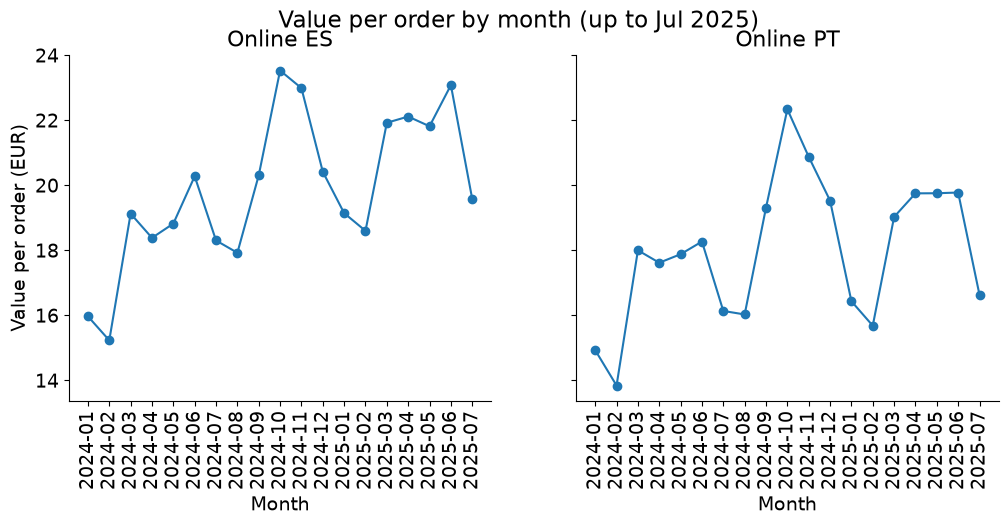

Guardado: evidence_dl_vendas/DLV1_fig.png

--- Os mesmos meses nos dois anos (janeiro a julho): valor médio por encomenda e o que o move ---


,Market,Month,Value per order 2024,Value per order 2025,Ratio 2025/2024,Items per order ratio,Value per item ratio
0,Online ES,01,"15,96","19,14","1,20","1,13","1,06"
1,Online ES,02,"15,23","18,59","1,22","1,23","1,00"
2,Online ES,03,"19,12","21,92","1,15","1,17","0,98"
3,Online ES,04,"18,38","22,11","1,20","1,10","1,10"
4,Online ES,05,"18,82","21,81","1,16","1,07","1,09"
5,Online ES,06,"20,27","23,07","1,14","1,05","1,09"
6,Online ES,07,"18,30","19,57","1,07","1,06","1,01"
7,Online ES,Jan-Jul,"18,06","20,61","1,14","1,12","1,01"
8,Online PT,01,"14,92","16,43","1,10","1,13","0,97"
9,Online PT,02,"13,84","15,68","1,13","1,17","0,97"


Guardado: evidence_dl_vendas/DLV2.csv

--- Índice do dia da semana do valor médio por encomenda (1,00 = sem efeito), janeiro a julho de cada ano ---


,Weekday,Online ES 2024,Online ES 2025,Online PT 2024,Online PT 2025
0,Monday,"0,97","0,98","1,00","0,98"
1,Tuesday,"0,99","0,98","0,99","1,00"
2,Wednesday,"0,99","0,98","0,99","1,00"
3,Thursday,"0,99","0,99","1,00","1,01"
4,Friday,"0,99","0,98","1,01","0,99"
5,Saturday,"0,99","0,98","0,99","0,99"
6,Sunday,"1,08","1,09","1,02","1,03"


Controlo: índice recuperado da série sintética coincide com o efeito conhecido | bate: True
Diferença entre o melhor e o pior dia da semana: {'Online ES 2024': '10,5%', 'Online ES 2025': '11,4%', 'Online PT 2024': '2,9%', 'Online PT 2025': '4,6%'}
Guardado: evidence_dl_vendas/DLV3.csv

--- Teste com encomendas certas: erro do gross sales mensal (encomendas reais x valor médio previsto), Training ---


,Window,Method,Market,Months,WAPE,Bias
0,Jan-Jul 2025 (7 months),AOV last 3 months,ES + PT,7,"14,1%","4,3%"
1,Jan-Jul 2025 (7 months),AOV last 3 months,Online ES,7,"12,8%","3,0%"
2,Jan-Jul 2025 (7 months),AOV last 3 months,Online PT,7,"18,2%","8,8%"
3,Jan-Jul 2025 (7 months),AOV last month,ES + PT,7,"12,0%","4,8%"
4,Jan-Jul 2025 (7 months),AOV last month,Online ES,7,"10,8%","3,5%"
5,Jan-Jul 2025 (7 months),AOV last month,Online PT,7,"16,5%","8,9%"
6,Jan-Jul 2025 (7 months),control: real AOV,ES + PT,7,"0,0%","0,0%"
7,Jan-Jul 2025 (7 months),control: real AOV,Online ES,7,"0,0%","0,0%"
8,Jan-Jul 2025 (7 months),control: real AOV,Online PT,7,"0,0%","-0,0%"
9,May-Jul 2025 (3 months),AOV B3 (same month last year x growth),ES + PT,3,"4,6%","4,6%"


Guardado: evidence_dl_vendas/DLV4.csv

--- Controlos ---
Último dia usado: 2025-07-31 (esperado 2025-07-31) | bate: True
Com o valor médio real, o erro é 0,0% | bate: True
Em cada passo o último mês usado é M-2 | bate: True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Usa daily, monthly, MARKETS, TARGETS, history(), cutoff_date(), split_of(), wape(), bias(), pct(), fmt(), save_table(), save_fig() (célula 1).
# Se reiniciaste o kernel, volta a correr a célula 1.
for nome in ['daily', 'monthly', 'MARKETS', 'TARGETS', 'history', 'cutoff_date', 'split_of', 'wape', 'bias', 'pct', 'fmt', 'save_table', 'save_fig']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e depois esta.")

# ---------- regra do estudo: só dados até 31/7/2025 (fim do Training); o Test fica fechado ----------
TRAIN_END = pd.Timestamp('2025-07-31')
d2 = lambda v: f"{v:.2f}".replace('.', ',') if v is not None and not pd.isna(v) else '-'      # número com vírgula decimal e 2 casas

def train_only(df):
    out = df[df['day'] <= TRAIN_END]
    assert out['day'].max() <= TRAIN_END, 'fuga de informação: dados do Test no estudo'
    return out

dtr = train_only(daily)

# ---------- DLV1: evolução mensal do valor médio, das peças por encomenda e do valor por peça ----------
mt = dtr.groupby(['mark', dtr['day'].dt.to_period('M')])[['orders', 'gross_sales', 'net_units']].sum().reset_index().rename(columns={'day': 'month'})
mt['aov'] = mt['gross_sales'] / mt['orders']                 # valor médio por encomenda (euros)
mt['units_per_order'] = mt['net_units'] / mt['orders']       # peças por encomenda
mt['value_per_unit'] = mt['gross_sales'] / mt['net_units']   # valor por peça (euros)
dlv1 = mt.assign(Month=mt['month'].astype(str), Orders=mt['orders'].map(fmt), Gross=mt['gross_sales'].map(fmt),
                 AOV=mt['aov'].map(d2), Units=mt['units_per_order'].map(d2), Unit_value=mt['value_per_unit'].map(d2)
                 )[['mark', 'Month', 'Orders', 'Gross', 'AOV', 'Units', 'Unit_value']]
dlv1.columns = ['Market', 'Month', 'Orders', 'Gross sales (EUR)', 'Value per order (EUR)', 'Items per order', 'Value per item (EUR)']
print('--- Valor médio por encomenda, peças por encomenda e valor por peça, por mês (janeiro de 2024 a julho de 2025) ---')
display(dlv1)
save_table(dlv1, 'DLV1', 'Value per order, items per order and value per item by month and market (up to Jul 2025)', 'Jan 2024 to Jul 2025')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for a, mk in zip(ax, MARKETS):
    s = mt[mt['mark'] == mk]
    a.plot(s['month'].astype(str), s['aov'], marker='o')
    a.set_title(mk); a.set_xlabel('Month'); a.tick_params(axis='x', rotation=90)
ax[0].set_ylabel('Value per order (EUR)')
fig.suptitle('Value per order by month (up to Jul 2025)')
plt.show()
save_fig(fig, 'DLV1_fig', 'Value per order by month and market (up to Jul 2025)', 'Jan 2024 to Jul 2025')

# ---------- DLV2: janeiro a julho de 2024 contra janeiro a julho de 2025 (os mesmos meses) ----------
rows = []
for mk in MARKETS:
    s = mt[mt['mark'] == mk].set_index('month')
    for k in range(1, 8):
        p24, p25 = pd.Period(f'2024-{k:02d}', 'M'), pd.Period(f'2025-{k:02d}', 'M')
        rows.append({'Market': mk, 'Month': f'{k:02d}', 'Value per order 2024': s.loc[p24, 'aov'], 'Value per order 2025': s.loc[p25, 'aov'],
                     'Ratio 2025/2024': s.loc[p25, 'aov'] / s.loc[p24, 'aov'],
                     'Items per order ratio': s.loc[p25, 'units_per_order'] / s.loc[p24, 'units_per_order'],
                     'Value per item ratio': s.loc[p25, 'value_per_unit'] / s.loc[p24, 'value_per_unit']})
    a24 = s.loc[pd.Period('2024-01', 'M'):pd.Period('2024-07', 'M')]; a25 = s.loc[pd.Period('2025-01', 'M'):pd.Period('2025-07', 'M')]
    rows.append({'Market': mk, 'Month': 'Jan-Jul',
                 'Value per order 2024': a24['gross_sales'].sum() / a24['orders'].sum(), 'Value per order 2025': a25['gross_sales'].sum() / a25['orders'].sum(),
                 'Ratio 2025/2024': (a25['gross_sales'].sum() / a25['orders'].sum()) / (a24['gross_sales'].sum() / a24['orders'].sum()),
                 'Items per order ratio': (a25['net_units'].sum() / a25['orders'].sum()) / (a24['net_units'].sum() / a24['orders'].sum()),
                 'Value per item ratio': (a25['gross_sales'].sum() / a25['net_units'].sum()) / (a24['gross_sales'].sum() / a24['net_units'].sum())})
dlv2 = pd.DataFrame(rows)
show2 = dlv2.copy()
for c in ['Value per order 2024', 'Value per order 2025', 'Ratio 2025/2024', 'Items per order ratio', 'Value per item ratio']:
    show2[c] = show2[c].map(d2)
print('\n--- Os mesmos meses nos dois anos (janeiro a julho): valor médio por encomenda e o que o move ---')
display(show2)
save_table(show2, 'DLV2', 'Value per order, same months of 2024 and 2025, with items per order and value per item ratios', 'Jan-Jul 2024 vs Jan-Jul 2025')

# ---------- DLV3: índice do dia da semana do valor médio (janeiro a julho de 2024 e de 2025) ----------
WEEKDAYS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

def aov_weekday_index(df):
    # rácio do valor médio do dia ao valor médio da semana centrada nele (soma do gross / soma das encomendas); mediana por dia da semana
    out = {}
    for mk in MARKETS:
        x = df[df['mark'] == mk].sort_values('day').copy()
        g7 = x['gross_sales'].rolling(7, center=True).sum(); o7 = x['orders'].rolling(7, center=True).sum()
        x['ratio'] = (x['gross_sales'] / x['orders']) / (g7 / o7)
        x = x.dropna(subset=['ratio'])
        med = x.groupby(x['day'].dt.dayofweek)['ratio'].median()
        out[mk] = med / med.mean()                              # média dos 7 dias = 1,00
    return pd.DataFrame(out)

# controlo: com um efeito do dia da semana conhecido (série sintética, valor médio = 100 × efeito), o índice recuperado coincide
eff = np.array([1.05, 1.10, 1.00, 0.95, 0.90, 0.95, 1.05]); eff = eff / eff.mean()
dd = pd.date_range('2024-01-01', periods=210)
syn = pd.DataFrame({'mark': MARKETS[0], 'day': dd, 'orders': 100.0})
syn['gross_sales'] = 100.0 * 100.0 * eff[syn['day'].dt.dayofweek.to_numpy()]
rec = aov_weekday_index(syn)[MARKETS[0]].to_numpy()
ok_w = bool(np.allclose(rec, eff, atol=1e-9))

i24 = aov_weekday_index(dtr[(dtr['day'] >= '2024-01-01') & (dtr['day'] <= '2024-07-31')])
i25 = aov_weekday_index(dtr[(dtr['day'] >= '2025-01-01') & (dtr['day'] <= '2025-07-31')])
dlv3 = pd.DataFrame({'Weekday': WEEKDAYS})
for mk in MARKETS:
    dlv3[f'{mk} 2024'] = i24[mk].to_numpy(); dlv3[f'{mk} 2025'] = i25[mk].to_numpy()
show3 = dlv3.copy()
for c in show3.columns[1:]:
    show3[c] = show3[c].map(d2)
print('\n--- Índice do dia da semana do valor médio por encomenda (1,00 = sem efeito), janeiro a julho de cada ano ---')
display(show3)
print('Controlo: índice recuperado da série sintética coincide com o efeito conhecido | bate:', ok_w)
print('Diferença entre o melhor e o pior dia da semana:', {c: pct(dlv3[c].max() / dlv3[c].min() - 1) for c in dlv3.columns[1:]})
save_table(show3, 'DLV3', 'Weekday index of value per order, Jan-Jul 2024 and Jan-Jul 2025', 'Jan-Jul 2024 and 2025')

# ---------- DLV4: teste com encomendas certas: quanto erra o gross sales só pelo valor médio ----------
def aov_hist(m, mk):
    h = history(daily, m)
    h = h[h['mark'] == mk]
    t = h.groupby(h['day'].dt.to_period('M'))[['gross_sales', 'orders']].sum()
    assert t.index.max() <= pd.Period(m, 'M') - 2, 'fuga de informação: mês depois do corte'
    return t

def aov_last1(m, mk):
    t = aov_hist(m, mk); p = pd.Period(m, 'M') - 2
    return t.loc[p, 'gross_sales'] / t.loc[p, 'orders']

def aov_last3(m, mk):
    t = aov_hist(m, mk); ps = [pd.Period(m, 'M') - 2 - i for i in range(3)]
    return t.loc[ps, 'gross_sales'].sum() / t.loc[ps, 'orders'].sum()

def aov_b3(m, mk):
    # valor médio do mesmo mês do ano anterior x (valor médio dos 3 meses até ao corte / valor médio dos mesmos meses um ano antes)
    t = aov_hist(m, mk); recent = [pd.Period(m, 'M') - 2 - i for i in range(3)]; prior = [p - 12 for p in recent]; base = pd.Period(m, 'M') - 12
    if any(p not in t.index for p in recent + prior + [base]):
        return None
    a = lambda ps: t.loc[ps, 'gross_sales'].sum() / t.loc[ps, 'orders'].sum()
    return (t.loc[base, 'gross_sales'] / t.loc[base, 'orders']) * a(recent) / a(prior)

def aov_true(m, mk):
    r = monthly[(monthly['mark'] == mk) & (monthly['month'] == pd.Period(m, 'M'))].iloc[0]       # só controlo: o valor médio real do mês
    return r['gross_sales'] / r['orders']

METODOS = {'AOV last month': aov_last1, 'AOV last 3 months': aov_last3, 'AOV B3 (same month last year x growth)': aov_b3, 'control: real AOV': aov_true}
TRAIN_MONTHS = [m for m in TARGETS if split_of(m) == 'Training']
rows = []
for name, f in METODOS.items():
    for m in TRAIN_MONTHS:
        for mk in MARKETS:
            a = f(m, mk)
            if a is None:
                continue
            r = monthly[(monthly['mark'] == mk) & (monthly['month'] == m)].iloc[0]
            rows.append({'method': name, 'mark': mk, 'month': m, 'forecast': a * r['orders'], 'actual': r['gross_sales']})   # encomendas certas x valor médio previsto
fc4 = pd.DataFrame(rows)
tot = fc4.groupby(['method', 'month'], as_index=False).agg(forecast=('forecast', 'sum'), actual=('actual', 'sum'), n=('mark', 'count'))
tot = tot[tot['n'] == len(MARKETS)].drop(columns='n'); tot['mark'] = 'ES + PT'
fc4 = pd.concat([fc4, tot], ignore_index=True)

def resumo(meses, rotulo):
    d = fc4[fc4['month'].isin(meses)]
    linhas = []
    for (met, mk), x in d.groupby(['method', 'mark']):
        linhas.append({'Window': rotulo, 'method': met, 'mark': mk, 'Months': len(x), 'WAPE': wape(x['actual'], x['forecast']), 'Bias': bias(x['actual'], x['forecast'])})
    return pd.DataFrame(linhas)

meses_b3 = [m for m in TRAIN_MONTHS if m >= pd.Period('2025-05', 'M')]
r7 = resumo(TRAIN_MONTHS, 'Jan-Jul 2025 (7 months)')
r7 = r7[~r7['method'].str.contains('B3')]                      # a B3 só existe de maio em diante: não entra na janela de 7 meses
dlv4 = pd.concat([r7, resumo(meses_b3, 'May-Jul 2025 (3 months)')], ignore_index=True)
dlv4['mark'] = pd.Categorical(dlv4['mark'], ['ES + PT', 'Online ES', 'Online PT'])
dlv4 = dlv4.sort_values(['Window', 'method', 'mark']).reset_index(drop=True)
show4 = dlv4.copy(); show4['WAPE'] = show4['WAPE'].map(pct); show4['Bias'] = show4['Bias'].map(pct); show4['mark'] = show4['mark'].astype(str)
print('\n--- Teste com encomendas certas: erro do gross sales mensal (encomendas reais x valor médio previsto), Training ---')
display(show4.rename(columns={'method': 'Method', 'mark': 'Market'}))
save_table(show4, 'DLV4', 'Error of monthly gross sales with known orders and a simple forecast of value per order (Training)', 'Jan-Jul 2025')

# ---------- controlos ----------
ctl = dlv4[dlv4['method'] == 'control: real AOV']
ok_c = bool(np.allclose(ctl[['WAPE', 'Bias']].to_numpy(float), 0))
ult = {m: aov_hist(m, MARKETS[0]).index.max() for m in TRAIN_MONTHS}
ok_u = all(ult[m] == pd.Period(m, 'M') - 2 for m in TRAIN_MONTHS)
print('\n--- Controlos ---')
print('Último dia usado:', dtr['day'].max().date(), '(esperado 2025-07-31) | bate:', dtr['day'].max() == TRAIN_END)
print('Com o valor médio real, o erro é 0,0% | bate:', ok_c)
print('Em cada passo o último mês usado é M-2 | bate:', ok_u)

# Eficiência: tudo é O(d·m) em tempo e espaço sobre a tabela diária (d = 731 dias, m = 2 mercados); o ciclo do teste com encomendas certas faz
# 4 métodos x 7 meses x 2 mercados = 56 filtros do histórico, cada um O(d·m); os índices do dia da semana usam médias móveis O(d) por mercado.

### 2a. Conclusions

**Confirmed (full tables):**
- The checks match: the last day used is 31/7/2025 and the test with the actual average value gives zero error.
- The average order value changes a lot from month to month, in both markets. It goes up in October and November 2024 and from March to June 2025, and goes down in January, February and July.
- In the lowest months, each order has more items, but the items are cheaper.
- In the same months, the 2025 average value is higher than 2024 in every month, more so in Spain than in Portugal. The increase comes from orders with more items, not from more expensive items.
- The day of the week hardly moves the average value. Only Sunday in Spain stands out a little.
- Even with the correct orders and a simple rule for the average value, each month's gross sales is still quite far off, and the forecast is above the actual.

**Derived from what we saw:**
- The average value is not stable, and is not easy to forecast with simple rules. It is the hard part of the "orders × average value" approach.
- The months with cheaper items coincide with times of year that may be clearance sales, but we have not tested this yet. It is left for the campaigns section.
- The "same month last year" rule seems to do better, but it only exists for 3 months. That is not enough to conclude anything.

**Decision:**
- Both approaches stay in the comparison: forecasting gross sales directly, and forecasting orders × average value.
- For the second approach to be worth it, the average value must be forecast better than with these rules. That depends on what campaigns and the calendar can explain.
- Section 3 studies calendar campaigns and their effect on the average value.

## 3. Calendar campaigns and average order value

**What we will do:** read the `slv_events` table from the silver layer, mark the days of the six campaigns that follow the calendar (Black Friday, Christmas, Mother's Day, Reyes, Valentine's and Easter/Holy Week) in Online ES and Online PT, and measure how much each one moves orders, gross sales and the average order value (data up to 31/7/2025).

**Goal:** decide whether calendar campaigns help forecast gross sales and, in particular, whether they explain part of the average order value, which Section 2 showed to be unstable. The dates and campaigns are the same as in the orders notebook.

**Definitions:**
- **Normal days:** those that do not belong to any of the six campaigns. Clearance sales are not separated yet and stay inside the normal days; they are studied in the next section.
- **Reference for each campaign day:** the normal days of the previous 28 days (at least 7 normal days).
- **Orders factor:** orders on campaign days divided by the average orders of the reference. **Gross sales factor:** the same with gross sales. 1,00 means no effect, and 2,00 means double a normal day.
- **Average value factor:** gross sales on campaign days divided by the gross sales they would have if each order were worth the reference's average value. It is above 1,00 if campaign orders are worth more than normal ones, and below 1,00 if they are worth less.

**Filter for the variables:**
1. Is it known at the cutoff? Parfois said that calendar campaigns are known at the start of the year. The dates come from `slv_events` and should be confirmed.
2. Is the effect stable between 2024 and 2025?
3. Does it help reduce the error in Training? (measured later).

**Control values:**
- In `slv_events` there are no events ending before they start, and no imputed rows in Online ES and Online PT.
- Black Friday has 6 days per year and market (26/11 to 01/12 in 2024 and 25/11 to 30/11 in 2025).
- A synthetic series with 2,5 times more orders and a 1,2 times higher average value returns factors of 2,5 (orders), 3,0 (gross sales) and 1,2 (average value).
- The 2024 orders factors for Black Friday and Christmas match those of the orders notebook (6,72 and 8,21 for Black Friday; 1,55 and 1,07 for Christmas, in ES and PT).

Linhas de slv_events: 845 | com fim antes do início: 0 (esperado 0, a silver já corrige) | linhas imputadas em ES/PT: 0 (esperado 0)

--- Controlo 1: dias da Black Friday por mercado e ano ---


,mark,year,dias,primeiro,ultimo,bate
0,Online ES,2024,6,2024-11-26,2024-12-01,True
1,Online ES,2025,6,2025-11-25,2025-11-30,True
2,Online PT,2024,6,2024-11-26,2024-12-01,True
3,Online PT,2025,6,2025-11-25,2025-11-30,True



--- Controlo 2: série sintética com fatores conhecidos ---
Fatores recuperados (encomendas, gross sales, valor médio): 2.500000, 3.000000, 1.200000 (esperado 2,5, 3,0 e 1,2) | dias medidos: 3 (esperado 3) | bate: True

--- Efeito de cada campanha nas encomendas, no gross sales e no valor médio por encomenda (1,00 = dia normal), dados até 31/7/2025 ---


,Campaign,Market,Year,Campaign days (up to 31 Jul 2025),Days measured,Orders factor,Gross sales factor,Value per order factor
0,Black Friday,Online ES,2024,6,6,"6,72","6,51","0,97"
1,Black Friday,Online PT,2024,6,6,"8,21","7,49","0,91"
2,Christmas,Online ES,2024,4,4,"1,55","1,53","0,99"
3,Christmas,Online PT,2024,4,4,"1,07","1,08","1,00"
4,Mothers Day,Online ES,2024,3,3,"1,33","1,32","1,00"
5,Mothers Day,Online ES,2025,5,5,"0,92","0,93","1,01"
6,Mothers Day,Online PT,2024,3,3,"1,30","1,25","0,97"
7,Mothers Day,Online PT,2025,6,5,"0,81","0,82","1,01"
8,Reyes,Online ES,2024,4,4,"1,17","1,09","0,93"
9,Reyes,Online ES,2025,2,2,"0,60","0,61","1,01"


Guardado: evidence_dl_vendas/DLV5.csv

--- Controlo 3: fatores das encomendas de 2024 contra os do notebook das encomendas ---


,campanha,mercado,medido,esperado (notebook das encomendas),bate
0,Black Friday,Online ES,"6,72","6,72",True
1,Black Friday,Online PT,"8,21","8,21",True
2,Christmas,Online ES,"1,55","1,55",True
3,Christmas,Online PT,"1,07","1,07",True


Guardado: evidence_dl_vendas/DLV5_fig.png


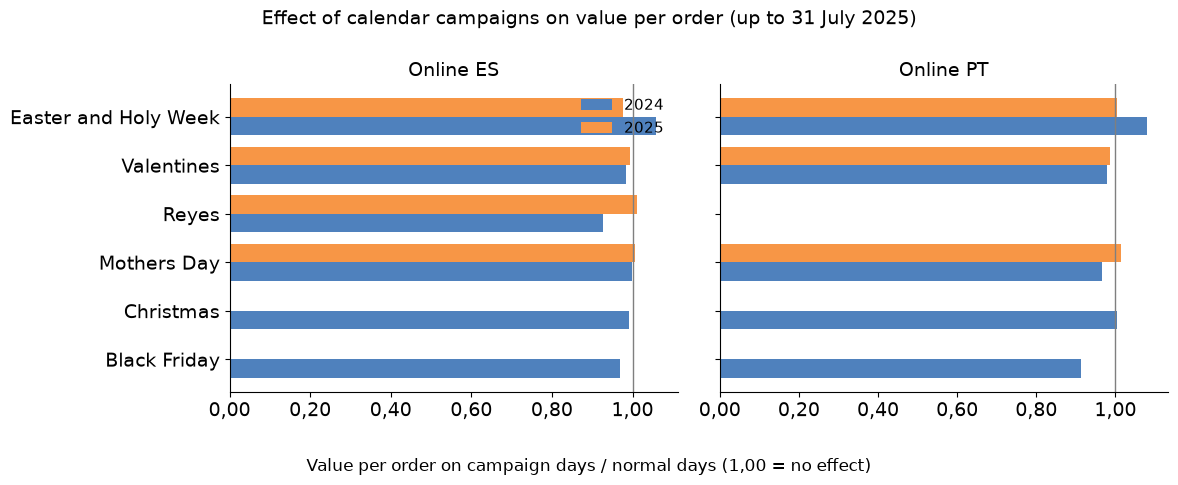

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Usa daily, MARKETS, START, END, fmt(), pct(), save_table(), save_fig(), lake, con, mk_in, mk_values (célula 1) e TRAIN_END, train_only(), d2() (célula do ponto 2).
# Se reiniciaste o kernel, volta a correr a célula 1 e a do ponto 2.
for nome in ['daily', 'MARKETS', 'START', 'END', 'fmt', 'pct', 'save_table', 'save_fig', 'lake', 'con', 'mk_in', 'mk_values', 'TRAIN_END', 'train_only', 'd2']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e a do ponto 2 e depois esta.")

SILVER_EV = f"'{lake.uri('silver', 'slv_events')}.parquet'"

# ---------- campanhas que seguem o calendário (as mesmas seis do notebook das encomendas) ----------
FAMS = ['Black Friday', 'Christmas', 'Mothers Day', 'Reyes', 'Valentines', 'Easter and Holy Week']     # ordem = prioridade se dois eventos caírem no mesmo dia
fam_in = ', '.join(f"'{f}'" for f in FAMS)
WIN, MIN_REF = 28, 7     # referência de cada dia de campanha: dias normais dos 28 dias anteriores (mínimo 7 dias)

con.execute(f"""
CREATE OR REPLACE TEMP TABLE ev_dl AS
SELECT mark, clean_name, start_d, end_d, (end_d >= start_d) AS valid, is_imputed,
  CASE
    WHEN clean_name ILIKE 'Black Friday%'            THEN 'Black Friday'
    WHEN clean_name ILIKE 'Clearance%'               THEN 'Clearance'
    WHEN clean_name ILIKE 'Special Prices%'          THEN 'Special prices'
    WHEN clean_name ILIKE 'Free Shipping%'           THEN 'Free shipping'
    WHEN clean_name ILIKE '%Valentines%'             THEN 'Valentines'
    WHEN clean_name ILIKE '%Mothers Day%'            THEN 'Mothers Day'
    WHEN clean_name ILIKE '%Christmas%'              THEN 'Christmas'
    WHEN clean_name ILIKE '%Reyes%'                  THEN 'Reyes'
    WHEN clean_name IN ('Easter Weeks', 'Holy Week') THEN 'Easter and Holy Week'
    WHEN clean_name = 'Get your basket ready'        THEN 'Get your basket ready'
    WHEN clean_name = 'Stock 1'                      THEN 'Stock 1'
    WHEN clean_name ILIKE 'Apag%'                    THEN 'Iberian blackout'
    ELSE 'Other'
  END AS family
FROM (SELECT mark_cod AS mark, event AS clean_name, start_date AS start_d, end_date AS end_d, is_imputed
      FROM read_parquet({SILVER_EV}))     -- a silver já normaliza o nome, corrige as datas e usa 'All' para os eventos de todos os mercados
""")
n_ev, n_inv, n_imp = con.execute(f"""SELECT count(*), count(*) FILTER (WHERE NOT valid),
                                       count(*) FILTER (WHERE is_imputed AND mark IN ({mk_in})) FROM ev_dl""").fetchall()[0]
print('Linhas de slv_events:', fmt(n_ev), '| com fim antes do início:', n_inv, '(esperado 0, a silver já corrige) | linhas imputadas em ES/PT:', n_imp, '(esperado 0)')

# dias de campanha por mercado: eventos com mercado + linhas da Black Friday de todos os mercados (mark = 'All', valem para os dois mercados)
con.execute(f"""
CREATE OR REPLACE TEMP TABLE camp_days_dl AS
WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
rows_m AS (
  SELECT mark, family, CAST(day_ts AS DATE) AS day FROM (
    SELECT mark, family,
           unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                  CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
    FROM ev_dl WHERE valid AND mark IN ({mk_in}) AND family IN ({fam_in}))),
rows_g AS (
  SELECT mk.mark, g.family, g.day FROM (
    SELECT family, CAST(day_ts AS DATE) AS day FROM (
      SELECT family,
             unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                    CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
      FROM ev_dl WHERE valid AND mark = 'All' AND family = 'Black Friday')) g
  CROSS JOIN mk)
SELECT DISTINCT mark, family, day FROM (SELECT * FROM rows_m UNION ALL SELECT * FROM rows_g)
""")
camp = con.sql("SELECT mark, family, day FROM camp_days_dl").df()
camp['day'] = pd.to_datetime(camp['day'])
camp['p'] = camp['family'].map({f: i for i, f in enumerate(FAMS)})
camp = camp.sort_values(['mark', 'day', 'p']).drop_duplicates(['mark', 'day']).drop(columns='p').reset_index(drop=True)
camp['year'] = camp['day'].dt.year

# ---------- controlo 1: a Black Friday tem 6 dias por ano e mercado (26/11 a 01/12 de 2024 e 25/11 a 30/11 de 2025) ----------
bf = camp[camp['family'] == 'Black Friday'].groupby(['mark', 'year']).agg(dias=('day', 'count'), primeiro=('day', 'min'), ultimo=('day', 'max')).reset_index()
bf['bate'] = (bf['dias'] == 6) & (((bf['year'] == 2024) & (bf['primeiro'] == pd.Timestamp('2024-11-26')) & (bf['ultimo'] == pd.Timestamp('2024-12-01')))
                                  | ((bf['year'] == 2025) & (bf['primeiro'] == pd.Timestamp('2025-11-25')) & (bf['ultimo'] == pd.Timestamp('2025-11-30'))))
print('\n--- Controlo 1: dias da Black Friday por mercado e ano ---')
display(bf)

# ---------- fatores de cada campanha: encomendas, gross sales e valor médio ----------
def campaign_factors(daily_df, camp_df):
    # por campanha, mercado e ano: soma dos dias de campanha a dividir pela soma das referências (dias normais dos 28 dias anteriores).
    # Valor médio: gross dos dias de campanha / (encomendas de cada dia x valor médio da referência desse dia).
    acc = {}
    for mk, g in daily_df.groupby('mark'):
        s = g.set_index('day').sort_index()
        sub = camp_df[camp_df['mark'] == mk]
        fam_of = dict(zip(sub['day'], sub['family']))
        flag = np.array([d in fam_of for d in s.index])
        normal = s[~flag]                                        # dias sem nenhuma das seis campanhas
        for d in s.index[flag]:
            w = normal.loc[d - pd.Timedelta(days=1) - pd.Timedelta(days=WIN - 1): d - pd.Timedelta(days=1)]
            if len(w) >= MIN_REF:
                ref_aov = w['gross_sales'].sum() / w['orders'].sum()
                a = acc.setdefault((fam_of[d], mk, d.year), np.zeros(6))
                a += [s.loc[d, 'orders'], w['orders'].mean(), s.loc[d, 'gross_sales'], w['gross_sales'].mean(), s.loc[d, 'orders'] * ref_aov, 1]
    return pd.DataFrame([{'family': k[0], 'mark': k[1], 'year': k[2], 'days_measured': int(v[5]),
                          'f_orders': v[0] / v[1], 'f_gross': v[2] / v[3], 'f_aov': v[2] / v[4]} for k, v in acc.items()])

# controlo 2: série sintética: campanha de 3 dias com 2,5x as encomendas e 1,2x o valor médio -> 2,5, 3,0 e 1,2
dias_t = pd.date_range('2024-01-01', periods=80)
o_t = np.full(80, 100.0); o_t[40:43] = 250.0
v_t = np.full(80, 50.0); v_t[40:43] = 60.0                       # valor médio por encomenda
d_t = pd.DataFrame({'mark': 'teste', 'day': dias_t, 'orders': o_t, 'gross_sales': o_t * v_t})
camp_t = pd.DataFrame({'mark': 'teste', 'family': 'X', 'day': dias_t[40:43]})
f_t = campaign_factors(d_t, camp_t).iloc[0]
print('\n--- Controlo 2: série sintética com fatores conhecidos ---')
print('Fatores recuperados (encomendas, gross sales, valor médio):', f"{f_t['f_orders']:.6f}, {f_t['f_gross']:.6f}, {f_t['f_aov']:.6f}",
      '(esperado 2,5, 3,0 e 1,2) | dias medidos:', int(f_t['days_measured']), '(esperado 3)',
      '| bate:', bool(abs(f_t['f_orders'] - 2.5) < 1e-9 and abs(f_t['f_gross'] - 3.0) < 1e-9 and abs(f_t['f_aov'] - 1.2) < 1e-9 and f_t['days_measured'] == 3))

# ---------- dados do estudo: só até 31/7/2025 ----------
d_study = train_only(daily)
camp_study = camp[camp['day'] <= TRAIN_END]
fac = campaign_factors(d_study, camp_study)
days_n = camp_study.groupby(['family', 'mark', 'year']).size().rename('campaign_days').reset_index()
tab = days_n.merge(fac, on=['family', 'mark', 'year'], how='left')
tab['family'] = pd.Categorical(tab['family'], FAMS, ordered=True)
tab = tab.sort_values(['family', 'mark', 'year']).reset_index(drop=True)
fm = lambda v: '-' if pd.isna(v) else d2(v)
dlv5 = pd.DataFrame({'Campaign': tab['family'].astype(str), 'Market': tab['mark'], 'Year': tab['year'],
                     'Campaign days (up to 31 Jul 2025)': tab['campaign_days'], 'Days measured': tab['days_measured'].fillna(0).astype(int),
                     'Orders factor': tab['f_orders'].map(fm), 'Gross sales factor': tab['f_gross'].map(fm), 'Value per order factor': tab['f_aov'].map(fm)})
print('\n--- Efeito de cada campanha nas encomendas, no gross sales e no valor médio por encomenda (1,00 = dia normal), dados até 31/7/2025 ---')
display(dlv5)
save_table(dlv5, 'DLV5', 'Effect of each calendar campaign on orders, gross sales and value per order, by market and year, up to 31 July 2025', 'whole table')

# ---------- controlo 3: fatores das encomendas de 2024 (Black Friday e Natal) contra os do notebook das encomendas ----------
ref = {('Black Friday', 'Online ES'): 6.72, ('Black Friday', 'Online PT'): 8.21, ('Christmas', 'Online ES'): 1.55, ('Christmas', 'Online PT'): 1.07}
rows = []
for (fam, mk), esp in ref.items():
    r = fac[(fac['family'] == fam) & (fac['mark'] == mk) & (fac['year'] == 2024)]
    got = float(r['f_orders'].iloc[0]) if len(r) else np.nan
    rows.append({'campanha': fam, 'mercado': mk, 'medido': d2(got), 'esperado (notebook das encomendas)': d2(esp), 'bate': (not np.isnan(got)) and round(got, 2) == esp})
print('\n--- Controlo 3: fatores das encomendas de 2024 contra os do notebook das encomendas ---')
display(pd.DataFrame(rows))

# ---------- gráfico: fator do valor médio de cada campanha, por mercado e ano ----------
fig, axes = plt.subplots(1, len(MARKETS), sharey=True, figsize=(12, 4.8))
for ax, mk in zip(np.atleast_1d(axes), MARKETS):
    for k, (yr, cor) in enumerate([(2024, '#4F81BD'), (2025, '#F79646')]):
        v = [fac[(fac['family'] == f) & (fac['mark'] == mk) & (fac['year'] == yr)]['f_aov'].tolist() for f in FAMS]
        vals = [x[0] if x else np.nan for x in v]
        ax.barh(np.arange(len(FAMS)) + (k - 0.5) * 0.38, vals, height=0.38, color=cor, label=str(yr))
    ax.axvline(1, color='#7F7F7F', linewidth=1)
    ax.set_yticks(range(len(FAMS))); ax.set_yticklabels(FAMS); ax.invert_yaxis()
    ax.set_title(mk, fontsize=14); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: d2(v)))
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=11, loc='upper right')
fig.suptitle('Effect of calendar campaigns on value per order (up to 31 July 2025)', fontsize=14)
fig.supxlabel('Value per order on campaign days / normal days (1,00 = no effect)', fontsize=12)
fig.tight_layout()
save_fig(fig, 'DLV5_fig', 'Effect of calendar campaigns on value per order by market and year', 'whole table')
plt.show()

# Eficiência: o fator percorre os dias de campanha do histórico (c, até ~150 por mercado) com uma janela de 28 dias, O(c·28); a leitura de slv_events é O(e)
# com e = nº de linhas da tabela. Espaço O(d), com d = 731 dias.

### 3a. Conclusions

**Confirmed (full tables):**
- The checks match. The Black Friday dates are right and the orders factors are the same as in the orders notebook.
- In all six campaigns, gross sales follows orders almost exactly. Campaigns change how many orders there are, and barely change the value of each one.
- The average order value stays close to normal in every campaign. The biggest deviation is on Black Friday, where orders are worth a little less, especially in Portugal.
- Easter and Reyes show small differences in the average value that do not repeat from 2024 to 2025.

**Derived from what we saw:**
- Calendar campaigns do not explain the instability of the average value seen in Section 2. The months of high and low average value come from something else.
- These campaigns help forecast volume (orders and, with them, gross sales), but do not help forecast the average value.
- Black Friday has a huge effect on volume and a small effect on the average value. It was seen only once before the cutoff, so its exact size is learned from a single observation.
- Limit: normal days still include clearance sales, which may hide part of the effects.

**Filter for the variables (for the average value):**
- Known at the cutoff? Yes, if the company confirms the dates.
- Stable between 2024 and 2025? The effect is almost zero in both years.
- Helps reduce the error in Training? For the average value, unlikely. The test with and without the variable will decide later.

**Decision:**
- Calendar campaigns stay as candidate variables for gross sales because of volume, under the same conditions as for orders.
- Section 4 studies clearance sales (Clearance), which coincide with the months of lowest average value.

## 4. Clearance sales and average order value

**What we will do:** mark the clearance days (the `Clearance` event, in Online ES, Online PT and in the all-markets events) and measure how the average order value, items per order and value per item change on those days, using only data up to 31/7/2025. Three steps: (1) list the clearance periods and check whether they repeat from 2024 to 2025; (2) compare clearance days with non-clearance days; (3) look at the changes on either side of the start and end of each clearance period, which compare days that are very close together.

**Goal:** understand whether clearance sales explain the months of lowest average value from Section 2 (January, February and July), and decide whether the clearance flag becomes a variable for gross sales.

**Definitions:**
- **Clearance:** only the `Clearance` event. `Clearance Extended` and promotions (Special Prices, Stock 1) are left out, as in the orders notebook. Consecutive or overlapping periods are merged into one.
- **Normal days to compare:** days without clearance and without any of the six calendar campaigns from Section 3. Calendar campaign days are left out of both sides of the comparison.
- **Simple comparison (step 2):** average value and items on clearance days against those on normal days, by market and year (January–July 2024 and 2025). It compares different months, so it is only a hint.
- **Change around a date (step 3):** 14 days with clearance against the 14 normal days on the other side of the date (before the start, or after the end). Only complete windows inside January 2024 to 31/7/2025 are used, with at least 7 usable days on each side. Each number is the ratio clearance / normal: 1,00 means no effect.

**Filter for the variables:**
1. Is it known at the cutoff? The dates are not fixed at the start of the year. The flag is assumed to be known 1 to 2 months ahead, to be confirmed with Parfois.
2. Is the effect stable between 2024 and 2025, and between the two markets?
3. Does it help reduce the error in Training? (measured later).

**Control values:**
- The number of clearance days per market matches a direct count in `slv_events`.
- A synthetic series where clearance raises orders 1,5 times and lowers the average value to 0,8 returns those ratios at the start and end of the period.
- No window uses days after 31/7/2025 or before 1/1/2024.

--- Períodos de saldos (Clearance) por mercado ---


,Market,Start,End,Events merged,Days (2024-2025),Days up to 31 Jul 2025,Days also in a calendar campaign
0,Online ES,2024-01-06,2024-02-28,1,54,54,4
1,Online ES,2024-06-26,2024-08-31,1,67,67,0
2,Online ES,2025-01-06,2025-02-28,1,54,54,3
3,Online ES,2025-06-25,2025-08-31,1,68,37,0
4,Online PT,2024-01-01,2024-02-28,1,59,59,4
5,Online PT,2024-06-26,2024-08-31,1,67,67,0
6,Online PT,2025-01-01,2025-02-28,1,59,59,3
7,Online PT,2025-06-25,2025-08-31,1,68,37,0


Eventos Clearance Extended (fora dos saldos): 1
Guardado: evidence_dl_vendas/DLV6.csv

--- Controlo 1: dias de saldos contra a contagem direta na slv_events ---


,Market,Measured,Direct count,bate
0,Online ES,243,243,True
1,Online PT,253,253,True



--- Dias de saldos contra dias normais (sem campanhas de calendário), janeiro de 2024 a julho de 2025 ---


,Market,Year,Days type,Days,Orders per day,Value per order (EUR),Items per order,Value per item (EUR)
0,Online ES,2024,Normal,211,2.132,"20,64","1,58","13,09"
1,Online ES,2024,Clearance,117,2.520,"17,34","2,08","8,33"
2,Online ES,2025,Normal,97,2.310,"22,30","1,73","12,91"
3,Online ES,2025,Clearance,88,4.223,"19,50","2,37","8,21"
4,Online PT,2024,Normal,210,717,"19,64","1,58","12,40"
5,Online PT,2024,Clearance,122,1.004,"15,56","1,97","7,90"
6,Online PT,2025,Normal,93,707,"19,74","1,66","11,88"
7,Online PT,2025,Clearance,93,1.542,"16,58","2,26","7,33"


Guardado: evidence_dl_vendas/DLV7.csv

--- Controlo 2: série sintética com rácios conhecidos (encomendas 1,5, valor médio 0,8, peças 1,0, valor por peça 0,8) ---
Transições medidas: 2 (esperado 2: início e fim) | rácios recuperados | bate: True

--- Mudança em torno do início e do fim dos saldos: rácio saldos / normal (1,00 = sem efeito) ---


,Market,Transition,Date,Clearance days used,Normal days used,Orders per day,Value per order,Items per order,Value per item
0,Online ES,End of clearance,2024-02-28,14,14,"1,11","0,83","1,13","0,74"
1,Online ES,Start of clearance,2024-06-26,14,14,"1,94","0,95","1,35","0,71"
2,Online ES,End of clearance,2024-08-31,14,14,"1,03","0,92","1,19","0,78"
3,Online ES,Start of clearance,2025-01-06,14,8,"2,01","0,95","1,62","0,59"
4,Online ES,End of clearance,2025-02-28,14,14,"1,48","0,88","1,23","0,72"
5,Online ES,Start of clearance,2025-06-25,14,14,"2,34","0,93","1,34","0,70"
6,Online PT,End of clearance,2024-02-28,14,14,"1,40","0,80","1,19","0,68"
7,Online PT,Start of clearance,2024-06-26,14,14,"2,29","0,90","1,30","0,69"
8,Online PT,End of clearance,2024-08-31,14,14,"1,23","0,88","1,16","0,76"
9,Online PT,Start of clearance,2025-01-01,14,11,"3,41","0,88","1,44","0,61"


Transições medidas: 12 de 16 possíveis (as outras ficam fora por janela incompleta, dias a menos ou depois de 31/7/2025)
Mediana dos rácios por mercado:


,Orders per day,Value per order,Items per order,Value per item
Market,,,,
Online ES,"1,71","0,93","1,29","0,71"
Online PT,"1,90","0,88","1,24","0,69"


Guardado: evidence_dl_vendas/DLV8.csv

Controlo 3: janelas dentro de 1/1/2024 a 31/7/2025 | bate: True
Guardado: evidence_dl_vendas/DLV6_fig.png


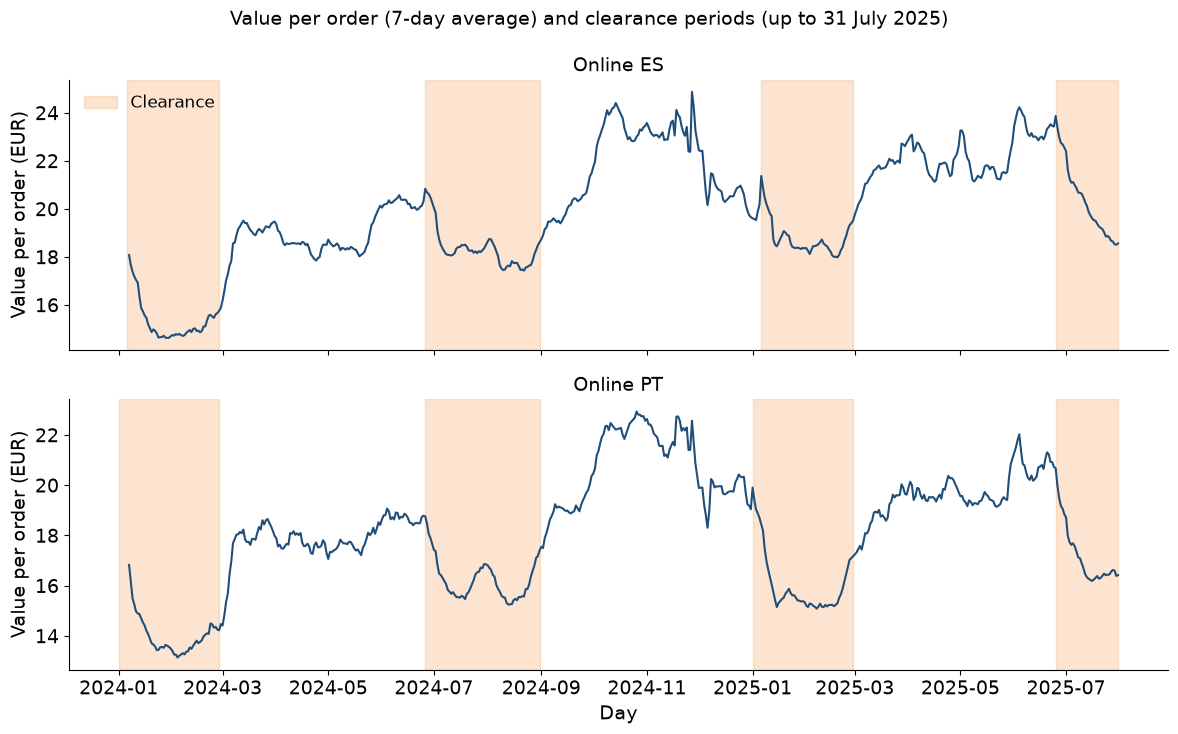

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Usa daily, MARKETS, START, END, fmt(), pct(), save_table(), save_fig(), con, mk_in (célula 1), TRAIN_END, train_only(), d2() (ponto 2) e camp, ev_dl (ponto 3).
# Se reiniciaste o kernel, volta a correr a célula 1 e as dos pontos 2 e 3.
for nome in ['daily', 'MARKETS', 'START', 'END', 'fmt', 'pct', 'save_table', 'save_fig', 'con', 'mk_in', 'TRAIN_END', 'train_only', 'd2', 'camp']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e as dos pontos 2 e 3 e depois esta.")

T0, T1 = pd.Timestamp(START), pd.Timestamp(END)
ONE = pd.Timedelta(days=1)

# ---------- períodos de saldos (evento Clearance, sem o Clearance Extended) por mercado ----------
cl_raw = con.sql(f"""SELECT mark, CAST(start_d AS DATE) AS s, CAST(end_d AS DATE) AS e FROM ev_dl
                     WHERE valid AND clean_name ILIKE 'Clearance' AND (mark IN ({mk_in}) OR mark = 'All')""").df()
n_ext = con.execute("SELECT count(*) FROM ev_dl WHERE clean_name ILIKE 'Clearance Extended%'").fetchall()[0][0]
raw = {mk: sorted((pd.Timestamp(r.s), pd.Timestamp(r.e)) for r in cl_raw.itertuples() if r.mark in (mk, 'All')) for mk in MARKETS}   # 'All' vale para os dois mercados

def merge_periods(ints):
    # junta períodos seguidos ou sobrepostos; devolve [início, fim, nº de eventos juntos]
    out = []
    for s, e in ints:
        if out and s <= out[-1][1] + ONE:
            out[-1][1] = max(out[-1][1], e); out[-1][2] += 1
        else:
            out.append([s, e, 1])
    return out

periods = {mk: merge_periods(raw[mk]) for mk in MARKETS}
clear_days = {mk: set(d for a, b, _ in periods[mk] for d in pd.date_range(max(a, T0), min(b, T1))) for mk in MARKETS}      # dias de saldos dentro de 2024-2025
fixed_days = {mk: set(camp.loc[camp['mark'] == mk, 'day']) for mk in MARKETS}                                          # dias das seis campanhas de calendário

# ---------- DLV6: períodos de saldos por mercado ----------
rows = []
for mk in MARKETS:
    for a, b, n in periods[mk]:
        dias = pd.date_range(max(a, T0), min(b, T1))
        rows.append({'Market': mk, 'Start': a.date(), 'End': b.date(), 'Events merged': n, 'Days (2024-2025)': len(dias),
                     'Days up to 31 Jul 2025': int((dias <= TRAIN_END).sum()), 'Days also in a calendar campaign': sum(d in fixed_days[mk] for d in dias)})
dlv6 = pd.DataFrame(rows)
print('--- Períodos de saldos (Clearance) por mercado ---')
display(dlv6)
print('Eventos Clearance Extended (fora dos saldos):', n_ext)
save_table(dlv6, 'DLV6', 'Clearance periods by market, with days and overlap with calendar campaigns', 'whole table')

# controlo 1: dias de saldos por mercado = contagem direta na slv_events (outro caminho: SQL com uma linha por dia)
sql_cnt = con.sql(f"""
WITH mk AS (SELECT * FROM (VALUES {', '.join(f"('{m}')" for m in MARKETS)}) AS v(mark)),
e AS (SELECT mark, s, e FROM (SELECT mark, CAST(start_d AS DATE) AS s, CAST(end_d AS DATE) AS e FROM ev_dl
                              WHERE valid AND clean_name ILIKE 'Clearance' AND (mark IN ({mk_in}) OR mark = 'All'))),
u AS (SELECT mark, s, e FROM e WHERE mark <> 'All' UNION ALL SELECT mk.mark, e.s, e.e FROM e CROSS JOIN mk WHERE e.mark = 'All')
SELECT mark, count(DISTINCT CAST(d AS DATE)) AS days FROM (
  SELECT mark, unnest(generate_series(CAST(greatest(s, DATE '{START}') AS TIMESTAMP), CAST(least(e, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS d FROM u)
GROUP BY mark""").df().set_index('mark')['days']
c1 = pd.DataFrame({'Market': MARKETS, 'Measured': [len(clear_days[m]) for m in MARKETS], 'Direct count': [int(sql_cnt.get(m, 0)) for m in MARKETS]})
c1['bate'] = c1['Measured'] == c1['Direct count']
print('\n--- Controlo 1: dias de saldos contra a contagem direta na slv_events ---')
display(c1)

# ---------- DLV7: dias de saldos contra dias normais, por mercado e ano (janeiro a julho) ----------
d_study = train_only(daily)
d = d_study.copy()
d['clear'] = [day in clear_days[mk] for mk, day in zip(d['mark'], d['day'])]
d['fixed'] = [day in fixed_days[mk] for mk, day in zip(d['mark'], d['day'])]
dn = d[~d['fixed']]                                                                   # sem dias de campanha de calendário
g = dn.groupby(['mark', dn['day'].dt.year.rename('year'), 'clear']).agg(days=('day', 'count'), orders=('orders', 'sum'),
                                                                      gross=('gross_sales', 'sum'), units=('net_units', 'sum')).reset_index()
dlv7 = pd.DataFrame({'Market': g['mark'], 'Year': g['year'], 'Days type': np.where(g['clear'], 'Clearance', 'Normal'), 'Days': g['days'],
                     'Orders per day': (g['orders'] / g['days']).map(fmt), 'Value per order (EUR)': (g['gross'] / g['orders']).map(d2),
                     'Items per order': (g['units'] / g['orders']).map(d2), 'Value per item (EUR)': (g['gross'] / g['units']).map(d2)})
print('\n--- Dias de saldos contra dias normais (sem campanhas de calendário), janeiro de 2024 a julho de 2025 ---')
display(dlv7)
save_table(dlv7, 'DLV7', 'Clearance days against normal days: orders per day, value per order, items per order and value per item', 'Jan 2024 to Jul 2025')

# ---------- DLV8: mudança em torno do início e do fim de cada período de saldos ----------
def win_stats(x):
    return {'orders_day': x['orders'].mean(), 'aov': x['gross_sales'].sum() / x['orders'].sum(),
            'upo': x['net_units'].sum() / x['orders'].sum(), 'vpu': x['gross_sales'].sum() / x['net_units'].sum()}

def transitions(df, per, cdays, fdays, w=14, min_days=7):
    # 14 dias com saldos contra os 14 dias normais do outro lado da data; só janelas completas dentro de [START, TRAIN_END]
    out = []
    for mk, pers in per.items():
        s = df[df['mark'] == mk].set_index('day').sort_index()
        for a, b, _ in pers:
            for kind, date in (('Start of clearance', a), ('End of clearance', b)):
                if kind == 'Start of clearance':
                    cw = pd.date_range(a, a + (w - 1) * ONE); nw = pd.date_range(a - w * ONE, a - ONE)
                else:
                    cw = pd.date_range(b - (w - 1) * ONE, b); nw = pd.date_range(b + ONE, b + w * ONE)
                if min(cw.min(), nw.min()) < T0 or max(cw.max(), nw.max()) > TRAIN_END:
                    continue
                c = [x for x in cw if x in cdays[mk] and x not in fdays[mk] and x in s.index]
                n = [x for x in nw if x not in cdays[mk] and x not in fdays[mk] and x in s.index]
                if len(c) < min_days or len(n) < min_days:
                    continue
                sc, sn = win_stats(s.loc[c]), win_stats(s.loc[n])
                out.append({'Market': mk, 'Transition': kind, 'Date': date.date(), 'Clearance days used': len(c), 'Normal days used': len(n),
                            'Orders per day': sc['orders_day'] / sn['orders_day'], 'Value per order': sc['aov'] / sn['aov'],
                            'Items per order': sc['upo'] / sn['upo'], 'Value per item': sc['vpu'] / sn['vpu'],
                            'win_min': min(cw.min(), nw.min()), 'win_max': max(cw.max(), nw.max())})
    return pd.DataFrame(out)

# controlo 2: série sintética: saldos de 1 de março a 15 de abril com 1,5x as encomendas, valor médio 0,8x e 2 peças por encomenda -> rácios 1,5, 0,8, 1,0
dias_t = pd.date_range('2024-01-01', periods=150)
in_t = (dias_t >= '2024-03-01') & (dias_t <= '2024-04-15')
o_t = np.where(in_t, 150.0, 100.0); v_t = np.where(in_t, 40.0, 50.0)
d_t = pd.DataFrame({'mark': 'teste', 'day': dias_t, 'orders': o_t, 'gross_sales': o_t * v_t, 'net_units': o_t * 2})
tt = transitions(d_t, {'teste': [[pd.Timestamp('2024-03-01'), pd.Timestamp('2024-04-15'), 1]]},
                 {'teste': set(dias_t[in_t])}, {'teste': set()})
ok2 = bool(len(tt) == 2 and np.allclose(tt['Orders per day'], 1.5) and np.allclose(tt['Value per order'], 0.8) and np.allclose(tt['Items per order'], 1.0)
           and np.allclose(tt['Value per item'], 0.8))
print('\n--- Controlo 2: série sintética com rácios conhecidos (encomendas 1,5, valor médio 0,8, peças 1,0, valor por peça 0,8) ---')
print('Transições medidas:', len(tt), '(esperado 2: início e fim) | rácios recuperados | bate:', ok2)

tr = transitions(d_study, periods, clear_days, fixed_days)
dlv8 = tr.drop(columns=['win_min', 'win_max']).copy()
for c in ['Orders per day', 'Value per order', 'Items per order', 'Value per item']:
    dlv8[c] = dlv8[c].map(d2)
print('\n--- Mudança em torno do início e do fim dos saldos: rácio saldos / normal (1,00 = sem efeito) ---')
display(dlv8)
n_poss = sum(2 for mk in MARKETS for _ in periods[mk])
print('Transições medidas:', len(tr), 'de', n_poss, 'possíveis (as outras ficam fora por janela incompleta, dias a menos ou depois de 31/7/2025)')
if len(tr):
    med = tr.groupby('Market')[['Orders per day', 'Value per order', 'Items per order', 'Value per item']].median().apply(lambda c: c.map(d2))
    print('Mediana dos rácios por mercado:'); display(med)
save_table(dlv8, 'DLV8', 'Change in orders per day, value per order, items per order and value per item around the start and end of clearance', 'Jan 2024 to Jul 2025')

# controlo 3: nenhuma janela usa dias fora de [1/1/2024, 31/7/2025]
ok3 = bool(len(tr) == 0 or (tr['win_min'].min() >= T0 and tr['win_max'].max() <= TRAIN_END))
print('\nControlo 3: janelas dentro de 1/1/2024 a 31/7/2025 | bate:', ok3)

# ---------- gráfico: valor médio por encomenda (média de 7 dias) com os períodos de saldos a sombreado ----------
fig, axes = plt.subplots(len(MARKETS), 1, figsize=(12, 7.5), sharex=True)
for ax, mk in zip(np.atleast_1d(axes), MARKETS):
    s = d_study[d_study['mark'] == mk].set_index('day').sort_index()
    r = s['gross_sales'].rolling(7).sum() / s['orders'].rolling(7).sum()
    ax.plot(r.index, r.values, color='#1F4E79')
    for k, (a, b, _) in enumerate(periods[mk]):
        if a <= TRAIN_END and b >= T0:
            ax.axvspan(max(a, T0), min(b, TRAIN_END), color='#F79646', alpha=0.25, label='Clearance' if k == 0 else None)
    ax.set_title(mk, fontsize=14); ax.set_ylabel('Value per order (EUR)')
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=12, loc='upper left')
np.atleast_1d(axes)[-1].set_xlabel('Day')
fig.suptitle('Value per order (7-day average) and clearance periods (up to 31 July 2025)', fontsize=14)
fig.tight_layout()
save_fig(fig, 'DLV6_fig', 'Value per order (7-day average) with clearance periods shaded, by market', 'Jan 2024 to Jul 2025')
plt.show()

# Eficiência: expandir os períodos em dias é O(p·l) (p períodos, l dias por período); as janelas de transição são O(p·w) com w = 14; a tabela diária é percorrida
# uma vez para as flags, O(d·m) com d = 731 dias e m = 2 mercados. Espaço O(d·m).

### 4a. Conclusions

**Confirmed (full tables):**
- The checks match: clearance days agree with the direct count in `slv_events`, the synthetic series returns the right ratios, and no window uses days outside the study period.
- Clearance sales repeat every year with almost identical dates: January and February, and from the end of June to the end of August. Spain and Portugal have the same dates, with a one- or two-day difference at the start.
- On clearance days there are many more orders, but the average order value is lower. Each order has more items, and the items are much cheaper.
- The change around the start and end of clearance always goes the same way, in all 12 measurements, in both markets and both years: with clearance, the average value goes down a little (about 7% in Spain and 12% in Portugal, as a median), items per order go up and the value per item goes down a lot.

**Derived from what we saw:**
- Clearance sales explain the months of lowest average value from Section 2 (January, February and July). The average value falls less than the price of the items because the orders get bigger.
- Clearance does not explain everything. The chart shows that the average value also goes up and down outside clearance, for example from September to November 2024 and from March to June 2025. That movement still has no explanation.
- To forecast the average value, knowing whether the month has clearance helps more than the calendar campaigns from Section 3.
- Limits: only 12 of the 16 possible changes fit inside the study window, and some have few normal days to compare with. The 2025 clearance (June to August) is only measured up to July.

**Filter for the variables:**
- Known at the cutoff? The dates are not fixed at the start of the year, but they repeat from one year to the next. They are assumed to be known 1 to 2 months ahead, to be confirmed with Parfois.
- Stable between 2024 and 2025? Yes, in direction and type of effect.
- Helps reduce the error in Training? That will only be seen later, with and without the flag.

**Decision:**
- The clearance flag stays as a candidate variable for gross sales, for both orders and average value.
- The "orders × average value" approach becomes more interesting, because the average value now has a variable that partly explains it.

## 5. Paid media and gross sales

**What we will do:** read the `slv_paid_media` table from the silver layer (daily paid media spend by market), check that it is complete and clean for Online ES and Online PT, and measure how spend relates to gross sales: month by month, in euros of spend per 100 euros of gross sales, and in correlations. Only data up to 31/7/2025 (the end of Training).

**Goal:** decide whether paid media goes into the gross sales model and how, and see whether spend follows gross sales more closely than it followed orders.

**Points of care:**
- The table has the **actual** spend for each day. To forecast month M with data up to the end of M-2, the spend of M can only be used if the company knows it before the cutoff. Parfois allowed us to assume that it does, as long as we say so in the presentation.
- The value is in euros, as already recorded in the orders notebook.
- Correlation is not effect: spend goes up around campaigns and when more sales are expected.
- Days with no row in the table are left empty, not set to zero, so that gaps in the data are not hidden.

**Scenarios (to be confirmed after these numbers):** the same as in the orders notebook, with the same seeds and grid: (A) no paid media; (B) spend only up to M-2, which is always known; (C) spend of month M, assumed known at the cutoff.

**Control values:**
- Online ES and Online PT exist in `slv_paid_media`, with 731 days per market (2024-2025), with no repeated, empty, zero or negative days.
- The monthly gross sales used here matches the monthly table from cell 1.
- A synthetic series with a perfect link returns a correlation of 1,00, and another where each month's gross sales is the spend from two months earlier returns 1,00 in the correlation with a two-month lag.
- The last day used is 31/7/2025.

--- Cobertura e qualidade da tabela de paid media, por mercado ---


,Market,Table rows (all dates),First day in table,Last day in table,Days with a row in 2024-2025,Days with more than one row,Days with an empty amount,Days with zero or negative spend
0,Online ES,731,2024-01-01,2025-12-31,731 of 731,0,0,0
1,Online PT,731,2024-01-01,2025-12-31,731 of 731,0,0,0


Controlo 1: 731 dias por mercado, sem repetidos, vazios, zeros nem negativos | bate: True
Guardado: evidence_dl_vendas/DLV9.csv

--- Paid media e gross sales por mês (até 2025-07-31) ---


,Market,Month,Gross sales (EUR),Paid media (EUR),Days with spend data,Paid media per 100 EUR of gross sales,Paid media per order (EUR)
0,Online ES,2024-01,1.285.708,95.625,31 of 31,"7,44","1,19"
1,Online ES,2024-02,738.700,57.710,29 of 29,"7,81","1,19"
2,Online ES,2024-03,778.470,65.923,31 of 31,"8,47","1,62"
3,Online ES,2024-04,1.013.684,83.555,30 of 30,"8,24","1,51"
4,Online ES,2024-05,1.196.346,106.288,31 of 31,"8,88","1,67"
5,Online ES,2024-06,1.612.195,132.424,30 of 30,"8,21","1,67"
6,Online ES,2024-07,1.613.673,114.783,31 of 31,"7,11","1,30"
7,Online ES,2024-08,1.241.099,87.542,31 of 31,"7,05","1,26"
8,Online ES,2024-09,1.293.986,129.724,30 of 30,"10,03","2,04"
9,Online ES,2024-10,1.616.073,115.482,31 of 31,"7,15","1,68"


Guardado: evidence_dl_vendas/DLV10.csv

--- Correlação entre paid media e gross sales (até 2025-07-31) ---


,Market,"Daily, same day","Monthly, level","Monthly, level, with orders instead","Monthly, change vs previous month",Spend of month M-2 vs gross sales of month M
0,Online ES,"0,71 (578 days)","0,96 (19 months)","0,91","0,85 (18 months)","0,35 (17 months)"
1,Online PT,"0,66 (578 days)","0,89 (19 months)","0,89","0,82 (18 months)","0,17 (17 months)"
2,ES+PT,"0,72 (578 days)","0,96 (19 months)","0,91","0,86 (18 months)","0,31 (17 months)"


Guardado: evidence_dl_vendas/DLV11.csv

Controlo 2: gross sales mensal igual ao da tabela mensal da célula 1 | bate: True
Controlo 3: ligação perfeita dá correlação 1,00 (esperado 1,00) | bate: True
Controlo 4: gross sales = investimento de dois meses antes dá correlação com atraso 1,00 (esperado 1,00) | bate: True
Controlo 5: último dia usado: 2025-07-31 (esperado 2025-07-31) | bate: True
Guardado: evidence_dl_vendas/DLV7_fig.png


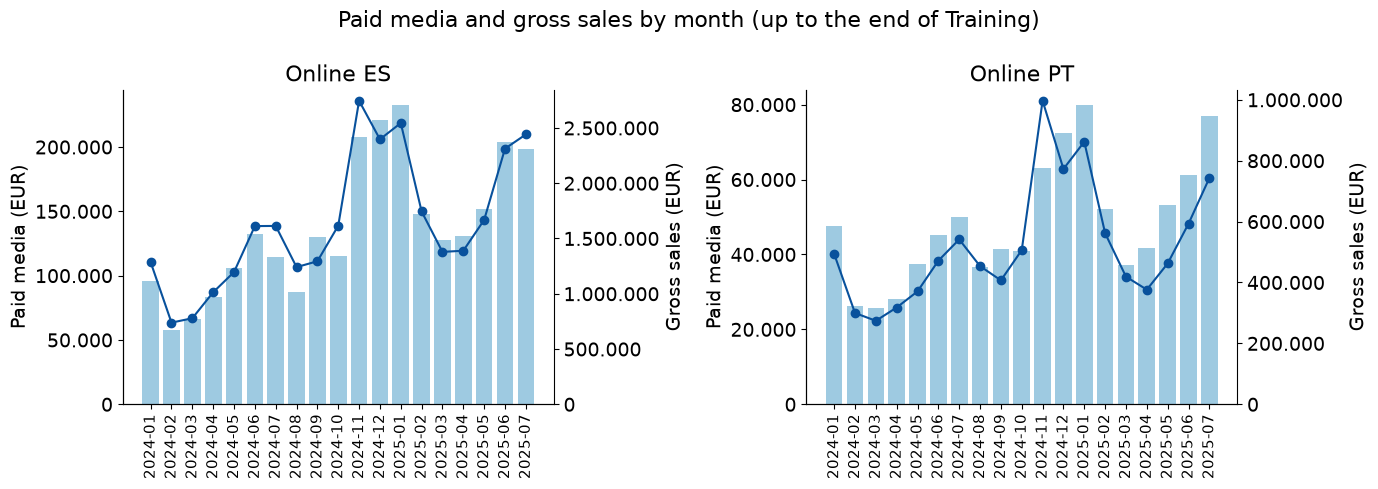

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Usa daily, monthly, MARKETS, START, END, fmt(), save_table(), save_fig(), lake, con (célula 1) e TRAIN_END, d2() (ponto 2).
# Se reiniciaste o kernel, volta a correr a célula 1 e a do ponto 2.
for nome in ['daily', 'monthly', 'MARKETS', 'START', 'END', 'fmt', 'save_table', 'save_fig', 'lake', 'con', 'TRAIN_END', 'd2']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e a do ponto 2 e depois esta.")

SILVER_PM = f"'{lake.uri('silver', 'slv_paid_media')}.parquet'"
mk_in_pm = ', '.join(f"'{m}'" for m in MARKETS)
TR = pd.Timestamp(TRAIN_END)                      # a análise só usa dados até ao fim do Training

# ---------- uma linha por mercado e dia (com contagens para detetar repetidos e vazios) ----------
pm = con.execute(f"""
    SELECT marketplace AS mark, paid_media_date AS day, count(*) AS n_rows, sum(amount_paid_media) AS spend,
           count(*) FILTER (WHERE amount_paid_media IS NULL) AS n_null
    FROM read_parquet({SILVER_PM}) WHERE marketplace IN ({mk_in_pm}) AND paid_media_date IS NOT NULL GROUP BY 1, 2""").df()
pm['day'] = pd.to_datetime(pm['day']); pm['spend'] = pm['spend'].astype(float)

# ---------- DLV9: cobertura e qualidade, por mercado ----------
N_SCOPE = int((pd.Timestamp(END) - pd.Timestamp(START)).days) + 1   # dias do âmbito (731)
rows9 = []
ok_cov = True
for m in MARKETS:
    g = pm[pm['mark'] == m]
    w = g[(g['day'] >= START) & (g['day'] <= END)]
    ok_cov &= bool(w.shape[0] == N_SCOPE and (w['n_rows'] > 1).sum() == 0 and (w['n_null'] > 0).sum() == 0 and (w['spend'] <= 0).sum() == 0)
    rows9.append({'Market': m, 'Table rows (all dates)': fmt(g['n_rows'].sum()), 'First day in table': g['day'].min().date(), 'Last day in table': g['day'].max().date(),
                  'Days with a row in 2024-2025': f"{fmt(w.shape[0])} of {fmt(N_SCOPE)}", 'Days with more than one row': fmt((w['n_rows'] > 1).sum()),
                  'Days with an empty amount': fmt((w['n_null'] > 0).sum()), 'Days with zero or negative spend': fmt((w['spend'] <= 0).sum())})
dlv9 = pd.DataFrame(rows9)
print('--- Cobertura e qualidade da tabela de paid media, por mercado ---')
display(dlv9)
print('Controlo 1: 731 dias por mercado, sem repetidos, vazios, zeros nem negativos | bate:', ok_cov)
save_table(dlv9, 'DLV9', 'Paid media table: coverage and quality by market (2024-2025)', 'whole table')

# ---------- tabela mensal: gross sales, encomendas e investimento (só até ao fim do Training) ----------
d = daily[['mark', 'day', 'month', 'orders', 'gross_sales']].merge(pm[['mark', 'day', 'spend']], on=['mark', 'day'], how='left')
d = d[d['day'] <= TR].copy()                       # os dias sem linha em paid media ficam vazios (não são zero)
mo = (d.groupby(['mark', 'month'])
        .agg(orders=('orders', 'sum'), gross=('gross_sales', 'sum'), spend=('spend', lambda s: s.sum(min_count=1)),
             days_spend=('spend', 'count'), days=('day', 'size')).reset_index())
mo['complete'] = mo['days_spend'] == mo['days']

# controlo 2: o gross sales mensal daqui coincide com o da tabela mensal da célula 1
cmp_m = mo.merge(monthly[['mark', 'month', 'gross_sales']], on=['mark', 'month'])
ok_gross = bool(len(cmp_m) == len(mo) and np.allclose(cmp_m['gross'], cmp_m['gross_sales']))

# ---------- DLV10: mês a mês, por mercado ----------
dlv10 = pd.DataFrame({'Market': mo['mark'], 'Month': mo['month'].astype(str), 'Gross sales (EUR)': mo['gross'].map(fmt),
                      'Paid media (EUR)': mo['spend'].map(fmt), 'Days with spend data': mo['days_spend'].astype(str) + ' of ' + mo['days'].astype(str),
                      'Paid media per 100 EUR of gross sales': (100 * mo['spend'] / mo['gross']).map(d2),
                      'Paid media per order (EUR)': (mo['spend'] / mo['orders']).map(d2)})
print('\n--- Paid media e gross sales por mês (até ' + str(TR.date()) + ') ---')
display(dlv10)
save_table(dlv10, 'DLV10', 'Paid media and gross sales by month and market, up to the end of Training', 'whole table')

# ---------- DLV11: correlações (só descrição; não prova efeito) ----------
def corr(a, b):
    ok = a.notna() & b.notna()
    return (a[ok].corr(b[ok]) if ok.sum() >= 3 else np.nan), int(ok.sum())

def lag_corr(t, col):
    return corr(t[col].astype(float), t['spend'].shift(2))      # investimento de M-2 contra o valor do mês M

def monthly_view(mkt):
    # mkt = nome do mercado ou 'ES+PT'. Meses incompletos ficam com investimento vazio.
    if mkt == 'ES+PT':
        t = mo.groupby('month').agg(orders=('orders', 'sum'), gross=('gross', 'sum'), spend=('spend', 'sum'), complete=('complete', 'all')).reset_index().sort_values('month')
    else:
        t = mo[mo['mark'] == mkt].sort_values('month').copy()
    t['spend'] = t['spend'].where(t['complete'])
    return t.reset_index(drop=True)

rows11 = []
for mkt in MARKETS + ['ES+PT']:
    if mkt == 'ES+PT':
        dd = d.groupby('day').agg(gross=('gross_sales', 'sum'), spend=('spend', lambda s: s.sum(min_count=len(s)))).reset_index()
    else:
        dd = d[d['mark'] == mkt].rename(columns={'gross_sales': 'gross'})
    r_day, n_day = corr(dd['gross'].astype(float), dd['spend'])
    t = monthly_view(mkt)
    r_lvl, n_lvl = corr(t['gross'].astype(float), t['spend'])
    r_ord, _ = corr(t['orders'].astype(float), t['spend'])                       # para comparar: o mesmo com as encomendas
    ch_g = t['gross'].astype(float).pct_change().replace([np.inf, -np.inf], np.nan)
    ch_s = t['spend'].pct_change().replace([np.inf, -np.inf], np.nan)
    r_chg, n_chg = corr(ch_g, ch_s)
    r_lag, n_lag = lag_corr(t, 'gross')
    rows11.append({'Market': mkt, 'Daily, same day': f"{d2(r_day)} ({n_day} days)", 'Monthly, level': f"{d2(r_lvl)} ({n_lvl} months)",
                   'Monthly, level, with orders instead': d2(r_ord), 'Monthly, change vs previous month': f"{d2(r_chg)} ({n_chg} months)",
                   'Spend of month M-2 vs gross sales of month M': f"{d2(r_lag)} ({n_lag} months)"})
dlv11 = pd.DataFrame(rows11)
print('\n--- Correlação entre paid media e gross sales (até ' + str(TR.date()) + ') ---')
display(dlv11)
save_table(dlv11, 'DLV11', 'Correlation between paid media and gross sales (daily, monthly level, monthly change, spend two months before)', 'whole table')

# ---------- controlos 3 e 4: as correlações recuperam valores conhecidos ----------
x = pd.Series(np.arange(1, 21, dtype=float) ** 1.5)
r_a, _ = corr(2.0 * x, x)                                                       # ligação perfeita -> 1,00
t_s = pd.DataFrame({'spend': x, 'gross': x.shift(2)})                           # gross do mês i = investimento do mês i-2
r_b, _ = lag_corr(t_s, 'gross')
print('\nControlo 2: gross sales mensal igual ao da tabela mensal da célula 1 | bate:', ok_gross)
print('Controlo 3: ligação perfeita dá correlação', d2(r_a), '(esperado 1,00) | bate:', bool(abs(r_a - 1) < 1e-9))
print('Controlo 4: gross sales = investimento de dois meses antes dá correlação com atraso', d2(r_b), '(esperado 1,00) | bate:', bool(abs(r_b - 1) < 1e-9))
print('Controlo 5: último dia usado:', d['day'].max().date(), '(esperado 2025-07-31) | bate:', d['day'].max() == TR)

# ---------- gráfico: investimento (barras) e gross sales (linha) por mês ----------
fig, axes = plt.subplots(1, len(MARKETS), figsize=(14, 5))
for ax, m in zip(np.atleast_1d(axes), MARKETS):
    t = mo[mo['mark'] == m].sort_values('month')
    xs = np.arange(len(t))
    ax.bar(xs, t['spend'].fillna(0), color='#9ecae1', label='Paid media (bars)')
    ax.set_xticks(xs); ax.set_xticklabels(t['month'].astype(str), rotation=90, fontsize=11)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(v)))
    ax.set_title(m); ax.set_ylabel('Paid media (EUR)')
    ax2 = ax.twinx(); ax2.spines['right'].set_visible(True)
    ax2.plot(xs, t['gross'], color='#08519c', marker='o', label='Gross sales (line)')
    ax2.set_ylim(bottom=0); ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(v))); ax2.set_ylabel('Gross sales (EUR)')
fig.suptitle('Paid media and gross sales by month (up to the end of Training)', fontsize=16)
fig.tight_layout()
save_fig(fig, 'DLV7_fig', 'Paid media (bars) and gross sales (line) by month and market, up to the end of Training', 'ES, PT')
plt.show()

# Eficiência: lê slv_paid_media uma vez (O(p), p = linhas da tabela); as junções e agrupamentos em pandas são O(D log D) com D = dias × mercados (≈ 1.462).
# Espaço O(p + D).

### 5a. Conclusions

**Confirmed**
- The paid media table is complete and clean for Online ES and Online PT, with no missing, repeated or zero days.
- Spend follows gross sales closely: in both markets, the months with the highest spend are also the months with the highest sales (Nov/Dec, Jan and Jun/Jul).
- With gross sales the link is equal to or slightly stronger than with orders, especially in Online ES.

**Derived**
- Spend is always around the same fraction of gross sales, with no big jumps from month to month. This suggests that the budget is set based on expected sales.
- At daily level the link is good, but much weaker than at monthly level. Paid media mainly explains the level of the month, not the day-to-day.
- Spend from two months earlier says very little about the month we want to forecast.

**Decision**
- **Scenario B (spend up to M-2):** is no longer a priority, because what is known at the cutoff hardly helps. It stays only as a quick test, if there is time.
- **Scenario A (no paid media):** stays as the main and most prudent scenario, because it does not depend on any assumption.
- **Scenario C (spend of M known at the cutoff):** stays, but is presented with the caveat that the budget of M follows expected sales. Part of the good result may come from that, and the assumption remains to be confirmed with Parfois.
- That leaves A and C, as with orders.

## 6. National holidays

**What we will do:** read the national holidays of Spain and Portugal (2024 and 2025) with the `holidays` package, measure how much each holiday, the day before and the two days after move daily gross sales from January to July (data up to 31/7/2025), and count how many holidays fall in each 2025 month to forecast, in total and on working days (Monday to Friday). Orders appear alongside only for comparison. The silver `slv_calendar` is not usable: it has Brazilian holidays and no market.

**Goal:** decide whether holidays become a variable in the gross sales model. Unlike Black Friday and Christmas, the holidays from January to July fall in Training, so their usefulness can be proven there.

**Definitions:**
- **Effect of a day:** the day's gross sales divided by the average of the same weekday 1 to 4 weeks earlier (at least 2 days). Only normal days count: no campaigns and no other holidays. This way the day of the week does not distort the measurement. 1,00 means no effect.
- **Joint effect:** the sum of the values divided by the sum of the references.
- **Status of each holiday:** measured; inside a fixed calendar campaign (already marked by the campaigns variable); inside another campaign only (Clearance, Free shipping, etc., which are not variables); or without enough normal reference days.
- **Scope:** national holidays only. Regional holidays in Spain are left out, as are the moves to Monday that some regions make (for example, 12/10/2025).
- **Comparison:** January to July 2024 against January to July 2025, the same months.

**Filter for the variables:**
1. Is it known at the cutoff? Yes, the holiday calendar is fixed by law (and Easter can be calculated).
2. Is it stable between 2024 and 2025?
3. Does it help reduce the error in Training? (measured later).

**Control values:**
- The holidays we know are in the calendar (for example, 06/01, 18/04, 15/08 and 08/12 of 2025 in Spain; 25/04, 10/06, 01/12 and 25/12 of 2025 in Portugal).
- The package gives 9 national holidays per year in Spain and 13 in Portugal. 12/10/2024 (a Saturday) counts in Spain and 12/10/2025 (a Sunday) does not.
- A synthetic series with a holiday of factor 0,7 returns 0,7.
- The last day measured is on or before 31/7/2025.

Pacote holidays, versão: 0.108

--- Controlo 1: feriados que conhecemos estão no calendário ---


,mercado,data,feriado,bate
0,Online ES,2025-01-06,Epiphany,True
1,Online ES,2025-04-18,Good Friday,True
2,Online ES,2025-08-15,Assumption Day,True
3,Online ES,2025-12-08,Immaculate Conception,True
4,Online PT,2025-04-25,Freedom Day,True
5,Online PT,2025-06-10,"Day of Portugal, Camões, and the Portuguese Co...",True
6,Online PT,2025-12-01,Restoration of Independence Day,True
7,Online PT,2025-12-25,Christmas Day,True


12/10/2024 (sábado) é feriado em ES: True | 12/10/2025 (domingo) não é feriado nacional em ES: True
Feriados nacionais por mercado e ano (2024 / 2025): {'Online ES': (9, 9), 'Online PT': (13, 13)}

--- Controlo 2: série sintética com fator conhecido ---
Fator recuperado: 0.700000 (esperado 0,7) | bate: True

--- Cada feriado nacional de janeiro a julho: valor do dia / mesmo dia da semana 1 a 4 semanas antes ---


,Market,Year,Holiday,Date,Weekday,Campaigns that day,Status,Gross sales vs same weekday 1-4 weeks before,Orders vs same weekday 1-4 weeks before
0,Online ES,2024,New Year's Day,01/01/2024,Mon,-,too few normal reference days,-,-
1,Online ES,2024,Epiphany,06/01/2024,Sat,Clearance,in another campaign only,-,-
2,Online ES,2024,Good Friday,29/03/2024,Fri,Easter and Holy Week,in a fixed-calendar campaign,-,-
3,Online ES,2024,Labor Day,01/05/2024,Wed,-,measured,"0,98","0,90"
4,Online ES,2025,New Year's Day,01/01/2025,Wed,Reyes,in a fixed-calendar campaign,-,-
5,Online ES,2025,Epiphany,06/01/2025,Mon,Clearance,in another campaign only,-,-
6,Online ES,2025,Good Friday,18/04/2025,Fri,Easter and Holy Week,in a fixed-calendar campaign,-,-
7,Online ES,2025,Labor Day,01/05/2025,Thu,-,too few normal reference days,-,-
8,Online PT,2024,New Year's Day,01/01/2024,Mon,Clearance,in another campaign only,-,-
9,Online PT,2024,Good Friday,29/03/2024,Fri,Easter and Holy Week,in a fixed-calendar campaign,-,-



--- Estado dos feriados de janeiro a julho, por mercado ---


Status,in a fixed-calendar campaign,in another campaign only,measured,too few normal reference days
Market,,,,
Online ES,3,2,1,2
Online PT,5,2,6,1


Guardado: evidence_dl_vendas/DLV12.csv

--- Resumo (janeiro a julho): efeito do feriado, da véspera e do dia depois ---


,Market,Day type,2024: days,2024: gross sales effect,2024: orders effect,2024: gross sales below reference,2025: days,2025: gross sales effect,2025: orders effect,2025: gross sales below reference
0,Online ES,2 days before,0,-,-,0 of 0,1,"1,06","1,05",0 of 1
1,Online ES,Day before,0,-,-,0 of 0,1,"1,51","1,44",0 of 1
2,Online ES,Holiday,1,"0,98","0,90",1 of 1,0,-,-,0 of 0
3,Online ES,Day after,1,"1,15","1,20",0 of 1,0,-,-,0 of 0
4,Online ES,2 days after,1,"1,06","1,08",0 of 1,0,-,-,0 of 0
5,Online PT,2 days before,1,"1,08","0,99",0 of 1,4,"0,66","0,64",3 of 4
6,Online PT,Day before,1,"0,90","0,90",1 of 1,3,"0,91","0,92",2 of 3
7,Online PT,Holiday,4,"0,94","0,95",2 of 4,2,"0,98","0,92",1 of 2
8,Online PT,Day after,3,"1,05","1,04",1 of 3,2,"0,97","0,89",2 of 2
9,Online PT,2 days after,4,"0,99","1,01",2 of 4,3,"0,91","0,93",3 of 3


Guardado: evidence_dl_vendas/DLV13.csv

--- Controlo 3: último dia medido: 2025-06-21 | bate (<= 31/7/2025): True
Controlo 4: mesmos dias medidos em gross sales e encomendas | bate: True

--- Feriados nacionais por mês-alvo de 2025 (só calendário) ---


,Month to forecast,Set,Online ES,Online ES: Mon-Fri,Online PT,Online PT: Mon-Fri
0,Jan 2025,Training,2,2,1,1
1,Feb 2025,Training,0,0,0,0
2,Mar 2025,Training,0,0,0,0
3,Apr 2025,Training,1,1,3,2
4,May 2025,Training,1,1,1,1
5,Jun 2025,Training,0,0,2,2
6,Jul 2025,Training,0,0,0,0
7,Aug 2025,Test,1,1,1,1
8,Sep 2025,Test,0,0,0,0
9,Oct 2025,Test,0,0,1,0


Guardado: evidence_dl_vendas/DLV14.csv
Guardado: evidence_dl_vendas/DLV8_fig.png


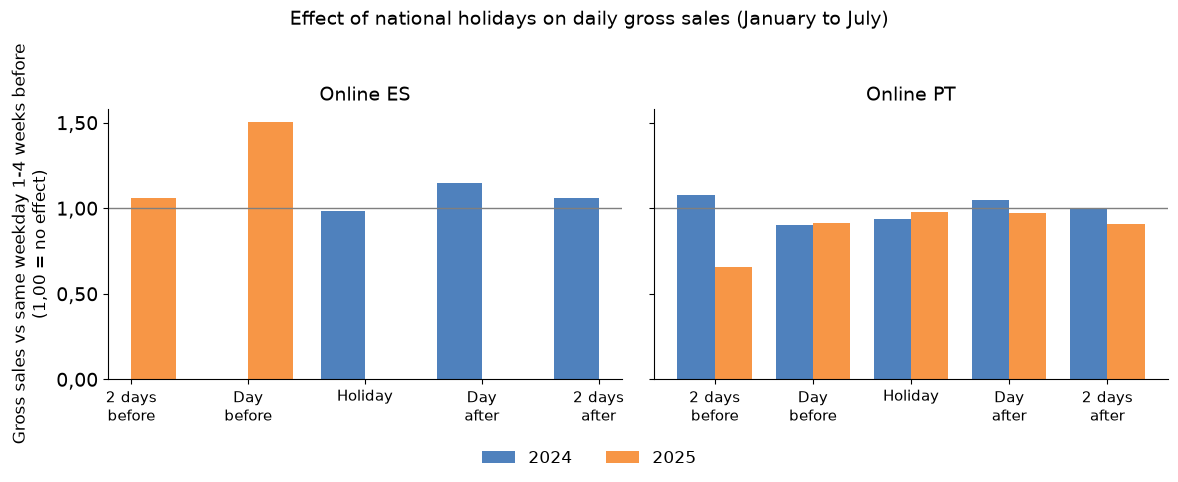

In [6]:
import importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
try:
    import holidays                       # calendário de feriados nacionais; se faltar, corre %pip install holidays numa célula nova
except ImportError:
    raise ImportError("Falta o pacote holidays. Corre %pip install holidays numa célula nova e volta a correr esta.")

# Usa daily, MARKETS, START, END, TARGETS, fmt(), split_of(), save_table(), save_fig(), con, mk_in, mk_values (célula 1), TRAIN_END, train_only(), d2() (ponto 2)
# e FAMS e a tabela ev_dl (ponto 3). Se reiniciaste o kernel, volta a correr a célula 1 e as dos pontos 2 e 3.
for nome in ['daily', 'MARKETS', 'START', 'END', 'TARGETS', 'fmt', 'split_of', 'save_table', 'save_fig', 'con', 'mk_in', 'mk_values',
             'TRAIN_END', 'train_only', 'd2', 'FAMS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e as dos pontos 2 e 3 e depois esta.")
try:
    con.execute("SELECT count(*) FROM ev_dl").fetchall()          # ev_dl é uma tabela do DuckDB criada no ponto 3
except Exception:
    raise RuntimeError("A tabela ev_dl não existe. Volta a correr a célula do ponto 3 e depois esta.")
print('Pacote holidays, versão:', md.version('holidays'))

COUNTRY = {'Online ES': 'ES', 'Online PT': 'PT'}
REF_LAGS, HMIN_REF = (1, 2, 3, 4), 2     # referência de um dia: o mesmo dia da semana 1 a 4 semanas antes (mínimo 2 dias normais)
# Campanhas (todas) que ficam fora da referência: o passado é conhecido ao corte (lista igual à do notebook das encomendas)
REMOVE_FAMS = ['Black Friday', 'Christmas', 'Mothers Day', 'Reyes', 'Valentines', 'Free shipping', 'Get your basket ready',
               'Stock 1', 'Special prices', 'Easter and Holy Week', 'Clearance', 'Iberian blackout']

def build_days(fams):
    # dias de campanha por mercado: eventos válidos com mercado + linhas da Black Friday sem mercado (valem para os dois mercados)
    fam_in = ', '.join(f"'{f}'" for f in fams)
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE camp_days_hol AS
    WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
    rows_m AS (
      SELECT mark, family, CAST(day_ts AS DATE) AS day FROM (
        SELECT mark, family,
               unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                      CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
        FROM ev_dl WHERE valid AND mark IN ({mk_in}) AND family IN ({fam_in}))),
    rows_g AS (
      SELECT mk.mark, g.family, g.day FROM (
        SELECT family, CAST(day_ts AS DATE) AS day FROM (
          SELECT family,
                 unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                        CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts
          FROM ev_dl WHERE valid AND mark = 'All' AND family = 'Black Friday' AND 'Black Friday' IN ({fam_in}))) g
      CROSS JOIN mk)
    SELECT DISTINCT mark, family, day FROM (SELECT * FROM rows_m UNION ALL SELECT * FROM rows_g)
    """)
    d = con.sql("SELECT mark, family, day FROM camp_days_hol").df()
    d['day'] = pd.to_datetime(d['day'])
    return d

rem_df = build_days(REMOVE_FAMS)
camp_days = {mk: set(rem_df.loc[rem_df['mark'] == mk, 'day']) for mk in MARKETS}

# ---------- feriados nacionais (só o calendário: conhecem-se para qualquer data futura) ----------
def national_holidays(country):
    try:
        h = holidays.country_holidays(country, years=[2024, 2025], language='en_US')    # nomes em inglês
    except Exception:
        h = holidays.country_holidays(country, years=[2024, 2025])
    return {pd.Timestamp(d): n for d, n in h.items() if pd.Timestamp(START) <= pd.Timestamp(d) <= pd.Timestamp(END)}

hol = {mk: national_holidays(COUNTRY[mk]) for mk in MARKETS}
hol_days = {mk: set(hol[mk]) for mk in MARKETS}

# ---------- controlo 1: feriados conhecidos existem no calendário do pacote ----------
known = {'Online ES': ['2025-01-06', '2025-04-18', '2025-08-15', '2025-12-08'],
         'Online PT': ['2025-04-25', '2025-06-10', '2025-12-01', '2025-12-25']}
rows = [{'mercado': mk, 'data': d, 'feriado': hol[mk].get(pd.Timestamp(d), '-'), 'bate': pd.Timestamp(d) in hol_days[mk]} for mk in MARKETS for d in known[mk]]
print('\n--- Controlo 1: feriados que conhecemos estão no calendário ---')
display(pd.DataFrame(rows))
print('12/10/2024 (sábado) é feriado em ES:', pd.Timestamp('2024-10-12') in hol_days['Online ES'],
      '| 12/10/2025 (domingo) não é feriado nacional em ES:', pd.Timestamp('2025-10-12') not in hol_days['Online ES'])
print('Feriados nacionais por mercado e ano (2024 / 2025):',
      {mk: (sum(d.year == 2024 for d in hol_days[mk]), sum(d.year == 2025 for d in hol_days[mk])) for mk in MARKETS})

# ---------- fator de um dia: valor do dia / média do mesmo dia da semana 1 a 4 semanas antes (só dias normais) ----------
def day_pairs(s, days, excl):
    # s: valor por dia; days: dias a medir; excl: dias que não servem de referência (campanhas e feriados)
    out = {}
    for d in days:
        if d not in s.index:
            continue
        refs = [s[d - pd.Timedelta(days=7 * k)] for k in REF_LAGS
                if (d - pd.Timedelta(days=7 * k)) in s.index and (d - pd.Timedelta(days=7 * k)) not in excl]
        if len(refs) >= HMIN_REF:
            out[d] = (float(s[d]), float(np.mean(refs)))       # (real, referência); a referência só usa dias anteriores a d
    return out

# controlo 2: série sintética com padrão semanal e um feriado com fator conhecido (0,7) -> o método devolve 0,7
dt = pd.date_range('2024-01-01', periods=100)
s_t = pd.Series([100.0 + 30 * x.weekday() for x in dt], index=dt)
hd = dt[50]; s_t[hd] = s_t[hd] * 0.7
p_t = day_pairs(s_t, [hd], {hd})
print('\n--- Controlo 2: série sintética com fator conhecido ---')
print('Fator recuperado:', f"{p_t[hd][0] / p_t[hd][1]:.6f}", '(esperado 0,7) | bate:', bool(abs(p_t[hd][0] / p_t[hd][1] - 0.7) < 1e-9))

# ---------- estudo: só dados até 31/7/2025; compara janeiro a julho de 2024 com janeiro a julho de 2025 ----------
d_study = train_only(daily)
ser_g = {mk: g.set_index('day')['gross_sales'].sort_index() for mk, g in d_study.groupby('mark')}   # o alvo: gross sales em euros
ser_o = {mk: g.set_index('day')['orders'].sort_index() for mk, g in d_study.groupby('mark')}        # só para comparar
DAY_TYPES = [('2 days before', -2), ('Day before', -1), ('Holiday', 0), ('Day after', 1), ('2 days after', 2)]
FIXED_FAMS = set(FAMS)      # só as seis campanhas de calendário fixo (ponto 3) entram como variável; as outras (Clearance, Free shipping, etc.) não
camp_fams = rem_df.groupby(['mark', 'day'])['family'].apply(lambda x: sorted(set(x))).to_dict()      # (mercado, dia) -> campanhas desse dia
meas, rows12 = [], []
for mk in MARKETS:
    excl = camp_days[mk] | hol_days[mk]
    for h_day, h_name in sorted(hol[mk].items()):
        if h_day.month > 7 or h_day > TRAIN_END:
            continue                                            # só janeiro a julho (mesmos meses nos dois anos)
        for tipo, off in DAY_TYPES:
            d = h_day + pd.Timedelta(days=off)
            if d in excl and off != 0:
                continue                                        # véspera/dia depois que seja outro feriado ou campanha não serve
            em_campanha = d in camp_days[mk]
            pg = {} if em_campanha else day_pairs(ser_g[mk], [d], excl)
            po = {} if em_campanha else day_pairs(ser_o[mk], [d], excl)
            meas.append({'mark': mk, 'year': h_day.year, 'type': tipo, 'day': d,
                         'real': pg[d][0] if d in pg else np.nan, 'ref': pg[d][1] if d in pg else np.nan,
                         'real_o': po[d][0] if d in po else np.nan, 'ref_o': po[d][1] if d in po else np.nan})
            if off == 0:
                r = meas[-1]                                    # o registo do próprio feriado
        fams_dia = camp_fams.get((mk, h_day), [])
        if not np.isnan(r['real']):
            estado = 'measured'
        elif any(f in FIXED_FAMS for f in fams_dia):
            estado = 'in a fixed-calendar campaign'
        elif fams_dia:
            estado = 'in another campaign only'
        else:
            estado = 'too few normal reference days'
        rows12.append({'Market': mk, 'Year': h_day.year, 'Holiday': h_name, 'Date': h_day.strftime('%d/%m/%Y'), 'Weekday': h_day.day_name()[:3],
                       'Campaigns that day': ', '.join(fams_dia) if fams_dia else '-', 'Status': estado,
                       'Gross sales vs same weekday 1-4 weeks before': '-' if np.isnan(r['real']) else d2(r['real'] / r['ref']),
                       'Orders vs same weekday 1-4 weeks before': '-' if np.isnan(r['real_o']) else d2(r['real_o'] / r['ref_o'])})
meas = pd.DataFrame(meas)
dlv12 = pd.DataFrame(rows12)
print('\n--- Cada feriado nacional de janeiro a julho: valor do dia / mesmo dia da semana 1 a 4 semanas antes ---')
display(dlv12)
print('\n--- Estado dos feriados de janeiro a julho, por mercado ---')
display(dlv12.groupby(['Market', 'Status']).size().unstack(fill_value=0))
save_table(dlv12, 'DLV12', 'Effect of each national holiday (January to July) on daily gross sales and orders', 'whole table')

# resumo: efeito conjunto = soma dos valores / soma das referências (gross sales e, para comparar, encomendas)
rows13 = []
for mk in MARKETS:
    for tipo, _ in DAY_TYPES:
        row = {'Market': mk, 'Day type': tipo}
        for yr in (2024, 2025):
            g = meas[(meas['mark'] == mk) & (meas['type'] == tipo) & (meas['year'] == yr)].dropna(subset=['real'])
            row[f'{yr}: days'] = len(g)
            row[f'{yr}: gross sales effect'] = d2(g['real'].sum() / g['ref'].sum()) if len(g) else '-'
            row[f'{yr}: orders effect'] = d2(g['real_o'].sum() / g['ref_o'].sum()) if len(g) else '-'
            row[f'{yr}: gross sales below reference'] = f"{int((g['real'] < g['ref']).sum())} of {len(g)}"
        rows13.append(row)
dlv13 = pd.DataFrame(rows13)
print('\n--- Resumo (janeiro a julho): efeito do feriado, da véspera e do dia depois ---')
display(dlv13)
save_table(dlv13, 'DLV13', 'Summary of the national-holiday effect on daily gross sales and orders by market and year, January to July', 'whole table')

# ---------- controlo 3: sem fugas (só dias até 31/7/2025; as referências são sempre anteriores ao dia medido) ----------
ult = meas.dropna(subset=['real'])['day'].max()
print('\n--- Controlo 3: último dia medido:', ult.date(), '| bate (<= 31/7/2025):', bool(ult <= TRAIN_END))

# controlo 4: o gross sales e as encomendas medem os mesmos dias (mesmos dias medidos nos dois)
print('Controlo 4: mesmos dias medidos em gross sales e encomendas | bate:', bool((meas['real'].isna() == meas['real_o'].isna()).all()))

# ---------- calendário: quantos feriados nacionais caem em cada mês-alvo de 2025 (só datas, nunca valores) ----------
rows14 = []
for m in TARGETS:
    row = {'Month to forecast': m.strftime('%b %Y'), 'Set': split_of(m)}
    for mk in MARKETS:
        dias = [d for d in hol_days[mk] if d.year == m.year and d.month == m.month]
        row[mk] = len(dias)
        row[f'{mk}: Mon-Fri'] = sum(d.weekday() < 5 for d in dias)      # os que caem ao fim de semana mexem pouco nas vendas de um dia útil
    rows14.append(row)
dlv14 = pd.DataFrame(rows14)
print('\n--- Feriados nacionais por mês-alvo de 2025 (só calendário) ---')
display(dlv14)
save_table(dlv14, 'DLV14', 'National holidays in each 2025 target month, by market (calendar only)', 'whole table')

# ---------- gráfico: efeito (gross sales) de véspera, feriado e dia depois, por mercado e ano ----------
fig, axes = plt.subplots(1, len(MARKETS), sharey=True, figsize=(12, 4.8))
for ax, mk in zip(np.atleast_1d(axes), MARKETS):
    for k, (yr, cor) in enumerate([(2024, '#4F81BD'), (2025, '#F79646')]):
        vals = []
        for tipo, _ in DAY_TYPES:
            g = meas[(meas['mark'] == mk) & (meas['type'] == tipo) & (meas['year'] == yr)].dropna(subset=['real'])
            vals.append(g['real'].sum() / g['ref'].sum() if len(g) else np.nan)
        ax.bar(np.arange(len(DAY_TYPES)) + (k - 0.5) * 0.38, vals, width=0.38, color=cor, label=str(yr))
    ax.axhline(1, color='#7F7F7F', linewidth=1)
    ax.set_xticks(range(len(DAY_TYPES))); ax.set_xticklabels([t.replace(' before', '\nbefore').replace(' after', '\nafter') for t, _ in DAY_TYPES], fontsize=11)
    ax.set_title(mk, fontsize=14); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: d2(v)))
np.atleast_1d(axes)[0].set_ylabel('Gross sales vs same weekday 1-4 weeks before\n(1,00 = no effect)', fontsize=12)
handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=12)
fig.suptitle('Effect of national holidays on daily gross sales (January to July)', fontsize=14)
fig.tight_layout(rect=[0, 0.07, 1, 0.95])
save_fig(fig, 'DLV8_fig', 'Effect of national holidays on daily gross sales by market and year, January to July', 'ES, PT')
plt.show()

# Eficiência: cada feriado mede 3 dias com no máximo 4 referências: O(h·5·4) com h ≈ 40 feriados; o calendário por mês é O(12·h); agrupar as campanhas por dia é O(c), c = linhas campanha-dia.
# Espaço O(d + h + c), com d = 731 dias por mercado.

### 6a. Conclusions

**Confirmed**
- The holiday calendar is right in both markets, and the holidays we know are there.
- Gross sales and orders tell the same story: holidays hardly move sales.

**Derived**
- Few holidays can be measured cleanly, because most fall inside a campaign or have no normal days to compare with. In Spain only one holiday could be measured.
- In Portugal, the holiday itself stays close to normal in both years. The eve and the day after move in one direction in one year and in the other direction the next, so there is no stable pattern.
- The only bar that stands out (two days before, Portugal, 2025) does not repeat in 2024, so we do not treat it as an effect.
- In the months to forecast there are few holidays on working days, except in December, which already has the Christmas campaigns.

**Decision**
- One simple variable goes in: **national holiday on a working day** (yes/no). It is known at the cutoff and costs nothing.
- We do **not** create variables for the eve or the day after, because the data does not support them.
- The usefulness of the holiday remains to be proven in Training, with and without this variable, before we keep it in the final model.

## 7. Simple calendar: day of the week, day of the month and month of the year

**What we will do:** study three pure calendar variables in daily gross sales, using only data up to 31/7/2025: (1) the day of the week, (2) the day of the month (for example, whether the end of the month, near payday, sells more) and (3) the month of the year (the shape of seasonality). For the day of the month we also measure what share of days is left out of the study because they are campaign or holiday days.

**Goal:** decide whether they become variables in the model and understand how far seasonality can be confirmed with two years of history. All of them are known in advance for any month to forecast.

**Definitions:**
- **Day-of-week index:** the day's gross sales divided by the average of the 7 days centred on that day. This leaves out the level, the trend and slow seasonality, so only the day-of-week effect remains. The index for each weekday is the median of those ratios, adjusted so that the 7-day average is 1,00. January to July 2024 is compared with January to July 2025 (the same months).
- **Day of the month:** only normal days (no campaigns or holidays), with the day-of-week effect already removed. Each day is divided by the average of the normal days of the same month and grouped into bands of the month (1-5, 6-10, 11-15, 16-20, 21-25, 26-end). 1,00 means no effect. A month is only included if it has at least 15 normal days.
- **"Clear" effect:** the 95% interval does not include 1,00. The interval uses Student's t with (months − 1) degrees of freedom, so it widens when there are few months.
- **Month of the year:** gross sales per day of each month, divided by the January–July average of the same year. This leaves out growth from one year to the next and compares only the shape. Here all days count, campaigns included, because they are part of seasonality (for example, Black Friday in November).
- August to December 2025 stays closed (it is Test); only August to December 2024 is visible.

**Filter for the variables:**
1. Is it known at the cutoff? Yes, it is the calendar.
2. Is it stable between 2024 and 2025?
3. Does it help reduce the error in Training? (measured later, with and without the variable).

**Control values:**
- With a known day-of-week effect (synthetic series), the recovered index matches the effect.
- With a known day-of-the-month effect, the ratio between the 26-end and 11-15 bands is exactly 1,2.
- The interval for [1, 2, 3] has a half-width of 2,484.
- Days used in the day-of-week index: 210 in 2024 (213 days minus 3 from the start of the moving average) and 209 in 2025 (212 minus 3 from the end).
- The last day used is 31/7/2025.

--- Controlo 1: efeitos conhecidos (série sintética) ---
Dia da semana, erro máximo do índice recuperado: 0.00e+00 | bate: True
Dia do mês, razão 26-fim / 11-15 em cada mês, mínimo e máximo: 1.200000 e 1.200000 (esperado 1,2) | bate: True
Meia-largura do intervalo para [1, 2, 3]: 2.484 (esperado 2,484) | bate: True

--- Controlo 2: dias usados no índice do dia da semana, por mercado e ano ---


year,2024,2025
mark,,
Online ES,210,209
Online PT,210,209


(esperado 210 em 2024 = 213 dias de janeiro a julho menos 3 do início da média móvel; 209 em 2025 = 212 menos 3 do fim)

--- Índice do dia da semana do gross sales (1,00 = média da semana), janeiro a julho ---


,Market,Weekday,Index Jan-Jul 2024,Index Jan-Jul 2025,Difference
0,Online ES,Monday,"1,05","1,01","-0,04"
1,Online ES,Tuesday,"1,11","1,07","-0,04"
2,Online ES,Wednesday,"0,99","1,00","0,01"
3,Online ES,Thursday,"1,02","1,08","0,06"
4,Online ES,Friday,"0,92","1,00","0,07"
5,Online ES,Saturday,"0,98","0,94","-0,04"
6,Online ES,Sunday,"0,93","0,90","-0,03"
7,Online PT,Monday,"1,02","0,96","-0,06"
8,Online PT,Tuesday,"1,10","1,05","-0,05"
9,Online PT,Wednesday,"0,98","1,00","0,02"


Guardado: evidence_dl_vendas/DLV15.csv

--- Estabilidade do padrão do dia da semana e peso na variação diária ---


,Market,Correlation 2024 vs 2025,Largest difference (index points),Weekday range 2024 (max - min),Weekday range 2025 (max - min),Share of daily variation explained by weekday
0,Online ES,"0,70","0,07","0,18","0,17","6,6%"
1,Online PT,"0,67","0,08","0,21","0,21","17,1%"


... (2 outputs left out)

Guardado: evidence_dl_vendas/DLV16.csv

--- Mês do ano: gross sales por dia relativo à média de janeiro a julho do mesmo ano (agosto a dezembro de 2025 fica fechado) ---


,Month,Online ES 2024,Online ES 2025,Online PT 2024,Online PT 2025
0,Jan,"1,07","1,29","1,23","1,47"
1,Feb,"0,66","0,98","0,80","1,06"
2,Mar,"0,65","0,70","0,68","0,71"
3,Apr,"0,88","0,73","0,82","0,66"
4,May,"1,00","0,85","0,92","0,79"
5,Jun,"1,39","1,21","1,21","1,04"
6,Jul,"1,35","1,24","1,35","1,27"
7,Aug,"1,04",-,"1,13",-
8,Sep,"1,12",-,"1,05",-
9,Oct,"1,35",-,"1,26",-


,Market,"Correlation of the Jan-Jul profile, 2024 vs 2025",Largest difference (index points)
0,Online ES,"0,75","0,32"
1,Online PT,"0,79","0,26"


Guardado: evidence_dl_vendas/DLV17.csv

Controlo 3: meses usados no dia do mês por mercado: {'Online ES': 8, 'Online PT': 8} (esperado até 19, de janeiro de 2024 a julho de 2025)
Controlo 4: último dia usado: 2025-07-31 | bate (<= 31/7/2025): True
Guardado: evidence_dl_vendas/DLV9_fig.png


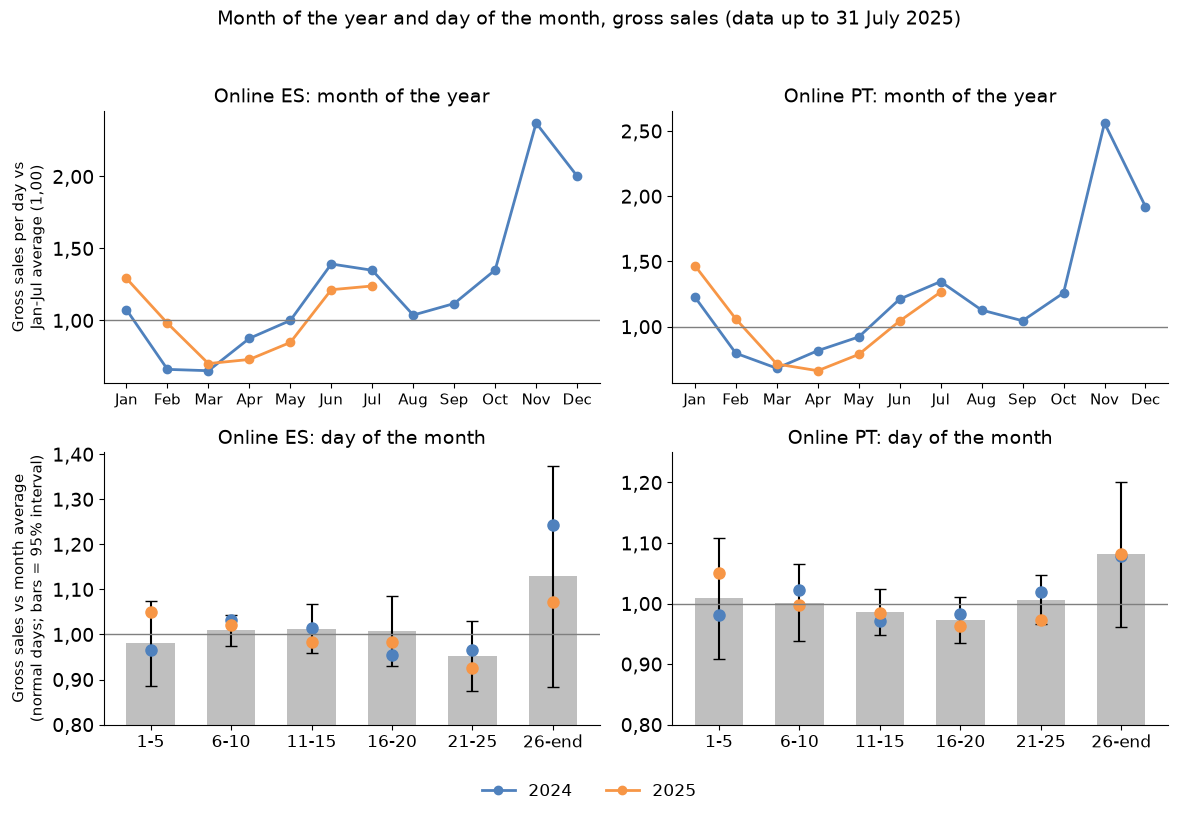

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Usa daily, TARGET, MARKETS, fmt(), pct(), save_table(), save_fig() (célula 1), TRAIN_END, train_only(), d2() (ponto 2) e camp_days, hol_days, camp_fams, FIXED_FAMS (ponto 6).
# Se reiniciaste o kernel, volta a correr a célula 1 e as dos pontos 2, 3 e 6.
for nome in ['daily', 'TARGET', 'MARKETS', 'fmt', 'pct', 'save_table', 'save_fig', 'TRAIN_END', 'train_only', 'd2',
             'camp_days', 'hol_days', 'camp_fams', 'FIXED_FAMS']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e as dos pontos 2, 3 e 6 e depois esta.")

WEEKDAYS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
BANDS = [(1, 5, '1-5'), (6, 10, '6-10'), (11, 15, '11-15'), (16, 20, '16-20'), (21, 25, '21-25'), (26, 31, '26-end')]
MIN_NORMAL = 15      # um mês só entra no estudo do dia do mês se tiver pelo menos 15 dias normais
T975 = {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365, 8: 2.306, 9: 2.262, 10: 2.228, 11: 2.201, 12: 2.179}

def half_ci(v):
    # meia-largura do intervalo de 95% da média de v: t(n-1) x erro-padrão (com poucos meses o intervalo alarga)
    v = np.asarray(v, dtype=float)
    return T975.get(len(v) - 1, 1.96) * v.std(ddof=1) / np.sqrt(len(v))

def band_of(day):
    return next(lbl for lo, hi, lbl in BANDS if lo <= day <= hi)

# ---------- índice do dia da semana: valor do dia / média dos 7 dias centrados nesse dia ----------
def weekday_ratios(df, target):
    # a média de 7 dias centrados tem cada dia da semana uma vez: o nível, a tendência e a sazonalidade lenta ficam de fora
    d = df[['mark', 'day', target]].sort_values(['mark', 'day']).copy()
    d['ma7'] = d.groupby('mark')[target].transform(lambda s: s.rolling(7, center=True).mean())
    d['ratio'] = d[target] / d['ma7']
    d = d.dropna(subset=['ratio']).copy()                            # perde 3 dias em cada ponta de cada mercado
    d['weekday'] = d['day'].dt.dayofweek                             # 0 = segunda-feira
    d['year'] = d['day'].dt.year
    return d

def weekday_index(d, by=('mark', 'year')):
    # mediana dos rácios por dia da semana (robusta a dias de campanha), normalizada para média 1,00 nos 7 dias
    by = list(by)
    idx = d.groupby(by + ['weekday'])['ratio'].median().rename('index').reset_index()
    idx['index'] = idx['index'] / idx.groupby(by)['index'].transform('mean')
    idx['days'] = d.groupby(by + ['weekday'])['ratio'].count().values
    return idx

def band_effects(adj, normal):
    # adj: valor por dia sem o efeito do dia da semana; normal: máscara de dias normais (sem campanha nem feriado).
    # Em cada mês, cada dia normal divide-se pela média dos dias normais do mês; depois média por faixa do mês.
    x = adj[normal]
    rows = []
    for (y, m), g in x.groupby([x.index.year, x.index.month]):
        if len(g) < MIN_NORMAL:
            continue
        rel = g / g.mean()
        b = rel.groupby([band_of(d.day) for d in rel.index]).mean().to_dict()
        b.update({'year': y, 'month': m})
        rows.append(b)
    return pd.DataFrame(rows)

# ---------- controlo 1: com efeitos conhecidos, os métodos recuperam-nos ----------
f_true = np.array([1.2, 1.1, 1.0, 1.0, 1.1, 0.9, 0.7])             # média 1,00
dias = pd.date_range('2024-01-01', '2024-12-31')
sint = pd.DataFrame({'mark': 'teste', 'day': dias, 'v': 1000 * f_true[dias.dayofweek]})
i_t = weekday_index(weekday_ratios(sint, 'v'))
erro_w = np.abs(i_t['index'].to_numpy() - f_true).max()
dt = pd.date_range('2024-01-01', '2025-06-30')
mf = pd.Series([1.0 + 0.05 * (d.month % 5) for d in dt], index=dt)                          # nível diferente em cada mês
bf_t = pd.Series([1.2 if d.day >= 26 else (1.0 if 11 <= d.day <= 15 else 1.05) for d in dt], index=dt)
be_t = band_effects(1000 * mf * bf_t, pd.Series(True, index=dt))
razao = (be_t['26-end'] / be_t['11-15']).to_numpy()                                         # em cada mês a razão entre faixas tem de ser 1,2
print('--- Controlo 1: efeitos conhecidos (série sintética) ---')
print('Dia da semana, erro máximo do índice recuperado:', f"{erro_w:.2e}", '| bate:', bool(erro_w < 1e-9))
print('Dia do mês, razão 26-fim / 11-15 em cada mês, mínimo e máximo:', f"{razao.min():.6f} e {razao.max():.6f}", '(esperado 1,2) | bate:', bool(np.abs(razao - 1.2).max() < 1e-9))
print('Meia-largura do intervalo para [1, 2, 3]:', f"{half_ci([1, 2, 3]):.3f}", '(esperado 2,484) | bate:', bool(abs(half_ci([1, 2, 3]) - 4.303 / np.sqrt(3)) < 1e-9))

# ---------- dados do estudo: só até 31/7/2025 ----------
d_study = train_only(daily)
d_all = weekday_ratios(d_study, TARGET)
d_jj = d_all[d_all['day'].dt.month <= 7].copy()                                             # janeiro a julho dos dois anos (mesmos meses)
cont = d_jj.groupby(['mark', 'year'])['day'].count().unstack('year')
print('\n--- Controlo 2: dias usados no índice do dia da semana, por mercado e ano ---')
display(cont)
print('(esperado 210 em 2024 = 213 dias de janeiro a julho menos 3 do início da média móvel; 209 em 2025 = 212 menos 3 do fim)')

# ---------- DLV15: dia da semana, janeiro a julho de 2024 contra 2025 ----------
idx = weekday_index(d_jj)
rows15 = []
for mk in MARKETS:
    for w in range(7):
        a = idx[(idx['mark'] == mk) & (idx['year'] == 2024) & (idx['weekday'] == w)]['index'].iloc[0]
        b = idx[(idx['mark'] == mk) & (idx['year'] == 2025) & (idx['weekday'] == w)]['index'].iloc[0]
        rows15.append({'Market': mk, 'Weekday': WEEKDAYS[w], 'Index Jan-Jul 2024': d2(a), 'Index Jan-Jul 2025': d2(b), 'Difference': d2(b - a)})
dlv15 = pd.DataFrame(rows15)
print('\n--- Índice do dia da semana do gross sales (1,00 = média da semana), janeiro a julho ---')
display(dlv15)
save_table(dlv15, 'DLV15', 'Weekday index of daily gross sales, January to July of 2024 and 2025, by market', 'whole table')

rows15b = []
for mk in MARKETS:
    a = idx[(idx['mark'] == mk) & (idx['year'] == 2024)].sort_values('weekday')['index'].to_numpy()
    b = idx[(idx['mark'] == mk) & (idx['year'] == 2025)].sort_values('weekday')['index'].to_numpy()
    g = d_jj[d_jj['mark'] == mk]
    x = np.log(g['ratio'])
    r2 = 1 - ((x - x.groupby(g['weekday']).transform('mean')) ** 2).sum() / ((x - x.mean()) ** 2).sum()
    rows15b.append({'Market': mk, 'Correlation 2024 vs 2025': d2(np.corrcoef(a, b)[0, 1]), 'Largest difference (index points)': d2(np.abs(a - b).max()),
                    'Weekday range 2024 (max - min)': d2(a.max() - a.min()), 'Weekday range 2025 (max - min)': d2(b.max() - b.min()),
                    'Share of daily variation explained by weekday': pct(r2)})
dlv15b = pd.DataFrame(rows15b)
print('\n--- Estabilidade do padrão do dia da semana e peso na variação diária ---')
display(dlv15b)
save_table(dlv15b, 'DLV15b', 'Weekday pattern of gross sales: stability between 2024 and 2025 and share of daily variation explained', 'whole table')

# ---------- dia do mês: valor sem o efeito do dia da semana, só dias normais ----------
widx = weekday_index(d_all.assign(year=0)).set_index(['mark', 'weekday'])['index']      # índice por mercado com todos os dias até 31/7/2025
series, adj, normal = {}, {}, {}
for mk, g in d_study.groupby('mark'):
    s = g.set_index('day')[TARGET].sort_index()
    series[mk] = s
    adj[mk] = s / np.array([widx[(mk, w)] for w in s.index.dayofweek])
    normal[mk] = pd.Series([(d not in camp_days[mk]) and (d not in hol_days[mk]) for d in s.index], index=s.index)

rows16, be_all = [], {}
for mk in MARKETS:
    be = band_effects(adj[mk], normal[mk])
    be_all[mk] = be
    days = series[mk].index
    for lo, hi, lbl in BANDS:
        v = be[lbl].dropna()
        eff, h = v.mean(), half_ci(v)
        v24 = be[(be['year'] == 2024) & (be['month'] <= 7)][lbl].dropna()
        v25 = be[(be['year'] == 2025) & (be['month'] <= 7)][lbl].dropna()
        dd = [d for d in days if band_of(d.day) == lbl]
        n_out = sum(not normal[mk][d] for d in dd)                                       # dias da faixa que ficam fora (campanha ou feriado)
        n_fix = sum(any(f in FIXED_FAMS for f in camp_fams.get((mk, d), [])) for d in dd)
        rows16.append({'Market': mk, 'Day of the month': lbl, 'Effect (all months)': d2(eff), '95% interval': f"{d2(eff - h)} to {d2(eff + h)}",
                       'Clear? (95% interval excludes 1,00)': 'yes' if abs(eff - 1) > h else 'no',
                       'Jan-Jul 2024': d2(v24.mean()) if len(v24) else '-', 'Jan-Jul 2025': d2(v25.mean()) if len(v25) else '-', 'Months used': len(v),
                       'Days left out (campaign or holiday)': pct(n_out / len(dd)), 'of which fixed-calendar campaign': pct(n_fix / len(dd))})
dlv16 = pd.DataFrame(rows16)
print('\n--- Efeito do dia do mês no gross sales (dias normais, sem o efeito do dia da semana; 1,00 = média do mês) ---')
display(dlv16)
save_table(dlv16, 'DLV16', 'Effect of the day of the month on daily gross sales by market, normal days up to 31 July 2025, and share of days left out', 'whole table')

# ---------- mês do ano: gross sales por dia de cada mês, relativo à média de janeiro a julho do próprio ano ----------
prof = {}
for mk in MARKETS:
    s = series[mk]
    pm = s.groupby([s.index.year, s.index.month]).mean()                                  # todos os dias, campanhas incluídas
    for yr in (2024, 2025):
        base = np.mean([pm[(yr, m)] for m in range(1, 8)])
        prof[(mk, yr)] = {m: pm[(yr, m)] / base for m in range(1, 13) if (yr, m) in pm.index}
rows17 = []
for m in range(1, 13):
    row = {'Month': MONTHS[m - 1]}
    for mk in MARKETS:
        for yr in (2024, 2025):
            row[f'{mk} {yr}'] = d2(prof[(mk, yr)][m]) if m in prof[(mk, yr)] else '-'
    rows17.append(row)
dlv17 = pd.DataFrame(rows17)
print('\n--- Mês do ano: gross sales por dia relativo à média de janeiro a julho do mesmo ano (agosto a dezembro de 2025 fica fechado) ---')
display(dlv17)
cor = pd.DataFrame([{'Market': mk, 'Correlation of the Jan-Jul profile, 2024 vs 2025':
                     d2(np.corrcoef([prof[(mk, 2024)][m] for m in range(1, 8)], [prof[(mk, 2025)][m] for m in range(1, 8)])[0, 1]),
                     'Largest difference (index points)':
                     d2(max(abs(prof[(mk, 2024)][m] - prof[(mk, 2025)][m]) for m in range(1, 8)))} for mk in MARKETS])
display(cor)
save_table(dlv17, 'DLV17', 'Gross sales per day by month relative to the January to July average of the same year, by market', 'whole table')

# ---------- controlos 3 e 4: meses usados e sem fugas ----------
print('\nControlo 3: meses usados no dia do mês por mercado:', {mk: len(be_all[mk]) for mk in MARKETS}, '(esperado até 19, de janeiro de 2024 a julho de 2025)')
ult = max(series[mk].index.max() for mk in MARKETS)
print('Controlo 4: último dia usado:', ult.date(), '| bate (<= 31/7/2025):', bool(ult <= TRAIN_END))

# ---------- gráfico: mês do ano (em cima) e dia do mês (em baixo) ----------
fig, axes = plt.subplots(2, len(MARKETS), figsize=(12, 8.2))
for j, mk in enumerate(MARKETS):
    ax = axes[0, j]
    for yr, c in [(2024, '#4F81BD'), (2025, '#F79646')]:
        ms = sorted(prof[(mk, yr)])
        ax.plot([m - 1 for m in ms], [prof[(mk, yr)][m] for m in ms], marker='o', color=c, linewidth=2, label=str(yr))
    ax.axhline(1, color='#7F7F7F', linewidth=1)
    ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS, fontsize=11)
    ax.set_title(f'{mk}: month of the year', fontsize=14); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: d2(v)))
    if j == 0:
        ax.set_ylabel('Gross sales per day vs\nJan-Jul average (1,00)', fontsize=11)
    ax2 = axes[1, j]
    be = be_all[mk]
    eff = [be[lbl].dropna().mean() for _, _, lbl in BANDS]
    ci = [half_ci(be[lbl].dropna()) for _, _, lbl in BANDS]
    ax2.bar(range(len(BANDS)), eff, yerr=ci, capsize=4, color='#BFBFBF', width=0.6)
    pts = []
    for yr, c in [(2024, '#4F81BD'), (2025, '#F79646')]:
        vals = [be[(be['year'] == yr) & (be['month'] <= 7)][lbl].dropna().mean() for _, _, lbl in BANDS]
        pts += vals
        ax2.plot(range(len(BANDS)), vals, marker='o', linestyle='none', color=c, markersize=8)
    ax2.axhline(1, color='#7F7F7F', linewidth=1)
    todos = np.array(eff + [e + h for e, h in zip(eff, ci)] + [e - h for e, h in zip(eff, ci)] + pts, dtype=float)
    ax2.set_ylim(min(0.8, np.nanmin(todos) - 0.03), max(1.25, np.nanmax(todos) + 0.03))      # o eixo nunca corta os valores nem os intervalos
    ax2.set_xticks(range(len(BANDS))); ax2.set_xticklabels([b for _, _, b in BANDS], fontsize=12)
    ax2.set_title(f'{mk}: day of the month', fontsize=14); ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: d2(v)))
    if j == 0:
        ax2.set_ylabel('Gross sales vs month average\n(normal days; bars = 95% interval)', fontsize=11)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=12)
fig.suptitle('Month of the year and day of the month, gross sales (data up to 31 July 2025)', fontsize=14)
fig.tight_layout(rect=[0, 0.05, 1, 0.96])
save_fig(fig, 'DLV9_fig', 'Month-of-the-year profile and day-of-the-month effect on daily gross sales by market', 'ES, PT')
plt.show()

# Eficiência: média móvel e agrupamentos O(d·m) com d = 578 dias e m = 2 mercados; o ajuste ao dia da semana e o percurso por mês são O(d);
# a contagem de dias fora por faixa é O(d·b) com b = 6 faixas. Espaço O(d·m).

### 7a. Conclusions

**Confirmed**
- **Day of the week:** the pattern is similar in 2024 and 2025, in both markets. The differences between years are small.
- **Day of the month:** in no band of the month is the effect clear.
- **Month of the year:** the shape of seasonality repeats from one year to the next, with summer above spring.

**Derived**
- The day of the week explains little of the daily variation, especially in Spain. It helps, but does not make the difference on its own.
- The end of the month seems to sell a little more, but there are only 3 months to measure it and the result changes from one year to the next. In addition, more than 80% of the days in that band are campaign or holiday days, so it is hard to separate the end-of-month effect from the campaign effect.
- The strength of seasonality changes between years: spring 2025 was weaker and January stronger than in 2024.
- The November and December peaks exist only in 2024. With a single year, we cannot confirm that they repeat. This weighs on the Test months (August to December 2025).

**Decision**
- **Day of the week:** goes in, as a calendar variable.
- **Month of the year:** goes in, with the caveat that November and December rest on a single year.
- **End of the month (day 26 onwards):** goes in only as a candidate. The data does not support it, so Training decides: if it does not help reduce the error, it comes out.

## 8. Variables table for the model

**What we will do:** build the table the model will read: one row per market and day (731 days × 2 markets), with the target (the day's gross sales, in euros) and the variables already decided, each one using only information that exists at the cutoff.

**Decisions already fixed:**
- Daily forecast, added up to monthly before measuring the error.
- Absolute target (the day's gross sales, in euros), with the recent level as a clue: the average of the last 28 days up to the cutoff.
- Candidate variables, tested with and without: day of the week, month of the year, end of the month, national holiday on a working day, fixed campaigns, clearance and paid media.
- Clearance: only the exact `Clearance` event (the two clearance periods of the year). `Clearance Extended`, Special Prices and Stock 1 are left out.
- Paid media in two scenarios: (A) no paid media; (C) spend of the month to forecast, assumed known (the company allowed us to assume this, as long as we say so in the presentation). Scenario B (spend only up to the cutoff) is left out, because what is known at the cutoff hardly helps (Section 5).

**How the cutoff enters:** each row has its own cutoff, the last day of the month of the day minus 2. Calendar, holidays, campaigns and clearance are dates, known in advance. The recent level uses only data up to that cutoff. The spend of the day and of the month (scenario C) is the assumed exception and comes from the actual value.

**Points of care:**
- January and February 2024 have no level, because the cutoff falls before there are 28 days of data. Only rows from March 2024 onwards are used.
- The clearance dates are assumed to be known 1 to 2 months ahead. Parfois still has to confirm that the dates repeat.
- The `campaign` column is for reading only; it is not a model variable. The `orders` column stays in the table for the next step (orders × average value), and is not a variable either.
- The examples show only days up to 31/7/2025. The Test gross sales is not shown.

**Control values:** 731 rows per market; total gross sales and orders equal to those of the daily table; no empty values in rows with a level; clearance on the same days in both markets; the leakage test (changing gross sales and spend after 31/3/2025) must give "bate: True".

In [8]:
import numpy as np
import pandas as pd

# Usa daily, MARKETS, TARGETS, START, END, fmt(), save_table(), cutoff_date(), split_of(), con, mk_in, mk_values (célula 1), TRAIN_END, d2() (ponto 2),
# camp e a tabela ev_dl (ponto 3), SILVER_PM (ponto 5) e hol_days (ponto 6). Se reiniciaste o kernel, volta a correr a célula 1 e as dos pontos 2, 3, 5 e 6.
# (O investimento diário lê-se de novo da silver aqui, para não depender da variável pm, que a célula do ponto 7 sobrescreveu.)
for nome in ['daily', 'MARKETS', 'TARGETS', 'START', 'END', 'fmt', 'd2', 'save_table', 'cutoff_date', 'split_of', 'con', 'mk_in', 'mk_values',
             'TRAIN_END', 'camp', 'SILVER_PM', 'hol_days']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e as dos pontos 2, 3, 5 e 6 e depois esta.")
try:
    con.execute("SELECT count(*) FROM ev_dl").fetchall()          # ev_dl é uma tabela do DuckDB criada no ponto 3
except Exception:
    raise RuntimeError("A tabela ev_dl não existe. Volta a correr a célula do ponto 3 e depois esta.")

# investimento diário por mercado, lido da silver (uma linha por mercado e dia)
pm = con.execute(f"""SELECT marketplace AS mark, paid_media_date AS day, sum(amount_paid_media) AS spend
                      FROM read_parquet({SILVER_PM}) WHERE marketplace IN ({mk_in}) AND paid_media_date IS NOT NULL GROUP BY 1, 2""").df()
pm['day'] = pd.to_datetime(pm['day']); pm['spend'] = pm['spend'].astype(float)

TARGET_COL = 'gross_sales'                                       # o alvo: gross sales do dia, em euros (a coluna da tabela de modelo chama-se 'y')
WIN_LEVEL = 28                                                   # janela do nível recente: últimos 28 dias até ao corte
CAMP_COLS = {'Black Friday': 'camp_black_friday', 'Christmas': 'camp_christmas', 'Mothers Day': 'camp_mothers_day',
             'Reyes': 'camp_reyes', 'Valentines': 'camp_valentines', 'Easter and Holy Week': 'camp_easter'}
DOW_COLS = [f'dow_{k}' for k in range(7)]                        # 0 = segunda-feira

# ---------- saldos: só o evento exatamente "Clearance" (os dois períodos de saldos do ano); só datas, nunca vendas ----------
def saldos_days():
    d = con.sql(f"""
    WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
    e AS (SELECT mark, start_d, end_d FROM ev_dl WHERE valid AND clean_name = 'Clearance'),
    u AS (SELECT mark, start_d, end_d FROM e WHERE mark IN ({mk_in})
          UNION ALL
          SELECT mk.mark, e.start_d, e.end_d FROM e CROSS JOIN mk WHERE e.mark = 'All')
    SELECT DISTINCT mark, CAST(day_ts AS DATE) AS day FROM (
      SELECT mark, unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                          CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts FROM u)
    """).df()
    d['day'] = pd.to_datetime(d['day'])
    return set(zip(d['mark'], d['day']))

saldos_set = saldos_days()

def build_features(gross_df, spend_df, camp_df, hol, saldos):
    # Uma linha por mercado e dia. As colunas vindas das vendas passadas usam só dados até ao corte da linha (último dia do mês do dia menos 2).
    # Calendário, feriados, campanhas e saldos são datas, conhecidas de antemão. O investimento do dia e do mês (cenário C) é a exceção assumida.
    f = gross_df[['mark', 'day', TARGET_COL, 'orders']].rename(columns={TARGET_COL: 'y'}).copy()
    f = f.merge(spend_df[['mark', 'day', 'spend']].rename(columns={'spend': 'spend_day'}), on=['mark', 'day'], how='left')
    f = f.sort_values(['mark', 'day']).reset_index(drop=True)
    f['month'] = f['day'].dt.to_period('M')
    f['cutoff'] = (f['month'] - 2).dt.end_time.dt.normalize()   # corte desta linha

    # --- nível recente, medido no corte (média móvel de 28 dias de gross sales, em euros; só existe com os 28 dias completos) ---
    r28 = f.groupby('mark')['y'].transform(lambda s: s.rolling(WIN_LEVEL, min_periods=WIN_LEVEL).mean())
    look = pd.Series(r28.to_numpy(), index=pd.MultiIndex.from_arrays([f['mark'], f['day']]))
    key = pd.MultiIndex.from_arrays([f['mark'], f['cutoff']])    # (mercado, dia do corte); cortes antes do início dos dados dão vazio
    f['level_28d'] = look.reindex(key).to_numpy()

    # --- investimento do próprio mês (cenário C: assumido conhecido; vazio se o mês não tem todos os dias) ---
    grp = f.groupby(['mark', 'month'])['spend_day']
    f['spend_month'] = grp.transform('sum').where(grp.transform('count') == grp.transform('size'))

    # --- calendário ---
    dow = f['day'].dt.dayofweek
    for k, c in enumerate(DOW_COLS):
        f[c] = (dow == k).astype(int)
    mo = f['day'].dt.month
    f['month_sin'] = np.sin(2 * np.pi * mo / 12)
    f['month_cos'] = np.cos(2 * np.pi * mo / 12)
    f['eom'] = (f['day'].dt.day >= 26).astype(int)                # fim do mês: dia 26 em diante (candidata)
    f['hol_wd'] = [int((d in hol[m]) and d.dayofweek < 5) for m, d in zip(f['mark'], f['day'])]   # feriado nacional em dia útil (segunda a sexta)

    # --- campanhas fixas (uma por dia, pela prioridade já aplicada no ponto 3) e saldos ---
    cp = camp_df.set_index(['mark', 'day'])['family']
    fam = pd.Series(cp.reindex(pd.MultiIndex.from_arrays([f['mark'], f['day']])).to_numpy(), index=f.index)
    for name, c in CAMP_COLS.items():
        f[c] = (fam == name).astype(int)
    f['campaign'] = fam.fillna('-')                               # só para ler; não é variável do modelo
    f['flag_saldos'] = [int((m, d) in saldos) for m, d in zip(f['mark'], f['day'])]
    return f

FEATURE_GROUPS = {
    'weekday': DOW_COLS,
    'month_of_year': ['month_sin', 'month_cos'],
    'end_of_month': ['eom'],
    'holiday': ['hol_wd'],
    'campaigns': list(CAMP_COLS.values()),
    'saldos': ['flag_saldos'],
    'level': ['level_28d'],
    'paid_C_month_M': ['spend_day', 'spend_month'],
}
FEATURE_COLS = [c for cols in FEATURE_GROUPS.values() for c in cols]

feat = build_features(daily, pm, camp, hol_days, saldos_set)

# ---------- controlo 1: estrutura e totais ----------
est = feat.groupby('mark').agg(days=('day', 'nunique'), first=('day', 'min'), last=('day', 'max'), gross=('y', 'sum')).reset_index()
tot_ok = bool(np.isclose(feat['y'].sum(), daily[TARGET_COL].sum()) and int(feat['orders'].sum()) == int(daily['orders'].sum()))
print('--- Controlo 1: uma linha por mercado e dia (esperado 731 por mercado) e totais iguais aos da tabela diária ---')
display(est.assign(gross=est['gross'].map(fmt)))
print('Gross sales e encomendas totais iguais aos da tabela diária:', tot_ok, '| linhas:', fmt(len(feat)), '| variáveis:', len(FEATURE_COLS))

# ---------- DLV18: dicionário das variáveis ----------
DOC = [('weekday', 'dow_0 ... dow_6', 'Day of the week (one column per day, 1 = yes)', 'Yes: calendar date'),
       ('month_of_year', 'month_sin, month_cos', 'Month of the year as a circle (so December is next to January)', 'Yes: calendar date'),
       ('end_of_month', 'eom', '1 from the 26th of the month onwards (candidate: Training decides)', 'Yes: calendar date'),
       ('holiday', 'hol_wd', '1 if it is a national holiday on Monday to Friday', 'Yes: calendar date'),
       ('campaigns', ', '.join(CAMP_COLS.values()), 'One column per fixed-calendar campaign, 1 = the day is in it', 'Yes: dates fixed at the start of the year (company)'),
       ('saldos', 'flag_saldos', '1 on the days of the Clearance event (the two sale periods of the year)', 'To confirm with the company: dates assumed known'),
       ('level', 'level_28d', 'Mean daily gross sales (euros) of the 28 days up to the cut-off', 'Yes: only sales up to the cut-off'),
       ('paid_C_month_M', 'spend_day, spend_month', 'Paid media (euros) of the day and of the whole month being forecast (scenario C only)', 'By assumption: the company allowed us to assume it is known')]
dlv18 = pd.DataFrame(DOC, columns=['Group', 'Columns', 'Meaning', 'Known at the cut-off?'])
print('\n--- Variáveis da tabela, por grupo ---')
display(dlv18)
save_table(dlv18, 'DLV18', 'Model variables by group, with what each one means and why it is known at the cut-off', 'whole table')

# ---------- DLV19: períodos de saldos por mercado (junta dias seguidos) ----------
rows = []
for mk in MARKETS:
    dd = sorted(d for (m, d) in saldos_set if m == mk)
    ini = None
    for i, d in enumerate(dd):
        if ini is None:
            ini = d
        if i == len(dd) - 1 or (dd[i + 1] - d).days > 1:
            rows.append({'Market': mk, 'First day': ini.date(), 'Last day': d.date(), 'Days': (d - ini).days + 1})
            ini = None
dlv19 = pd.DataFrame(rows)
print('\n--- Períodos de saldos (evento Clearance) por mercado, de 2024 a 2025 ---')
display(dlv19)
print('Dias com saldos por mercado:', {mk: int(feat.loc[feat['mark'] == mk, 'flag_saldos'].sum()) for mk in MARKETS},
      '| igual nos dois mercados:', bool(feat.groupby('mark')['flag_saldos'].sum().nunique() == 1))
save_table(dlv19, 'DLV19', 'Sale periods (Clearance event) by market, 2024-2025', 'whole table')

# ---------- DLV20: linhas de treino e dias a prever em cada passo ----------
rows = []
for m in TARGETS:
    use = feat[(feat['month'] <= m - 2) & feat['level_28d'].notna()]       # dias com resultado conhecido no corte e com o nível calculável
    tgt = feat[feat['month'] == m]
    r = {'Month to forecast': m.strftime('%b %Y'), 'Set': split_of(m), 'Cut-off': cutoff_date(m).date(),
         'First training day': use['day'].min().date() if len(use) else '-'}
    for mk in MARKETS:
        r[f'Training rows {mk}'] = len(use[use['mark'] == mk])
    r['Days to forecast per market'] = int(len(tgt) / len(MARKETS))
    rows.append(r)
dlv20 = pd.DataFrame(rows)
print('\n--- Linhas de treino e dias a prever em cada passo (a tabela já traz o corte de cada linha) ---')
display(dlv20)
save_table(dlv20, 'DLV20', 'Training rows and days to forecast at each monthly step', 'whole table')

# ---------- DLV21: exemplos de linhas (só dias até ao fim do Training; o gross sales do Test não se mostra) ----------
def first_row(mk, mask):
    s = feat[(feat['mark'] == mk) & mask & (feat['day'] <= TRAIN_END) & feat['level_28d'].notna()]
    return s.iloc[0] if len(s) else None

normal = (feat['campaign'] == '-') & (feat['hol_wd'] == 0) & (feat['eom'] == 0) & (feat['flag_saldos'] == 0)
tipos = [('Normal weekday', normal & (feat['dow_2'] == 1) & (feat['day'] >= '2025-02-01')),
         ('Weekend', normal & (feat['dow_5'] == 1) & (feat['day'] >= '2025-02-01')),
         ('National holiday on a weekday', feat['hol_wd'] == 1),
         ('Black Friday day', feat['campaign'] == 'Black Friday'),
         ('End of month (26th onwards)', (feat['eom'] == 1) & (feat['campaign'] == '-') & (feat['hol_wd'] == 0) & (feat['flag_saldos'] == 0) & (feat['dow_1'] == 1)),
         ('Sale day (saldos)', (feat['flag_saldos'] == 1) & (feat['campaign'] == '-') & (feat['day'] >= '2025-02-01'))]
ex = []
for mk in MARKETS:
    for nome, mask in tipos:
        r = first_row(mk, mask)
        if r is not None:
            ex.append({'Example': nome, 'Market': mk, 'Day': r['day'].date(), 'Weekday': r['day'].day_name(), 'Gross sales (target, EUR)': fmt(r['y']),
                       'Cut-off': r['cutoff'].date(), 'Campaign': r['campaign'], 'Holiday weekday': int(r['hol_wd']), 'End of month': int(r['eom']),
                       'Saldos': int(r['flag_saldos']), 'month_sin': d2(r['month_sin']), 'month_cos': d2(r['month_cos']),
                       'Level 28d (EUR)': fmt(r['level_28d']), 'Paid day (EUR)': fmt(r['spend_day']), 'Paid month (EUR)': fmt(r['spend_month'])})
dlv21 = pd.DataFrame(ex)
print('\n--- Exemplos de linhas da tabela (uma por tipo de dia e mercado) ---')
display(dlv21)
save_table(dlv21, 'DLV21', 'Example rows of the model table by type of day and market (up to the end of Training)', 'whole table')

# ---------- controlo 2: vazios nas linhas usáveis (a partir do 1.º mês com nível calculável) ----------
usable = feat[feat['level_28d'].notna()]
nulos = usable[FEATURE_COLS].isna().sum()
print('\n--- Controlo 2: linhas com nível calculável:', fmt(len(usable)), 'de', fmt(len(feat)), '| colunas com vazios nessas linhas:',
      nulos[nulos > 0].to_dict() or 'nenhuma')
sem_nivel = feat[feat['level_28d'].isna()]
print('Linhas sem nível (corte antes de haver 28 dias de dados):', fmt(len(sem_nivel)), '| meses:', sorted({str(x) for x in sem_nivel['month']}))

# ---------- controlo 3: teste de fuga ----------
# Alteramos o gross sales e o investimento depois de 31/3/2025. O nível das linhas cujo corte é até essa data não pode mudar.
# Como prova de que o teste deteta fugas, o nível das linhas com corte posterior tem de mudar. As colunas de calendário, campanhas e saldos
# (só datas) não podem mudar em nenhuma linha.
CUT_X = pd.Timestamp('2025-03-31')
rng = np.random.default_rng(0)
dp = daily[['mark', 'day', TARGET_COL, 'orders']].copy()
mk_after = dp['day'] > CUT_X
dp.loc[mk_after, TARGET_COL] = dp.loc[mk_after, TARGET_COL] + rng.integers(500, 5000, int(mk_after.sum()))
sp = pm[['mark', 'day', 'spend']].copy()
sp.loc[sp['day'] > CUT_X, 'spend'] = sp.loc[sp['day'] > CUT_X, 'spend'] + rng.integers(500, 5000, int((sp['day'] > CUT_X).sum()))
feat_p = build_features(dp, sp, camp, hol_days, saldos_set)
antes = (feat['cutoff'] <= CUT_X).to_numpy()
iguais = bool(np.array_equal(feat.loc[antes, 'level_28d'].to_numpy(), feat_p.loc[antes, 'level_28d'].to_numpy(), equal_nan=True))
mudam = bool((feat.loc[~antes, 'level_28d'].to_numpy() != feat_p.loc[~antes, 'level_28d'].to_numpy()).any())
datas_ok = feat[DOW_COLS + ['month_sin', 'month_cos', 'eom', 'hol_wd', 'flag_saldos'] + list(CAMP_COLS.values())].equals(
    feat_p[DOW_COLS + ['month_sin', 'month_cos', 'eom', 'hol_wd', 'flag_saldos'] + list(CAMP_COLS.values())])
print('\n--- Controlo 3: teste de fuga (alterámos gross sales e investimento depois de 31/3/2025) ---')
print('Linhas com corte até 31/3/2025:', fmt(antes.sum()), '| nível inalterado:', iguais, '| nível das linhas com corte posterior muda (prova do teste):', mudam,
      '| colunas de datas inalteradas:', datas_ok, '| bate:', bool(iguais and mudam and datas_ok))

# Eficiência: a tabela tem D = 1.462 linhas (731 dias × 2 mercados); a média móvel de 28 dias custa O(28·D), as flags por dia são O(D) com consulta em conjunto O(1),
# e o teste de fuga reconstrói a tabela uma vez, mais O(28·D). Espaço O(D·C), com C ≈ 30 colunas.

--- Controlo 1: uma linha por mercado e dia (esperado 731 por mercado) e totais iguais aos da tabela diária ---


,mark,days,first,last,gross
0,Online ES,731,2024-01-01,2025-12-31,42.545.687
1,Online PT,731,2024-01-01,2025-12-31,13.455.912


Gross sales e encomendas totais iguais aos da tabela diária: True | linhas: 1.462 | variáveis: 21

--- Variáveis da tabela, por grupo ---


,Group,Columns,Meaning,Known at the cut-off?
0,weekday,dow_0 ... dow_6,"Day of the week (one column per day, 1 = yes)",Yes: calendar date
1,month_of_year,"month_sin, month_cos",Month of the year as a circle (so December is ...,Yes: calendar date
2,end_of_month,eom,1 from the 26th of the month onwards (candidat...,Yes: calendar date
3,holiday,hol_wd,1 if it is a national holiday on Monday to Friday,Yes: calendar date
4,campaigns,"camp_black_friday, camp_christmas, camp_mother...","One column per fixed-calendar campaign, 1 = th...",Yes: dates fixed at the start of the year (com...
5,saldos,flag_saldos,1 on the days of the Clearance event (the two ...,To confirm with the company: dates assumed known
6,level,level_28d,Mean daily gross sales (euros) of the 28 days ...,Yes: only sales up to the cut-off
7,paid_C_month_M,"spend_day, spend_month",Paid media (euros) of the day and of the whole...,By assumption: the company allowed us to assum...


Guardado: evidence_dl_vendas/DLV18.csv

--- Períodos de saldos (evento Clearance) por mercado, de 2024 a 2025 ---


,Market,First day,Last day,Days
0,Online ES,2024-01-06,2024-02-28,54
1,Online ES,2024-06-26,2024-08-31,67
2,Online ES,2025-01-06,2025-02-28,54
3,Online ES,2025-06-25,2025-08-31,68
4,Online PT,2024-01-01,2024-02-28,59
5,Online PT,2024-06-26,2024-08-31,67
6,Online PT,2025-01-01,2025-02-28,59
7,Online PT,2025-06-25,2025-08-31,68


Dias com saldos por mercado: {'Online ES': 243, 'Online PT': 253} | igual nos dois mercados: False
Guardado: evidence_dl_vendas/DLV19.csv

--- Linhas de treino e dias a prever em cada passo (a tabela já traz o corte de cada linha) ---


,Month to forecast,Set,Cut-off,First training day,Training rows Online ES,Training rows Online PT,Days to forecast per market
0,Jan 2025,Training,2024-11-30,2024-03-01,275,275,31
1,Feb 2025,Training,2024-12-31,2024-03-01,306,306,28
2,Mar 2025,Training,2025-01-31,2024-03-01,337,337,31
3,Apr 2025,Training,2025-02-28,2024-03-01,365,365,30
4,May 2025,Training,2025-03-31,2024-03-01,396,396,31
5,Jun 2025,Training,2025-04-30,2024-03-01,426,426,30
6,Jul 2025,Training,2025-05-31,2024-03-01,457,457,31
7,Aug 2025,Test,2025-06-30,2024-03-01,487,487,31
8,Sep 2025,Test,2025-07-31,2024-03-01,518,518,30
9,Oct 2025,Test,2025-08-31,2024-03-01,549,549,31


Guardado: evidence_dl_vendas/DLV20.csv

--- Exemplos de linhas da tabela (uma por tipo de dia e mercado) ---


,Example,Market,Day,Weekday,"Gross sales (target, EUR)",Cut-off,Campaign,Holiday weekday,End of month,Saldos,month_sin,month_cos,Level 28d (EUR),Paid day (EUR),Paid month (EUR)
0,Normal weekday,Online ES,2025-03-05,Wednesday,39.492,2025-01-31,-,0,0,0,"1,00","0,00",86.699,3.946,127.563
1,Weekend,Online ES,2025-03-01,Saturday,41.267,2025-01-31,-,0,0,0,"1,00","0,00",86.699,3.539,127.563
2,National holiday on a weekday,Online ES,2024-03-29,Friday,15.965,2024-01-31,Easter and Holy Week,1,1,0,"1,00","0,00",41.616,1.766,65.923
3,Black Friday day,Online ES,2024-11-26,Tuesday,38.688,2024-09-30,Black Friday,0,1,0,"-0,50","0,87",43.593,6.962,207.644
4,End of month (26th onwards),Online ES,2024-05-28,Tuesday,47.644,2024-03-31,-,0,1,0,"0,50","-0,87",25.674,3.621,106.288
5,Sale day (saldos),Online ES,2025-02-01,Saturday,78.659,2024-12-31,-,0,0,1,"0,87","0,50",74.771,4.937,147.626
6,Normal weekday,Online PT,2025-03-05,Wednesday,11.788,2025-01-31,-,0,0,0,"1,00","0,00",24.521,1.087,37.186
7,Weekend,Online PT,2025-03-01,Saturday,11.840,2025-01-31,-,0,0,0,"1,00","0,00",24.521,1.100,37.186
8,National holiday on a weekday,Online PT,2024-03-29,Friday,8.306,2024-01-31,Easter and Holy Week,1,1,0,"1,00","0,00",13.560,713,25.699
9,Black Friday day,Online PT,2024-11-26,Tuesday,15.553,2024-09-30,Black Friday,0,1,0,"-0,50","0,87",13.592,1.838,63.035


Guardado: evidence_dl_vendas/DLV21.csv

--- Controlo 2: linhas com nível calculável: 1.342 de 1.462 | colunas com vazios nessas linhas: nenhuma
Linhas sem nível (corte antes de haver 28 dias de dados): 120 | meses: ['2024-01', '2024-02']

--- Controlo 3: teste de fuga (alterámos gross sales e investimento depois de 31/3/2025) ---
Linhas com corte até 31/3/2025: 1.034 | nível inalterado: True | nível das linhas com corte posterior muda (prova do teste): True | colunas de datas inalteradas: True | bate: True


### 8a. Conclusions

**Confirmed**
- The table has one row per market and day, and the totals of gross sales and orders match the daily table.
- The leakage test passed: changing sales and spend after a date does not change the level of the earlier rows, and does change that of the later ones.
- January and February 2024 have no level, and the remaining rows have no empty values.
- The first step (forecasting January 2025) trains with about 275 days per market, and the last Training step (July) with about 457.
- Clearance has two periods per year, winter (January and February) and summer (from the end of June to the end of August), and they repeat in 2024 and 2025. The only difference between markets is the start of winter: 1 January in Portugal and 6 January in Spain.

**Derived**
- The recent level mixes special periods. In February 2025, for example, the level comes from a window that includes the January clearance and is much higher than a normal day. This can mislead the network in the months after campaigns and clearance.
- Some variables overlap (for example, end of the month with Black Friday, and holidays with Easter). The with-and-without test of each group may not separate them well.

**Decision**
- The table stays as the basis for training. The groups stay in `FEATURE_GROUPS`, to switch on and off in the with-and-without tests.
- The recent level goes in as a clue, but Training will say whether it is worth it and in what form (for example, limited to the values seen in training, as in the orders notebook).
- The clearance dates enter the base of scenario A **only if Parfois confirms** that they repeat and are known 1 to 2 months ahead. The 5-day difference in the start of winter between Portugal and Spain also remains to be confirmed.

## 9. Benchmark to beat: Baseline 3 in euros

**What we will do:** recreate Baseline 3 (the same period last year, adjusted for recent growth) in this notebook, in its monthly and daily versions, and measure it with the 4 metrics (WAPE, Bias, RMSE and R²), by market and for ES + PT, now in euros of gross sales.

**Goal:** fix the benchmark that the Deep Learning model has to beat. The WAPE of B3 for orders does not apply to gross sales, so the benchmark is recalculated.

**Definitions:**
- **Monthly B3:** gross sales of the same month last year × (sum of the 3 months up to the cutoff ÷ sum of the same 3 months a year earlier).
- **Daily B3:** each day of the month copies the day 364 days earlier (same weekday), with the same growth measured over the 3 months up to the cutoff. The month's forecast is the sum of the days.
- **Metrics:** WAPE (the deciding one), Bias, RMSE (now in euros) and R². Daily forecasts are added up to monthly before measuring; the daily R² is measured at day level.

**Points of care:**
- B3 needs last year and 3 months of growth, so it only exists from May to December 2025. In Training there are only 3 months (May to July) to compare with the model.
- With 3 months, R² is not meaningful (it can be negative) and WAPE is a hint, not proof.
- B3 is calculated for all months, but **the Test measures are not shown here**: the Test is opened only once, at the end.

**Control values:**
- Monthly B3, recalculated from scratch from the monthly table, gives the same value as the function.
- Daily B3 gives the same as the day-by-day calculation, and the sum of the daily forecasts equals the month's forecast.
- The WAPE and Bias of monthly B3 (ES + PT, Training), recalculated by hand, match those of the table.
- The Training months with B3 are May, June and July 2025.

In [9]:
import numpy as np
import pandas as pd

# Usa daily, monthly, TARGETS, TARGET, MARKETS, run(), scorecard(), scorecard_daily(), split_of(), history(), cutoff_date(), pct(), fmt(), save_table() (célula 1) e d2() (ponto 2).
# Se reiniciaste o kernel, volta a correr a célula 1 e a do ponto 2.
for nome in ['daily', 'monthly', 'TARGETS', 'TARGET', 'MARKETS', 'run', 'scorecard', 'scorecard_daily', 'split_of', 'history', 'cutoff_date', 'pct', 'fmt', 'save_table', 'd2']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e a do ponto 2 e depois esta.")

# ---------- Baseline 3 (decisão do grupo): mesmo período do ano anterior x crescimento recente, agora em euros de gross sales ----------
K_B3 = 3                                    # meses recentes para medir o crescimento

def b3_monthly(h, m, target):
    # previsão = valor do mesmo mês do ano anterior x (soma dos K_B3 meses até ao corte / soma dos mesmos meses um ano antes)
    mt = h.groupby('month')[target].sum()
    last = pd.Period(m, 'M') - 2
    recent = [last - i for i in range(K_B3)]
    prior = [p - 12 for p in recent]
    base = pd.Period(m, 'M') - 12
    if any(p not in mt.index for p in recent + prior + [base]):
        return None                                       # sem histórico suficiente (antes de maio de 2025)
    return mt[base] * mt[recent].sum() / mt[prior].sum()

def b3_daily_series(h, m, target):
    # cada dia do mês-alvo copia o dia 364 dias antes (mesmo dia da semana), com o crescimento recente; devolve uma previsão por dia
    s = h.set_index('day')[target]
    start = (pd.Period(m, 'M') - 2 - (K_B3 - 1)).start_time
    win = pd.date_range(start, cutoff_date(m))
    month_days = pd.date_range(pd.Period(m, 'M').start_time, pd.Period(m, 'M').end_time.normalize())
    shift = pd.Timedelta(days=364)
    if (win - shift).min() < s.index.min() or (month_days - shift).min() < s.index.min():
        return None                                       # sem histórico suficiente (antes de maio de 2025)
    growth = s.reindex(win).sum() / s.reindex(win - shift).sum()
    return pd.Series(s.reindex(month_days - shift).to_numpy(float) * growth, index=month_days)

def b3_daily(h, m, target):
    sr = b3_daily_series(h, m, target)                    # previsão do mês = soma das previsões diárias
    return None if sr is None else float(sr.sum())

fc_b3 = pd.concat([run('B3 monthly', b3_monthly, TARGET), run('B3 daily', b3_daily, TARGET)], ignore_index=True)

def previsoes_diarias(nome, func):
    # previsão dia a dia de cada mês-alvo e mercado (só meses em que o método existe), no formato de scorecard_daily
    parts = []
    for m in TARGETS:
        hh = history(daily, m)
        for mk in MARKETS:
            sr = func(hh[hh['mark'] == mk], m)
            if sr is not None:
                parts.append(pd.DataFrame({'method': nome, 'mark': mk, 'day': sr.index, 'forecast': sr.to_numpy(float)}))
    return pd.concat(parts, ignore_index=True)

fcd_b3 = previsoes_diarias('B3 daily', lambda h, m: b3_daily_series(h, m, TARGET))
meses_b3 = sorted(set(fc_b3.loc[fc_b3['method'] == 'B3 monthly', 'month']))
print('Meses com previsão da B3 (mensal):', [str(m) for m in meses_b3], '(esperado: maio a dezembro de 2025)')
print('A B3 só usa dados até ao corte de cada mês. As medidas do Test não se mostram aqui: o Test abre-se uma única vez, no fim.')

# ---------- controlo 1: B3 mensal recalculada do zero a partir da tabela mensal (ES + PT, gross sales) ----------
tot_b3 = fc_b3[fc_b3['method'] == 'B3 monthly'].groupby('month')['forecast'].sum()
def b3_do_zero(mth):
    m = pd.Period(mth, 'M'); total = 0.0
    for mk in MARKETS:
        mt = monthly[monthly['mark'] == mk].set_index('month')[TARGET]
        recentes = [m - 2, m - 3, m - 4]                                  # os 3 meses até ao corte (M-2, M-3, M-4)
        total += mt[m - 12] * sum(mt[p] for p in recentes) / sum(mt[p - 12] for p in recentes)
    return total
ck = pd.DataFrame([{'Month to forecast': mth, 'Function (EUR)': fmt(tot_b3.loc[pd.Period(mth, 'M')]), 'Recomputed from scratch (EUR)': fmt(b3_do_zero(mth)),
                    'bate': abs(tot_b3.loc[pd.Period(mth, 'M')] - b3_do_zero(mth)) < 1e-6} for mth in ['2025-05', '2025-06', '2025-07', '2025-11']])
print('\n--- Controlo 1 (ES + PT, gross sales): B3 mensal recalculada do zero ---')
display(ck)

# ---------- controlo 2: B3 diária (função) contra o mesmo cálculo feito dia a dia ----------
def b3_daily_loop(h, m, target):
    s = dict(zip(h['day'], h[target]))
    cut = cutoff_date(m)
    d = (pd.Period(m, 'M') - 2 - (K_B3 - 1)).start_time
    num = den = 0.0
    while d <= cut:
        num += s[d]; den += s[d - pd.Timedelta(days=364)]
        d += pd.Timedelta(days=1)
    base = sum(s[d - pd.Timedelta(days=364)] for d in pd.date_range(pd.Period(m, 'M').start_time, pd.Period(m, 'M').end_time.normalize()))
    return base * num / den

rows = []
for mth in ['2025-05', '2025-08', '2025-11']:
    mm = pd.Period(mth, 'M'); hh = history(daily, mm); hh = hh[hh['mark'] == MARKETS[0]]
    a, b = b3_daily(hh, mm, TARGET), b3_daily_loop(hh, mm, TARGET)
    rows.append({'Month to forecast': mth, 'Market': MARKETS[0], 'Function (EUR)': fmt(a), 'Day-by-day loop (EUR)': fmt(b), 'bate': abs(a - b) < 1e-6})
print('\n--- Controlo 2: B3 diária (função) contra o mesmo cálculo feito dia a dia ---')
display(pd.DataFrame(rows))

# ---------- controlo 3: a soma das previsões diárias é igual à previsão do mês ----------
tot_dia = fcd_b3.groupby(['mark', fcd_b3['day'].dt.to_period('M')])['forecast'].sum()
fc_dia_mes = fc_b3[fc_b3['method'] == 'B3 daily'].set_index(['mark', 'month'])['forecast']
dif = (tot_dia.rename_axis(['mark', 'month']) - fc_dia_mes).abs().max()
print('\n--- Controlo 3: soma das previsões diárias contra a previsão do mês (B3 diária, todos os meses e mercados) ---')
print('Maior diferença:', f"{dif:.2e}", '| bate:', bool(dif < 1e-6))

# ---------- DLV22: a referência em euros, só Training (maio a julho de 2025; o Test fica fechado) ----------
sc = scorecard(fc_b3, TARGET); sd = scorecard_daily(fcd_b3, TARGET)
sc = sc[sc['split'] == 'Training']; sd = sd[sd['split'] == 'Training']
rows = []
for meth in ['B3 monthly', 'B3 daily']:
    for mk in MARKETS + ['ES + PT']:
        r = sc[(sc['method'] == meth) & (sc['mark'] == mk)].iloc[0]
        rd = sd[(sd['method'] == meth) & (sd['mark'] == mk)]
        rows.append({'Method': meth, 'Market': mk, 'Months': int(r['months']), 'WAPE': pct(r['WAPE']), 'Bias': pct(r['Bias']), 'RMSE (EUR)': fmt(r['RMSE']),
                     'R2 (monthly)': d2(r['R2']), 'R2 (daily)': d2(rd.iloc[0]['R2']) if len(rd) else '-'})
dlv22 = pd.DataFrame(rows)
print('\n--- DLV22: Baseline 3 em euros de gross sales, Training (maio a julho de 2025, 3 meses) ---')
display(dlv22)
save_table(dlv22, 'DLV22', f'Reference baseline (B3) in euros of gross sales, by market, Training (target: {TARGET})', 'May to July 2025 (3 months of Training)')

# ---------- DLV23: mês a mês (B3 mensal), Training ----------
act = monthly.set_index(['mark', 'month'])[TARGET]
rows = []
for m in [m for m in meses_b3 if split_of(m) == 'Training']:
    for mk in MARKETS:
        f = float(fc_b3[(fc_b3['method'] == 'B3 monthly') & (fc_b3['mark'] == mk) & (fc_b3['month'] == m)]['forecast'].iloc[0])
        a = float(act[(mk, m)])
        rows.append({'Month': str(m), 'Market': mk, 'Forecast (EUR)': fmt(f), 'Actual (EUR)': fmt(a), 'Error (forecast - actual, EUR)': fmt(f - a), 'Error (% of actual)': pct((f - a) / a)})
dlv23 = pd.DataFrame(rows)
print('\n--- DLV23: B3 mensal mês a mês, por mercado (Training) ---')
display(dlv23)
save_table(dlv23, 'DLV23', 'Baseline 3 monthly forecast against actual gross sales by month and market, Training', 'May to July 2025')

# ---------- controlo 4: WAPE e viés da B3 mensal (ES + PT, Training) recalculados à mão, sem as funções de avaliação ----------
trm = [m for m in meses_b3 if split_of(m) == 'Training']
f_tot = np.array([sum(float(fc_b3[(fc_b3['method'] == 'B3 monthly') & (fc_b3['mark'] == mk) & (fc_b3['month'] == m)]['forecast'].iloc[0]) for mk in MARKETS) for m in trm])
a_tot = np.array([sum(float(act[(mk, m)]) for mk in MARKETS) for m in trm])
w_hand, b_hand = np.abs(f_tot - a_tot).sum() / a_tot.sum(), (f_tot - a_tot).sum() / a_tot.sum()
r = dlv22[(dlv22['Method'] == 'B3 monthly') & (dlv22['Market'] == 'ES + PT')].iloc[0]
print('\n--- Controlo 4: WAPE e viés da B3 mensal (ES + PT, Training) recalculados à mão ---')
print('WAPE à mão:', pct(w_hand), '| na tabela:', r['WAPE'], '| viés à mão:', pct(b_hand), '| na tabela:', r['Bias'], '| bate:', bool(pct(w_hand) == r['WAPE'] and pct(b_hand) == r['Bias']))
print('Meses de Training com B3:', [str(m) for m in trm], '(esperado maio, junho e julho de 2025)')

# Eficiência: a B3 mensal é O(d) por mês-alvo e mercado (d = 731 dias da tabela diária); a B3 diária também, com 24 chamadas (12 meses × 2 mercados);
# os controlos repetem 3 a 6 cálculos; espaço O(d).


Meses com previsão da B3 (mensal): ['2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12'] (esperado: maio a dezembro de 2025)
A B3 só usa dados até ao corte de cada mês. As medidas do Test não se mostram aqui: o Test abre-se uma única vez, no fim.

--- Controlo 1 (ES + PT, gross sales): B3 mensal recalculada do zero ---


,Month to forecast,Function (EUR),Recomputed from scratch (EUR),bate
0,2025-05,3.058.910,3.058.910,True
1,2025-06,3.592.549,3.592.549,True
2,2025-07,3.103.069,3.103.069,True
3,2025-11,4.868.174,4.868.174,True



--- Controlo 2: B3 diária (função) contra o mesmo cálculo feito dia a dia ---


,Month to forecast,Market,Function (EUR),Day-by-day loop (EUR),bate
0,2025-05,Online ES,2.507.601,2.507.601,True
1,2025-08,Online ES,1.689.417,1.689.417,True
2,2025-11,Online ES,3.902.041,3.902.041,True



--- Controlo 3: soma das previsões diárias contra a previsão do mês (B3 diária, todos os meses e mercados) ---
Maior diferença: 4.66e-10 | bate: True

--- DLV22: Baseline 3 em euros de gross sales, Training (maio a julho de 2025, 3 meses) ---


,Method,Market,Months,WAPE,Bias,RMSE (EUR),R2 (monthly),R2 (daily)
0,B3 monthly,Online ES,3,"21,1%","19,7%",541.967,"-1,57",-
1,B3 monthly,Online PT,3,"18,8%","14,9%",127.011,"-0,23",-
2,B3 monthly,ES + PT,3,"20,6%","18,7%",668.283,"-1,25",-
3,B3 daily,Online ES,3,"24,2%","21,7%",608.996,"-2,24","0,39"
4,B3 daily,Online PT,3,"23,6%","18,8%",160.358,"-0,96","0,63"
5,B3 daily,ES + PT,3,"24,0%","21,1%",768.764,"-1,97","0,47"


Guardado: evidence_dl_vendas/DLV22.csv

--- DLV23: B3 mensal mês a mês, por mercado (Training) ---


,Month,Market,Forecast (EUR),Actual (EUR),"Error (forecast - actual, EUR)",Error (% of actual)
0,2025-05,Online ES,2.419.059,1.668.246,750.813,"45,0%"
1,2025-05,Online PT,639.851,462.394,177.456,"38,4%"
2,2025-06,Online ES,2.874.452,2.312.878,561.574,"24,3%"
3,2025-06,Online PT,718.097,592.999,125.098,"21,1%"
4,2025-07,Online ES,2.395.473,2.441.310,-45.837,"-1,9%"
5,2025-07,Online PT,707.596,743.026,-35.430,"-4,8%"


Guardado: evidence_dl_vendas/DLV23.csv

--- Controlo 4: WAPE e viés da B3 mensal (ES + PT, Training) recalculados à mão ---
WAPE à mão: 20,6% | na tabela: 20,6% | viés à mão: 18,7% | na tabela: 18,7% | bate: True
Meses de Training com B3: ['2025-05', '2025-06', '2025-07'] (esperado maio, junho e julho de 2025)


### 9a. Conclusions

**Confirmed**
- Baseline 3 is calculated correctly: the monthly and daily versions match the from-scratch calculation, and the sum of the days equals the month.
- In euros of gross sales, monthly B3 is off by about 21% in Training (May to July), and the daily version a little more. Both forecast above the actual.
- The error is not similar in all months: May and June are well above the actual in both markets, and July is almost right.

**Derived**
- R² is negative, but with only 3 months it means nothing.
- B3 overestimates because it copies last year and applies the growth of the 3 months up to the cutoff. If that growth does not continue in the months to forecast, all the error comes from there (hypothesis, to be verified).
- Portugal and Spain follow the same pattern. Spain is off more in May and June.
- This benchmark only covers 3 of the 7 Training months. The comparison with the models in the other 4 months (January to April) has no B3.

**Decision**
- **Monthly B3** is the benchmark (it is off by less than the daily one).
- The model has to beat about 21% WAPE in May to July, without always being above the actual.
- To choose between models we use the 7 Training months, where B3 does not reach, and B3 serves as a yardstick in the 3 months where it exists.
- The B3 numbers on the Test stay closed until the end.

## 10. Base network: train and forecast one step

**What we will do:** write the network (an MLP, a simple neural network), the function that trains and forecasts one month following the cutoff rule, and test that it works: it learns a known rule, gives the same result with the same seed, does not use the future, clips the level to the range seen, runs end to end, and we measure how long each configuration of the grid takes.

**Goal:** have the training machinery ready and validated before running the tests and the grid. The numbers in table DLV24 are only to see that it runs; they are not results and are not used to choose anything.

**Fixed decisions (those of the orders notebook):**
- **Grid (12 combinations):** loss (absolute error, squared error, Huber) × size (one layer of 32, or two layers of 32 and 16) × epochs (100 or 300). An epoch is one full pass through the training data.
- **Fixed:** Adam (the training method) with a rate of 0,001, weight decay of 0,0001, batches of 32 rows, Huber limit equal to 1 (on the normalised scale).
- **Seeds:** 5 per combination; we choose by the average and report the spread.
- **One model per market** (Online ES and Online PT train separately).
- **Rows without a level** (January and February 2024) stay in training, with the level filled in with the training average and a 0/1 "no history" flag.
- **Level clipped** to the minimum and maximum seen in training, before it is given to the network (and the same for spend in scenario C).
- **Negative forecasts** are set to 0.

**Points of care:**
- In each step, variables and target (gross sales in euros) are normalised only with that step's training rows.
- The variable groups used in this section are provisional, only for the test. The base configuration is decided in the following sections.
- With these extra rows (January and February 2024), training has more rows than the DLV20 table in Section 8, which left them out.

**Control values:** the network's R² on the known rule is close to 1,00; the same seed gives difference 0; the last training day matches the cutoff; a level 10 times larger is clipped to the maximum seen and one 10 times smaller to the minimum; and an estimate of the time of a full grid is given.

In [10]:
import time
import numpy as np
import pandas as pd
import torch
from torch import nn

# Usa feat, FEATURE_GROUPS (ponto 8), daily, monthly, TARGETS, MARKETS, fmt(), pct(), save_table(), cutoff_date(), split_of() (célula 1) e d2() (ponto 2).
# Se reiniciaste o kernel, volta a correr a célula 1 e as dos pontos 2, 3, 5, 6 e 8.
for nome in ['feat', 'FEATURE_GROUPS', 'daily', 'monthly', 'MARKETS', 'TARGETS', 'fmt', 'pct', 'd2', 'save_table', 'cutoff_date', 'split_of']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e as dos pontos 2, 3, 5, 6 e 8 e depois esta.")

torch.set_num_threads(1)     # redes minúsculas: uma só linha de processamento é mais rápida e dá sempre o mesmo resultado

# ---------- grelha fixada de antemão (decisão tomada antes de ver resultados; a mesma do notebook das encomendas) ----------
GRID = {'loss': ['l1', 'mse', 'huber'], 'layers': [(32,), (32, 16)], 'epochs': [100, 300]}
FIXED = {'lr': 1e-3, 'weight_decay': 1e-4, 'batch': 32, 'huber_delta': 1.0}     # Adam; Huber na escala dos dados normalizados
SEEDS = [0, 1, 2, 3, 4]
CONFIGS = [{'loss': l, 'layers': ly, 'epochs': e} for l in GRID['loss'] for ly in GRID['layers'] for e in GRID['epochs']]
cfg_name = lambda c: f"{c['loss']}_{'x'.join(map(str, c['layers']))}_e{c['epochs']}"
LOSSES = {'l1': lambda: nn.L1Loss(), 'mse': lambda: nn.MSELoss(), 'huber': lambda: nn.HuberLoss(delta=FIXED['huber_delta'])}

# Tratamentos fixados com o que aprendemos no notebook das encomendas:
#  - linhas sem nível (janeiro e fevereiro de 2024) ficam no treino, com o nível preenchido pela média do treino e uma marca "sem histórico";
#  - o nível (e o investimento, no cenário C) de um mês a prever é cortado ao mínimo e ao máximo vistos no treino;
#  - as previsões negativas passam a 0 (as vendas não são negativas).
SEM_HISTORICO = ['level_28d']
CLIP_COLS = ['level_28d', 'spend_day', 'spend_month']

def make_net(d, layers):
    # MLP: d variáveis -> camadas escondidas com ReLU -> 1 número (gross sales do dia, já normalizado)
    mods, prev = [], d
    for h in layers:
        mods += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    return nn.Sequential(*mods, nn.Linear(prev, 1))

def fit_mlp(X, y, cfg, seed):
    # Treina uma rede com a semente dada. A semente fixa os pesos iniciais e a ordem das linhas em cada época.
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    net = make_net(X.shape[1], cfg['layers'])
    opt = torch.optim.Adam(net.parameters(), lr=FIXED['lr'], weight_decay=FIXED['weight_decay'])
    lossf = LOSSES[cfg['loss']]()
    Xt = torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))
    yt = torch.from_numpy(np.ascontiguousarray(y, dtype=np.float32)).reshape(-1, 1)
    n, bs = len(Xt), FIXED['batch']
    for _ in range(cfg['epochs']):
        perm = torch.randperm(n, generator=gen)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            lossf(net(Xt[idx]), yt[idx]).backward()
            opt.step()
    return net

def predict(net, X):
    net.eval()
    with torch.no_grad():
        return net(torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))).numpy().ravel()

def design(df, groups, fill):
    # matriz de variáveis dos grupos escolhidos. Onde falta o nível (sem histórico), preenche-se com a média do treino e junta-se a marca 0/1.
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    X = df[cols].copy()
    marcas = []
    for c in cols:
        if c in SEM_HISTORICO:
            marcas.append(X[c].isna().to_numpy(float))
            X[c] = X[c].fillna(fill[c])
    X = X.to_numpy(float)
    return np.column_stack([X] + marcas) if marcas else X

def forecast_step(m, groups, cfg, seed, clip=True, return_raw=False):
    # Previsão diária de todos os dias do mês m, um modelo por mercado, só com linhas cujo resultado já se conhecia no corte (meses até M-2).
    tr_all = feat[feat['month'] <= m - 2]
    assert tr_all['day'].max() <= cutoff_date(m), 'fuga de informação: linhas de treino depois do corte'
    tg_all = feat[feat['month'] == m]
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    out = []
    for mk in MARKETS:
        tr = tr_all[tr_all['mark'] == mk]
        tg = tg_all[tg_all['mark'] == mk].copy()
        if clip:                                                     # valores fora do intervalo do treino passam para o mínimo ou o máximo visto
            for c in [c for c in cols if c in CLIP_COLS]:
                tg[c] = tg[c].clip(tr[c].min(), tr[c].max())
        fill = {c: float(tr[c].mean()) for c in cols if c in SEM_HISTORICO}
        Xtr, Xtg = design(tr, groups, fill), design(tg, groups, fill)
        mu, sd = Xtr.mean(0), Xtr.std(0)
        sd[sd == 0] = 1.0                                   # coluna constante no treino (por exemplo, campanha que ainda não apareceu)
        ytr = tr['y'].to_numpy(float)
        ymu, ysd = ytr.mean(), ytr.std()                    # normalização só com as linhas de treino deste passo
        net = fit_mlp((Xtr - mu) / sd, (ytr - ymu) / ysd, cfg, seed)
        pred = predict(net, (Xtg - mu) / sd) * ysd + ymu
        out.append(pd.DataFrame({'mark': tg['mark'].to_numpy(), 'day': tg['day'].to_numpy(), 'forecast': pred if return_raw else np.maximum(pred, 0.0)}))
    return pd.concat(out, ignore_index=True)

def to_monthly(fcd, method):
    # soma as previsões diárias a mensais (regra fixada) no formato que o scorecard da célula 1 espera
    g = fcd.assign(month=fcd['day'].dt.to_period('M')).groupby(['mark', 'month'], as_index=False)['forecast'].sum()
    g.insert(0, 'method', method)
    return g

# ---------- configuração provisória só para este teste (os grupos a sério decidem-se nos pontos seguintes) ----------
TEST_GROUPS = ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'campaigns', 'saldos', 'level']
print('Configurações da grelha:', len(CONFIGS), '| sementes:', len(SEEDS), '| passos do Training:', len([t for t in TARGETS if split_of(t) == 'Training']))

# ---------- controlo 1: a rede aprende uma regra conhecida ----------
rng = np.random.default_rng(0)
Xs = rng.normal(size=(300, 3)); ys = 100 + 50 * Xs[:, 0] - 20 * Xs[:, 1]
net_s = fit_mlp(Xs, (ys - ys.mean()) / ys.std(), {'loss': 'mse', 'layers': (32,), 'epochs': 300}, 0)
ps = predict(net_s, Xs) * ys.std() + ys.mean()
r2_s = 1 - ((ps - ys) ** 2).sum() / ((ys - ys.mean()) ** 2).sum()
print('\n--- Controlo 1: regra conhecida (y = 100 + 50·x1 − 20·x2) ---')
print('R² da rede nos dados sintéticos:', d2(r2_s), '(esperado perto de 1,00) | bate:', bool(r2_s > 0.99))

# ---------- controlo 2: a mesma semente dá o mesmo resultado, sementes diferentes dão resultados diferentes ----------
CFG_T = {'loss': 'huber', 'layers': (32,), 'epochs': 100}
M_JUL, M_JAN = pd.Period('2025-07', 'M'), pd.Period('2025-01', 'M')
a = forecast_step(M_JUL, TEST_GROUPS, CFG_T, 0)
b = forecast_step(M_JUL, TEST_GROUPS, CFG_T, 0)
c = forecast_step(M_JUL, TEST_GROUPS, CFG_T, 1)
print('\n--- Controlo 2: repetibilidade ---')
print('Mesma semente, diferença máxima entre as duas previsões:', float(np.abs(a['forecast'] - b['forecast']).max()), '(esperado 0)',
      '| sementes 0 e 1 diferem:', bool(np.abs(a['forecast'] - c['forecast']).max() > 0))

# ---------- controlo 3: sem informação do futuro e linhas de treino certas ----------
for m in (M_JAN, M_JUL):
    tr = feat[(feat['month'] <= m - 2) & (feat['mark'] == MARKETS[0])]
    print(f"Controlo 3: {m.strftime('%b %Y')}: último dia de treino {tr['day'].max().date()} | corte {cutoff_date(m).date()} | bate:", bool(tr['day'].max() <= cutoff_date(m)),
          f"| linhas de treino por mercado: {len(tr)} (das quais {int(tr['level_28d'].isna().sum())} sem nível, preenchidas pela média do treino)")

# ---------- controlo 4: o corte do nível ao intervalo do treino ----------
# no passo de janeiro de 2025 o nível no corte (30/11/2024) apanha a Black Friday: compara com o intervalo visto em treino
tr_j = feat[(feat['month'] <= M_JAN - 2) & (feat['mark'] == MARKETS[0])]
lv_j = float(feat[(feat['month'] == M_JAN) & (feat['mark'] == MARKETS[0])]['level_28d'].iloc[0])
lo, hi = tr_j['level_28d'].min(), tr_j['level_28d'].max()
print('\n--- Controlo 4: corte do nível ao intervalo do treino (janeiro de 2025,', MARKETS[0] + ') ---')
print('Nível no corte:', fmt(lv_j), '| intervalo do treino:', fmt(lo), 'a', fmt(hi), '| depois do corte:', fmt(float(np.clip(lv_j, lo, hi))),
      '| o valor cortado cabe no intervalo:', bool(lo <= np.clip(lv_j, lo, hi) <= hi))
print('Um nível 10 vezes maior passa para o máximo visto:', bool(np.clip(10 * hi, lo, hi) == hi), '| um nível 10 vezes menor passa para o mínimo:', bool(np.clip(lo / 10, lo, hi) == lo))

# ---------- DLV24: um passo de ponta a ponta (só para ver que corre; 1 semente, 1 configuração, NÃO é resultado) ----------
rows = []
for m in (M_JAN, M_JUL):
    fm = to_monthly(forecast_step(m, TEST_GROUPS, CFG_T, 0), 'test')
    raw = forecast_step(m, TEST_GROUPS, CFG_T, 0, return_raw=True)
    for _, r in fm.iterrows():
        real = float(monthly[(monthly['mark'] == r['mark']) & (monthly['month'] == m)][TARGET].iloc[0])
        negs = int((raw[(raw['mark'] == r['mark'])]['forecast'] < 0).sum())
        rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': r['mark'], 'Forecast (EUR)': fmt(r['forecast']), 'Actual (EUR)': fmt(real),
                     'Error (% of actual)': pct((r['forecast'] - real) / real), 'Days forecast below zero': negs})
dlv24 = pd.DataFrame(rows)
print('\n--- Um passo de ponta a ponta (huber, 1 andar de 32, 100 épocas, semente 0; um modelo por mercado): só para ver que corre ---')
display(dlv24)
save_table(dlv24, 'DLV24', 'End-to-end check of one forecasting step (one configuration, one seed; not a result)', 'Jan and Jul 2025')

# ---------- DLV25: tempo de cada configuração e estimativa do tempo total da grelha ----------
tempos = []
for cfg in CONFIGS:
    t0 = time.perf_counter()
    forecast_step(M_JUL, TEST_GROUPS, cfg, 0)                      # passo mais pesado do Training (mais linhas); 2 modelos (um por mercado)
    tempos.append(time.perf_counter() - t0)
n_train = {m: len(feat[feat['month'] <= m - 2]) for m in TARGETS if split_of(m) == 'Training'}
fator = np.mean(list(n_train.values())) / n_train[M_JUL]         # os outros passos têm menos linhas: o tempo médio é uma fração do do passo de julho
total_s = sum(tempos) * len(SEEDS) * len(n_train) * fator         # x sementes x passos, por cenário (A ou C)
dlv25 = pd.DataFrame({'Configuration': [cfg_name(c) for c in CONFIGS], 'Seconds, one step (2 models)': [f"{t:.1f}".replace('.', ',') for t in tempos]})
print('\n--- Tempo de cada configuração (passo de julho de 2025, uma semente, dois modelos) ---')
display(dlv25)
print(f"Estimativa do tempo de uma grelha completa (12 configurações × {len(SEEDS)} sementes × {len(n_train)} passos, um modelo por mercado), por cenário: "
      f"{total_s / 60:.0f} minutos (estimativa; depende da tua máquina)".replace('.', ','))
save_table(dlv25, 'DLV25', 'Training time of each grid configuration on the heaviest Training step', 'Jul 2025')

# Eficiência: treinar uma rede custa O(E·n·P), com E épocas, n linhas de treino (≤ ~700 por mercado) e P parâmetros (≈ 1.000 a 2.000 com estas camadas).
# Uma grelha completa são 12 × 5 × 7 = 420 passos por mercado e cenário. Espaço O(n·d + P), com d ≈ 21 variáveis.

Configurações da grelha: 12 | sementes: 5 | passos do Training: 7

--- Controlo 1: regra conhecida (y = 100 + 50·x1 − 20·x2) ---
R² da rede nos dados sintéticos: 1,00 (esperado perto de 1,00) | bate: True

--- Controlo 2: repetibilidade ---
Mesma semente, diferença máxima entre as duas previsões: 0.0 (esperado 0) | sementes 0 e 1 diferem: True
Controlo 3: Jan 2025: último dia de treino 2024-11-30 | corte 2024-11-30 | bate: True | linhas de treino por mercado: 335 (das quais 60 sem nível, preenchidas pela média do treino)
Controlo 3: Jul 2025: último dia de treino 2025-05-31 | corte 2025-05-31 | bate: True | linhas de treino por mercado: 517 (das quais 60 sem nível, preenchidas pela média do treino)

--- Controlo 4: corte do nível ao intervalo do treino (janeiro de 2025, Online ES) ---
Nível no corte: 95.615 | intervalo do treino: 25.226 a 54.535 | depois do corte: 54.535 | o valor cortado cabe no intervalo: True
Um nível 10 vezes maior passa para o máximo visto: True | um nível 10 veze

,Month to forecast,Market,Forecast (EUR),Actual (EUR),Error (% of actual),Days forecast below zero
0,Jan 2025,Online ES,924.365,2.544.457,"-63,7%",0
1,Jan 2025,Online PT,396.486,862.251,"-54,0%",0
2,Jul 2025,Online ES,1.620.241,2.441.310,"-33,6%",0
3,Jul 2025,Online PT,562.761,743.026,"-24,3%",0


Guardado: evidence_dl_vendas/DLV24.csv

--- Tempo de cada configuração (passo de julho de 2025, uma semente, dois modelos) ---


,Configuration,"Seconds, one step (2 models)"
0,l1_32_e100,"0,9"
1,l1_32_e300,"2,7"
2,l1_32x16_e100,"1,3"
3,l1_32x16_e300,"3,6"
4,mse_32_e100,"0,8"
5,mse_32_e300,"2,6"
6,mse_32x16_e100,"1,3"
7,mse_32x16_e300,"3,7"
8,huber_32_e100,"1,1"
9,huber_32_e300,"2,6"


Estimativa do tempo de uma grelha completa (12 configurações × 5 sementes × 7 passos, um modelo por mercado), por cenário: 12 minutos (estimativa; depende da tua máquina)
Guardado: evidence_dl_vendas/DLV25.csv


### 10a. Conclusions

**Confirmed**
- The network learns a known rule, the same seed gives exactly the same result, and the training of each step ends at the cutoff.
- In January 2025, the level at the cutoff (which captures Black Friday) is almost double the maximum seen in training. The clipping limits it to the maximum seen, and the clipping works in both directions.
- No day is forecast below zero.
- A full grid takes about 13 minutes per scenario.

**Derived**
- The test step (only one configuration and one seed, so it is not a result) comes out far below the actual: about half in January and a quarter to a third in July, in both markets. It is the same pattern as in the orders notebook.
- The underestimation does not come from code errors: the checks passed. It comes from the network having seen only one year of sales, which grew a lot from 2024 to 2025, and from the level and seasonality not being enough to follow it.
- With this error, choosing the best configuration of the grid would mean choosing the one that is least low, not the one that learned the most.

**Decision**
- The training machinery is ready and validated.
- Before the grid, we will test with and without each group of variables (Section 11), and include last-year memory variables (the same day or the average around it in 2024), which are the B3 idea applied to the day.
- Only after that do we run the grid.

## 11. Last-year memory: building the variables

**What we will do:** create five columns with last year's gross sales (in euros) and check that none uses data after the cutoff. See how many training rows have a value in each Training step and how close to the actual these columns get month by month, without a network.

**Why:** with only one year of history per month, the network may not learn the seasonal pattern. The last-year columns give it to the network directly, and are the Baseline 3 idea applied to the day.

**The five columns:**
- **Same date:** gross sales of the same calendar day one year earlier (empty if the date does not exist, such as 29/02).
- **364 days earlier:** the same day of the week last year.
- **7-day average:** a 7-day average centred on the day 364 days earlier (more stable than a single day).
- **Growth:** the 28-day level at the cutoff divided by the 28-day level at the same cutoff one year earlier (the same window in both years).
- **7-day average × growth:** the Baseline 3 formula, daily.

**Points of care:**
- The data starts on 01/01/2024, so only 2025 rows have a previous year, and growth only exists from May 2025 onwards in the Training steps. Where it is missing, the network receives the training average and a "no history" flag (as with the level). That flag separates 2024 from 2025 and, for that reason alone, can move the forecasts. The comparison with and without these columns, in the next section, has to take this into account.
- The first days of January 2025 have no 7-day average (December 2023 would be needed).
- No network is trained in this cell. The numbers in DLV27 are simple calculations with 2024 and 2025 data, only to see how far the formula goes on its own.

**Control values:**
- 60 rows of 2025 checked by hand against the daily table: same date, 364 days and 7-day average match.
- The latest day of the previous year that enters each row is before that row's cutoff.
- Changing gross sales after 31/3/2025 does not change these columns in rows with a cutoff up to that date, and does change the growth of rows with a later cutoff (proof that the test detects leakage).

In [11]:
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS (ponto 8), SEM_HISTORICO, CLIP_COLS (ponto 10), monthly, TARGET, TARGETS, MARKETS, fmt(), pct(), save_table(), cutoff_date(), split_of() (célula 1),
# d2() (ponto 2) e WIN_LEVEL (ponto 8). Se reiniciaste o kernel, volta a correr a célula 1 e as dos pontos 2, 3, 5, 6, 8 e 10.
for nome in ['feat', 'FEATURE_GROUPS', 'SEM_HISTORICO', 'CLIP_COLS', 'monthly', 'TARGET', 'TARGETS', 'MARKETS', 'fmt', 'pct', 'd2', 'save_table', 'cutoff_date', 'split_of', 'WIN_LEVEL']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e as dos pontos 2, 3, 5, 6, 8 e 10 e depois esta.")

SHIFT = pd.Timedelta(days=364)            # 364 dias = 52 semanas: o mesmo dia da semana do ano anterior

def add_last_year(f):
    # Colunas com o gross sales do ano anterior, todas só com dias do ano anterior (que já estão no passado ao corte de qualquer linha):
    #  ly_same_date: o mesmo dia do calendário um ano antes (25/03/2025 -> 25/03/2024); vazio se a data não existir (29/02)
    #  ly_364:       o dia 364 dias antes (mesmo dia da semana)
    #  ly_ma7:       a média de 7 dias centrada no dia 364 dias antes (mais estável do que um dia só)
    #  growth_28d:   nível de 28 dias no corte / nível de 28 dias no mesmo corte um ano antes (mesma janela nos dois anos)
    #  ly_scaled:    ly_ma7 x growth_28d (a ideia da Baseline 3, mas diária)
    f = f.copy()
    s = f.set_index(['mark', 'day'])['y']
    idx_day = pd.MultiIndex.from_arrays([f['mark'], f['day']])
    f['ly_same_date'] = s.reindex(pd.MultiIndex.from_arrays([f['mark'], f['day'] - pd.DateOffset(years=1)])).to_numpy()
    f['ly_364'] = s.reindex(pd.MultiIndex.from_arrays([f['mark'], f['day'] - SHIFT])).to_numpy()
    ma7 = f.groupby('mark')['y'].transform(lambda x: x.rolling(7, center=True, min_periods=7).mean())
    ma7s = pd.Series(ma7.to_numpy(), index=idx_day)
    f['ly_ma7'] = ma7s.reindex(pd.MultiIndex.from_arrays([f['mark'], f['day'] - SHIFT])).to_numpy()
    r28 = f.groupby('mark')['y'].transform(lambda x: x.rolling(WIN_LEVEL, min_periods=WIN_LEVEL).mean())
    look = pd.Series(r28.to_numpy(), index=idx_day)
    now = look.reindex(pd.MultiIndex.from_arrays([f['mark'], f['cutoff']])).to_numpy()
    ago = look.reindex(pd.MultiIndex.from_arrays([f['mark'], f['cutoff'] - pd.DateOffset(years=1)])).to_numpy()
    f['growth_28d'] = now / ago
    f['ly_scaled'] = f['ly_ma7'] * f['growth_28d']
    return f

feat = add_last_year(feat)
LY_GROUPS = {'ly_same_date': ['ly_same_date'], 'ly_364': ['ly_364'], 'ly_ma7': ['ly_ma7'], 'growth': ['growth_28d'], 'ly_scaled': ['ly_scaled']}
FEATURE_GROUPS.update(LY_GROUPS)
LY_COLS = [c for cols in LY_GROUPS.values() for c in cols]
for c in LY_COLS:                                          # onde faltam (2024 e início de 2025): média do treino + marca "sem histórico"; fora do intervalo visto: corta
    if c not in SEM_HISTORICO: SEM_HISTORICO.append(c)
    if c not in CLIP_COLS: CLIP_COLS.append(c)

# ---------- controlo 1: o dia do ano anterior está certo (confere com uma procura independente) ----------
lk = {(m, d): v for m, d, v in zip(feat['mark'], feat['day'], feat['y'])}
amostra = feat[feat['day'] >= '2025-01-01'].sample(60, random_state=0)
ok_same = all((np.isnan(r['ly_same_date']) and (r['mark'], r['day'] - pd.DateOffset(years=1)) not in lk) or r['ly_same_date'] == lk[(r['mark'], r['day'] - pd.DateOffset(years=1))] for _, r in amostra.iterrows())
ok_364 = all(r['ly_364'] == lk[(r['mark'], r['day'] - SHIFT)] for _, r in amostra.iterrows())
ok_ma7 = all(abs(r['ly_ma7'] - np.mean([lk[(r['mark'], r['day'] - SHIFT + pd.Timedelta(days=k))] for k in range(-3, 4)])) < 1e-6 for _, r in amostra.iterrows()
             if (r['day'] - SHIFT - pd.Timedelta(days=3)) >= feat['day'].min())
print('--- Controlo 1: 60 linhas de 2025 conferidas à mão contra a tabela diária ---')
print('mesma data:', ok_same, '| 364 dias:', ok_364, '| média de 7 dias:', ok_ma7)
d29 = feat[(feat['mark'] == MARKETS[0]) & (feat['day'] == '2025-02-28')]
print('Controlo 1b: o 29/02/2024 não tem par em 2025 (vazio), e a mesma data de 01/03/2025 é 01/03/2024:',
      bool(feat[(feat['mark'] == MARKETS[0]) & (feat['day'] == '2025-03-01')]['ly_same_date'].iloc[0] == lk[(MARKETS[0], pd.Timestamp('2024-03-01'))]))

# ---------- controlo 2: nada usa dados depois do corte ----------
# o dia mais tardio do ano anterior que entra em cada linha é o dia 364 dias antes + 3; tem de ser anterior ao corte da linha
com_ly = feat['ly_ma7'].notna()
mais_tarde = (feat.loc[com_ly, 'day'] - SHIFT + pd.Timedelta(days=3))
print('\n--- Controlo 2: sem informação do futuro ---')
print('Dia mais tardio do ano anterior usado em cada linha anterior ao corte dessa linha:', bool((mais_tarde <= feat.loc[com_ly, 'cutoff']).all()),
      '| linhas com ano anterior:', fmt(int(com_ly.sum())), 'de', fmt(len(feat)))
LIM = pd.Timestamp('2025-03-31')                               # alterar o gross sales depois de 31/03/2025 não pode mexer nas linhas com corte até essa data
alt = feat.drop(columns=LY_COLS).copy()
alt.loc[alt['day'] > LIM, 'y'] = alt.loc[alt['day'] > LIM, 'y'] * 3 + 500
alt = add_last_year(alt)
antes = (feat['cutoff'] <= LIM).to_numpy()
iguais = all(np.array_equal(feat.loc[antes, c].to_numpy(), alt.loc[antes, c].to_numpy(), equal_nan=True) for c in LY_COLS)
mudam = bool((feat.loc[~antes, 'growth_28d'].to_numpy() != alt.loc[~antes, 'growth_28d'].to_numpy()).any())
print('Alteramos o gross sales depois de 31/03/2025: colunas inalteradas nas linhas com corte até essa data:', iguais, '| o crescimento das linhas com corte posterior muda (prova do teste):', mudam)

# ---------- DLV26: dicionário e cobertura (quantas linhas de treino têm valor em cada passo do Training) ----------
DOC = [('ly_same_date', 'Gross sales (EUR) of the same calendar day one year earlier'), ('ly_364', 'Gross sales (EUR) of the day 364 days earlier (same weekday)'),
       ('ly_ma7', 'Mean gross sales (EUR) of the 7 days centred on the day 364 days earlier'), ('growth', 'Level of the last 28 days at the cut-off / same level one year earlier'),
       ('ly_scaled', 'ly_ma7 x growth (the Baseline 3 idea, daily)')]
rows = []
for m in [t for t in TARGETS if split_of(t) == 'Training']:
    r = {'Month to forecast': m.strftime('%b %Y')}
    for mk in MARKETS:
        tr = feat[(feat['month'] <= m - 2) & (feat['mark'] == mk)]
        r[f'{mk}: training rows'] = len(tr)
        r[f'{mk}: with last year'] = int(tr['ly_ma7'].notna().sum())
        r[f'{mk}: with growth'] = int(tr['growth_28d'].notna().sum())
    rows.append(r)
dlv26 = pd.DataFrame(rows)
print('\n--- Linhas de treino com ano anterior e com crescimento, em cada passo do Training ---')
display(dlv26)
print('As linhas de 2024 não têm ano anterior (os dados começam a 01/01/2024); só entram valores a partir das linhas de 2025.')
save_table(dlv26, 'DLV26', 'Training rows with last-year values and with growth at each Training step', 'Training')

# ---------- DLV27: quão perto do real ficam as colunas do ano anterior, mês a mês (só Training) ----------
act = monthly.set_index(['mark', 'month'])[TARGET]
rows = []
for m in [t for t in TARGETS if split_of(t) == 'Training']:
    for mk in MARKETS:
        g = feat[(feat['month'] == m) & (feat['mark'] == mk)]
        a = float(act[(mk, m)])
        r = {'Month': m.strftime('%b %Y'), 'Market': mk, 'Actual (EUR)': fmt(a)}
        for c, nome in [('ly_same_date', 'Same date last year'), ('ly_364', '364 days before'), ('ly_ma7', '7-day mean'), ('ly_scaled', '7-day mean x growth')]:
            v = g[c].sum(min_count=len(g))                                  # só se o mês inteiro tem valor
            r[nome + ' (% vs actual)'] = '-' if pd.isna(v) else pct((v - a) / a)
        rows.append(r)
dlv27 = pd.DataFrame(rows)
print('\n--- Soma do mês de cada coluna do ano anterior contra o real (sem rede), Training ---')
display(dlv27)
save_table(dlv27, 'DLV27', 'Month total of each last-year column against actual gross sales, by market, Training', 'Jan to Jul 2025')

# Eficiência: cada coluna é uma procura O(D) numa tabela com D = 1.462 linhas; as médias móveis custam O(7·D) e O(28·D); o teste de fuga reconstrói as colunas uma vez. Espaço O(D).

--- Controlo 1: 60 linhas de 2025 conferidas à mão contra a tabela diária ---
mesma data: True | 364 dias: True | média de 7 dias: True
Controlo 1b: o 29/02/2024 não tem par em 2025 (vazio), e a mesma data de 01/03/2025 é 01/03/2024: True

--- Controlo 2: sem informação do futuro ---
Dia mais tardio do ano anterior usado em cada linha anterior ao corte dessa linha: True | linhas com ano anterior: 728 de 1.462
Alteramos o gross sales depois de 31/03/2025: colunas inalteradas nas linhas com corte até essa data: True | o crescimento das linhas com corte posterior muda (prova do teste): True

--- Linhas de treino com ano anterior e com crescimento, em cada passo do Training ---


,Month to forecast,Online ES: training rows,Online ES: with last year,Online ES: with growth,Online PT: training rows,Online PT: with last year,Online PT: with growth
0,Jan 2025,335,0,0,335,0,0
1,Feb 2025,366,0,0,366,0,0
2,Mar 2025,397,30,0,397,30,0
3,Apr 2025,425,58,0,425,58,0
4,May 2025,456,89,31,456,89,31
5,Jun 2025,486,119,61,486,119,61
6,Jul 2025,517,150,92,517,150,92


As linhas de 2024 não têm ano anterior (os dados começam a 01/01/2024); só entram valores a partir das linhas de 2025.
Guardado: evidence_dl_vendas/DLV26.csv

--- Soma do mês de cada coluna do ano anterior contra o real (sem rede), Training ---


,Month,Market,Actual (EUR),Same date last year (% vs actual),364 days before (% vs actual),7-day mean (% vs actual),7-day mean x growth (% vs actual)
0,Jan 2025,Online ES,2.544.457,"-49,5%","-51,0%",-,-
1,Jan 2025,Online PT,862.251,"-42,7%","-49,2%",-,-
2,Feb 2025,Online ES,1.744.233,"-59,8%","-59,9%","-60,1%",-
3,Feb 2025,Online PT,561.843,"-47,9%","-50,5%","-50,1%",-
4,Mar 2025,Online ES,1.378.843,"-43,5%","-43,0%","-42,3%","20,3%"
5,Mar 2025,Online PT,419.076,"-34,6%","-33,7%","-33,6%","20,1%"
6,Apr 2025,Online ES,1.389.293,"-27,0%","-26,6%","-27,4%","80,8%"
7,Apr 2025,Online PT,376.477,"-15,6%","-15,2%","-15,7%","61,9%"
8,May 2025,Online ES,1.668.246,"-28,3%","-27,5%","-27,2%","27,4%"
9,May 2025,Online PT,462.394,"-19,8%","-19,5%","-19,1%","22,3%"


Guardado: evidence_dl_vendas/DLV27.csv


### 11a. Conclusions

**Confirmed**
- The last-year columns are right and do not use data after the cutoff. The leakage test passed.
- In the January and February steps there is no training row with a previous year, and growth only arrives in May, with 30 to 90 rows per market. For the network, this is very little.
- Last year on its own is far below the actual in every month (between about a sixth and a half), in both markets. Sales in 2025 are much bigger than in 2024.
- With growth (7-day average × growth), the formula gets close to the actual in June and July, but goes far above in March, April and May. April is the worst month, in both markets.

**Derived**
- Growth is essential: without it, last year always underestimates. But it only exists from March, so it does not help in January and February, which are the hardest months.
- April's error may come from Easter, which fell on different dates in 2024 and 2025 (to be verified).
- With so few rows with a value, the network may not learn to use these columns, and the "no history" flag may be separating 2024 from 2025 without the value helping. The with-and-without test has to take this into account (for example, with a control version that has only the flag).

**Decision**
- The five columns stay as candidates in the with-and-without test of each group (Section 12).
- Nothing is concluded about their value now: only the test, with the 5 seeds and the reading rule fixed beforehand, will say whether they help.

## 12. With and without each group of variables (scenario A)

**What we will do:** start from a reference with all groups (day of the week, month of the year, end of the month, holiday, campaigns, clearance and level) and, one at a time, (1) remove a group, to see how much it is worth, and (2) add one of the last-year columns, to see whether last-year memory helps. No paid media (scenario A). All with the 5 seeds, in the 7 Training steps, measuring WAPE (total, January to February, March to July and May to July), Bias and in how many seeds each variant beats the reference.

**Goal:** close the base of scenario A before the grid, with evidence and not with a hunch.

**Reading rule, fixed before seeing the results:**
- A group **comes out** of the reference if, without it, the average WAPE across seeds is lower **and** it beats the reference in at least 4 of the 5 seeds (the same seed, pair by pair).
- A group **goes in** if, with it, the average WAPE is lower and it beats the reference in at least 4 of the 5 seeds.
- It is **a single round**, without removing groups one after another: each round on the same 7 steps increases the risk of choosing noise. If more than one group comes out, the combination is decided in a later round, with the same rule.

**Points of care:**
- The last-year columns have few rows with a value (Section 11) and carry the "no history" flag, which separates 2024 from 2025. So there is a control variant, with only the flag and without the value: last year's value only counts as help if it also beats the control.
- One group is changed at a time, so interactions between groups are not seen.
- Clearance enters as a flag; the dates are assumed to be known (to be confirmed with Parfois).
- The same recipe for all (Huber, 1 layer of 32, 100 epochs). These comparisons do not go to MLflow (the experiment-tracking tool). The Test stays closed.
- The cell takes between 12 and 15 minutes. It prints progress as it goes.

**Control values:** the reference's WAPE, recalculated by hand, matches that of the function; repeating the reference with the same seed gives the same result.

In [12]:
import time
import numpy as np
import pandas as pd

# Usa feat, FEATURE_GROUPS, LY_COLS (pontos 8 e 11), forecast_step, CFG_T, SEEDS (ponto 10), monthly, TARGET, TARGETS, MARKETS, split_of(), fmt(), pct(), d2(), save_table() (célula 1 e ponto 2).
# Se reiniciaste o kernel, volta a correr a célula 1 e as dos pontos 2, 3, 5, 6, 8, 10 e 11.
for nome in ['feat', 'FEATURE_GROUPS', 'LY_COLS', 'forecast_step', 'CFG_T', 'SEEDS', 'monthly', 'TARGET', 'TARGETS', 'MARKETS', 'split_of', 'fmt', 'pct', 'd2', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e as dos pontos 2, 3, 5, 6, 8, 10 e 11 e depois esta.")

# ---------- controlo para o ano anterior: só a marca "tem ano anterior", sem o valor (separa as linhas de 2025 das de 2024) ----------
feat['has_ly'] = feat['ly_ma7'].notna().astype(int)
FEATURE_GROUPS['ly_flag'] = ['has_ly']

# ---------- regra de leitura, fixada antes de ver os resultados ----------
# Referência = todos os grupos de calendário, campanhas, saldos e nível (sem paid media: cenário A).
# Um grupo SAI da referência se, sem ele, o WAPE médio das sementes for menor E ganhar à referência em pelo menos (n-1) das n sementes (a mesma semente, par a par).
# Um grupo ENTRA se, com ele, o WAPE médio for menor E ganhar à referência em pelo menos (n-1) das n sementes.
# É uma só ronda (sem eliminar em cadeia): cada ronda sobre os mesmos 7 passos aumenta o risco de escolher ruído.
REF = ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'campaigns', 'saldos', 'level']
VARIANTS = {'Reference': REF}
for g in REF:
    VARIANTS[f'- {g}'] = [x for x in REF if x != g]
for g in ['ly_flag', 'ly_same_date', 'ly_364', 'ly_ma7', 'growth', 'ly_scaled']:
    VARIANTS[f'+ {g}'] = REF + [g]
STEPS = [m for m in TARGETS if split_of(m) == 'Training']
MIN_WIN = len(SEEDS) - 1
print('Variantes:', len(VARIANTS), '| sementes:', len(SEEDS), '| passos:', len(STEPS), '| treinos (um por mercado em cada passo):', len(VARIANTS) * len(SEEDS) * len(STEPS) * len(MARKETS))

act = monthly.set_index(['mark', 'month'])[TARGET]
real_tot = {m: float(sum(act[(mk, m)] for mk in MARKETS)) for m in STEPS}

# ---------- correr todas as variantes: previsão mensal por mercado, passo e semente ----------
RESV = {}
t0 = time.time()
for i, (nome, groups) in enumerate(VARIANTS.items(), 1):
    per_seed = {}
    for s in SEEDS:
        fc = {}
        for m in STEPS:
            f = forecast_step(m, groups, CFG_T, s)
            g = f.assign(month=f['day'].dt.to_period('M')).groupby(['mark', 'month'])['forecast'].sum()
            for mk in MARKETS:
                fc[(m, mk)] = float(g[(mk, m)])
        per_seed[s] = fc
    RESV[nome] = per_seed
    print(f"  {i}/{len(VARIANTS)} {nome}: {time.time() - t0:.0f} s", flush=True)

def tot(res, m):                              # previsão do mês m, ES + PT somados
    return sum(res[(m, mk)] for mk in MARKETS)

def metr(res, months):
    a = np.array([real_tot[m] for m in months]); f = np.array([tot(res, m) for m in months])
    return np.abs(f - a).sum() / a.sum(), (f - a).sum() / a.sum()

JF, MJ, M3 = STEPS[:2], STEPS[2:], STEPS[4:]          # janeiro-fevereiro, março-julho, maio-julho

# ---------- DLV28: com e sem cada grupo ----------
ref_w = np.array([metr(RESV['Reference'][s], STEPS)[0] for s in SEEDS])
rows = []
for nome, groups in VARIANTS.items():
    w = np.array([metr(RESV[nome][s], STEPS)[0] for s in SEEDS])
    wins = int((w < ref_w).sum())
    r = {'Variant': nome, 'WAPE (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}",
         'WAPE Jan-Feb': pct(np.mean([metr(RESV[nome][s], JF)[0] for s in SEEDS])), 'WAPE Mar-Jul': pct(np.mean([metr(RESV[nome][s], MJ)[0] for s in SEEDS])),
         'WAPE May-Jul (B3 months)': pct(np.mean([metr(RESV[nome][s], M3)[0] for s in SEEDS])),
         'Bias': pct(np.mean([metr(RESV[nome][s], STEPS)[1] for s in SEEDS])),
         'Seeds better than reference': '-' if nome == 'Reference' else f"{wins} of {len(SEEDS)}"}
    if nome == 'Reference':
        r['Rule'] = '-'
    else:
        passa = w.mean() < ref_w.mean() and wins >= MIN_WIN
        r['Rule'] = ('group leaves' if passa else 'group stays') if nome.startswith('-') else ('group enters' if passa else 'group does not enter')
    rows.append(r)
dlv28 = pd.DataFrame(rows)
print('\n--- DLV28: cenário A (sem paid media), com e sem cada grupo (huber, 1 andar de 32, 100 épocas; 5 sementes; 7 passos do Training; ES + PT somados por mês) ---')
print(f'Regra fixada antes: um grupo sai (ou entra) só se o WAPE médio baixar E ganhar à referência em pelo menos {MIN_WIN} das {len(SEEDS)} sementes. Uma só ronda.')
display(dlv28)
save_table(dlv28, 'DLV28', 'Scenario A: model with and without each variable group (5 seeds, 7 Training steps)', 'Training')

# ---------- DLV29: erro mês a mês da referência (média das sementes) ----------
rows = []
for m in STEPS:
    f = np.mean([tot(RESV['Reference'][s], m) for s in SEEDS])
    r = {'Month': m.strftime('%b %Y'), 'Actual (EUR)': fmt(real_tot[m]), 'Reference forecast (EUR)': fmt(f), 'Error (% of actual)': pct((f - real_tot[m]) / real_tot[m])}
    for mk in MARKETS:
        fm = np.mean([RESV['Reference'][s][(m, mk)] for s in SEEDS]); am = float(act[(mk, m)])
        r[f'{mk} error'] = pct((fm - am) / am)
    rows.append(r)
dlv29 = pd.DataFrame(rows)
print('\n--- DLV29: erro mês a mês da referência do cenário A (média das 5 sementes) ---')
display(dlv29)
save_table(dlv29, 'DLV29', 'Scenario A reference model: monthly error against actual (mean of 5 seeds)', 'Training')

# ---------- controlo: a métrica à mão e os pares por semente ----------
w0 = metr(RESV['Reference'][SEEDS[0]], STEPS)[0]
w0_mao = sum(abs(tot(RESV['Reference'][SEEDS[0]], m) - real_tot[m]) for m in STEPS) / sum(real_tot.values())
print('\nControlo 1: WAPE da referência (semente 0) recalculado à mão:', pct(w0_mao), '| igual ao da função:', bool(abs(w0 - w0_mao) < 1e-12))
rep = forecast_step(STEPS[-1], REF, CFG_T, SEEDS[0])
rep_m = rep.assign(month=rep['day'].dt.to_period('M')).groupby('mark')['forecast'].sum()
print('Controlo 2: repetir a referência (semente 0, julho) dá o mesmo resultado:',
      bool(all(abs(float(rep_m[mk]) - RESV['Reference'][SEEDS[0]][(STEPS[-1], mk)]) < 1e-9 for mk in MARKETS)))
print(f"Tempo total: {(time.time() - t0) / 60:.1f} minutos")

# Eficiência: 14 variantes × 5 sementes × 7 passos × 2 mercados = 980 treinos, cada um O(E·n·P) (E = 100 épocas, n ≤ ~520 linhas, P ≈ 1.000 parâmetros). Espaço O(variantes·sementes·passos·mercados).

Variantes: 14 | sementes: 5 | passos: 7 | treinos (um por mercado em cada passo): 980
  1/14 Reference: 24 s
  2/14 - weekday: 48 s
  3/14 - month_of_year: 71 s
  4/14 - end_of_month: 94 s
  5/14 - holiday: 117 s
  6/14 - campaigns: 139 s
  7/14 - saldos: 162 s
  8/14 - level: 184 s
  9/14 + ly_flag: 207 s
  10/14 + ly_same_date: 230 s
  11/14 + ly_364: 252 s
  12/14 + ly_ma7: 274 s
  13/14 + growth: 296 s
  14/14 + ly_scaled: 318 s

--- DLV28: cenário A (sem paid media), com e sem cada grupo (huber, 1 andar de 32, 100 épocas; 5 sementes; 7 passos do Training; ES + PT somados por mês) ---
Regra fixada antes: um grupo sai (ou entra) só se o WAPE médio baixar E ganhar à referência em pelo menos 4 das 5 sementes. Uma só ronda.


,Variant,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE Mar-Jul,WAPE May-Jul (B3 months),Bias,Seeds better than reference,Rule
0,Reference,"35,2%","31,5% to 39,5%","39,4%","33,1%","31,1%","-35,2%",-,-
1,- weekday,"34,3%","31,7% to 38,7%","33,5%","34,7%","30,0%","-33,4%",3 of 5,group stays
2,- month_of_year,"33,2%","31,7% to 34,6%","45,4%","27,2%","28,7%","-24,1%",4 of 5,group leaves
3,- end_of_month,"33,6%","31,2% to 36,2%","34,9%","33,0%","29,2%","-32,7%",4 of 5,group leaves
4,- holiday,"35,2%","32,3% to 41,7%","37,8%","34,0%","31,4%","-35,2%",4 of 5,group stays
5,- campaigns,"35,5%","32,7% to 38,8%","30,6%","37,9%","28,7%","-34,3%",2 of 5,group stays
6,- saldos,"32,9%","30,9% to 34,8%","46,8%","26,1%","30,9%","-30,6%",3 of 5,group stays
7,- level,"39,5%","38,7% to 41,2%","52,6%","33,2%","30,8%","-39,5%",1 of 5,group stays
8,+ ly_flag,"31,0%","25,7% to 35,6%","36,7%","28,3%","22,5%","-30,1%",3 of 5,group does not enter
9,+ ly_same_date,"45,7%","41,6% to 50,4%","100,0%","19,4%","10,5%","-36,4%",0 of 5,group does not enter


Guardado: evidence_dl_vendas/DLV28.csv

--- DLV29: erro mês a mês da referência do cenário A (média das 5 sementes) ---


,Month,Actual (EUR),Reference forecast (EUR),Error (% of actual),Online ES error,Online PT error
0,Jan 2025,3.406.708,1.337.540,"-60,7%","-63,5%","-52,7%"
1,Feb 2025,2.306.076,2.124.832,"-7,9%","-10,3%","-0,3%"
2,Mar 2025,1.797.919,1.138.266,"-36,7%","-47,4%","-1,3%"
3,Apr 2025,1.765.770,1.077.607,"-39,0%","-49,4%","-0,6%"
4,May 2025,2.130.641,1.546.162,"-27,4%","-30,5%","-16,3%"
5,Jun 2025,2.905.877,1.931.279,"-33,5%","-35,6%","-25,5%"
6,Jul 2025,3.184.336,2.189.082,"-31,3%","-33,8%","-22,8%"


Guardado: evidence_dl_vendas/DLV29.csv

Controlo 1: WAPE da referência (semente 0) recalculado à mão: 31,5% | igual ao da função: True
Controlo 2: repetir a referência (semente 0, julho) dá o mesmo resultado: True
Tempo total: 5.3 minutos


### 12a. Conclusions

**Confirmed**
- The scenario A reference is off by about 35% in total and is below the actual in every month. January is the worst.
- Without the **month of the year** and without the **end of the month**, the error goes down by about 2 points, and this happens in 4 of the 5 seeds, in each case.
- Without the **level**, the error goes up a lot. It is the most valuable group.
- Day of the week, holiday, campaigns and clearance: no evidence to change anything, so they stay as they are. The holiday changes nothing.

**Derived**
- The last-year columns only have values in 2025. In the first steps the model has nowhere to learn them, so they fail in January and February.
- In the months with history (May to July), two of them end up below B3. It is a signal worth a separate test, but it rests on 3 months.
- The big problem remains the jump from 2024 to 2025: with one year of history, the model learns a level that is too low.

**Decision**
- The month of the year and the end of the month come out. No last-year column goes into the base.
- As two groups come out, the combination is decided in a short second round, with the same rule: without both, without only one, and the reference.

## 12b. Last year, under fair conditions (scenario A)

**Why:** in Section 12, the last-year columns were tested in all steps, but only 2025 has values. In the first steps Training does not yet have 2025, so the test was not fair there. Since last year may matter for November 2025, we repeat the reading only in the steps where there is history.

**What we will do:**
1. Count, in each step, how many days of 2025 are already in Training.
2. Define the **fair window**: steps with at least 90 days of 2025 in Training.
3. Compare, only in that window, each last-year column with the reference and with the control (the flag without the value).

Nothing new is trained: we use the results of Section 12.

**Reading rule, fixed before seeing the results of this window:**
- A column **goes in** if the average WAPE in the window is lower than that of the reference **and** of the control, and if it beats both in at least 4 of the 5 seeds (pair by pair).
- If more than one goes in, only the one with the lowest average WAPE stays, so as not to combine very similar columns.

**Points of care:**
- The window is only a few months (3) and we already saw them in Section 12. So the result serves to decide whether the column goes in as a candidate, not to prove that it improves November.
- The November and December steps will have much more history than any Training step. The Test answers that, but it opens only once, at the end.
- Proposal for the Test protocol: report two models declared beforehand, the base and the base with the best last-year column (if any goes in).

In [13]:
import numpy as np
import pandas as pd

# Usa RESV, STEPS, REF, real_tot, metr, tot (ponto 12), feat (ponto 8), SEEDS, MARKETS, pct, save_table.
# Não treina nada: só volta a ler os resultados do ponto 12 numa janela de meses justa para o ano anterior.
for nome in ['RESV', 'STEPS', 'REF', 'real_tot', 'metr', 'tot', 'feat', 'SEEDS', 'MARKETS', 'pct', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro o ponto 12 (e os anteriores) e depois esta célula.")

# ---------- regra de leitura, fixada antes de ver os resultados desta janela ----------
# Janela justa = passos em que o Training já inclui pelo menos MIN_LY_DIAS dias de 2025 (o primeiro ano com valor do ano anterior), ou seja, cerca de 3 meses.
# Este critério vem da disponibilidade de dados (contagem abaixo), não dos erros. As primeiras linhas de 2025 podem ficar sem valor (a média de 7 dias precisa de dados de 2024), por isso conta-se pelo calendário.
# Uma coluna do ano anterior ENTRA se, na janela, o WAPE médio for menor que o da referência E o da variante de controlo (ly_flag)
# e ganhar a ambos em pelo menos (n-1) das n sementes (par a par). Se entrar mais do que uma, fica só a de menor WAPE médio (evita juntar colunas muito parecidas).
MIN_LY_DIAS = 90
MIN_WIN = len(SEEDS) - 1
CANDIDATAS = ['ly_same_date', 'ly_364', 'ly_ma7', 'growth', 'ly_scaled']

# ---------- DLV30: quantos dias de 2025 tem cada passo no Training ----------
rows = []
for m in STEPS:
    cut = (m - 2).to_timestamp(how='end').normalize()               # último dia do mês M-2
    dias_2025 = max(0, (cut - pd.Timestamp('2025-01-01')).days + 1)  # dias de 2025 já dentro do Training
    r = {'Step (month to forecast)': m.strftime('%b %Y'), 'Cutoff': cut.strftime('%d-%m-%Y'), 'Training days in 2025': dias_2025}
    for mk in MARKETS:
        r[f'{mk}: days with last-year value'] = int(((feat['mark'] == mk) & (feat['day'] <= cut) & (feat['has_ly'] == 1)).sum())
    r['In fair window'] = 'yes' if dias_2025 >= MIN_LY_DIAS else 'no'
    rows.append(r)
dlv30 = pd.DataFrame(rows)
JANELA = [m for m, ok in zip(STEPS, dlv30['In fair window']) if ok == 'yes']
print(f'--- DLV30: dias de 2025 no Training em cada passo (janela justa: pelo menos {MIN_LY_DIAS} dias de 2025 no Training) ---')
display(dlv30)
save_table(dlv30, 'DLV30', 'Training days with last-year value at each step', 'Training')
if not JANELA:
    raise RuntimeError('Nenhum passo cumpre o critério de dias; rever MIN_LY_DIAS.')
print('Janela justa:', ', '.join(m.strftime('%b %Y') for m in JANELA))

# ---------- DLV31: ano anterior só na janela justa ----------
def wape_seed(nome, s, months=JANELA):
    return metr(RESV[nome][s], months)[0]

ref_w = np.array([wape_seed('Reference', s) for s in SEEDS])
ctl_w = np.array([wape_seed('+ ly_flag', s) for s in SEEDS])
rows = []
for nome, w in [('Reference', ref_w), ('+ ly_flag (control: flag only)', ctl_w)] + [(f'+ {g}', np.array([wape_seed(f'+ {g}', s) for s in SEEDS])) for g in CANDIDATAS]:
    chave = nome.split(' (')[0]
    r = {'Variant': nome, 'WAPE in window (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}",
         'Bias': pct(np.mean([metr(RESV[chave][s], JANELA)[1] for s in SEEDS]))}
    if chave in ('Reference', '+ ly_flag'):
        r.update({'Seeds better than reference': '-', 'Seeds better than control': '-', 'Rule': '-'})
    else:
        gw_ref, gw_ctl = int((w < ref_w).sum()), int((w < ctl_w).sum())
        passa = w.mean() < ref_w.mean() and w.mean() < ctl_w.mean() and gw_ref >= MIN_WIN and gw_ctl >= MIN_WIN
        r.update({'Seeds better than reference': f'{gw_ref} of {len(SEEDS)}', 'Seeds better than control': f'{gw_ctl} of {len(SEEDS)}',
                  'Rule': 'enters' if passa else 'does not enter'})
    rows.append(r)
dlv31 = pd.DataFrame(rows)
print('\n--- DLV31: colunas do ano anterior, só na janela justa (cenário A; mesmos resultados do ponto 12, sem novo treino) ---')
print(f'Regra fixada antes: entra só se o WAPE médio for menor que o da referência e o do controlo, e ganhar a ambos em pelo menos {MIN_WIN} das {len(SEEDS)} sementes.')
display(dlv31)
save_table(dlv31, 'DLV31', 'Scenario A: last-year columns in the fair window (5 seeds)', 'Training')

entram = dlv31[dlv31['Rule'] == 'enters']['Variant'].tolist()
if entram:
    melhor = min(entram, key=lambda v: np.mean([wape_seed(v, s) for s in SEEDS]))
    print('\nColunas que cumprem a regra:', ', '.join(entram), '| fica a de menor WAPE médio:', melhor)
else:
    print('\nNenhuma coluna do ano anterior cumpre a regra na janela justa.')

# ---------- DLV32: erro mês a mês, referência vs melhor coluna (ou a de menor WAPE, se nenhuma entrar) ----------
cand = melhor if entram else min([f'+ {g}' for g in CANDIDATAS], key=lambda v: np.mean([wape_seed(v, s) for s in SEEDS]))
rows = []
for m in JANELA:
    a = real_tot[m]
    fr = np.mean([tot(RESV['Reference'][s], m) for s in SEEDS]); fc_ = np.mean([tot(RESV[cand][s], m) for s in SEEDS])
    rows.append({'Month': m.strftime('%b %Y'), 'Actual (EUR)': f'{a:,.0f}'.replace(',', '.'),
                 'Reference error': pct((fr - a) / a), f'{cand} error': pct((fc_ - a) / a)})
dlv32 = pd.DataFrame(rows)
print(f'\n--- DLV32: erro mês a mês na janela justa: referência vs {cand} (média das 5 sementes) ---')
display(dlv32)
save_table(dlv32, 'DLV32', f'Fair window: monthly error, reference vs {cand}', 'Training')

# ---------- controlos ----------
print('\nControlo 1: nenhuma linha anterior a 2025 tem valor do ano anterior:', bool(feat.loc[feat['day'] < '2025-01-01', 'has_ly'].sum() == 0))
print('Controlo 2: a referência na janela coincide com a do ponto 12 nos mesmos meses (semente 0):',
      bool(abs(ref_w[0] - metr(RESV['Reference'][SEEDS[0]], JANELA)[0]) < 1e-12))

# Eficiência: não treina; tempo O(variantes·sementes·passos) para reler os resultados; espaço O(1) além do que já existe em RESV.

--- DLV30: dias de 2025 no Training em cada passo (janela justa: pelo menos 90 dias de 2025 no Training) ---


,Step (month to forecast),Cutoff,Training days in 2025,Online ES: days with last-year value,Online PT: days with last-year value,In fair window
0,Jan 2025,30-11-2024,0,0,0,no
1,Feb 2025,31-12-2024,0,0,0,no
2,Mar 2025,31-01-2025,31,30,30,no
3,Apr 2025,28-02-2025,59,58,58,no
4,May 2025,31-03-2025,90,89,89,yes
5,Jun 2025,30-04-2025,120,119,119,yes
6,Jul 2025,31-05-2025,151,150,150,yes


Guardado: evidence_dl_vendas/DLV30.csv
Janela justa: May 2025, Jun 2025, Jul 2025

--- DLV31: colunas do ano anterior, só na janela justa (cenário A; mesmos resultados do ponto 12, sem novo treino) ---
Regra fixada antes: entra só se o WAPE médio for menor que o da referência e o do controlo, e ganhar a ambos em pelo menos 4 das 5 sementes.


,Variant,WAPE in window (mean of seeds),WAPE (min to max),Bias,Seeds better than reference,Seeds better than control,Rule
0,Reference,"31,1%","28,9% to 32,9%","-31,1%",-,-,-
1,+ ly_flag (control: flag only),"22,5%","14,0% to 32,6%","-22,5%",-,-,-
2,+ ly_same_date,"10,5%","6,1% to 17,9%","9,3%",5 of 5,5 of 5,enters
3,+ ly_364,"13,1%","9,1% to 21,8%","-2,6%",5 of 5,4 of 5,enters
4,+ ly_ma7,"19,1%","11,9% to 29,1%","17,2%",5 of 5,3 of 5,does not enter
5,+ growth,"22,7%","18,6% to 30,3%","-21,8%",5 of 5,2 of 5,does not enter
6,+ ly_scaled,"21,7%","18,5% to 30,5%","-17,4%",5 of 5,3 of 5,does not enter


Guardado: evidence_dl_vendas/DLV31.csv

Colunas que cumprem a regra: + ly_same_date, + ly_364 | fica a de menor WAPE médio: + ly_same_date

--- DLV32: erro mês a mês na janela justa: referência vs + ly_same_date (média das 5 sementes) ---


,Month,Actual (EUR),Reference error,+ ly_same_date error
0,May 2025,2.130.641,"-27,4%","17,5%"
1,Jun 2025,2.905.877,"-33,5%","13,5%"
2,Jul 2025,3.184.336,"-31,3%","0,1%"


Guardado: evidence_dl_vendas/DLV32.csv

Controlo 1: nenhuma linha anterior a 2025 tem valor do ano anterior: True
Controlo 2: a referência na janela coincide com a do ponto 12 nos mesmos meses (semente 0): True


### 12b. Conclusions

**Confirmed**
- In the fair window (May to July), last year helps a lot: the error goes down from about 31% to about 10%.
- `ly_same_date` and `ly_364` meet the rule and beat the reference in almost all seeds. They also beat the control, so the value counts; it is not just the "2025" flag.
- `ly_same_date` stays, the one with the lowest average error. In this window, the error is lower than that of B3 (about 21%).

**Derived**
- The model stops forecasting below the actual all the time. In May and June it now forecasts above, and in July it is right. Bias is no longer the main problem; the variation between seeds is.
- It is only 3 months, already seen in Section 12, so this shows that the column deserves to go in, but does not prove that it improves November.
- For November, Training is not enough: that step will have much more 2025 history than any step here. The Test answers it.

**Decision**
- `ly_same_date` goes in as a candidate, next to the base. The two models continue in parallel: the base and the base with `ly_same_date`.
- The final base still depends on the second round on the month of the year and the end of the month, in Section 13.
- The Test protocol reports both models, declared before opening it.

## 13. Second round of the base and last year on top of the base (scenario A)

**What we will do:**
1. In Section 12, the month of the year and the end of the month each came out on their own. Now we test both out at the same time, against each one alone and against the reference.
2. With the chosen base, we test `ly_same_date` again in the fair window (May to July), against the base and against the control (the flag without the value).

**Reading rule, fixed before seeing the results (second and last round):**
- Among the four candidates (reference, without month of the year, without end of the month, without both), the one with the lowest average WAPE wins. It only replaces the reference if it wins in at least 4 of the 5 seeds.
- `ly_same_date` goes in if the average WAPE in the window is lower than that of the base and of the control, and if it beats both in at least 4 of the 5 seeds.

**Points of care:**
- This is the last round on the same 7 steps: from here on the groups are not touched again, so as not to fit the base to the noise of these months.
- Last year is still read only in May to July, and the Test stays closed.
- Scenario C (with paid media) is left for Section 14.

**Control values:** the base's WAPE, recalculated by hand, matches that of the function, and repeating the last-year variant (same seed) gives the same result.

In [14]:
import time
import numpy as np
import pandas as pd

# Usa RESV, REF, STEPS, JANELA, MIN_WIN, real_tot, metr, tot, JF, MJ, M3 (pontos 12 e 12b), forecast_step, CFG_T, SEEDS, MARKETS (ponto 10), pct, save_table, act.
for nome in ['RESV', 'REF', 'STEPS', 'JANELA', 'MIN_WIN', 'real_tot', 'metr', 'tot', 'JF', 'MJ', 'M3', 'forecast_step', 'CFG_T', 'SEEDS', 'MARKETS', 'pct', 'save_table', 'act']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos 12 e 12b e depois esta célula.")

def treinar(nome, groups):
    """Treina uma variante (5 sementes × 7 passos × 2 mercados) e guarda a previsão mensal em RESV[nome]."""
    t = time.time(); per_seed = {}
    for s in SEEDS:
        fc = {}
        for m in STEPS:
            f = forecast_step(m, groups, CFG_T, s)
            g = f.assign(month=f['day'].dt.to_period('M')).groupby(['mark', 'month'])['forecast'].sum()
            for mk in MARKETS:
                fc[(m, mk)] = float(g[(mk, m)])
        per_seed[s] = fc
    RESV[nome] = per_seed
    print(f"  {nome}: {time.time() - t:.0f} s", flush=True)

# ---------- regra de leitura (segunda e última ronda), fixada antes de ver os resultados ----------
# 1) Candidatas à base: a referência, sem mês do ano, sem fim do mês, e sem os dois (os dois grupos que saíram, cada um sozinho, no ponto 12).
#    Ganha a de menor WAPE médio (7 passos, 5 sementes). Só substitui a referência se ganhar à referência em pelo menos (n-1) das n sementes (par a par).
# 2) Com a base escolhida, o ano anterior (ly_same_date) é testado outra vez na janela justa (maio a julho), contra a base e contra o controlo (base + ly_flag),
#    com a regra do ponto 12b: entra se o WAPE médio for menor que o dos dois e ganhar a ambos em pelo menos (n-1) das n sementes.
V2 = {'Reference': REF,
      '- month_of_year': [g for g in REF if g != 'month_of_year'],
      '- end_of_month': [g for g in REF if g != 'end_of_month'],
      '- both': [g for g in REF if g not in ('month_of_year', 'end_of_month')]}
t0 = time.time()
if '- both' not in RESV:
    treinar('- both', V2['- both'])           # as outras três já existem do ponto 12

ref_w = np.array([metr(RESV['Reference'][s], STEPS)[0] for s in SEEDS])
rows, medias = [], {}
for nome in V2:
    w = np.array([metr(RESV[nome][s], STEPS)[0] for s in SEEDS]); medias[nome] = w.mean()
    rows.append({'Variant': nome, 'Groups': ', '.join(V2[nome]), 'WAPE (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}",
                 'WAPE Jan-Feb': pct(np.mean([metr(RESV[nome][s], JF)[0] for s in SEEDS])), 'WAPE Mar-Jul': pct(np.mean([metr(RESV[nome][s], MJ)[0] for s in SEEDS])),
                 'WAPE May-Jul': pct(np.mean([metr(RESV[nome][s], M3)[0] for s in SEEDS])),
                 'Bias': pct(np.mean([metr(RESV[nome][s], STEPS)[1] for s in SEEDS])),
                 'Seeds better than reference': '-' if nome == 'Reference' else f"{int((w < ref_w).sum())} of {len(SEEDS)}"})
melhor = min(medias, key=medias.get)
vit = int((np.array([metr(RESV[melhor][s], STEPS)[0] for s in SEEDS]) < ref_w).sum())
BASE_NOME = melhor if (melhor == 'Reference' or vit >= MIN_WIN) else 'Reference'
BASE = V2[BASE_NOME]
dlv33 = pd.DataFrame(rows); dlv33['Rule'] = ['chosen as base' if r == BASE_NOME else '-' for r in V2]
print('--- DLV33: segunda ronda do cenário A, mês do ano e fim do mês (huber, 1 andar de 32, 100 épocas; 5 sementes; 7 passos do Training) ---')
print(f'Regra fixada antes: ganha a de menor WAPE médio, e só substitui a referência se ganhar em pelo menos {MIN_WIN} das {len(SEEDS)} sementes.')
display(dlv33)
save_table(dlv33, 'DLV33', 'Scenario A: second round, month of year and end of month (5 seeds, 7 Training steps)', 'Training')
print('Base do cenário A:', BASE_NOME, '->', ', '.join(BASE))

# ---------- ano anterior sobre a base escolhida, na janela justa ----------
BASE_FLAG, BASE_LY = 'Base + ly_flag', 'Base + ly_same_date'
treinar(BASE_FLAG, BASE + ['ly_flag'])
treinar(BASE_LY, BASE + ['ly_same_date'])
bw = np.array([metr(RESV[BASE_NOME][s], JANELA)[0] for s in SEEDS])
cw = np.array([metr(RESV[BASE_FLAG][s], JANELA)[0] for s in SEEDS])
lw = np.array([metr(RESV[BASE_LY][s], JANELA)[0] for s in SEEDS])
rows = []
for nome, chave, w in [('Base', BASE_NOME, bw), ('Base + ly_flag (control: flag only)', BASE_FLAG, cw), ('Base + ly_same_date', BASE_LY, lw)]:
    r = {'Variant': nome, 'WAPE in window (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}",
         'Bias': pct(np.mean([metr(RESV[chave][s], JANELA)[1] for s in SEEDS]))}
    if nome.endswith('ly_same_date'):
        gb, gc = int((w < bw).sum()), int((w < cw).sum())
        passa = w.mean() < bw.mean() and w.mean() < cw.mean() and gb >= MIN_WIN and gc >= MIN_WIN
        r.update({'Seeds better than base': f'{gb} of {len(SEEDS)}', 'Seeds better than control': f'{gc} of {len(SEEDS)}', 'Rule': 'enters' if passa else 'does not enter'})
    else:
        r.update({'Seeds better than base': '-', 'Seeds better than control': '-', 'Rule': '-'})
    rows.append(r)
dlv34 = pd.DataFrame(rows)
print('\n--- DLV34: ano anterior (ly_same_date) sobre a base escolhida, só na janela justa (' + ', '.join(m.strftime('%b %Y') for m in JANELA) + ') ---')
print(f'Regra fixada antes: entra só se o WAPE médio for menor que o da base e o do controlo, e ganhar a ambos em pelo menos {MIN_WIN} das {len(SEEDS)} sementes.')
display(dlv34)
save_table(dlv34, 'DLV34', 'Scenario A: last-year column on the chosen base, fair window (5 seeds)', 'Training')

# ---------- DLV35: erro mês a mês da base (todos os passos) e da base com ano anterior (janela) ----------
rows = []
for m in STEPS:
    a = real_tot[m]; r = {'Month': m.strftime('%b %Y'), 'Actual (EUR)': f'{a:,.0f}'.replace(',', '.')}
    fb = np.mean([tot(RESV[BASE_NOME][s], m) for s in SEEDS]); r['Base error'] = pct((fb - a) / a)
    for mk in MARKETS:
        fm = np.mean([RESV[BASE_NOME][s][(m, mk)] for s in SEEDS]); r[f'{mk} base error'] = pct((fm - float(act[(mk, m)])) / float(act[(mk, m)]))
    if m in JANELA:
        fl = np.mean([tot(RESV[BASE_LY][s], m) for s in SEEDS]); r['Base + ly_same_date error'] = pct((fl - a) / a)
    else:
        r['Base + ly_same_date error'] = '-'
    rows.append(r)
dlv35 = pd.DataFrame(rows)
print('\n--- DLV35: erro mês a mês da base e da base com ano anterior (média das 5 sementes; o ano anterior só é lido na janela justa) ---')
display(dlv35)
save_table(dlv35, 'DLV35', 'Scenario A: monthly error of the chosen base and of base + last year (5 seeds)', 'Training')

# ---------- controlos ----------
w0 = metr(RESV[BASE_NOME][SEEDS[0]], STEPS)[0]
w0_mao = sum(abs(tot(RESV[BASE_NOME][SEEDS[0]], m) - real_tot[m]) for m in STEPS) / sum(real_tot.values())
print('\nControlo 1: WAPE da base (semente 0) recalculado à mão:', pct(w0_mao), '| igual ao da função:', bool(abs(w0 - w0_mao) < 1e-12))
rep = forecast_step(STEPS[-1], BASE + ['ly_same_date'], CFG_T, SEEDS[0])
rep_m = rep.assign(month=rep['day'].dt.to_period('M')).groupby('mark')['forecast'].sum()
print('Controlo 2: repetir base + ly_same_date (semente 0, julho) dá o mesmo resultado:',
      bool(all(abs(float(rep_m[mk]) - RESV[BASE_LY][SEEDS[0]][(STEPS[-1], mk)]) < 1e-9 for mk in MARKETS)))
print(f"Tempo total: {(time.time() - t0) / 60:.1f} minutos")

# Eficiência: 3 variantes novas × 5 sementes × 7 passos × 2 mercados = 210 treinos, cada um O(E·n·P) (E = 100 épocas, n ≤ ~520 linhas, P ≈ 1.000 parâmetros). Espaço O(variantes·sementes·passos·mercados).

  - both: 22 s
--- DLV33: segunda ronda do cenário A, mês do ano e fim do mês (huber, 1 andar de 32, 100 épocas; 5 sementes; 7 passos do Training) ---
Regra fixada antes: ganha a de menor WAPE médio, e só substitui a referência se ganhar em pelo menos 4 das 5 sementes.


,Variant,Groups,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE Mar-Jul,WAPE May-Jul,Bias,Seeds better than reference,Rule
0,Reference,"weekday, month_of_year, end_of_month, holiday,...","35,2%","31,5% to 39,5%","39,4%","33,1%","31,1%","-35,2%",-,chosen as base
1,- month_of_year,"weekday, end_of_month, holiday, campaigns, sal...","33,2%","31,7% to 34,6%","45,4%","27,2%","28,7%","-24,1%",4 of 5,-
2,- end_of_month,"weekday, month_of_year, holiday, campaigns, sa...","33,6%","31,2% to 36,2%","34,9%","33,0%","29,2%","-32,7%",4 of 5,-
3,- both,"weekday, holiday, campaigns, saldos, level","33,1%","31,8% to 34,3%","45,2%","27,3%","29,2%","-24,5%",3 of 5,-


Guardado: evidence_dl_vendas/DLV33.csv
Base do cenário A: Reference -> weekday, month_of_year, end_of_month, holiday, campaigns, saldos, level
  Base + ly_flag: 22 s
  Base + ly_same_date: 22 s

--- DLV34: ano anterior (ly_same_date) sobre a base escolhida, só na janela justa (May 2025, Jun 2025, Jul 2025) ---
Regra fixada antes: entra só se o WAPE médio for menor que o da base e o do controlo, e ganhar a ambos em pelo menos 4 das 5 sementes.


,Variant,WAPE in window (mean of seeds),WAPE (min to max),Bias,Seeds better than base,Seeds better than control,Rule
0,Base,"31,1%","28,9% to 32,9%","-31,1%",-,-,-
1,Base + ly_flag (control: flag only),"22,5%","14,0% to 32,6%","-22,5%",-,-,-
2,Base + ly_same_date,"10,5%","6,1% to 17,9%","9,3%",5 of 5,5 of 5,enters


Guardado: evidence_dl_vendas/DLV34.csv

--- DLV35: erro mês a mês da base e da base com ano anterior (média das 5 sementes; o ano anterior só é lido na janela justa) ---


,Month,Actual (EUR),Base error,Online ES base error,Online PT base error,Base + ly_same_date error
0,Jan 2025,3.406.708,"-60,7%","-63,5%","-52,7%",-
1,Feb 2025,2.306.076,"-7,9%","-10,3%","-0,3%",-
2,Mar 2025,1.797.919,"-36,7%","-47,4%","-1,3%",-
3,Apr 2025,1.765.770,"-39,0%","-49,4%","-0,6%",-
4,May 2025,2.130.641,"-27,4%","-30,5%","-16,3%","17,5%"
5,Jun 2025,2.905.877,"-33,5%","-35,6%","-25,5%","13,5%"
6,Jul 2025,3.184.336,"-31,3%","-33,8%","-22,8%","0,1%"


Guardado: evidence_dl_vendas/DLV35.csv

Controlo 1: WAPE da base (semente 0) recalculado à mão: 31,5% | igual ao da função: True
Controlo 2: repetir base + ly_same_date (semente 0, julho) dá o mesmo resultado: True
Tempo total: 1.1 minutos


### 13a. Conclusions

**Confirmed**
- The scenario A base keeps all 7 groups: day of the week, month of the year, end of the month, holiday, campaigns, clearance and level.
- Removing the month of the year and the end of the month improves things by about 2 points, but not consistently: without both, only 3 of the 5 seeds beat the reference. So the rule does not let them go.
- `ly_same_date` still goes in on the fair window (May to July), with the same values as in 12b.

**Derived**
- The difference between these variants is small and the seeds overlap. With 7 steps, the base cannot be tuned further without the risk of fitting it to noise.
- Without last year, the base still forecasts below the actual in every month. It is last year that corrects the level.

**Decision**
- Scenario A base closed. The groups are not touched again.
- Two models continue in parallel: the base and the base with `ly_same_date`.
- In Section 14 we do the same for scenario C, with the paid media of month M.

## 14. Scenario C: with paid media of month M

**What we will do:** repeat in scenario C what we did in A. Reference C is the A base (the 7 groups) plus the paid media of month M. Then:
1. We remove one group at a time (round 1), including paid media itself, to see how much each is worth.
2. With what came out, we do a second and last round (round 2): each group that came out on its own and all of them together, as in Section 13.
3. We test `ly_same_date` again on base C, in the fair window (May to July).

**Assumption of scenario C:** the paid media of month M is known when forecasting month M. It has to be confirmed with Parfois and stated in the presentation.

**Reading rule, fixed before seeing the results:**
- Round 1: a group comes out if the average WAPE goes down and if it beats reference C in at least 4 of the 5 seeds (the same seed, pair by pair).
- Round 2: among reference C, each group that came out on its own and all those that came out together, the one with the lowest average WAPE wins. It only replaces reference C if it wins in at least 4 of the 5 seeds.
- Last year: goes in if the average WAPE in the window is lower than that of base C and of the control (the flag without the value), and if it beats both in at least 4 of the 5 seeds.

**Points of care:**
- In round 1, without paid media, the result has to match the scenario A reference (Section 12). It serves as a check.
- Round 2 is the last one. After this the groups are not touched again.
- Last year is still read only in May to July, and the Test stays closed.
- The last row of the round 1 table is only for comparison with scenario A.

In [15]:
import time
import numpy as np
import pandas as pd

# Usa RESV, REF, STEPS, JANELA, MIN_WIN, real_tot, metr, tot, JF, MJ, M3, act (pontos 12 e 12b), FEATURE_GROUPS (ponto 8), forecast_step, CFG_T, SEEDS, MARKETS (ponto 10), feat, pct, save_table.
for nome in ['RESV', 'REF', 'STEPS', 'JANELA', 'MIN_WIN', 'real_tot', 'metr', 'tot', 'JF', 'MJ', 'M3', 'act', 'FEATURE_GROUPS', 'forecast_step', 'CFG_T', 'SEEDS', 'MARKETS', 'feat', 'pct', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos 12 e 12b (e os anteriores) e depois esta célula.")

def treinar(nome, groups):
    """Treina uma variante (5 sementes × 7 passos × 2 mercados) e guarda a previsão mensal em RESV[nome]. Se já existir, não repete."""
    if nome in RESV:
        return
    t = time.time(); per_seed = {}
    for s in SEEDS:
        fc = {}
        for m in STEPS:
            f = forecast_step(m, groups, CFG_T, s)
            g = f.assign(month=f['day'].dt.to_period('M')).groupby(['mark', 'month'])['forecast'].sum()
            for mk in MARKETS:
                fc[(m, mk)] = float(g[(mk, m)])
        per_seed[s] = fc
    RESV[nome] = per_seed
    print(f"  {nome}: {time.time() - t:.0f} s", flush=True)

def wp(nome, s, months=STEPS):                     # WAPE de uma variante, numa semente, nos meses indicados
    return metr(RESV[nome][s], months)[0]

def linha(nome, w, chave=None):                    # estatísticas comuns a todas as tabelas de variantes
    k = chave or nome                              # chave em RESV (pode diferir do nome mostrado na tabela)
    r = {'Variant': nome, 'WAPE (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}"}
    r.update({'WAPE Jan-Feb': pct(np.mean([metr(RESV[k][s], JF)[0] for s in SEEDS])), 'WAPE Mar-Jul': pct(np.mean([metr(RESV[k][s], MJ)[0] for s in SEEDS])),
              'WAPE May-Jul': pct(np.mean([metr(RESV[k][s], M3)[0] for s in SEEDS])), 'Bias': pct(np.mean([metr(RESV[k][s], STEPS)[1] for s in SEEDS]))})
    return r

# ---------- regra de leitura, fixada antes de ver os resultados ----------
# Cenário C = cenário A + paid media do mês M (assume-se conhecida; por confirmar com a Parfois).
# Ronda 1: referência C = base A (7 grupos) + paid; tira-se um grupo de cada vez. Um grupo SAI se o WAPE médio baixar E ganhar à referência C em pelo menos (n-1) das n sementes (par a par).
# Ronda 2 (automática, a última): candidatas = referência C, cada grupo que saiu sozinho, e todos os que saíram juntos. Ganha a de menor WAPE médio;
#   só substitui a referência C se ganhar em pelo menos (n-1) das n sementes (mesma regra do ponto 13).
# Ano anterior: ly_same_date sobre a base C escolhida, na janela justa do ponto 12b, contra a base C e contra o controlo (base C + ly_flag); entra se o WAPE médio for menor
#   que o dos dois e ganhar a ambos em pelo menos (n-1) das n sementes.
PAID = 'paid_C_month_M'
REF_C = REF + [PAID]
t0 = time.time()

# ---------- ronda 1 ----------
V1 = {'C Reference': REF_C}
for g in REF_C:
    V1[f'C - {g}'] = [x for x in REF_C if x != g]
print('Variantes na ronda 1:', len(V1), '| treinos por variante:', len(SEEDS) * len(STEPS) * len(MARKETS))
for nome, groups in V1.items():
    treinar(nome, groups)

refc_w = np.array([wp('C Reference', s) for s in SEEDS])
rows, leavers = [], []
for nome in V1:
    w = np.array([wp(nome, s) for s in SEEDS]); r = linha(nome, w)
    if nome == 'C Reference':
        r.update({'Seeds better than C reference': '-', 'Rule': '-'})
    else:
        wins = int((w < refc_w).sum()); sai = bool(w.mean() < refc_w.mean() and wins >= MIN_WIN)
        r.update({'Seeds better than C reference': f'{wins} of {len(SEEDS)}', 'Rule': 'group leaves' if sai else 'group stays'})
        if sai:
            leavers.append(nome.replace('C - ', ''))
    rows.append(r)
wa = np.array([wp('Reference', s) for s in SEEDS])                      # referência do cenário A (sem paid media), só para comparar
ra = linha('A reference (no paid media, for comparison)', wa, chave='Reference'); ra.update({'Seeds better than C reference': f'{int((wa < refc_w).sum())} of {len(SEEDS)}', 'Rule': '-'})
rows.append(ra)
dlv36 = pd.DataFrame(rows)
print('\n--- DLV36: cenário C (com paid media do mês M), com e sem cada grupo (huber, 1 andar de 32, 100 épocas; 5 sementes; 7 passos do Training; ES + PT somados por mês) ---')
print(f'Regra fixada antes: um grupo sai só se o WAPE médio baixar E ganhar à referência C em pelo menos {MIN_WIN} das {len(SEEDS)} sementes. A última linha é só comparação.')
display(dlv36)
save_table(dlv36, 'DLV36', 'Scenario C: model with and without each variable group, paid media of month M assumed known (5 seeds, 7 Training steps)', 'Training')
print('Grupos que saem na ronda 1:', ', '.join(leavers) if leavers else 'nenhum')

# ---------- ronda 2 (a última) ----------
cands = {'C Reference': REF_C}
for g in leavers:
    cands[f'C - {g}'] = V1[f'C - {g}']
if len(leavers) >= 2:
    cands['C - all leavers'] = [x for x in REF_C if x not in leavers]
    treinar('C - all leavers', cands['C - all leavers'])
if len(cands) > 1:
    med = {n: np.mean([wp(n, s) for s in SEEDS]) for n in cands}
    melhor = min(med, key=med.get)
    wins_m = int((np.array([wp(melhor, s) for s in SEEDS]) < refc_w).sum())
    BASE_C_NOME = melhor if (melhor == 'C Reference' or wins_m >= MIN_WIN) else 'C Reference'
    rows = []
    for n in cands:
        w = np.array([wp(n, s) for s in SEEDS]); r = linha(n, w); r['Groups'] = ', '.join(cands[n])
        r['Seeds better than C reference'] = '-' if n == 'C Reference' else f'{int((w < refc_w).sum())} of {len(SEEDS)}'
        r['Rule'] = 'chosen as base' if n == BASE_C_NOME else '-'
        rows.append(r)
    dlv37 = pd.DataFrame(rows)
    print('\n--- DLV37: ronda 2 do cenário C (candidatas a base) ---')
    print(f'Regra fixada antes: ganha a de menor WAPE médio, e só substitui a referência C se ganhar em pelo menos {MIN_WIN} das {len(SEEDS)} sementes.')
    display(dlv37)
    save_table(dlv37, 'DLV37', 'Scenario C: second round, candidates for the base (5 seeds, 7 Training steps)', 'Training')
else:
    BASE_C_NOME = 'C Reference'
    print('\nNenhum grupo saiu na ronda 1: a base do cenário C é a referência C (não há ronda 2).')
BASE_C = cands[BASE_C_NOME]
print('Base do cenário C:', BASE_C_NOME, '->', ', '.join(BASE_C))

# ---------- ano anterior sobre a base C, na janela justa ----------
CF, CL = 'C Base + ly_flag', 'C Base + ly_same_date'
RESV.pop(CF, None); RESV.pop(CL, None)                                  # a base pode ter mudado se a célula for repetida
treinar(CF, BASE_C + ['ly_flag']); treinar(CL, BASE_C + ['ly_same_date'])
bw = np.array([wp(BASE_C_NOME, s, JANELA) for s in SEEDS]); cw = np.array([wp(CF, s, JANELA) for s in SEEDS]); lw = np.array([wp(CL, s, JANELA) for s in SEEDS])
rows = []
for nome, chave, w in [('C Base', BASE_C_NOME, bw), ('C Base + ly_flag (control: flag only)', CF, cw), ('C Base + ly_same_date', CL, lw)]:
    r = {'Variant': nome, 'WAPE in window (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}",
         'Bias': pct(np.mean([metr(RESV[chave][s], JANELA)[1] for s in SEEDS]))}
    if nome.endswith('ly_same_date'):
        gb, gc = int((w < bw).sum()), int((w < cw).sum())
        passa = bool(w.mean() < bw.mean() and w.mean() < cw.mean() and gb >= MIN_WIN and gc >= MIN_WIN)
        r.update({'Seeds better than base': f'{gb} of {len(SEEDS)}', 'Seeds better than control': f'{gc} of {len(SEEDS)}', 'Rule': 'enters' if passa else 'does not enter'})
    else:
        r.update({'Seeds better than base': '-', 'Seeds better than control': '-', 'Rule': '-'})
    rows.append(r)
dlv38 = pd.DataFrame(rows)
print('\n--- DLV38: ano anterior (ly_same_date) sobre a base C, só na janela justa (' + ', '.join(m.strftime('%b %Y') for m in JANELA) + ') ---')
print(f'Regra fixada antes: entra só se o WAPE médio for menor que o da base C e o do controlo, e ganhar a ambos em pelo menos {MIN_WIN} das {len(SEEDS)} sementes.')
display(dlv38)
save_table(dlv38, 'DLV38', 'Scenario C: last-year column on the chosen base, fair window (5 seeds)', 'Training')

# ---------- DLV39: erro mês a mês, base C (todos os passos), base A, e base C + ano anterior (janela) ----------
rows = []
for m in STEPS:
    a = real_tot[m]; r = {'Month': m.strftime('%b %Y'), 'Actual (EUR)': f'{a:,.0f}'.replace(',', '.')}
    r['C base error'] = pct((np.mean([tot(RESV[BASE_C_NOME][s], m) for s in SEEDS]) - a) / a)
    for mk in MARKETS:
        am = float(act[(mk, m)]); r[f'{mk} C base error'] = pct((np.mean([RESV[BASE_C_NOME][s][(m, mk)] for s in SEEDS]) - am) / am)
    r['A base error (no paid media)'] = pct((np.mean([tot(RESV['Reference'][s], m) for s in SEEDS]) - a) / a)
    r['C base + ly_same_date error'] = pct((np.mean([tot(RESV[CL][s], m) for s in SEEDS]) - a) / a) if m in JANELA else '-'
    rows.append(r)
dlv39 = pd.DataFrame(rows)
print('\n--- DLV39: erro mês a mês, cenário C vs cenário A (média das 5 sementes; o ano anterior só é lido na janela justa) ---')
display(dlv39)
save_table(dlv39, 'DLV39', 'Scenario C vs scenario A: monthly error (5 seeds)', 'Training')

# ---------- controlos ----------
paid_cols = FEATURE_GROUPS[PAID]
ids_a = {c for g in REF for c in FEATURE_GROUPS[g]}
print('\nControlo 1: nenhuma coluna de paid media está nos grupos do cenário A:', bool(not (set(paid_cols) & ids_a)), '| colunas de paid media:', ', '.join(paid_cols))
w0 = metr(RESV['C Reference'][SEEDS[0]], STEPS)[0]
w0_mao = sum(abs(tot(RESV['C Reference'][SEEDS[0]], m) - real_tot[m]) for m in STEPS) / sum(real_tot.values())
print('Controlo 2: WAPE da referência C (semente 0) recalculado à mão:', pct(w0_mao), '| igual ao da função:', bool(abs(w0 - w0_mao) < 1e-12))
rep = forecast_step(STEPS[-1], REF_C, CFG_T, SEEDS[0])
rep_m = rep.assign(month=rep['day'].dt.to_period('M')).groupby('mark')['forecast'].sum()
print('Controlo 3: repetir a referência C (semente 0, julho) dá o mesmo resultado:',
      bool(all(abs(float(rep_m[mk]) - RESV['C Reference'][SEEDS[0]][(STEPS[-1], mk)]) < 1e-9 for mk in MARKETS)))
print(f"Tempo total: {(time.time() - t0) / 60:.1f} minutos")

# Eficiência: cerca de 12 variantes × 5 sementes × 7 passos × 2 mercados = 840 treinos, cada um O(E·n·P) (E = 100 épocas, n ≤ ~520 linhas, P ≈ 1.000 parâmetros). Espaço O(variantes·sementes·passos·mercados).

Variantes na ronda 1: 9 | treinos por variante: 70
  C Reference: 22 s
  C - weekday: 23 s
  C - month_of_year: 23 s
  C - end_of_month: 23 s
  C - holiday: 23 s
  C - campaigns: 23 s
  C - saldos: 24 s
  C - level: 23 s
  C - paid_C_month_M: 23 s

--- DLV36: cenário C (com paid media do mês M), com e sem cada grupo (huber, 1 andar de 32, 100 épocas; 5 sementes; 7 passos do Training; ES + PT somados por mês) ---
Regra fixada antes: um grupo sai só se o WAPE médio baixar E ganhar à referência C em pelo menos 4 das 5 sementes. A última linha é só comparação.


,Variant,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE Mar-Jul,WAPE May-Jul,Bias,Seeds better than C reference,Rule
0,C Reference,"15,3%","13,8% to 17,0%","17,9%","14,0%","10,2%","-13,4%",-,-
1,C - weekday,"16,4%","12,0% to 20,7%","15,1%","17,0%","13,1%","-14,0%",2 of 5,group stays
2,C - month_of_year,"12,1%","10,4% to 14,3%","19,8%","8,3%","4,6%","-9,6%",5 of 5,group leaves
3,C - end_of_month,"16,6%","11,4% to 21,7%","21,9%","14,0%","12,8%","-13,9%",2 of 5,group stays
4,C - holiday,"19,0%","17,0% to 23,0%","18,8%","19,1%","14,1%","-17,7%",1 of 5,group stays
5,C - campaigns,"12,4%","10,7% to 14,6%","6,2%","15,4%","8,3%","-11,1%",5 of 5,group leaves
6,C - saldos,"19,1%","17,2% to 21,3%","32,6%","12,6%","13,8%","-16,4%",0 of 5,group stays
7,C - level,"7,9%","6,4% to 9,3%","7,3%","8,2%","8,0%","-4,9%",5 of 5,group leaves
8,C - paid_C_month_M,"35,2%","31,5% to 39,5%","39,4%","33,1%","31,1%","-35,2%",0 of 5,group stays
9,"A reference (no paid media, for comparison)","35,2%","31,5% to 39,5%","39,4%","33,1%","31,1%","-35,2%",0 of 5,-


Guardado: evidence_dl_vendas/DLV36.csv
Grupos que saem na ronda 1: month_of_year, campaigns, level
  C - all leavers: 23 s

--- DLV37: ronda 2 do cenário C (candidatas a base) ---
Regra fixada antes: ganha a de menor WAPE médio, e só substitui a referência C se ganhar em pelo menos 4 das 5 sementes.


,Variant,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE Mar-Jul,WAPE May-Jul,Bias,Groups,Seeds better than C reference,Rule
0,C Reference,"15,3%","13,8% to 17,0%","17,9%","14,0%","10,2%","-13,4%","weekday, month_of_year, end_of_month, holiday,...",-,-
1,C - month_of_year,"12,1%","10,4% to 14,3%","19,8%","8,3%","4,6%","-9,6%","weekday, end_of_month, holiday, campaigns, sal...",5 of 5,-
2,C - campaigns,"12,4%","10,7% to 14,6%","6,2%","15,4%","8,3%","-11,1%","weekday, month_of_year, end_of_month, holiday,...",5 of 5,-
3,C - level,"7,9%","6,4% to 9,3%","7,3%","8,2%","8,0%","-4,9%","weekday, month_of_year, end_of_month, holiday,...",5 of 5,-
4,C - all leavers,"5,0%","4,1% to 5,7%","4,5%","5,2%","5,3%","-0,2%","weekday, end_of_month, holiday, saldos, paid_C...",5 of 5,chosen as base


Guardado: evidence_dl_vendas/DLV37.csv
Base do cenário C: C - all leavers -> weekday, end_of_month, holiday, saldos, paid_C_month_M
  C Base + ly_flag: 23 s
  C Base + ly_same_date: 23 s

--- DLV38: ano anterior (ly_same_date) sobre a base C, só na janela justa (May 2025, Jun 2025, Jul 2025) ---
Regra fixada antes: entra só se o WAPE médio for menor que o da base C e o do controlo, e ganhar a ambos em pelo menos 4 das 5 sementes.


,Variant,WAPE in window (mean of seeds),WAPE (min to max),Bias,Seeds better than base,Seeds better than control,Rule
0,C Base,"5,3%","4,8% to 6,2%","-5,0%",-,-,-
1,C Base + ly_flag (control: flag only),"11,3%","8,8% to 14,1%","-11,3%",-,-,-
2,C Base + ly_same_date,"5,3%","3,8% to 7,2%","0,7%",3 of 5,5 of 5,does not enter


Guardado: evidence_dl_vendas/DLV38.csv

--- DLV39: erro mês a mês, cenário C vs cenário A (média das 5 sementes; o ano anterior só é lido na janela justa) ---


,Month,Actual (EUR),C base error,Online ES C base error,Online PT C base error,A base error (no paid media),C base + ly_same_date error
0,Jan 2025,3.406.708,"3,2%","5,4%","-3,2%","-60,7%",-
1,Feb 2025,2.306.076,"4,1%","8,0%","-8,2%","-7,9%",-
2,Mar 2025,1.797.919,"3,8%","7,0%","-6,7%","-36,7%",-
3,Apr 2025,1.765.770,"6,3%","4,3%","13,3%","-39,0%",-
4,May 2025,2.130.641,"0,3%","-3,3%","13,2%","-27,4%","-1,8%"
5,Jun 2025,2.905.877,"-7,5%","-10,6%","4,9%","-33,5%","-2,7%"
6,Jul 2025,3.184.336,"-6,4%","-9,5%","3,9%","-31,3%","5,6%"


Guardado: evidence_dl_vendas/DLV39.csv

Controlo 1: nenhuma coluna de paid media está nos grupos do cenário A: True | colunas de paid media: spend_day, spend_month
Controlo 2: WAPE da referência C (semente 0) recalculado à mão: 17,0% | igual ao da função: True
Controlo 3: repetir a referência C (semente 0, julho) dá o mesmo resultado: True
Tempo total: 4.6 minutos


### 14a. Conclusions

**Confirmed**
- With the paid media of month M, the error goes down from about 35% (scenario A) to about 15% in reference C. Without it, scenario C goes back exactly to A, as it should.
- Three groups come out, each one with a gain in 5 of the 5 seeds: month of the year, campaigns and level. All together give the best base, with about 5% error and almost zero bias.
- Base C keeps: day of the week, end of the month, holiday, clearance and paid media.
- `ly_same_date` does not go into C: it stays the same as the base (about 5%). It only beats the control, which gets much worse.

**Derived**
- The paid media of month M already carries the level and the effect of campaigns, so those groups become redundant. Last year also stops helping, because last year served to correct the level.
- The error of about 5% depends on an assumption: the paid media of month M being known when that month is forecast. If it is only an estimate, the real-world result will be worse.

**Decision**
- Scenario C base closed, without last year. Scenario A continues with two models (base and base with `ly_same_date`), C with one.
- The paid media of month M has to be confirmed with Parfois and stated in the presentation, together with the clearance dates.

## 15. Grid of configurations, scenario A

**What we will do:** with the scenario A base closed (the 7 groups), compare the 12 configurations from Section 10 (loss l1, mse or huber; 1 or 2 layers; 100 or 300 epochs), all with 5 seeds and in the 7 Training steps, and choose the scenario A configuration. With the chosen configuration, we read last year (`ly_same_date`) again in the fair window.

**Choice rule, fixed before seeing the results:**
- The configuration with the lowest average WAPE wins (total of the 7 steps, average of the 5 seeds).
- Technical tie: all those within 1 standard deviation (of the best one's seeds) of the best WAPE. Among them we choose the simplest: fewer layers, then fewer epochs, then lower average WAPE.
- Last year goes in by the same rule as in Section 12b (lower average WAPE than the base and the control, and beating both in at least 4 of the 5 seeds).

**Points of care:**
- This grid is for scenario A only. Scenario C is done in Section 16, with the same rule.
- The 300-epoch configurations take longer, so the cell prints an estimate before it starts. Do not restart the kernel halfway.
- Each configuration is recorded in MLflow (experiment `dl_vendas_parfois`), if available.
- The Test stays closed.

**Control values:** the chosen configuration's WAPE, recalculated by hand, matches that of the function, and the Section 12 configuration (`huber_32_e100`) exactly reproduces the results of the Section 12 reference.

In [16]:
import time
import numpy as np
import pandas as pd

# Usa RESV, REF, STEPS, JANELA, MIN_WIN, real_tot, metr, tot, M3, act (pontos 12 e 12b), CONFIGS, cfg_name, CFG_T, forecast_step, FIXED, SEEDS, MARKETS (ponto 10), pct, save_table.
for nome in ['RESV', 'REF', 'STEPS', 'JANELA', 'MIN_WIN', 'real_tot', 'metr', 'tot', 'M3', 'act', 'CONFIGS', 'cfg_name', 'CFG_T', 'forecast_step', 'FIXED', 'SEEDS', 'MARKETS', 'pct', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos 10, 12 e 12b (e os anteriores) e depois esta célula.")

# ---------- MLflow (opcional): uma execução por cenário e configuração ----------
USE_MLFLOW = True
try:
    import mlflow
    mlflow.set_experiment('dl_vendas_parfois')
except Exception as e:
    USE_MLFLOW = False
    print('MLflow não disponível, a grelha corre sem registo:', type(e).__name__)

GR = globals().get('GR', {})                  # GR[(cenario, configuração)][semente][(mês, mercado)] = previsão mensal

def treinar_cfg(chave, groups, cfg):
    """Treina uma configuração (5 sementes × 7 passos × 2 mercados) e guarda a previsão mensal em GR[chave]. Se já existir, não repete."""
    if chave in GR:
        return
    t = time.time(); per_seed = {}
    for s in SEEDS:
        fc = {}
        for m in STEPS:
            f = forecast_step(m, groups, cfg, s)
            g = f.assign(month=f['day'].dt.to_period('M')).groupby(['mark', 'month'])['forecast'].sum()
            for mk in MARKETS:
                fc[(m, mk)] = float(g[(mk, m)])
        per_seed[s] = fc
    GR[chave] = per_seed
    print(f"  {chave[0]} | {chave[1]}: {time.time() - t:.0f} s", flush=True)

def correr_cenario(cenario, groups, base_dlv, com_ly, ref_key=None):
    """Grelha de configurações de um cenário, escolha da configuração e (opcional) ano anterior com a configuração escolhida.
    cenario: 'A' ou 'C'; groups: grupos da base; base_dlv: número da primeira tabela; ref_key: chave em RESV com a mesma base e a configuração CFG_T (verificação)."""
    t0 = time.time()
    est = globals().get('tempos')
    if est is not None:
        print(f'Estimativa de tempo (a partir do ponto 10): cerca de {sum(est) * len(SEEDS) * len(STEPS) / 60:.0f} minutos')
    print(f'Cenário {cenario}: {len(CONFIGS)} configurações × {len(SEEDS)} sementes × {len(STEPS)} passos × {len(MARKETS)} mercados')
    for cfg in CONFIGS:
        treinar_cfg((cenario, cfg_name(cfg)), groups, cfg)

    # ----- regra de escolha, fixada antes de ver os resultados -----
    # Ganha a configuração de menor WAPE médio (7 passos, sementes). Empate técnico: todas as que ficam a menos de um desvio-padrão das sementes da melhor
    # (desvio das sementes da própria melhor); entre elas escolhe-se a mais simples (menos camadas, depois menos épocas, depois menor WAPE médio).
    W, linhas = {}, []
    for cfg in CONFIGS:
        n = cfg_name(cfg); res = GR[(cenario, n)]
        w = np.array([metr(res[s], STEPS)[0] for s in SEEDS]); W[n] = w
        linhas.append({'Configuration': n, 'Loss': cfg['loss'], 'Layers': '-'.join(map(str, cfg['layers'])), 'Epochs': cfg['epochs'], 'wm': w.mean(),
                       'WAPE (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}",
                       'WAPE May-Jul': pct(np.mean([metr(res[s], M3)[0] for s in SEEDS])), 'Bias': pct(np.mean([metr(res[s], STEPS)[1] for s in SEEDS]))})
    tab = pd.DataFrame(linhas).sort_values('wm').reset_index(drop=True)
    melhor = tab.loc[0, 'Configuration']; limite = W[melhor].mean() + W[melhor].std(ddof=0)
    tier = [c for c in CONFIGS if W[cfg_name(c)].mean() <= limite]
    escolha = min(tier, key=lambda c: (len(c['layers']), c['epochs'], W[cfg_name(c)].mean()))
    nome_esc = cfg_name(escolha)
    nomes_tier = {cfg_name(c) for c in tier}
    tab['Rule'] = ['chosen' if c == nome_esc else ('tied with the best (within seed spread)' if c in nomes_tier else '-') for c in tab['Configuration']]
    tab = tab.drop(columns='wm')
    print(f'\n--- DLV{base_dlv}: cenário {cenario}, grelha de configurações (5 sementes; 7 passos do Training; ES + PT somados por mês) ---')
    print(f'Regra fixada antes: ganha a de menor WAPE médio; são empate técnico as que ficam até 1 desvio-padrão das sementes da melhor ({pct(limite)}); entre essas, a mais simples.')
    display(tab)
    save_table(tab, f'DLV{base_dlv}', f'Scenario {cenario}: configuration grid (5 seeds, 7 Training steps)', 'Training')
    print('Configuração escolhida:', nome_esc)

    # ----- MLflow: uma execução por configuração -----
    if USE_MLFLOW:
        try:
            for cfg in CONFIGS:
                n = cfg_name(cfg); res = GR[(cenario, n)]
                with mlflow.start_run(run_name=f'{cenario}_{n}'):
                    mlflow.log_params({'scenario': cenario, 'target': 'gross_sales', 'loss': cfg['loss'], 'layers': str(cfg['layers']), 'epochs': cfg['epochs'],
                                       'groups': ', '.join(groups), 'seeds': str(SEEDS), **{k: v for k, v in FIXED.items()}})
                    mlflow.log_metrics({'wape_mean': float(W[n].mean()), 'wape_min': float(W[n].min()), 'wape_max': float(W[n].max()),
                                        'wape_may_jul': float(np.mean([metr(res[s], M3)[0] for s in SEEDS])),
                                        'bias': float(np.mean([metr(res[s], STEPS)[1] for s in SEEDS])), 'chosen': float(n == nome_esc)})
            print('MLflow: registadas', len(CONFIGS), 'execuções na experiência dl_vendas_parfois')
        except Exception as e:
            print('MLflow: falhou o registo (a grelha não é afetada):', type(e).__name__, e)

    # ----- erro mês a mês da configuração escolhida -----
    rows = []
    res = GR[(cenario, nome_esc)]
    for m in STEPS:
        a = real_tot[m]; r = {'Month': m.strftime('%b %Y'), 'Actual (EUR)': f'{a:,.0f}'.replace(',', '.'),
                              'Error (% of actual)': pct((np.mean([tot(res[s], m) for s in SEEDS]) - a) / a)}
        for mk in MARKETS:
            am = float(act[(mk, m)]); r[f'{mk} error'] = pct((np.mean([res[s][(m, mk)] for s in SEEDS]) - am) / am)
        rows.append(r)
    dm = pd.DataFrame(rows)
    print(f'\n--- DLV{base_dlv + 1}: cenário {cenario}, erro mês a mês com a configuração escolhida ({nome_esc}; média das 5 sementes) ---')
    display(dm)
    save_table(dm, f'DLV{base_dlv + 1}', f'Scenario {cenario}: monthly error of the chosen configuration (5 seeds)', 'Training')

    # ----- ano anterior com a configuração escolhida (só cenário A), janela justa -----
    if com_ly:
        chave_f, chave_l = (cenario + ' + ly_flag', nome_esc), (cenario + ' + ly_same_date', nome_esc)
        treinar_cfg(chave_f, groups + ['ly_flag'], escolha); treinar_cfg(chave_l, groups + ['ly_same_date'], escolha)
        bw = np.array([metr(GR[(cenario, nome_esc)][s], JANELA)[0] for s in SEEDS])
        cw = np.array([metr(GR[chave_f][s], JANELA)[0] for s in SEEDS]); lw = np.array([metr(GR[chave_l][s], JANELA)[0] for s in SEEDS])
        gb, gc = int((lw < bw).sum()), int((lw < cw).sum())
        passa = bool(lw.mean() < bw.mean() and lw.mean() < cw.mean() and gb >= MIN_WIN and gc >= MIN_WIN)
        rows = []
        for nome, ch, w in [('Base', (cenario, nome_esc), bw), ('Base + ly_flag (control: flag only)', chave_f, cw), ('Base + ly_same_date', chave_l, lw)]:
            r = {'Variant': nome, 'WAPE in window (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}",
                 'Bias': pct(np.mean([metr(GR[ch][s], JANELA)[1] for s in SEEDS]))}
            if nome.endswith('ly_same_date'):
                r.update({'Seeds better than base': f'{gb} of {len(SEEDS)}', 'Seeds better than control': f'{gc} of {len(SEEDS)}', 'Rule': 'enters' if passa else 'does not enter'})
            else:
                r.update({'Seeds better than base': '-', 'Seeds better than control': '-', 'Rule': '-'})
            rows.append(r)
        dl = pd.DataFrame(rows)
        print(f'\n--- DLV{base_dlv + 2}: cenário {cenario}, ano anterior com a configuração escolhida, só na janela justa ({", ".join(m.strftime("%b %Y") for m in JANELA)}) ---')
        print(f'Mesma regra do ponto 12b: entra só se o WAPE médio for menor que o da base e o do controlo, e ganhar a ambos em pelo menos {MIN_WIN} das {len(SEEDS)} sementes.')
        display(dl)
        save_table(dl, f'DLV{base_dlv + 2}', f'Scenario {cenario}: last-year column with the chosen configuration, fair window (5 seeds)', 'Training')

    # ----- controlos -----
    w0 = metr(GR[(cenario, nome_esc)][SEEDS[0]], STEPS)[0]
    w0_mao = sum(abs(tot(GR[(cenario, nome_esc)][SEEDS[0]], m) - real_tot[m]) for m in STEPS) / sum(real_tot.values())
    print('\nControlo 1: WAPE da configuração escolhida (semente 0) recalculado à mão:', pct(w0_mao), '| igual ao da função:', bool(abs(w0 - w0_mao) < 1e-12))
    if ref_key is not None:
        a, b = GR[(cenario, cfg_name(CFG_T))], RESV[ref_key]
        print(f'Controlo 2: a grelha reproduz o ponto {"12" if cenario == "A" else "14"} (mesma base, {cfg_name(CFG_T)}, todas as sementes e passos):',
              bool(all(abs(a[s][k] - b[s][k]) < 1e-9 for s in SEEDS for k in a[s])))
    print(f"Tempo total: {(time.time() - t0) / 60:.1f} minutos")
    return escolha

# ---------- cenário A: base do ponto 13 (os 7 grupos), com ano anterior ----------
ESCOLHA = globals().get('ESCOLHA', {})
ESCOLHA['A'] = correr_cenario('A', REF, 40, True, ref_key='Reference')

# Eficiência: 12 configurações × 5 sementes × 7 passos × 2 mercados = 840 treinos (mais 140 com o ano anterior), cada um O(E·n·P) (E = 100 ou 300 épocas, n ≤ ~520 linhas, P ≈ 1.000 a 1.600 parâmetros).
# Espaço O(configurações·sementes·passos·mercados) para GR.

Estimativa de tempo (a partir do ponto 10): cerca de 15 minutos
Cenário A: 12 configurações × 5 sementes × 7 passos × 2 mercados
  A | l1_32_e100: 25 s
  A | l1_32_e300: 74 s
  A | l1_32x16_e100: 31 s
  A | l1_32x16_e300: 93 s
  A | mse_32_e100: 23 s
  A | mse_32_e300: 69 s
  A | mse_32x16_e100: 30 s
  A | mse_32x16_e300: 89 s
  A | huber_32_e100: 23 s
  A | huber_32_e300: 69 s
  A | huber_32x16_e100: 30 s
  A | huber_32x16_e300: 89 s

--- DLV40: cenário A, grelha de configurações (5 sementes; 7 passos do Training; ES + PT somados por mês) ---
Regra fixada antes: ganha a de menor WAPE médio; são empate técnico as que ficam até 1 desvio-padrão das sementes da melhor (33,8%); entre essas, a mais simples.


,Configuration,Loss,Layers,Epochs,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,Rule
0,mse_32x16_e100,mse,32-16,100,"31,3%","28,9% to 35,9%","28,9%","-29,2%",chosen
1,huber_32x16_e100,huber,32-16,100,"33,6%","30,2% to 36,8%","29,6%","-32,3%",tied with the best (within seed spread)
2,mse_32_e300,mse,32,300,"33,8%","30,5% to 38,9%","28,3%","-32,6%",-
3,mse_32_e100,mse,32,100,"33,9%","32,8% to 35,8%","32,6%","-33,9%",-
4,huber_32x16_e300,huber,32-16,300,"34,7%","31,9% to 38,1%","29,7%","-29,1%",-
5,huber_32_e300,huber,32,300,"34,7%","31,7% to 40,6%","25,8%","-32,3%",-
6,huber_32_e100,huber,32,100,"35,2%","31,5% to 39,5%","31,1%","-35,2%",-
7,mse_32x16_e300,mse,32-16,300,"35,6%","32,3% to 39,0%","28,7%","-29,0%",-
8,l1_32x16_e300,l1,32-16,300,"36,9%","35,0% to 39,8%","30,8%","-35,4%",-
9,l1_32x16_e100,l1,32-16,100,"37,0%","35,1% to 38,6%","33,6%","-36,6%",-


Guardado: evidence_dl_vendas/DLV40.csv
Configuração escolhida: mse_32x16_e100
🏃 View run A_l1_32_e100 at: http://mlflow:5000/#/experiments/2/runs/423dbbd2fa404d3ead107836e108b415
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run A_l1_32_e300 at: http://mlflow:5000/#/experiments/2/runs/dddae34d117a4d65b2e860c934e0b0f1
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run A_l1_32x16_e100 at: http://mlflow:5000/#/experiments/2/runs/15ddb27002c94d9f83e42443bc6a0680
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run A_l1_32x16_e300 at: http://mlflow:5000/#/experiments/2/runs/60e02bc0307d48288b1b8b29277e6115
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run A_mse_32_e100 at: http://mlflow:5000/#/experiments/2/runs/b68b687463484ac1bba9d6d590afc97c
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run A_mse_32_e300 at: http://mlflow:5000/#/experiments/2/runs/e76983d5a06646128fd2555485cd9030
🧪 View experiment at: h

,Month,Actual (EUR),Error (% of actual),Online ES error,Online PT error
0,Jan 2025,3.406.708,"-56,8%","-59,1%","-50,1%"
1,Feb 2025,2.306.076,"4,7%","2,7%","11,0%"
2,Mar 2025,1.797.919,"-29,5%","-43,7%","17,2%"
3,Apr 2025,1.765.770,"-21,7%","-31,1%","13,1%"
4,May 2025,2.130.641,"-23,2%","-25,1%","-16,4%"
5,Jun 2025,2.905.877,"-30,9%","-32,6%","-24,7%"
6,Jul 2025,3.184.336,"-30,8%","-33,3%","-22,8%"


Guardado: evidence_dl_vendas/DLV41.csv
  A + ly_flag | mse_32x16_e100: 30 s
  A + ly_same_date | mse_32x16_e100: 30 s

--- DLV42: cenário A, ano anterior com a configuração escolhida, só na janela justa (May 2025, Jun 2025, Jul 2025) ---
Mesma regra do ponto 12b: entra só se o WAPE médio for menor que o da base e o do controlo, e ganhar a ambos em pelo menos 4 das 5 sementes.


,Variant,WAPE in window (mean of seeds),WAPE (min to max),Bias,Seeds better than base,Seeds better than control,Rule
0,Base,"28,9%","26,1% to 32,1%","-28,9%",-,-,-
1,Base + ly_flag (control: flag only),"19,2%","7,4% to 38,3%","-16,9%",-,-,-
2,Base + ly_same_date,"8,4%","3,6% to 11,1%","1,4%",5 of 5,3 of 5,does not enter


Guardado: evidence_dl_vendas/DLV42.csv

Controlo 1: WAPE da configuração escolhida (semente 0) recalculado à mão: 30,5% | igual ao da função: True
Controlo 2: a grelha reproduz o ponto 12 (mesma base, huber_32_e100, todas as sementes e passos): True
Tempo total: 11.8 minutos


### 15a. Conclusions

**Confirmed**
- The grid chooses `mse_32x16_e100` for scenario A. It has the lowest average error (about 31%), ahead of the other 11.
- The gain compared with the configuration of the earlier tests is small (about 4 points), and the seeds of neighbouring configurations overlap.
- The error is still high, and the model still forecasts below the actual in every month, especially in January. In May to July it is worse than B3.
- `ly_same_date` lowers the error in May to July to about 8%, but **does not meet the rule**: it beats the control in only 3 of the 5 seeds. The control (only the "2025" flag) varies a lot between seeds.

**Derived**
- The configuration does not solve the scenario A problem, which is the jump in level from 2024 to 2025. That jump can only be corrected with last year or with the paid media of month M.
- Part of the gain from last year may be just the "2025" flag telling the model that the level went up. That is a hypothesis, and only the Test shows whether it holds.
- Last year went from meeting the rule with one configuration (Section 13) to failing it with another (this section): the evidence in its favour is fragile.

**Decision**
- Scenario A: `mse_32x16_e100`, base with the 7 groups, without last year.
- Last year stays out by the rule, but goes to the Test as a sensitivity model, identified as exploratory.
- In scenario A, the model on its own does not beat B3: at the end we will test the 50/50 blend of the two.

## 16. Grid of configurations, scenario C

**What we will do:** repeat the Section 15 grid in scenario C, with base C from Section 14 (day of the week, end of the month, holiday, clearance and paid media of month M). It is the same 12 configurations, 5 seeds and the 7 Training steps, and we choose the scenario C configuration.

**Choice rule, the same as in Section 15 and fixed before seeing the results:**
- The configuration with the lowest average WAPE wins.
- Technical tie: those within 1 standard deviation (of the best one's seeds) of the best WAPE. Among them we choose the simplest: fewer layers, then fewer epochs, then lower average WAPE.

**Points of care:**
- The paid media of month M remains an assumption to be confirmed with Parfois.
- Last year is not tested here, because in Section 14 it did not go into scenario C.
- Each configuration is recorded in MLflow (experiment `dl_vendas_parfois`). The Test stays closed.
- It takes about 16 minutes, like Section 15. Do not restart the kernel halfway.

**Control values:** the chosen configuration's WAPE, recalculated by hand, matches that of the function, and the Section 14 configuration (`huber_32_e100`) exactly reproduces the results of base C from Section 14.

In [18]:
# Usa a função correr_cenario e ESCOLHA (ponto 15), BASE_C e BASE_C_NOME (ponto 14) e RESV (pontos 12 a 14).
for nome in ['correr_cenario', 'ESCOLHA', 'BASE_C', 'BASE_C_NOME', 'RESV']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos 14 e 15 (ou recarrega o estado guardado) e depois esta célula.")

# Cenário C: base do ponto 14, sem ano anterior (não entrou no C). A tabela 43 é a grelha e a 44 o erro mês a mês da configuração escolhida.
# ref_key compara a configuração do ponto 14 (huber_32_e100) com a base C guardada em RESV.
print('Base do cenário C:', ', '.join(BASE_C))
ESCOLHA['C'] = correr_cenario('C', BASE_C, 43, False, ref_key=BASE_C_NOME)

# Eficiência: 12 configurações × 5 sementes × 7 passos × 2 mercados = 840 treinos, cada um O(E·n·P) (E = 100 ou 300 épocas, n ≤ ~520 linhas, P ≈ 1.000 a 1.600 parâmetros).
# Espaço O(configurações·sementes·passos·mercados) para GR.

Base do cenário C: weekday, end_of_month, holiday, saldos, paid_C_month_M
Estimativa de tempo (a partir do ponto 10): cerca de 15 minutos
Cenário C: 12 configurações × 5 sementes × 7 passos × 2 mercados
  C | l1_32_e100: 25 s
  C | l1_32_e300: 73 s
  C | l1_32x16_e100: 31 s
  C | l1_32x16_e300: 93 s
  C | mse_32_e100: 24 s
  C | mse_32_e300: 69 s
  C | mse_32x16_e100: 30 s
  C | mse_32x16_e300: 90 s
  C | huber_32_e100: 23 s
  C | huber_32_e300: 69 s
  C | huber_32x16_e100: 30 s
  C | huber_32x16_e300: 89 s

--- DLV43: cenário C, grelha de configurações (5 sementes; 7 passos do Training; ES + PT somados por mês) ---
Regra fixada antes: ganha a de menor WAPE médio; são empate técnico as que ficam até 1 desvio-padrão das sementes da melhor (5,6%); entre essas, a mais simples.


,Configuration,Loss,Layers,Epochs,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,Rule
0,huber_32_e100,huber,32,100,"5,0%","4,1% to 5,7%","5,3%","-0,2%",chosen
1,l1_32_e300,l1,32,300,"7,4%","6,3% to 8,5%","9,6%","-6,1%",-
2,l1_32x16_e100,l1,32-16,100,"8,1%","7,0% to 10,2%","10,6%","-7,5%",-
3,l1_32_e100,l1,32,100,"8,4%","7,4% to 8,9%","9,4%","-7,4%",-
4,mse_32_e100,mse,32,100,"8,4%","6,7% to 9,9%","4,7%","5,8%",-
5,huber_32x16_e100,huber,32-16,100,"8,5%","4,8% to 10,1%","7,0%","1,9%",-
6,huber_32_e300,huber,32,300,"9,1%","7,6% to 12,5%","5,0%","4,4%",-
7,mse_32_e300,mse,32,300,"9,7%","4,9% to 13,2%","5,2%","7,2%",-
8,l1_32x16_e300,l1,32-16,300,"10,2%","7,4% to 13,1%","11,9%","-1,0%",-
9,huber_32x16_e300,huber,32-16,300,"10,4%","7,8% to 12,5%","5,9%","4,9%",-


Guardado: evidence_dl_vendas/DLV43.csv
Configuração escolhida: huber_32_e100
🏃 View run C_l1_32_e100 at: http://mlflow:5000/#/experiments/2/runs/2991d8b9c8d5459681bff69a0be90446
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run C_l1_32_e300 at: http://mlflow:5000/#/experiments/2/runs/e598d15cf3c14a9fabfc36a7eb1ababd
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run C_l1_32x16_e100 at: http://mlflow:5000/#/experiments/2/runs/79b1bd9b9edd4dfaa74a6a665ce818d6
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run C_l1_32x16_e300 at: http://mlflow:5000/#/experiments/2/runs/f1e7015789074ae4b8ec66b581e7af46
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run C_mse_32_e100 at: http://mlflow:5000/#/experiments/2/runs/8e76005317624589a85b59a0b549aab6
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run C_mse_32_e300 at: http://mlflow:5000/#/experiments/2/runs/bc24a19adb724348a9429638ac6e2c1a
🧪 View experiment at: ht

,Month,Actual (EUR),Error (% of actual),Online ES error,Online PT error
0,Jan 2025,3.406.708,"3,2%","5,4%","-3,2%"
1,Feb 2025,2.306.076,"4,1%","8,0%","-8,2%"
2,Mar 2025,1.797.919,"3,8%","7,0%","-6,7%"
3,Apr 2025,1.765.770,"6,3%","4,3%","13,3%"
4,May 2025,2.130.641,"0,3%","-3,3%","13,2%"
5,Jun 2025,2.905.877,"-7,5%","-10,6%","4,9%"
6,Jul 2025,3.184.336,"-6,4%","-9,5%","3,9%"


Guardado: evidence_dl_vendas/DLV44.csv

Controlo 1: WAPE da configuração escolhida (semente 0) recalculado à mão: 4,7% | igual ao da função: True
Controlo 2: a grelha reproduz o ponto 14 (mesma base, huber_32_e100, todas as sementes e passos): True
Tempo total: 10.8 minutos


# Four metrics

I had forgotten.

In [20]:
import numpy as np
import pandas as pd

# Usa GR, ESCOLHA, STEPS, real_tot, act, tot, SEEDS, MARKETS (pontos 12, 15 e 16), cfg_name (ponto 10), fmt, pct, save_table (célula 1 e ponto 2).
for nome in ['GR', 'ESCOLHA', 'STEPS', 'real_tot', 'act', 'tot', 'SEEDS', 'MARKETS', 'cfg_name', 'fmt', 'pct', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos 15 e 16 (ou recarrega o estado guardado) e depois esta célula.")
if 'C' not in ESCOLHA or 'A' not in ESCOLHA:
    raise RuntimeError('Faltam as configurações escolhidas dos cenários A e C (pontos 15 e 16).')

def quatro(a, f):
    """WAPE, Bias, RMSE (EUR) e R² de uma série mensal de previsões f contra o real a."""
    e = f - a
    return {'WAPE': np.abs(e).sum() / a.sum(), 'Bias': e.sum() / a.sum(), 'RMSE': np.sqrt((e ** 2).mean()),
            'R2': 1 - (e ** 2).sum() / ((a - a.mean()) ** 2).sum()}

# Modelos fechados nos pontos 15 e 16 (Training, 7 passos). O B3 entra na comparação final, com as mesmas métricas.
modelos = [('A: base, ' + cfg_name(ESCOLHA['A']), ('A', cfg_name(ESCOLHA['A']))),
           ('A + ly_same_date (sensitivity)', ('A + ly_same_date', cfg_name(ESCOLHA['A']))),
           ('C: base + paid media, ' + cfg_name(ESCOLHA['C']), ('C', cfg_name(ESCOLHA['C'])))]
rows = []
for nome, chave in modelos:
    res = GR[chave]
    for escopo in ['ES + PT'] + MARKETS:
        por_semente = []
        for s in SEEDS:
            if escopo == 'ES + PT':
                a = np.array([real_tot[m] for m in STEPS]); f = np.array([tot(res[s], m) for m in STEPS])
            else:
                a = np.array([float(act[(escopo, m)]) for m in STEPS]); f = np.array([res[s][(m, escopo)] for m in STEPS])
            por_semente.append(quatro(a, f))
        mt = {k: np.mean([x[k] for x in por_semente]) for k in ['WAPE', 'Bias', 'RMSE', 'R2']}
        rows.append({'Model': nome, 'Scope': escopo, 'WAPE': pct(mt['WAPE']), 'WAPE (min to max of seeds)': f"{pct(min(x['WAPE'] for x in por_semente))} to {pct(max(x['WAPE'] for x in por_semente))}",
                     'Bias': pct(mt['Bias']), 'RMSE (EUR)': fmt(mt['RMSE']), 'R2': f"{mt['R2']:.2f}".replace('.', ',')})
dlv45 = pd.DataFrame(rows)
print('--- DLV45: as quatro métricas dos modelos fechados (Training, 7 passos mensais; média das 5 sementes) ---')
print('O R² usa só 7 meses e um nível que sobe de 2024 para 2025: lê-se como indicação, não como prova.')
display(dlv45)
save_table(dlv45, 'DLV45', 'Four metrics of the closed models (Training, 7 monthly steps, mean of 5 seeds)', 'Training')

# Controlo: o WAPE desta tabela (ES + PT) coincide com o da grelha (DLV40/DLV43) para a mesma configuração.
for nome, chave in [modelos[0], modelos[2]]:
    w_grelha = np.mean([sum(abs(tot(GR[chave][s], m) - real_tot[m]) for m in STEPS) / sum(real_tot[m] for m in STEPS) for s in SEEDS])
    linha = dlv45[(dlv45['Model'] == nome) & (dlv45['Scope'] == 'ES + PT')]['WAPE'].iloc[0]
    print('Controlo:', nome, '| WAPE da grelha', pct(w_grelha), '| igual ao da tabela:', bool(pct(w_grelha) == linha))

# Eficiência: não treina; tempo O(modelos·âmbitos·sementes·passos), espaço O(1) além do que já existe em GR.

--- DLV45: as quatro métricas dos modelos fechados (Training, 7 passos mensais; média das 5 sementes) ---
O R² usa só 7 meses e um nível que sobe de 2024 para 2025: lê-se como indicação, não como prova.


,Model,Scope,WAPE,WAPE (min to max of seeds),Bias,RMSE (EUR),R2
0,"A: base, mse_32x16_e100",ES + PT,"31,3%","28,9% to 35,9%","-29,2%",957.074,"-1,41"
1,"A: base, mse_32x16_e100",Online ES,"34,4%","31,8% to 39,2%","-33,2%",788.747,"-1,94"
2,"A: base, mse_32x16_e100",Online PT,"26,5%","24,7% to 28,0%","-15,9%",197.689,"-0,47"
3,A + ly_same_date (sensitivity),ES + PT,"41,4%","39,1% to 45,4%","-35,9%",1.590.819,"-5,66"
4,A + ly_same_date (sensitivity),Online ES,"41,8%","38,4% to 45,0%","-35,2%",1.203.382,"-5,83"
5,A + ly_same_date (sensitivity),Online PT,"44,9%","42,4% to 46,9%","-38,0%",397.746,"-4,90"
6,"C: base + paid media, huber_32_e100",ES + PT,"5,0%","4,1% to 5,7%","-0,2%",146.627,"0,94"
7,"C: base + paid media, huber_32_e100",Online ES,"7,3%","6,5% to 8,0%","-0,7%",161.858,"0,88"
8,"C: base + paid media, huber_32_e100",Online PT,"6,9%","6,5% to 7,9%","1,7%",43.309,"0,93"


Guardado: evidence_dl_vendas/DLV45.csv
Controlo: A: base, mse_32x16_e100 | WAPE da grelha 31,3% | igual ao da tabela: True
Controlo: C: base + paid media, huber_32_e100 | WAPE da grelha 5,0% | igual ao da tabela: True


## 17. Payday of the salary (exploratory)

**What we will do:** test whether a payday flag helps forecast `gross_sales`. It is exploratory: if it does not pass the rule, this part comes out of the notebook.

**Definition, fixed before seeing results (an assumption of ours):** the last working day of the month (Monday to Friday, without a national holiday) and the following 3 days, that is, 4 consecutive days that may spill into the next month. It depends only on the calendar, so it is known for future dates.

**In two steps:**
1. Descriptive (Training only: January to July 2024 and 2025): the value of payday days against a normal day of the same weekday. Only days without campaign, holiday or clearance, so as not to mix effects.
2. With the model: the base of scenario A and that of C, with and without the flag, with the closed configuration of each (Sections 15 and 16), 5 seeds and the 7 Training steps.

**Reading rule, fixed before seeing the results:** the flag **goes into** a scenario's base if the average WAPE across the 7 steps goes down and if it beats the base in at least 4 of the 5 seeds (the same seed, pair by pair). One round only.

**Points of care:**
- The descriptive part uses few days (about 10 to 20 per market and year), so it has little power. It proves neither an effect nor the absence of an effect.
- We already tested the end of the month (day 26 onwards), with no clear effect and mixed with campaigns and holidays. This flag is narrower.
- The model table has the four metrics (WAPE, Bias, RMSE and R²). R² uses only 7 months.
- The Test stays closed.

**Control values:** the last working day of each month is a working day, with only weekends or holidays after it until the end of the month. Days we know (31 January 2025 is a Friday, 31 March is a Monday, 30 April is a Wednesday) are marked, and the days right after the window are not.

In [21]:
import numpy as np
import pandas as pd
import holidays

# Usa feat, FEATURE_GROUPS (ponto 8), COUNTRY (ponto 6), TRAIN_END (ponto 2), REF, STEPS, M3, MIN_WIN, real_tot, act, tot (pontos 12 e 12b), BASE_C (ponto 14),
# GR, ESCOLHA, treinar_cfg (pontos 15 e 16), cfg_name, SEEDS, MARKETS (ponto 10), pct, fmt, save_table.
for nome in ['feat', 'FEATURE_GROUPS', 'COUNTRY', 'TRAIN_END', 'REF', 'STEPS', 'M3', 'MIN_WIN', 'real_tot', 'act', 'tot', 'BASE_C', 'GR', 'ESCOLHA', 'treinar_cfg',
             'cfg_name', 'SEEDS', 'MARKETS', 'pct', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos 12, 14, 15 e 16 (ou recarrega o estado guardado) e depois esta célula.")

# ---------- definição fixada antes de ver resultados (exploratória) ----------
# Dia de pagamento = o último dia útil do mês (segunda a sexta, sem feriado nacional) e os 3 dias seguintes (4 dias seguidos, que podem passar para o mês seguinte).
# Só depende do calendário, por isso conhece-se para qualquer data futura. A definição é uma suposição nossa: não conhecemos o calendário de pagamentos do público.
PAY_DIAS_APOS = 3

def dias_pagamento(country, ano_ini=2023, ano_fim=2025):
    """Devolve (dias marcados, último dia útil de cada mês). Começa em dezembro de 2023 para apanhar o transbordo para 1 a 3 de janeiro de 2024."""
    h = holidays.country_holidays(country, years=list(range(ano_ini, ano_fim + 1)))
    feriados = {pd.Timestamp(d) for d in h}
    marcados, ultimos = set(), []
    for p in pd.period_range(f'{ano_ini}-12', f'{ano_fim}-12', freq='M'):
        d = p.to_timestamp(how='end').normalize()
        while d.dayofweek >= 5 or d in feriados:           # recua até ao último dia útil
            d -= pd.Timedelta(days=1)
        ultimos.append(d)
        marcados |= {d + pd.Timedelta(days=k) for k in range(PAY_DIAS_APOS + 1)}
    return marcados, ultimos, feriados

PAY = {mk: dias_pagamento(COUNTRY[mk]) for mk in MARKETS}
feat['payday'] = [int(d in PAY[m][0]) for m, d in zip(feat['mark'], feat['day'])]
FEATURE_GROUPS['payday'] = ['payday']                      # grupo novo, ainda fora das bases A e C

# ---------- DLV46: efeito descritivo (só Training: janeiro a julho de 2024 e de 2025, dias normais) ----------
# Valor do dia / média dos 7 dias centrados nesse dia; só dias sem campanha, feriado nem saldos; corrige-se o dia da semana com a média dos dias normais fora da janela de pagamento.
lim = pd.Timestamp(TRAIN_END) - pd.Timedelta(days=PAY_DIAS_APOS)             # a média centrada precisa de 3 dias depois
f = feat[['mark', 'day', 'y', 'campaign', 'hol_wd', 'flag_saldos', 'payday']].sort_values(['mark', 'day']).copy()
f['mm7'] = f.groupby('mark')['y'].transform(lambda s: s.rolling(7, center=True).mean())
f['ratio'] = f['y'] / f['mm7']
f['dow'] = f['day'].dt.dayofweek; f['ano'] = f['day'].dt.year
normal = f[(f['day'] <= lim) & (f['day'].dt.month <= 7) & f['ratio'].notna() & (f['campaign'] == '-') & (f['hol_wd'] == 0) & (f['flag_saldos'] == 0)]
rows = []
for mk in MARKETS:
    for ano in (2024, 2025):
        sub = normal[(normal['mark'] == mk) & (normal['ano'] == ano)]
        wd_media = sub[sub['payday'] == 0].groupby('dow')['ratio'].mean()
        pg = sub[sub['payday'] == 1]
        adj = pg['ratio'] / pg['dow'].map(wd_media)
        n = len(adj); ef = adj.mean() - 1 if n else np.nan
        meia = 1.96 * adj.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
        rows.append({'Market': mk, 'Period': f'Jan-Jul {ano}', 'Payday-window days used': n, 'Effect vs a normal day': pct(ef) if n else '-',
                     '95% interval': f'{pct(ef - meia)} to {pct(ef + meia)}' if n > 1 else '-',
                     'Reading': ('clear' if (n > 1 and (ef - meia > 0 or ef + meia < 0)) else 'not clear')})
dlv46 = pd.DataFrame(rows)
print('--- DLV46: dia de pagamento (último dia útil + 3 dias), efeito descritivo em dias normais; só Training (não prova efeito) ---')
display(dlv46)
save_table(dlv46, 'DLV46', 'Payday window: descriptive effect on normal days, Jan-Jul 2024 and 2025', 'Training')

# ---------- teste com o modelo, com e sem a flag (exploratório) ----------
# Regra fixada antes: a flag ENTRA na base de um cenário se o WAPE médio dos 7 passos baixar E ganhar à base em pelo menos (n-1) das n sementes (par a par).
# Cada cenário usa a sua configuração fechada nos pontos 15 e 16. Uma só ronda. Se não entrar, esta parte sai do notebook.
nA, nC = cfg_name(ESCOLHA['A']), cfg_name(ESCOLHA['C'])
GR.pop(('A + payday', nA), None); GR.pop(('C + payday', nC), None)              # evita resultados antigos se a célula for repetida
treinar_cfg(('A + payday', nA), REF + ['payday'], ESCOLHA['A'])
treinar_cfg(('C + payday', nC), BASE_C + ['payday'], ESCOLHA['C'])

def quatro(res, months):
    a = np.array([real_tot[m] for m in months]); f_ = np.array([tot(res, m) for m in months]); e = f_ - a
    return {'WAPE': np.abs(e).sum() / a.sum(), 'Bias': e.sum() / a.sum(), 'RMSE': np.sqrt((e ** 2).mean()), 'R2': 1 - (e ** 2).sum() / ((a - a.mean()) ** 2).sum()}

pares = [('A: base', ('A', nA), None), ('A: base + payday', ('A + payday', nA), ('A', nA)),
         ('C: base', ('C', nC), None), ('C: base + payday', ('C + payday', nC), ('C', nC))]
rows = []
for nome, chave, ref in pares:
    por = [quatro(GR[chave][s], STEPS) for s in SEEDS]
    w = np.array([x['WAPE'] for x in por])
    r = {'Variant': nome, 'WAPE (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}",
         'WAPE May-Jul': pct(np.mean([quatro(GR[chave][s], M3)['WAPE'] for s in SEEDS])), 'Bias': pct(np.mean([x['Bias'] for x in por])),
         'RMSE (EUR)': fmt(np.mean([x['RMSE'] for x in por])), 'R2': f"{np.mean([x['R2'] for x in por]):.2f}".replace('.', ',')}
    if ref is None:
        r.update({'Seeds better than base': '-', 'Rule': '-'})
    else:
        wr = np.array([quatro(GR[ref][s], STEPS)['WAPE'] for s in SEEDS]); ganha = int((w < wr).sum())
        r.update({'Seeds better than base': f'{ganha} of {len(SEEDS)}', 'Rule': 'enters' if (w.mean() < wr.mean() and ganha >= MIN_WIN) else 'does not enter'})
    rows.append(r)
dlv47 = pd.DataFrame(rows)
print('\n--- DLV47: base com e sem a flag de dia de pagamento (exploratório; 5 sementes; 7 passos do Training; ES + PT somados por mês) ---')
print(f'Regra fixada antes: entra só se o WAPE médio baixar E ganhar à base em pelo menos {MIN_WIN} das {len(SEEDS)} sementes. O R² usa só 7 meses.')
display(dlv47)
save_table(dlv47, 'DLV47', 'Payday flag: scenario A and C with and without the flag (5 seeds, 7 Training steps)', 'Training')

# ---------- DLV48: erro mês a mês, com e sem a flag ----------
rows = []
for m in STEPS:
    a = real_tot[m]; r = {'Month': m.strftime('%b %Y'), 'Actual (EUR)': fmt(a)}
    for nome, chave, _ in pares:
        r[nome + ' error'] = pct((np.mean([tot(GR[chave][s], m) for s in SEEDS]) - a) / a)
    rows.append(r)
dlv48 = pd.DataFrame(rows)
print('\n--- DLV48: erro mês a mês, com e sem a flag (média das 5 sementes) ---')
display(dlv48)
save_table(dlv48, 'DLV48', 'Payday flag: monthly error with and without the flag (5 seeds)', 'Training')

# ---------- controlos ----------
ok_ult = all((d.dayofweek < 5) and (d not in PAY[mk][2]) and all((d + pd.Timedelta(days=k)).month != d.month or (d + pd.Timedelta(days=k)).dayofweek >= 5 or (d + pd.Timedelta(days=k)) in PAY[mk][2]
                                                               for k in range(1, 32)) for mk in MARKETS for d in PAY[mk][1])
print('\nControlo 1: o último dia útil de cada mês é dia útil e depois dele só há fins de semana ou feriados até ao fim do mês:', bool(ok_ult), '| meses por mercado:', len(PAY[MARKETS[0]][1]))
sim = ['2024-12-31', '2025-01-01', '2025-01-03', '2025-01-31', '2025-02-03', '2025-03-31', '2025-04-03', '2025-04-30', '2025-05-03']
nao = ['2025-01-04', '2025-02-04', '2025-04-04', '2025-05-04']
dia = feat.set_index(['mark', 'day'])['payday']
print('Controlo 2: dias que conhecemos (31 de janeiro de 2025 é sexta, 31 de março é segunda, 30 de abril é quarta):',
      bool(all(dia[(mk, pd.Timestamp(d))] == 1 for mk in MARKETS for d in sim) and all(dia[(mk, pd.Timestamp(d))] == 0 for mk in MARKETS for d in nao)))
print('Controlo 3: a flag ainda não está nas bases A e C:', bool('payday' not in REF and 'payday' not in BASE_C))

# Eficiência: 2 variantes × 5 sementes × 7 passos × 2 mercados = 140 treinos, cada um O(E·n·P) (E = 100 épocas, n ≤ ~520 linhas, P ≈ 1.000 a 1.600 parâmetros). Espaço O(dias).

--- DLV46: dia de pagamento (último dia útil + 3 dias), efeito descritivo em dias normais; só Training (não prova efeito) ---


,Market,Period,Payday-window days used,Effect vs a normal day,95% interval,Reading
0,Online ES,Jan-Jul 2024,10,"5,3%","-10,2% to 20,8%",not clear
1,Online ES,Jan-Jul 2025,15,"1,5%","-10,7% to 13,8%",not clear
2,Online PT,Jan-Jul 2024,10,"-1,6%","-8,9% to 5,7%",not clear
3,Online PT,Jan-Jul 2025,14,"2,6%","-3,9% to 9,0%",not clear


Guardado: evidence_dl_vendas/DLV46.csv
  A + payday | mse_32x16_e100: 30 s
  C + payday | huber_32_e100: 23 s

--- DLV47: base com e sem a flag de dia de pagamento (exploratório; 5 sementes; 7 passos do Training; ES + PT somados por mês) ---
Regra fixada antes: entra só se o WAPE médio baixar E ganhar à base em pelo menos 4 das 5 sementes. O R² usa só 7 meses.


,Variant,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE (EUR),R2,Seeds better than base,Rule
0,A: base,"31,3%","28,9% to 35,9%","28,9%","-29,2%",957.074,"-1,41",-,-
1,A: base + payday,"31,0%","30,0% to 32,0%","28,0%","-28,0%",890.572,"-1,10",3 of 5,does not enter
2,C: base,"5,0%","4,1% to 5,7%","5,3%","-0,2%",146.627,"0,94",-,-
3,C: base + payday,"5,7%","4,5% to 7,3%","5,6%","0,6%",175.882,"0,91",2 of 5,does not enter


Guardado: evidence_dl_vendas/DLV47.csv

--- DLV48: erro mês a mês, com e sem a flag (média das 5 sementes) ---


,Month,Actual (EUR),A: base error,A: base + payday error,C: base error,C: base + payday error
0,Jan 2025,3.406.708,"-56,8%","-47,1%","3,2%","8,7%"
1,Feb 2025,2.306.076,"4,7%","10,6%","4,1%","4,7%"
2,Mar 2025,1.797.919,"-29,5%","-37,9%","3,8%","1,9%"
3,Apr 2025,1.765.770,"-21,7%","-31,7%","6,3%","5,8%"
4,May 2025,2.130.641,"-23,2%","-23,0%","0,3%","0,0%"
5,Jun 2025,2.905.877,"-30,9%","-29,7%","-7,5%","-7,9%"
6,Jul 2025,3.184.336,"-30,8%","-29,8%","-6,4%","-6,3%"


Guardado: evidence_dl_vendas/DLV48.csv

Controlo 1: o último dia útil de cada mês é dia útil e depois dele só há fins de semana ou feriados até ao fim do mês: True | meses por mercado: 25
Controlo 2: dias que conhecemos (31 de janeiro de 2025 é sexta, 31 de março é segunda, 30 de abril é quarta): True
Controlo 3: a flag ainda não está nas bases A e C: True


### 17a. Conclusions

**Confirmed**
- The payday flag (last working day of the month and the following 3 days) has no clear effect on normal days, in both markets and both years.
- With the model, it does not go in: in scenario A it stays the same as the base (3 of 5 seeds) and in scenario C it gets worse.

**Derived**
- With so few payday days per market and year, the test has little power. It does not prove that the effect does not exist, only that, with this definition and this data, there is no signal that justifies the flag.

**Decision**
- The flag stays out of bases A and C. This part comes out of the notebook; only one line remains in the report saying that it was tested and showed no effect.

## 18. Product category: weight and spread (exploration)

**What we will do:** calculate `gross_sales` by product category (`cat_des_en`, 21 values in the orders notebook), by market and day, up to the end of Training, and see how it is distributed before building any model by category.

**Definition:** the same as the target (SALE and CANCELLED lines, value with discount and without VAT, of orders with at least one SALE line, on the day of the order). The category comes from the products table, linked by `prod_sfk = prod_spk`. Since each line has a single product and a single category, the sum of the categories has to give the total.

**What we will look at:**
1. Whether the sum of the categories matches the daily `gross_sales` (check).
2. The weight of each category in January to July 2024 and 2025, and how much it changed.
3. How many categories make up 80% and 90% of sales, and how many are small or have many days without sales. This decides whether a small category can have its own model or has to be grouped.
4. A chart of the monthly weight of the 6 biggest categories.

**Points of care:**
- Read and describe only: nothing here trains or chooses a model.
- The products table keeps a single version of each product. If Parfois reclassified products, the history uses the current classification (to be confirmed with the company).
- We do not read anything after the end of Training. The Test stays closed.

**Control values:** the sum of the categories equals the daily `gross_sales` of the table from cell 1, day by day, in both markets.

Categorias encontradas: 19 | linhas (mercado, dia, categoria): 20.941

Controlo 1: a soma das categorias bate com o gross sales diário | dias comparados: 1.156 | maior diferença num dia (EUR): 0,0000 | dias com diferença acima de 1 cêntimo: 0 | bate: True
Gross sales sem categoria (produto não encontrado): 0,0%

--- DLV49: peso de cada categoria no gross sales (ES + PT), janeiro a julho de 2024 e de 2025; ordenadas pelo total até ao fim do Training ---


,Category,Share Jan-Jul 2024,Share Jan-Jul 2025,Change (percentage points),"Market-days with sales, 2025","Mean per market-day, 2025 (EUR)",Cumulative share 2025
0,Apparel,"33,5%","38,7%","+5,2","100,0%",15.968,"38,7%"
1,Hand Bag,"20,8%","19,4%","-1,4","100,0%",8.005,"58,1%"
2,Footwear,"19,5%","19,5%","+0,1","100,0%",8.060,"77,6%"
3,Jewellery,"6,9%","5,6%","-1,3","100,0%",2.303,"83,2%"
4,Travel,"3,4%","3,0%","-0,4","100,0%",1.236,"86,2%"
5,Party,"3,6%","2,9%","-0,7","100,0%",1.199,"89,1%"
6,Wallet,"2,7%","2,4%","-0,3","100,0%",997,"91,5%"
7,Watches,"1,7%","1,4%","-0,3","100,0%",577,"92,9%"
8,Stainless Steel,"2,0%","1,5%","-0,5","100,0%",605,"94,4%"
9,Night,"1,4%","1,5%","+0,1","100,0%",606,"95,9%"


Guardado: evidence_dl_vendas/DLV49.csv

--- DLV50: concentração e dispersão das categorias ---


,Measure,Value
0,Categories (total),19
1,Categories needed to reach 80% of gross sales ...,4
2,Categories needed to reach 90% of gross sales ...,7
3,Categories with less than 1% of gross sales (2...,9
4,Categories with sales on fewer than 90% of mar...,2
5,Share of gross sales without category,"0,0%"


Guardado: evidence_dl_vendas/DLV50.csv


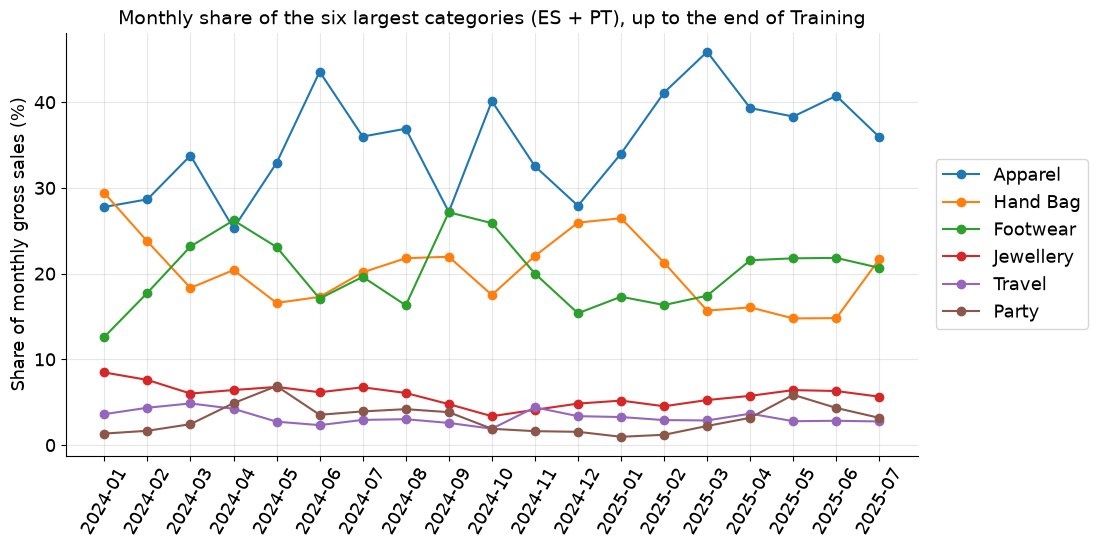

Guardado: evidence_dl_vendas/DLV51_fig.png


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Usa daily, MARKETS, fmt(), pct(), save_table(), save_fig(), lake, con, scope_facts (célula 1) e TRAIN_END (ponto 2).
# Se reiniciaste o kernel, volta a correr a célula 1 e a do ponto 2.
for nome in ['daily', 'MARKETS', 'fmt', 'pct', 'save_table', 'save_fig', 'lake', 'con', 'TRAIN_END']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Volta a correr a célula 1 e a do ponto 2 e depois esta.")

# ---------- gross sales por categoria de produto, mercado e dia (só até ao fim do Training) ----------
# Mesma definição do alvo da célula 1: linhas SALE e CANCELLED (valor com desconto, sem IVA) das encomendas com pelo menos uma linha SALE, no dia da encomenda.
# A categoria vem de slv_product (cat_des_en), ligada por prod_sfk = prod_spk. Os dados depois do fim do Training não são lidos.
SILVER_DET = f"'{lake.uri('silver', 'slv_order_det')}.parquet'"
SILVER_PROD = f"'{lake.uri('silver', 'slv_product')}.parquet'"
cut = pd.Timestamp(TRAIN_END)
con.execute(f"""
CREATE OR REPLACE TEMP TABLE cat_daily AS
SELECT f.mark, f.order_d AS day, COALESCE(p.cat_des_en, 'No category') AS cat,
       sum(d.amount_fixed_rate_w_disc_wo_vat) AS gross_sales, count(*) AS lines
FROM scope_facts f
JOIN read_parquet({SILVER_DET}) d ON d.order_id = f.order_id
LEFT JOIN read_parquet({SILVER_PROD}) p ON d.prod_sfk = p.prod_spk
WHERE f.sale_lines > 0 AND d.type IN ('SALE', 'CANCELLED') AND f.order_d <= DATE '{cut.date()}'
GROUP BY 1, 2, 3
""")
cd = con.sql("SELECT * FROM cat_daily").df()
cd['day'] = pd.to_datetime(cd['day']); cd['year'] = cd['day'].dt.year; cd['month'] = cd['day'].dt.month
assert cd['day'].max() <= cut, 'fuga de informação: dados do Test no estudo'
cats = cd.groupby('cat')['gross_sales'].sum().sort_values(ascending=False).index.tolist()
print('Categorias encontradas:', len(cats), '| linhas (mercado, dia, categoria):', fmt(len(cd)))

# ---------- controlo 1: a soma das categorias é igual ao gross sales do dia (a mesma tabela diária da célula 1) ----------
soma = cd.groupby(['mark', 'day'])['gross_sales'].sum().rename('cat_sum')
ref = daily[daily['day'] <= cut].set_index(['mark', 'day'])['gross_sales']
cmp_ = pd.concat([ref, soma], axis=1).fillna(0)
dif = (cmp_['gross_sales'] - cmp_['cat_sum']).abs()
print('\nControlo 1: a soma das categorias bate com o gross sales diário | dias comparados:', fmt(len(cmp_)), '| maior diferença num dia (EUR):', f"{dif.max():.4f}".replace('.', ','),
      '| dias com diferença acima de 1 cêntimo:', int((dif > 0.01).sum()), '| bate:', bool((dif < 0.01).all()))
sem_cat = cd.loc[cd['cat'] == 'No category', 'gross_sales'].sum() / cd['gross_sales'].sum()
print('Gross sales sem categoria (produto não encontrado):', pct(sem_cat))

# ---------- DLV49: peso de cada categoria, janeiro a julho de 2024 contra janeiro a julho de 2025 (ES + PT) ----------
jj = cd[cd['month'] <= 7]
n_pares = {y: len(MARKETS) * ((pd.Timestamp(f'{y}-07-31') - pd.Timestamp(f'{y}-01-01')).days + 1) for y in (2024, 2025)}     # mercado × dia
s24 = jj[jj['year'] == 2024].groupby('cat')['gross_sales'].sum(); s25 = jj[jj['year'] == 2025].groupby('cat')['gross_sales'].sum()
sh24, sh25 = (s24 / s24.sum()).reindex(cats).fillna(0), (s25 / s25.sum()).reindex(cats).fillna(0)
dias25 = jj[(jj['year'] == 2025) & (jj['gross_sales'] > 0)].drop_duplicates(['cat', 'mark', 'day']).groupby('cat').size().reindex(cats).fillna(0)     # mercado-dias com vendas
rows = []
for c in cats:
    rows.append({'Category': c, 'Share Jan-Jul 2024': pct(sh24[c]), 'Share Jan-Jul 2025': pct(sh25[c]),
                 'Change (percentage points)': f"{100 * (sh25[c] - sh24[c]):+.1f}".replace('.', ','),
                 'Market-days with sales, 2025': pct(dias25[c] / n_pares[2025]),
                 'Mean per market-day, 2025 (EUR)': fmt(s25.get(c, 0) / n_pares[2025]), 'Cumulative share 2025': ''})
dlv49 = pd.DataFrame(rows)
dlv49['Cumulative share 2025'] = [pct(x) for x in sh25.cumsum().values]
print('\n--- DLV49: peso de cada categoria no gross sales (ES + PT), janeiro a julho de 2024 e de 2025; ordenadas pelo total até ao fim do Training ---')
display(dlv49)
save_table(dlv49, 'DLV49', 'Share of each product category in gross sales, Jan-Jul 2024 and 2025 (ES + PT)', 'Training')

# ---------- DLV50: concentração e dispersão (o que isto significa para um modelo por categoria) ----------
cum = sh25.sort_values(ascending=False).cumsum()
dlv50 = pd.DataFrame([
    {'Measure': 'Categories (total)', 'Value': len(cats)},
    {'Measure': 'Categories needed to reach 80% of gross sales (2025)', 'Value': int((cum < 0.80).sum() + 1)},
    {'Measure': 'Categories needed to reach 90% of gross sales (2025)', 'Value': int((cum < 0.90).sum() + 1)},
    {'Measure': 'Categories with less than 1% of gross sales (2025)', 'Value': int((sh25 < 0.01).sum())},
    {'Measure': 'Categories with sales on fewer than 90% of market-days (2025)', 'Value': int(((dias25 / n_pares[2025]) < 0.90).sum())},
    {'Measure': 'Share of gross sales without category', 'Value': pct(sem_cat)}])
dlv50['Value'] = dlv50['Value'].astype(str)
print('\n--- DLV50: concentração e dispersão das categorias ---')
display(dlv50)
save_table(dlv50, 'DLV50', 'Concentration and sparsity of the product categories (Training)', 'Training')

# ---------- DLV51_fig: peso mensal das 6 maiores categorias ----------
mes = cd.assign(ym=cd['day'].dt.to_period('M')).groupby(['ym', 'cat'])['gross_sales'].sum().unstack('cat').fillna(0)
mes_sh = mes.div(mes.sum(axis=1), axis=0)
top6 = [c for c in cats if c != 'No category'][:6]
fig, ax = plt.subplots(figsize=(11, 5.5))
for c in top6:
    ax.plot(mes_sh.index.astype(str), 100 * mes_sh[c], marker='o', label=c)
ax.set_ylabel('Share of monthly gross sales (%)', fontsize=13); ax.set_title('Monthly share of the six largest categories (ES + PT), up to the end of Training', fontsize=14)
ax.tick_params(axis='x', rotation=60, labelsize=13); ax.tick_params(axis='y', labelsize=13); ax.legend(fontsize=13, loc='center left', bbox_to_anchor=(1.01, 0.5)); ax.grid(alpha=.3)
plt.show()
save_fig(fig, 'DLV51_fig', 'Monthly share of the six largest product categories in gross sales (ES + PT), up to the end of Training', 'ES, PT')

# Eficiência: uma passagem pelas linhas de venda das encomendas do âmbito, O(n) com n ≈ milhões de linhas, mais a junção pela chave única prod_spk, O(n + p). Espaço O(mercados·dias·categorias).

### 18a. Conclusions

**Confirmed**
- The sum of the categories gives exactly the daily `gross_sales` and nothing is left without a category. The forecast by category can be added up to the total without losses.
- There are 19 categories in ES and PT up to the end of Training. Four (Apparel, Hand Bag, Footwear, Jewellery) make up about 83% of sales, and seven reach about 91%.
- Nine categories weigh less than 1% each. Two (Winter Textiles and Waterproof) do not sell every day: they are seasonal and intermittent.
- The weight of the categories changed from 2024 to 2025: Apparel went up about 5 points and Hand Bag and Jewellery went down.

**Derived**
- The chart shows that the weight of each category varies with the season (for example, Footwear goes up in autumn 2024 and Hand Bag in winter). For August to December, which are the Test months, we only have autumn 2024 as a reference: a single year.
- Very small categories have few euros per day and a lot of irregularity. Giving them their own model adds noise and little weight to the total.

**Decision (proposal, to be confirmed)**
- The 7 categories with at least 2% of gross sales in 2025 stay as categories of their own (Apparel, Hand Bag, Footwear, Jewellery, Travel, Party and Wallet). The other 12 are grouped into "Others", about 8% of the total.
- The rule uses only the January to July 2025 share, that is, only Training data.

## 18b. Applying the ML category grouping to our data

**What we will do:** apply the grouping from the ML gold document (5 macro-groups, section 2) to the categories of gross sales (ES and PT, Training only) and check whether it fits our data.

**Goal:** decide whether we use these 5 groups in the model by category. Checks: none of our categories left outside the mapping (or, if there is one, it goes into a separate group), and the sum of the groups equal to the daily total.

In [23]:
import pandas as pd, numpy as np

# Agrupamento do ML (gold_ml_sales_profiling, secção 2), fixado antes de ver resultados
MAP_ML = {
    'JEWELLERY_AND_WATCHES': ['Stainless Steel', 'Watches', 'Jewellery', 'Silver'],
    'BAGS_AND_SMALL_GOODS':  ['Wallet', 'Belts', 'Fragrances', 'Hand Bag'],
    'SUMMER_AND_TRAVEL':     ['Waterproof', 'Travel', 'Sunglasses'],
    'WINTER_AND_APPAREL':    ['Scarves', 'Hats', 'Apparel', 'Footwear', 'Winter Textiles'],
    'PARTY_AND_LIFESTYLE':   ['Night', 'Home', 'Hair Accessories', 'Party'],
}
cat2grp = {c.lower(): g for g, cs in MAP_ML.items() for c in cs}   # chave em minúsculas

d = cd.copy()                                                       # cd = tabela diária por categoria (só Training)
d['grupo'] = d['cat'].astype(str).str.strip().str.lower().map(cat2grp).fillna('NAO_MAPEADA')
d['ano'] = pd.to_datetime(d['day']).dt.year

# 1) Controlo: categorias da nossa tabela vs. as 20 do ML
print('Categorias do ML que não existem nos nossos dados:',
      sorted(set(cat2grp) - set(d['cat'].astype(str).str.strip().str.lower())))
print('Categorias nossas fora do mapeamento do ML:',
      sorted(d.loc[d['grupo'] == 'NAO_MAPEADA', 'cat'].unique()))

# 2) Categoria -> grupo, com quota das vendas brutas por ano
tot = d.groupby('ano')['gross_sales'].sum()
t1 = d.pivot_table(index=['grupo', 'cat'], columns='ano', values='gross_sales', aggfunc='sum', fill_value=0)
for a in t1.columns: t1[f'quota_{a} (%)'] = (100 * t1[a] / tot[a]).round(1)
display(t1[[c for c in t1.columns if str(c).startswith('quota')]].sort_values(t1.columns[-1], ascending=False))

# 3) Por grupo: quota, dias de mercado com venda em 2025 e controlo da soma
g = d.groupby(['grupo', 'ano'])['gross_sales'].sum().unstack(fill_value=0)
t2 = (100 * g / tot).round(1).add_prefix('quota_').add_suffix(' (%)')
dias = d[(d['ano'] == 2025) & (d['gross_sales'] > 0)].groupby('grupo')[['mark', 'day']].apply(lambda x: len(x.drop_duplicates()))
t2['market_days_2025'] = dias
display(t2)
print('Soma dos grupos == total diário (diferença em €):', round(g.sum().sum() - d['gross_sales'].sum(), 6))
# Eficiência: O(n) tempo (n linhas de cd), O(c) espaço (c categorias).

Categorias do ML que não existem nos nossos dados: ['home']
Categorias nossas fora do mapeamento do ML: []


ano                                     quota_2024 (%)  quota_2025 (%)
grupo                 cat                                             
WINTER_AND_APPAREL    Apparel                     33.0            38.7
                      Footwear                    19.9            19.5
BAGS_AND_SMALL_GOODS  Hand Bag                    21.6            19.4
JEWELLERY_AND_WATCHES Jewellery                    5.6             5.6
SUMMER_AND_TRAVEL     Travel                       3.3             3.0
PARTY_AND_LIFESTYLE   Party                        2.9             2.9
BAGS_AND_SMALL_GOODS  Wallet                       2.9             2.4
PARTY_AND_LIFESTYLE   Night                        1.8             1.5
JEWELLERY_AND_WATCHES Stainless Steel              1.8             1.5
                      Watches                      2.1             1.4
                      Silver                       1.1             1.0
WINTER_AND_APPAREL    Scarves                      0.8             0.7
SUMMER_AND_TRAVEL     Sunglasses                   0.7             0.7
WINTER_AND_APPAREL    Winter Textiles              1.1             0.7
PARTY_AND_LIFESTYLE   Hair Accessories             0.5             0.4
WINTER_AND_APPAREL    Hats                         0.5             0.4
BAGS_AND_SMALL_GOODS  Belts                        0.2             0.1
                      Fragrances                   0.1             0.1
SUMMER_AND_TRAVEL     Waterproof                   0.1             0.1

ano,quota_2024 (%),quota_2025 (%),market_days_2025
grupo,,,
BAGS_AND_SMALL_GOODS,24.7,22.0,424
JEWELLERY_AND_WATCHES,10.7,9.4,424
PARTY_AND_LIFESTYLE,5.2,4.8,424
SUMMER_AND_TRAVEL,4.1,3.7,424
WINTER_AND_APPAREL,55.3,60.0,424


Soma dos grupos == total diário (diferença em €): -0.0


### 18b. Conclusions

**Confirmed (Training, ES + PT):**
- Our 19 categories all fit into the 5 ML macro-groups; none is left out. The ML `home` category has no sales in our data.
- The sum of the groups equals the daily total (difference 0,0 €). All 5 groups have sales on all 424 market-days of 2025.
- 2025 share: Winter and Apparel 60,0%, Bags and Small Goods 22,0%, Jewellery and Watches 9,4%, Party and Lifestyle 4,8%, Summer and Travel 3,7%.

**Derived:**
- Apparel (38,7%) and Footwear (19,5%) make up 58,2 of the 60,0 points of Winter and Apparel; the seasonal categories of the group (Scarves, Hats, Winter Textiles) are worth 1,8%.
- The 2024 vs 2025 comparison is not balanced (12 months against January–July), so the rise of Apparel from 33,0% to 38,7% may be partly seasonal.

**Decision:**
- Base: the 5 ML macro-groups, fixed before seeing results, to keep comparability with the ML model.
- Variant (sensitivity): Winter and Apparel is split into Apparel, Footwear and "Other winter" (Scarves, Hats, Winter Textiles), giving 7 groups. The other 4 ML groups stay.
- The variant measures whether the big group hides anything and **does not replace the base**, whatever the result. We only report it as a finding if it has a lower average WAPE and wins in at least 4 of the 5 seeds, the same entry rule we used for the variables.
- Both versions use the same 4 metrics (WAPE, Bias, RMSE, R²) and are compared with the direct forecast of the total.
- The 60% weight of a single group is recorded as a limitation.

## 19. Forecast by product category

**What we will do:** test whether forecasting by category group and adding up gives a better forecast of the total than forecasting the total directly. One model per market, with the category group as input (one 0/1 column per group), in scenarios A and C. The month's forecast is the sum of the groups.

**Rules fixed before seeing results:**
- Base: the 5 ML macro-groups. Sensitivity variant: 7 groups (Winter and Apparel split into Apparel, Footwear and other winter); it does not replace the base.
- Each scenario uses the variables and the configuration of its direct model (A: `mse_32x16_e100`, C: `huber_32_e100`), with no new grid. In A, the 28-day level becomes that of the group itself. Last year is not included.
- The loss stays on the euro scale (a single normalisation per market), so a big group weighs more, as it does in the total.
- The model by category beats the direct one if the average WAPE is lower and it wins in at least 4 of the 5 seeds (pair by pair).
- Metrics: WAPE, Bias, RMSE and R², on the monthly ES + PT total of the 7 Training steps.

**Goal:** find out whether the category helps forecast the total, and in which groups the error is biggest. The direct model does not forecast groups, so the error by group only exists in the models by category.

In [24]:
import time
import numpy as np
import pandas as pd

# Usa cd, cat2grp (ponto 18b), feat, FEATURE_GROUPS, FEATURE_COLS, WIN_LEVEL (ponto 8), CLIP_COLS (ponto 10), fit_mlp, predict, cutoff_date, TRAIN_END, MARKETS (pontos 2 e 10),
# REF, STEPS, M3, MIN_WIN, real_tot (pontos 12 e 12b), BASE_C (ponto 14), GR, ESCOLHA, cfg_name, SEEDS (pontos 10 e 15), pct, fmt, save_table.
for nome in ['cd', 'cat2grp', 'feat', 'FEATURE_GROUPS', 'FEATURE_COLS', 'WIN_LEVEL', 'CLIP_COLS', 'fit_mlp', 'predict', 'cutoff_date', 'TRAIN_END', 'MARKETS', 'REF', 'STEPS', 'M3',
             'MIN_WIN', 'real_tot', 'BASE_C', 'GR', 'ESCOLHA', 'cfg_name', 'SEEDS', 'pct', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos anteriores (incluindo 18 e 18b) e depois esta célula.")
CUT = pd.Timestamp(TRAIN_END)

def tot(res, m):                              # previsão do mês m, ES + PT somados (a mesma função do ponto 12; o nome tot foi reutilizado na célula 18b, por isso repõe-se aqui)
    return sum(res[(m, mk)] for mk in MARKETS)

# ---------- regras fixadas antes de ver resultados ----------
# 1) Um modelo por mercado, com o grupo de categoria como entrada (uma coluna 0/1 por grupo). Uma linha por (mercado, dia, grupo); o alvo é o gross sales do grupo nesse dia (EUR).
#    A previsão do mês é a soma dos grupos. A função de perda fica na escala do euro (normalização única por mercado): o erro de um grupo grande pesa mais, como pesa no total.
# 2) Cada cenário usa as variáveis da sua base (A: REF; C: BASE_C) e a configuração que o modelo direto desse cenário já fechou. Não há grelha nova.
#    O nível de 28 dias (só no A) passa a ser o nível do próprio grupo no corte. Não entra ano anterior.
# 3) Base: os 5 grupos do ML (cat5). Variante de sensibilidade: 7 grupos (cat7), com Winter and Apparel dividido em Apparel, Footwear e outros de inverno. Não substitui a base.
# 4) Regra de comparação com o modelo direto do mesmo cenário (WAPE dos 7 passos, ES + PT somados por mês): o modelo por categoria "ganha" se o WAPE médio das sementes for menor
#    E ganhar ao direto em pelo menos (n-1) das n sementes (par a par).
MAP7 = {c: ('APPAREL' if c == 'apparel' else 'FOOTWEAR' if c == 'footwear' else 'WINTER_OTHER') if g == 'WINTER_AND_APPAREL' else g for c, g in cat2grp.items()}
MAPAS = {'cat5': cat2grp, 'cat7': MAP7}
CFG_ESC = {'A': ESCOLHA['A'], 'C': ESCOLHA['C']}
BASES = {'A': REF, 'C': BASE_C}
KEEP = ['mark', 'day', 'month', 'cutoff'] + [c for c in FEATURE_COLS if c != 'level_28d']

def tabela_cat(mapa, src):
    """Uma linha por (mercado, dia, grupo). y = gross sales do grupo (0 se não houve venda; vazio depois do fim do Training). level_28d = nível de 28 dias do grupo no corte da linha."""
    s = src.copy()
    s['grp'] = s['cat'].astype(str).str.strip().str.lower().map(mapa)
    if s['grp'].isna().any():
        raise ValueError('Categorias sem grupo: ' + ', '.join(sorted(s.loc[s['grp'].isna(), 'cat'].unique())))
    grupos = sorted(set(mapa.values()))
    y = s.groupby(['mark', 'day', 'grp'])['gross_sales'].sum()
    idx = pd.MultiIndex.from_product([MARKETS, pd.DatetimeIndex(sorted(feat['day'].unique())), grupos], names=['mark', 'day', 'grp'])
    t = y.reindex(idx).rename('y').reset_index()
    ate = t['day'] <= CUT
    t.loc[ate, 'y'] = t.loc[ate, 'y'].fillna(0.0)                         # sem venda do grupo num dia do Training = 0
    t = t.merge(feat[KEEP], on=['mark', 'day'], how='left').sort_values(['mark', 'grp', 'day']).reset_index(drop=True)
    r28 = t.groupby(['mark', 'grp'])['y'].transform(lambda x: x.rolling(WIN_LEVEL, min_periods=WIN_LEVEL).mean())
    look = pd.Series(r28.to_numpy(), index=pd.MultiIndex.from_arrays([t['mark'], t['grp'], t['day']]))
    t['level_28d'] = look.reindex(pd.MultiIndex.from_arrays([t['mark'], t['grp'], t['cutoff']])).to_numpy()
    gcols = []
    for g in grupos:
        t['g_' + g] = (t['grp'] == g).astype(int); gcols.append('g_' + g)
    return t, grupos, gcols

def forecast_step_cat(m, groups, cfg, seed, t, gcols):
    tr_all, tg_all = t[t['month'] <= m - 2], t[t['month'] == m]
    assert tr_all['day'].max() <= cutoff_date(m), 'fuga de informação: linhas de treino depois do corte'
    assert tr_all['y'].notna().all(), 'linhas de treino sem valor'
    cols = [c for g in groups for c in FEATURE_GROUPS[g]] + gcols
    out = []
    for mk in MARKETS:
        tr, tg = tr_all[tr_all['mark'] == mk], tg_all[tg_all['mark'] == mk].copy()
        for c in [c for c in cols if c in CLIP_COLS]:                       # corte ao intervalo visto no treino (o nível, por grupo)
            if c == 'level_28d':
                tg[c] = tg[c].clip(tg['grp'].map(tr.groupby('grp')[c].min()), tg['grp'].map(tr.groupby('grp')[c].max()))
            else:
                tg[c] = tg[c].clip(tr[c].min(), tr[c].max())
        fill = tr.groupby('grp')['level_28d'].mean()
        def X_(df):
            X = df[cols].copy()
            if 'level_28d' in cols:                                         # sem histórico: média do treino do grupo + marca 0/1
                marca = X['level_28d'].isna().to_numpy(float)
                X['level_28d'] = X['level_28d'].fillna(df['grp'].map(fill))
                return np.column_stack([X.to_numpy(float), marca])
            return X.to_numpy(float)
        Xtr, Xtg = X_(tr), X_(tg)
        mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1.0
        ytr = tr['y'].to_numpy(float); ymu, ysd = ytr.mean(), ytr.std()
        net = fit_mlp((Xtr - mu) / sd, (ytr - ymu) / ysd, cfg, seed)
        pred = np.maximum(predict(net, (Xtg - mu) / sd) * ysd + ymu, 0.0)   # vendas não negativas
        out.append(pd.DataFrame({'mark': tg['mark'].to_numpy(), 'day': tg['day'].to_numpy(), 'grp': tg['grp'].to_numpy(), 'forecast': pred}))
    return pd.concat(out, ignore_index=True)

GCAT = globals().get('GCAT', {})              # GCAT[chave][semente][(mês, mercado, grupo)] = previsão mensal do grupo

def treinar_cat(chave, groups, cfg, t, gcols):
    if chave in GR:
        return
    t0 = time.time(); tot_s, grp_s = {}, {}
    for s in SEEDS:
        fc, fg = {}, {}
        for m in STEPS:
            f = forecast_step_cat(m, groups, cfg, s, t, gcols)
            g = f.groupby(['mark', 'grp'])['forecast'].sum()
            for (mk, gr), v in g.items():
                fg[(m, mk, gr)] = float(v); fc[(m, mk)] = fc.get((m, mk), 0.0) + float(v)
        tot_s[s], grp_s[s] = fc, fg
    GR[chave] = tot_s; GCAT[chave] = grp_s
    print(f"  {chave[0]} | {chave[1]}: {time.time() - t0:.0f} s", flush=True)

def quatro(res, months):
    a = np.array([real_tot[m] for m in months]); f_ = np.array([tot(res, m) for m in months]); e = f_ - a
    return {'WAPE': np.abs(e).sum() / a.sum(), 'Bias': e.sum() / a.sum(), 'RMSE': np.sqrt((e ** 2).mean()), 'R2': 1 - (e ** 2).sum() / ((a - a.mean()) ** 2).sum()}

TAB = {k: tabela_cat(mp, cd) for k, mp in MAPAS.items()}      # (tabela, grupos, colunas 0/1)

# ---------- controlos antes de treinar ----------
print('--- Controlos da tabela por categoria ---')
for k, (t, grupos, gcols) in TAB.items():
    s = t[t['day'] <= CUT].groupby(['mark', 'day'])['y'].sum()
    r = feat[feat['day'] <= CUT].set_index(['mark', 'day'])['y']
    print(f"Controlo 1 ({k}, {len(grupos)} grupos): a soma dos grupos bate com o gross sales diário em {fmt(len(r))} mercado-dias:", bool(np.allclose(s.reindex(r.index).to_numpy(), r.to_numpy(), atol=0.01)),
          '| linhas:', fmt(len(t)))
t5 = TAB['cat5'][0]
LIM = pd.Timestamp('2025-03-31')                                # alterar vendas depois de 31/03/2025 não pode mexer no nível das linhas com corte até essa data
cd_alt = cd.copy(); cd_alt.loc[cd_alt['day'] > LIM, 'gross_sales'] = cd_alt.loc[cd_alt['day'] > LIM, 'gross_sales'] * 3 + 500
t5_alt = tabela_cat(cat2grp, cd_alt)[0]
antes = (t5['cutoff'] <= LIM).to_numpy()
print('Controlo 2: o nível por grupo das linhas com corte até 31/03/2025 não muda se alterarmos as vendas depois dessa data:',
      bool(np.array_equal(t5.loc[antes, 'level_28d'].to_numpy(), t5_alt.loc[antes, 'level_28d'].to_numpy(), equal_nan=True)),
      '| muda nas linhas com corte posterior (prova do teste):', bool((t5.loc[~antes, 'level_28d'].to_numpy() != t5_alt.loc[~antes, 'level_28d'].to_numpy()).any()))
M_T = STEPS[-1]; gA = BASES['A']
a_ = forecast_step_cat(M_T, gA, CFG_ESC['A'], 0, t5, TAB['cat5'][2]); b_ = forecast_step_cat(M_T, gA, CFG_ESC['A'], 0, t5, TAB['cat5'][2])
print('Controlo 3: mesma semente, mesma previsão (diferença máxima, esperado 0):', float(np.abs(a_['forecast'] - b_['forecast']).max()))

# ---------- treinar: 2 cenários × 2 agrupamentos × 5 sementes × 7 passos × 2 mercados ----------
CHAVES = {}
for cen in ['A', 'C']:
    for k in ['cat5', 'cat7']:
        t, grupos, gcols = TAB[k]
        CHAVES[(cen, k)] = (cen + ' ' + k, cfg_name(CFG_ESC[cen]))
        treinar_cat(CHAVES[(cen, k)], BASES[cen], CFG_ESC[cen], t, gcols)
DIRETO = {cen: (cen, cfg_name(CFG_ESC[cen])) for cen in ['A', 'C']}
for cen in ['A', 'C']:
    if DIRETO[cen] not in GR:
        raise RuntimeError(f'O modelo direto do cenário {cen} não está em GR: corre os pontos 15 e 16.')

# ---------- DLV52: comparação com o modelo direto ----------
rows = []
for cen in ['A', 'C']:
    wd = np.array([quatro(GR[DIRETO[cen]][s], STEPS)['WAPE'] for s in SEEDS])
    for nome, chave, k in [('Direct (total)', DIRETO[cen], None), ('By category, 5 ML groups', CHAVES[(cen, 'cat5')], 'cat5'), ('By category, 7 groups (sensitivity)', CHAVES[(cen, 'cat7')], 'cat7')]:
        por = [quatro(GR[chave][s], STEPS) for s in SEEDS]; w = np.array([x['WAPE'] for x in por])
        r = {'Scenario': cen, 'Model': nome, 'WAPE (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}",
             'WAPE May-Jul': pct(np.mean([quatro(GR[chave][s], M3)['WAPE'] for s in SEEDS])), 'Bias': pct(np.mean([x['Bias'] for x in por])),
             'RMSE (EUR)': fmt(np.mean([x['RMSE'] for x in por])), 'R2': f"{np.mean([x['R2'] for x in por]):.2f}".replace('.', ',')}
        if k is None:
            r.update({'Seeds better than direct': '-', 'Rule': '-'})
        else:
            ganha = int((w < wd).sum())
            veredito = 'beats direct' if (w.mean() < wd.mean() and ganha >= MIN_WIN) else 'does not beat direct'
            r.update({'Seeds better than direct': f'{ganha} of {len(SEEDS)}', 'Rule': veredito if k == 'cat5' else veredito + ' (sensitivity; does not replace the base)'})
        rows.append(r)
dlv52 = pd.DataFrame(rows)
print('\n--- DLV52: previsão por categoria contra a previsão direta do total (5 sementes; 7 passos do Training; ES + PT somados por mês) ---')
print(f'Regra fixada antes: o modelo por categoria ganha se o WAPE médio for menor E ganhar ao direto em pelo menos {MIN_WIN} das {len(SEEDS)} sementes (par a par). Mesma configuração e variáveis do modelo direto de cada cenário. O R² usa só 7 meses.')
display(dlv52)
save_table(dlv52, 'DLV52', 'Forecast by product category (sum of groups) against the direct forecast of the total, scenarios A and C (5 seeds, 7 Training steps)', 'Training')

# ---------- DLV53: erro mês a mês ----------
rows = []
for m in STEPS:
    a = real_tot[m]; r = {'Month': m.strftime('%b %Y'), 'Actual (EUR)': fmt(a)}
    for cen in ['A', 'C']:
        for nome, chave in [('direct', DIRETO[cen]), ('5 groups', CHAVES[(cen, 'cat5')]), ('7 groups', CHAVES[(cen, 'cat7')])]:
            r[f'{cen}: {nome}'] = pct((np.mean([tot(GR[chave][s], m) for s in SEEDS]) - a) / a)
    rows.append(r)
dlv53 = pd.DataFrame(rows)
print('\n--- DLV53: erro mês a mês do total (% do real; média das 5 sementes) ---')
display(dlv53)
save_table(dlv53, 'DLV53', 'Monthly error of the total: direct and by category, scenarios A and C (5 seeds)', 'Training')

# ---------- DLV54: erro por grupo (só os modelos por categoria; o direto não prevê grupos) ----------
rows = []
for cen in ['A', 'C']:
    for k in ['cat5', 'cat7']:
        t, grupos, gcols = TAB[k]; chave = CHAVES[(cen, k)]
        for g in grupos:
            a = np.array([t[(t['grp'] == g) & (t['month'] == m)]['y'].sum() for m in STEPS])                          # real do grupo, ES + PT
            f_ = np.array([np.mean([sum(GCAT[chave][s][(m, mk, g)] for mk in MARKETS) for s in SEEDS]) for m in STEPS])  # previsão média das sementes
            rows.append({'Scenario': cen, 'Grouping': k, 'Group': g, 'Share of Training gross sales (Jan-Jul 2025)': pct(a.sum() / sum(real_tot[m] for m in STEPS)),
                         'WAPE (7 months)': pct(np.abs(f_ - a).sum() / a.sum()) if a.sum() > 0 else '-', 'Bias': pct((f_ - a).sum() / a.sum()) if a.sum() > 0 else '-'})
dlv54 = pd.DataFrame(rows)
print('\n--- DLV54: erro de cada grupo (mês × grupo, ES + PT somados; média das 5 sementes) ---')
display(dlv54)
save_table(dlv54, 'DLV54', 'Error of each category group in the category models, scenarios A and C', 'Training')

print('\nControlo 4: a previsão do total é a soma dos grupos (diferença máxima, EUR):',
      max(abs(GR[ch][SEEDS[0]][(m, mk)] - sum(GCAT[ch][SEEDS[0]][(m, mk, g)] for g in TAB[k][1])) for (cen, k), ch in CHAVES.items() for m in STEPS for mk in MARKETS))
# Eficiência: 4 treinos de 5 sementes × 7 passos × 2 mercados = 280 redes cada; cada rede custa O(E·n·P) com n ≈ (nº de grupos) × linhas do modelo direto (≈ 5× ou 7×). Espaço O(n·d) por rede.

--- Controlos da tabela por categoria ---
Controlo 1 (cat5, 5 grupos): a soma dos grupos bate com o gross sales diário em 1.156 mercado-dias: True | linhas: 7.310
Controlo 1 (cat7, 7 grupos): a soma dos grupos bate com o gross sales diário em 1.156 mercado-dias: True | linhas: 10.234
Controlo 2: o nível por grupo das linhas com corte até 31/03/2025 não muda se alterarmos as vendas depois dessa data: True | muda nas linhas com corte posterior (prova do teste): True
Controlo 3: mesma semente, mesma previsão (diferença máxima, esperado 0): 0.0
  A cat5 | mse_32x16_e100: 142 s
  A cat7 | mse_32x16_e100: 199 s
  C cat5 | huber_32_e100: 109 s
  C cat7 | huber_32_e100: 151 s

--- DLV52: previsão por categoria contra a previsão direta do total (5 sementes; 7 passos do Training; ES + PT somados por mês) ---
Regra fixada antes: o modelo por categoria ganha se o WAPE médio for menor E ganhar ao direto em pelo menos 4 das 5 sementes (par a par). Mesma configuração e variáveis do modelo direto de c

,Scenario,Model,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,RMSE (EUR),R2,Seeds better than direct,Rule
0,A,Direct (total),"31,3%","28,9% to 35,9%","28,9%","-29,2%",957.074,"-1,41",-,-
1,A,"By category, 5 ML groups","30,8%","28,0% to 35,1%","26,9%","-24,1%",842.455,"-0,87",3 of 5,does not beat direct
2,A,"By category, 7 groups (sensitivity)","32,2%","27,4% to 36,3%","28,9%","-27,3%",868.914,"-1,01",1 of 5,does not beat direct (sensitivity; does not re...
3,C,Direct (total),"5,0%","4,1% to 5,7%","5,3%","-0,2%",146.627,"0,94",-,-
4,C,"By category, 5 ML groups","6,2%","5,1% to 8,9%","6,8%","-0,2%",179.693,"0,91",1 of 5,does not beat direct
5,C,"By category, 7 groups (sensitivity)","5,2%","4,1% to 6,0%","5,4%","0,2%",161.909,"0,93",2 of 5,does not beat direct (sensitivity; does not re...


Guardado: evidence_dl_vendas/DLV52.csv

--- DLV53: erro mês a mês do total (% do real; média das 5 sementes) ---


,Month,Actual (EUR),A: direct,A: 5 groups,A: 7 groups,C: direct,C: 5 groups,C: 7 groups
0,Jan 2025,3.406.708,"-56,8%","-39,6%","-37,4%","3,2%","0,9%","6,4%"
1,Feb 2025,2.306.076,"4,7%","22,9%","15,7%","4,1%","4,5%","2,4%"
2,Mar 2025,1.797.919,"-29,5%","-33,3%","-44,4%","3,8%","6,5%","5,4%"
3,Apr 2025,1.765.770,"-21,7%","-33,2%","-39,6%","6,3%","8,0%","4,5%"
4,May 2025,2.130.641,"-23,2%","-14,0%","-16,7%","0,3%","2,8%","-1,5%"
5,Jun 2025,2.905.877,"-30,9%","-30,0%","-31,3%","-7,5%","-7,0%","-5,6%"
6,Jul 2025,3.184.336,"-30,8%","-32,8%","-34,8%","-6,4%","-9,0%","-7,0%"


Guardado: evidence_dl_vendas/DLV53.csv

--- DLV54: erro de cada grupo (mês × grupo, ES + PT somados; média das 5 sementes) ---


,Scenario,Grouping,Group,Share of Training gross sales (Jan-Jul 2025),WAPE (7 months),Bias
0,A,cat5,BAGS_AND_SMALL_GOODS,"22,0%","35,8%","-18,2%"
1,A,cat5,JEWELLERY_AND_WATCHES,"9,4%","25,7%","-7,1%"
2,A,cat5,PARTY_AND_LIFESTYLE,"4,8%","26,5%","-10,1%"
3,A,cat5,SUMMER_AND_TRAVEL,"3,7%","26,8%","-8,4%"
4,A,cat5,WINTER_AND_APPAREL,"60,0%","31,0%","-31,0%"
5,A,cat7,APPAREL,"38,7%","36,1%","-36,1%"
6,A,cat7,BAGS_AND_SMALL_GOODS,"22,0%","36,5%","-22,8%"
7,A,cat7,FOOTWEAR,"19,5%","30,9%","-30,0%"
8,A,cat7,JEWELLERY_AND_WATCHES,"9,4%","29,7%","-8,3%"
9,A,cat7,PARTY_AND_LIFESTYLE,"4,8%","21,6%","-15,4%"


Guardado: evidence_dl_vendas/DLV54.csv

Controlo 4: a previsão do total é a soma dos grupos (diferença máxima, EUR): 4.656612873077393e-10


### 19a. Conclusions

**Confirmed (Training, 7 steps, 5 seeds, ES + PT added by month):**
- Checks: the sum of the groups matches daily gross sales (1.156 market-days), the level by group does not use data after the cutoff, the same seed gives the same forecast and the total is the sum of the groups.
- Scenario A: direct 31,3% WAPE, 5 groups 30,8% (better in 3 of 5 seeds), 7 groups 32,2% (1 of 5). None meets the rule (lower average WAPE and at least 4 of 5 seeds).
- Scenario C: direct 5,0%, 5 groups 6,2% (1 of 5), 7 groups 5,2% (2 of 5). None meets the rule.
- In A, all groups are underestimated (bias from −7,1% to −31,0% with 5 groups; Apparel −36,1% with 7). In C, Winter and Apparel (60% of sales) has a WAPE of 8,6%; the other 4 groups between 16,0% and 45,9%.

**Derived:**
- The 0,5-point difference in A is smaller than the spread between seeds (about 7 points), so it cannot be told apart from noise.
- The problem in A is the level, and the category does not correct it. In C, splitting into groups adds noise and the errors of the groups partly cancel out in the total.
- The forecast by group is only reasonable for the dominant group and only in C; for splitting products by category it is not very reliable.
- The base and the configuration were chosen for the direct model on these same 7 months, which slightly favours it.

**Decision:**
- The forecast by category does not go in: the direct model stays as the base in both scenarios.
- The groups stay as a diagnostic (where the error is), not as the final forecast. The 7-group variant replaces nothing.
- It stays in the report as a negative result.

## 20. TFT trained from scratch (scenario A)

**What we will do:** test whether the Temporal Fusion Transformer (Lim et al., 2021), as implemented in the NeuralForecast package, forecasts monthly gross sales better than the scenario A MLP. It is trained from scratch on our data at each step, with the same cutoff (data up to the end of M-2) and the same monthly refit.

**Rules fixed before seeing results** (the same ones we used for the orders TFT):
- Scenario A only (no paid spend), with the variables of base A.
- A single model for both markets in each step (one series per market, with an "is Online PT" column). MSE loss, 16 hidden units, 2 attention heads, dropout 0,1, learning rate 1e-3, 5 seeds, no validation.
- The TFT also sees the gross sales of the last 28 days before the cutoff; the MLP only sees the average of those 28 days. The comparison is therefore about architecture and about information.
- Minimal grid: 300 or 600 training steps. The one with the lowest average WAPE stays; if the intervals between seeds overlap, the simpler one (300) stays.
- It replaces the scenario A MLP only if the average WAPE across the 7 steps goes down and it is better in at least 4 of the 5 seeds (pair by pair).
- Metrics: WAPE, Bias, RMSE and R².

**Goal:** find out whether a sequence model, which sees the recent history, solves the underestimation of scenario A. The TFT already beat the MLP in the orders scenario A, and we want to see whether that repeats with gross sales.

In [27]:
import os, pickle, time, warnings, logging
import numpy as np
import pandas as pd
import torch

try:
    from neuralforecast import NeuralForecast
    from neuralforecast.models import TFT
    from neuralforecast.losses.pytorch import MSE
except ImportError:
    raise RuntimeError("Falta o pacote neuralforecast. Instala-o numa célula à parte (%pip install -q neuralforecast); se o import continuar a falhar, reinicia o kernel e recupera o estado.")

# Usa feat, FEATURE_GROUPS, CLIP_COLS, SEM_HISTORICO (pontos 8, 10 e 11), cutoff_date, MARKETS, SEEDS, cfg_name (célula 1 e ponto 10), REF, STEPS, M3, MIN_WIN, real_tot (pontos 12 e 12b),
# GR, ESCOLHA (ponto 15), pct, fmt, save_table. O modelo de comparação é o MLP do cenário A (GR[('A', nome da configuração fechada)]).
JF = STEPS[:2]
for nome in ['feat', 'FEATURE_GROUPS', 'CLIP_COLS', 'cutoff_date', 'MARKETS', 'SEEDS', 'cfg_name', 'REF', 'STEPS', 'M3', 'MIN_WIN', 'real_tot', 'GR', 'ESCOLHA', 'pct', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos anteriores e depois esta célula.")
warnings.filterwarnings('ignore')
for nm in ['pytorch_lightning', 'lightning.pytorch', 'lightning_fabric']:
    logging.getLogger(nm).setLevel(logging.ERROR)
torch.set_num_threads(1)

# ---------- regras fixadas antes de ver resultados (as mesmas do TFT do notebook das encomendas) ----------
#  - só o cenário A (sem investimento pago); variáveis da base A (REF); alvo = gross sales diário (EUR);
#  - um só modelo para os dois mercados em cada passo (uma série por mercado, com a coluna "é Online PT"), treinado de raiz com os dados até ao fim de M-2;
#  - o TFT vê também o gross sales dos últimos 28 dias antes do corte (o MLP só vê a média desses 28 dias); a comparação é, por isso, de arquitetura e de informação;
#  - o alvo normaliza-se por mercado e as variáveis com as linhas de treino; o nível de 28 dias sem histórico (janeiro e fevereiro de 2024) fica com a média do treino mais uma marca 0/1, e o do futuro corta-se ao intervalo visto;
#  - perda MSE (a do MLP vencedor do A); 16 unidades escondidas, 2 cabeças de atenção, dropout 0,1, taxa de aprendizagem 1e-3, 32 janelas por passo; 5 sementes; sem validação nem paragem antecipada;
#  - grelha mínima: 300 ou 600 passos de treino; escolha pela regra de sempre (WAPE médio mais baixo; se os intervalos min-max dos dois se sobrepõem, a mais simples = 300);
#  - substitui o MLP do cenário A só se o WAPE médio dos 7 passos for mais baixo E melhor em pelo menos 4 das 5 sementes (par a par).
TFIXED = {'input_size': 28, 'hidden_size': 16, 'n_head': 2, 'dropout': 0.1, 'lr': 1e-3, 'windows_batch_size': 32}
TGRID = globals().get('TGRID', [{'steps': 300}, {'steps': 600}])
tname = lambda c: f"tft_h{TFIXED['hidden_size']}_s{c['steps']}"
GROUPS_A = REF
NOME_MLP = cfg_name(ESCOLHA['A'])
assert ('A', NOME_MLP) in GR, 'O MLP do cenário A não está em GR: corre o ponto 15.'
os.makedirs('evidence_dl_vendas', exist_ok=True)

def tot(res, m):                              # previsão do mês m, ES + PT somados
    return sum(res[(m, mk)] for mk in MARKETS)

def quatro(res, months):
    a = np.array([real_tot[m] for m in months]); f_ = np.array([tot(res, m) for m in months]); e = f_ - a
    return {'WAPE': np.abs(e).sum() / a.sum(), 'Bias': e.sum() / a.sum(), 'RMSE': np.sqrt((e ** 2).mean()), 'R2': 1 - (e ** 2).sum() / ((a - a.mean()) ** 2).sum()}

def forecast_step_tft(m, groups, cfg, seed, feat_df=None, shuffle_future=False):
    """Treina de raiz um TFT com as linhas até ao corte de M-2 e prevê, por mercado, os dias seguintes até ao fim de M. Devolve a previsão diária de todo o horizonte."""
    feat_df = feat if feat_df is None else feat_df
    m = pd.Period(m, 'M'); cut = cutoff_date(m); end = m.end_time.normalize()
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    tr_all, fu_all = feat_df[feat_df['day'] <= cut], feat_df[(feat_df['day'] > cut) & (feat_df['day'] <= end)]
    assert tr_all['day'].max() == cut and fu_all['day'].min() == cut + pd.Timedelta(days=1) and fu_all['day'].max() == end, 'datas fora do corte'
    h = (end - cut).days
    trs, fus, ystat = [], [], {}
    for mk in MARKETS:
        tr, fu = tr_all[tr_all['mark'] == mk].sort_values('day'), fu_all[fu_all['mark'] == mk].sort_values('day').copy()
        assert len(tr) == (cut - tr['day'].min()).days + 1 and len(fu) == h, 'há dias em falta'
        for c in [c for c in cols if c in CLIP_COLS]:                       # o futuro não sai do intervalo visto no treino
            fu[c] = fu[c].clip(tr[c].min(), tr[c].max())
        ystat[mk] = (float(tr['y'].mean()), float(tr['y'].std()))
        t = pd.DataFrame({'unique_id': mk, 'ds': tr['day'].to_numpy(), 'y': (tr['y'].to_numpy(float) - ystat[mk][0]) / ystat[mk][1]})
        f = pd.DataFrame({'unique_id': mk, 'ds': fu['day'].to_numpy()})
        for c in cols:
            t[c], f[c] = tr[c].to_numpy(float), fu[c].to_numpy(float)
        if 'level_28d' in cols:                                              # sem histórico: média do treino + marca 0/1
            t['level_na'], f['level_na'] = t['level_28d'].isna().to_numpy(float), fu['level_28d'].isna().to_numpy(float)
            fill = float(tr['level_28d'].mean()); t['level_28d'], f['level_28d'] = t['level_28d'].fillna(fill), f['level_28d'].fillna(fill)
        t['is_pt'], f['is_pt'] = float(mk == MARKETS[1]), float(mk == MARKETS[1])
        trs.append(t); fus.append(f)
    df, futr = pd.concat(trs, ignore_index=True), pd.concat(fus, ignore_index=True)
    xcols = [c for c in df.columns if c not in ('unique_id', 'ds', 'y')]
    mu, sd = df[xcols].mean(), df[xcols].std(); sd = sd.where(sd > 0, 1.0)
    df[xcols], futr[xcols] = (df[xcols] - mu) / sd, (futr[xcols] - mu) / sd
    if shuffle_future:                                                       # só para o controlo 3: embaralha as covariáveis do futuro
        futr[xcols] = futr[xcols].sample(frac=1.0, random_state=1).to_numpy()
    assert not df.isna().any().any() and not futr.isna().any().any(), 'há NaN nas entradas'
    model = TFT(h=h, input_size=TFIXED['input_size'], hidden_size=TFIXED['hidden_size'], n_head=TFIXED['n_head'], dropout=TFIXED['dropout'], futr_exog_list=xcols,
                loss=MSE(), max_steps=cfg['steps'], learning_rate=TFIXED['lr'], batch_size=len(MARKETS), windows_batch_size=TFIXED['windows_batch_size'],
                random_seed=seed, scaler_type=None, enable_progress_bar=False, enable_model_summary=False, accelerator='cpu', devices=1, logger=False, enable_checkpointing=False)
    nf = NeuralForecast(models=[model], freq='D')
    nf.fit(df=df, val_size=0)
    p = nf.predict(futr_df=futr)
    out = []
    for mk in MARKETS:
        q = p[p['unique_id'] == mk].sort_values('ds')
        assert len(q) == h and np.isfinite(q['TFT'].to_numpy()).all(), 'previsão com tamanho ou valores inválidos'
        out.append(pd.DataFrame({'mark': mk, 'day': q['ds'].to_numpy(), 'forecast': np.maximum(q['TFT'].to_numpy(float) * ystat[mk][1] + ystat[mk][0], 0.0)}))   # vendas não negativas
    return pd.concat(out, ignore_index=True)

def month_sum(fc, m):
    d = fc[fc['day'].dt.to_period('M') == pd.Period(m, 'M')]
    assert (d.groupby('mark').size() == pd.Period(m, 'M').days_in_month).all(), 'o mês previsto está incompleto'
    return d.groupby('mark')['forecast'].sum().to_dict()

# ---------- teste de fumo e controlos: julho de 2025, semente 0, primeira configuração ----------
M0, CFG0 = STEPS[-1], TGRID[0]
t0 = time.time(); b = forecast_step_tft(M0, GROUPS_A, CFG0, 0); t_fit = time.time() - t0
c = forecast_step_tft(M0, GROUPS_A, CFG0, 0)
print(f'Um treino ({tname(CFG0)}, {M0.strftime("%b %Y")}, 2 mercados) demorou {t_fit:.0f} s.')
print('Controlo 1, mesma semente dá a mesma previsão (diferença máxima, esperado 0):', float(np.abs(b['forecast'] - c['forecast']).max()))
alt = feat.copy(); alt.loc[alt['day'] > cutoff_date(M0), 'y'] = alt.loc[alt['day'] > cutoff_date(M0), 'y'] * 3 + 500
d_ = forecast_step_tft(M0, GROUPS_A, CFG0, 0, feat_df=alt)
print('Controlo 2, a previsão não depende do gross sales depois do corte (diferença máxima, esperado 0):', float(np.abs(b['forecast'] - d_['forecast']).max()))
e_ = forecast_step_tft(M0, GROUPS_A, CFG0, 0, shuffle_future=True)
print('Controlo 3, as covariáveis do futuro são usadas (a previsão muda se as embaralharmos):', bool(np.abs(b['forecast'] - e_['forecast']).max() > 1e-6))
n_cfg = len(TGRID); est = t_fit * len(SEEDS) * len(STEPS) * sum(c_['steps'] for c_ in TGRID) / CFG0['steps'] / 60
print(f'Estimativa grosseira da grelha ({n_cfg} configurações × {len(SEEDS)} sementes × {len(STEPS)} passos): cerca de {est:.0f} minutos; as estimativas anteriores falharam por um fator 2 a 3.')

# ---------- grelha ----------
# Guarda cada (semente, mês) em disco: se a célula for interrompida, ao voltar a correr continua onde ficou.
RES_T = {}
t_grid = time.time()
for cfg in TGRID:
    nome = tname(cfg); ficheiro = f'evidence_dl_vendas/tft_A_{nome}.pkl'
    feitos = pickle.load(open(ficheiro, 'rb')) if os.path.exists(ficheiro) else {}
    res = {}
    for s in SEEDS:
        for m in STEPS:
            if (s, m) not in feitos:
                feitos[(s, m)] = {mk: float(v) for mk, v in month_sum(forecast_step_tft(m, GROUPS_A, cfg, s), m).items()}
                pickle.dump(feitos, open(ficheiro, 'wb'))
            print(m.strftime('%b'), end=' ', flush=True)
        res[s] = {(m, mk): feitos[(s, m)][mk] for m in STEPS for mk in MARKETS}
        print(f'| {nome} semente {s} feita | {(time.time() - t_grid) / 60:.1f} min', flush=True)
    RES_T[nome] = res; GR[('A TFT', nome)] = res

rows = []
for cfg in TGRID:
    nome = tname(cfg); res = RES_T[nome]
    por = [quatro(res[s], STEPS) for s in SEEDS]; w = np.array([x['WAPE'] for x in por])
    rows.append({'Configuration': nome, 'steps': cfg['steps'], 'wm': w.mean(), 'wmin': w.min(), 'wmax': w.max(), 'WAPE Jan-Feb': np.mean([quatro(res[s], JF)['WAPE'] for s in SEEDS]),
                 'WAPE May-Jul': np.mean([quatro(res[s], M3)['WAPE'] for s in SEEDS]), 'Bias': np.mean([x['Bias'] for x in por]), 'RMSE': np.mean([x['RMSE'] for x in por]), 'R2': np.mean([x['R2'] for x in por])})
d = pd.DataFrame(rows).sort_values('wm').reset_index(drop=True)
d.insert(0, 'Rank', d.index + 1)
sobrepoe = len(d) > 1 and max(d.loc[0, 'wmin'], d.loc[1, 'wmin']) <= min(d.loc[0, 'wmax'], d.loc[1, 'wmax'])
escolhida = (min(d.head(2).to_dict('records'), key=lambda r: r['steps']) if sobrepoe else d.iloc[0].to_dict())['Configuration']
show = pd.DataFrame({'Rank': d['Rank'], 'Configuration': d['Configuration'], 'WAPE (mean of seeds)': d['wm'].map(pct), 'WAPE (min to max)': [f"{pct(x)} to {pct(y)}" for x, y in zip(d['wmin'], d['wmax'])],
                     'WAPE Jan-Feb': d['WAPE Jan-Feb'].map(pct), 'WAPE May-Jul': d['WAPE May-Jul'].map(pct), 'Bias': d['Bias'].map(pct), 'RMSE (EUR)': d['RMSE'].map(fmt),
                     'R2': d['R2'].map(lambda x: f"{x:.2f}".replace('.', ','))})
print(f'\n--- DLV55: grelha do TFT, cenário A, treinada de raiz ({len(SEEDS)} sementes; 7 passos do Training; ES + PT somados por mês) ---')
display(show)
save_table(show, 'DLV55', 'TFT grid, scenario A, trained from scratch (2 configurations x 5 seeds, 7 Training steps)', 'Training')
print('Configuração escolhida pela regra fixada antes:', escolhida, '(os dois melhores têm intervalos sobrepostos: fica a mais simples)' if sobrepoe else '')

# ---------- DLV56: TFT escolhida contra o MLP do cenário A ----------
mlp, tft = GR[('A', NOME_MLP)], RES_T[escolhida]
wm_ = np.array([quatro(mlp[s], STEPS)['WAPE'] for s in SEEDS]); wt_ = np.array([quatro(tft[s], STEPS)['WAPE'] for s in SEEDS])
melhores = int((wt_ < wm_).sum())
regra = 'TFT replaces the MLP' if (wt_.mean() < wm_.mean() and melhores >= MIN_WIN) else 'TFT does not replace the MLP'
def linha(nome, r_list, extra):
    por = [quatro(r, STEPS) for r in r_list]; w = np.array([x['WAPE'] for x in por])
    return {'Model': nome, 'WAPE (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}", 'WAPE Jan-Feb': pct(np.mean([quatro(r, JF)['WAPE'] for r in r_list])),
            'WAPE May-Jul': pct(np.mean([quatro(r, M3)['WAPE'] for r in r_list])), 'Bias': pct(np.mean([x['Bias'] for x in por])), 'RMSE (EUR)': fmt(np.mean([x['RMSE'] for x in por])),
            'R2': f"{np.mean([x['R2'] for x in por]):.2f}".replace('.', ','), **extra}
dlv56 = pd.DataFrame([linha(f'MLP, scenario A ({NOME_MLP})', [mlp[s] for s in SEEDS], {'Seeds better than MLP': '-', 'Rule': '-'}),
                      linha(f'TFT ({escolhida})', [tft[s] for s in SEEDS], {'Seeds better than MLP': f'{melhores} of {len(SEEDS)}', 'Rule': regra})])
print(f'\n--- DLV56: TFT escolhida contra o MLP do cenário A (5 sementes; 7 passos do Training) ---')
print(f'Regra fixada antes: o TFT substitui o MLP só se o WAPE médio baixar E for melhor em pelo menos {MIN_WIN} das {len(SEEDS)} sementes (par a par). O R² usa só 7 meses.')
display(dlv56)
save_table(dlv56, 'DLV56', 'TFT chosen configuration against the MLP of scenario A (5 seeds, 7 Training steps)', 'Training')

# ---------- DLV57: erro mês a mês ----------
rows = []
for m in STEPS:
    a = real_tot[m]; r = {'Month': m.strftime('%b %Y'), 'Actual (EUR)': fmt(a)}
    for nome, rr in [('MLP', mlp), ('TFT', tft)]:
        r[f'{nome} error'] = pct((np.mean([tot(rr[s], m) for s in SEEDS]) - a) / a)
    rows.append(r)
dlv57 = pd.DataFrame(rows)
print('\n--- DLV57: erro mês a mês do total (% do real; média das 5 sementes) ---')
display(dlv57)
save_table(dlv57, 'DLV57', 'Monthly error of the total: MLP and TFT, scenario A (5 seeds)', 'Training')
w0 = quatro(tft[SEEDS[0]], STEPS)['WAPE']; w0_mao = sum(abs(tot(tft[SEEDS[0]], m) - real_tot[m]) for m in STEPS) / sum(real_tot.values())
print('\nControlo 4: WAPE da TFT escolhida (semente 0) recalculado à mão:', pct(w0_mao), '| igual ao da função:', bool(abs(w0 - w0_mao) < 1e-12))
print(f'Tempo total da grelha: {(time.time() - t_grid) / 60:.1f} minutos')
# Eficiência: cada treino custa O(S·B·P) com S passos (300 ou 600), B = 32 janelas e P parâmetros (alguns milhares com 16 unidades); 2 configurações × 5 sementes × 7 passos = 70 treinos. Espaço O(séries·dias·covariáveis).

Um treino (tft_h16_s300, Jul 2025, 2 mercados) demorou 24 s.
Controlo 1, mesma semente dá a mesma previsão (diferença máxima, esperado 0): 0.0
Controlo 2, a previsão não depende do gross sales depois do corte (diferença máxima, esperado 0): 0.0
Controlo 3, as covariáveis do futuro são usadas (a previsão muda se as embaralharmos): True
Estimativa grosseira da grelha (2 configurações × 5 sementes × 7 passos): cerca de 43 minutos; as estimativas anteriores falharam por um fator 2 a 3.
Jan Feb Mar Apr May Jun Jul | tft_h16_s300 semente 0 feita | 0.0 min
Jan Feb Mar Apr May Jun Jul | tft_h16_s300 semente 1 feita | 0.0 min
Jan Feb Mar Apr May Jun Jul | tft_h16_s300 semente 2 feita | 0.0 min
Jan Feb Mar Apr May Jun Jul | tft_h16_s300 semente 3 feita | 0.0 min
Jan Feb Mar Apr May Jun Jul | tft_h16_s300 semente 4 feita | 0.0 min
Jan Feb Mar Apr May Jun Jul | tft_h16_s600 semente 0 feita | 0.0 min
Jan Feb Mar Apr May Jun Jul | tft_h16_s600 semente 1 feita | 0.0 min
Jan Feb Mar Apr May Jun Jul | 

,Rank,Configuration,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE (EUR),R2
0,1,tft_h16_s600,"35,8%","30,1% to 42,6%","42,1%","31,5%","-31,6%",1.012.945,"-1,75"
1,2,tft_h16_s300,"38,0%","36,2% to 39,9%","50,1%","30,2%","-30,9%",1.098.125,"-2,18"


Guardado: evidence_dl_vendas/DLV55.csv
Configuração escolhida pela regra fixada antes: tft_h16_s300 (os dois melhores têm intervalos sobrepostos: fica a mais simples)

--- DLV56: TFT escolhida contra o MLP do cenário A (5 sementes; 7 passos do Training) ---
Regra fixada antes: o TFT substitui o MLP só se o WAPE médio baixar E for melhor em pelo menos 4 das 5 sementes (par a par). O R² usa só 7 meses.


,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE (EUR),R2,Seeds better than MLP,Rule
0,"MLP, scenario A (mse_32x16_e100)","31,3%","28,9% to 35,9%","36,8%","28,9%","-29,2%",957.074,"-1,41",-,-
1,TFT (tft_h16_s300),"38,0%","36,2% to 39,9%","50,1%","30,2%","-30,9%",1.098.125,"-2,18",0 of 5,TFT does not replace the MLP


Guardado: evidence_dl_vendas/DLV56.csv

--- DLV57: erro mês a mês do total (% do real; média das 5 sementes) ---


,Month,Actual (EUR),MLP error,TFT error
0,Jan 2025,3.406.708,"-56,8%","-58,1%"
1,Feb 2025,2.306.076,"4,7%","15,4%"
2,Mar 2025,1.797.919,"-29,5%","-46,4%"
3,Apr 2025,1.765.770,"-21,7%","-26,3%"
4,May 2025,2.130.641,"-23,2%","-25,8%"
5,Jun 2025,2.905.877,"-30,9%","-31,5%"
6,Jul 2025,3.184.336,"-30,8%","-32,0%"


Guardado: evidence_dl_vendas/DLV57.csv

Controlo 4: WAPE da TFT escolhida (semente 0) recalculado à mão: 37,0% | igual ao da função: True
Tempo total da grelha: 0.0 minutos


### 20a. Conclusions

**Confirmed (Training, 7 steps, 5 seeds, ES + PT added by month):**
- The checks pass: the same seed gives the same forecast, the forecast does not depend on gross sales after the cutoff, and the future covariates are used.
- The rule chooses the 300-step TFT (the two best have overlapping intervals): WAPE 38,0% (36,2% to 39,9%), against 31,3% (28,9% to 35,9%) for the scenario A MLP. Better in 0 of the 5 seeds, so it does not replace the MLP.
- Bias −30,9% (MLP −29,2%), RMSE 1.098.125 (957.074), R² −2,18 (−1,41). In January and February the WAPE is 50,1% (MLP 36,8%); in May to July 30,2% (MLP 28,9%).
- The TFT's error is bigger than the MLP's in all 7 months.

**Derived:**
- The 600-step configuration has an average WAPE of 35,8%, still above the MLP.
- Both models underestimate about 30% of the 2025 sales; seeing the gross sales of the last 28 days does not correct that level.
- In the orders scenario A the TFT beat the MLP; here it does not repeat. The causes were not tested (the target and the scale of the values are different).

**Decision:**
- The TFT does not go in: the scenario A MLP stays, and the TFT does not go to the Test.
- It stays in the report as a negative result, with the contrast to the orders one.

## 21. Orders × average order value, scenarios A and C

**Question:** does forecasting orders and the average order value separately, and multiplying them, give better gross sales than forecasting gross sales directly?

**Rules fixed before seeing results**
- The day's gross sales = forecast orders × forecast average value. The month is the sum of the days, ES + PT.
- Two MLPs per market: one for orders, another for the daily average value (gross sales / orders).
- Each scenario uses the variables and the configuration of its direct model (A: reference; C: base C with the paid spend of month M). No new grid.
- The 28-day level (A only) is that of each MLP's target.
- It beats the direct one if the average WAPE goes down and it is better in at least 4 of the 5 seeds (pair by pair).
- Metrics: WAPE, bias, RMSE (€) and R².

In [28]:
import time
import numpy as np
import pandas as pd

# Usa feat, WIN_LEVEL (ponto 8), forecast_step (ponto 10), cutoff_date, TRAIN_END, MARKETS, SEEDS, cfg_name, REF, STEPS, M3, MIN_WIN, real_tot, BASE_C, GR, ESCOLHA, pct, fmt, save_table (pontos anteriores).
for nome in ['feat', 'WIN_LEVEL', 'forecast_step', 'cutoff_date', 'TRAIN_END', 'MARKETS', 'SEEDS', 'cfg_name', 'REF', 'STEPS', 'M3', 'MIN_WIN', 'real_tot', 'BASE_C', 'GR', 'ESCOLHA', 'pct', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos anteriores e depois esta célula.")
CUT = pd.Timestamp(TRAIN_END)
JF = STEPS[:2]

def tot(res, m):                              # previsão do mês m, ES + PT somados
    return sum(res[(m, mk)] for mk in MARKETS)

def quatro(res, months):
    a = np.array([real_tot[m] for m in months]); f_ = np.array([tot(res, m) for m in months]); e = f_ - a
    return {'WAPE': np.abs(e).sum() / a.sum(), 'Bias': e.sum() / a.sum(), 'RMSE': np.sqrt((e ** 2).mean()), 'R2': 1 - (e ** 2).sum() / ((a - a.mean()) ** 2).sum()}

# ---------- regras fixadas antes de ver resultados ----------
# 1) Gross sales do dia = encomendas previstas do dia × valor médio por encomenda previsto do dia; o mês é a soma dos dias. Dois MLP por mercado: um para as encomendas, outro para o valor médio diário (gross / encomendas).
# 2) Cada cenário usa as variáveis e a configuração do seu modelo direto (A: REF; C: BASE_C), nos dois MLP. Não há grelha nova. A flag de saldos já está nas duas bases. O investimento pago (cenário C) entra nos dois MLP, como no direto.
#    O nível de 28 dias (só no A) passa a ser o do alvo de cada MLP: a média diária de encomendas, e o valor médio dos 28 dias (gross / encomendas).
# 3) A semente s treina os dois MLP do mesmo passo. Regra de comparação com o modelo direto do mesmo cenário: WAPE médio menor E melhor em pelo menos (n-1) das n sementes (par a par).
CFG_ESC = {'A': ESCOLHA['A'], 'C': ESCOLHA['C']}
BASES = {'A': REF, 'C': BASE_C}
DIRETO = {c: (c, cfg_name(CFG_ESC[c])) for c in ['A', 'C']}
for c in ['A', 'C']:
    assert DIRETO[c] in GR, f'O modelo direto do cenário {c} não está em GR: corre os pontos 15 e 16.'

def com_nivel(t, num, den=None):
    """Recalcula level_28d como o nível de 28 dias do alvo (soma de num / 28, ou soma de num / soma de den) lido no corte de cada linha."""
    t = t.copy()
    rn = t.groupby('mark')[num].transform(lambda s: s.rolling(WIN_LEVEL, min_periods=WIN_LEVEL).sum())
    if den is None:
        r = rn / WIN_LEVEL
    else:
        r = rn / t.groupby('mark')[den].transform(lambda s: s.rolling(WIN_LEVEL, min_periods=WIN_LEVEL).sum())
    look = pd.Series(r.to_numpy(), index=pd.MultiIndex.from_arrays([t['mark'], t['day']]))
    t['level_28d'] = look.reindex(pd.MultiIndex.from_arrays([t['mark'], t['cutoff']])).to_numpy()
    return t

def tabelas(src):
    """Tabelas diárias dos dois alvos: encomendas (y = encomendas) e valor médio (y = gross sales / encomendas), cada uma com o seu nível de 28 dias."""
    base = src.copy(); base['gross'] = base['y'].astype(float); base['orders'] = base['orders'].astype(float)
    assert (base.loc[base['day'] <= CUT, 'orders'] > 0).all(), 'há dias do Training sem encomendas: o valor médio diário não existe'
    to = com_nivel(base.assign(y=base['orders']), 'orders')
    ta = base.assign(y=base['gross'] / base['orders'].where(base['orders'] > 0))
    ta = com_nivel(ta, 'gross', 'orders')
    return to, ta

def prever(tab, m, groups, cfg, s):
    """Usa o forecast_step do ponto 10 sobre uma tabela diferente da global feat (que é reposta no fim, mesmo com erro)."""
    global feat
    guardada = feat
    feat = tab
    try:
        return forecast_step(m, groups, cfg, s)
    finally:
        feat = guardada

GORD = globals().get('GORD', {})              # GORD[chave][semente][(mês, mercado)] = encomendas previstas no mês

def treinar_oa(chave, groups, cfg, to, ta):
    if chave in GR:
        return
    t0 = time.time(); g_s, o_s = {}, {}
    for s in SEEDS:
        fg, fo = {}, {}
        for m in STEPS:
            o, a = prever(to, m, groups, cfg, s), prever(ta, m, groups, cfg, s)
            x = o.merge(a, on=['mark', 'day'], suffixes=('_o', '_a'))
            assert len(x) == len(o) == len(a), 'dias diferentes nos dois modelos'
            x['gross'] = x['forecast_o'] * x['forecast_a']                        # encomendas × valor médio, dia a dia
            g = x.groupby('mark')[['gross', 'forecast_o']].sum()
            for mk in MARKETS:
                fg[(m, mk)], fo[(m, mk)] = float(g.loc[mk, 'gross']), float(g.loc[mk, 'forecast_o'])
        g_s[s], o_s[s] = fg, fo
    GR[chave] = g_s; GORD[chave] = o_s
    print(f"  {chave[0]} | {chave[1]}: {time.time() - t0:.0f} s", flush=True)

TO, TA = tabelas(feat)

# ---------- controlos antes de treinar ----------
print('--- Controlos ---')
lv = com_nivel(feat.assign(orders=feat['y']), 'orders')['level_28d']      # com o gross sales como alvo, deve reproduzir o nível da tabela global
print('Controlo 1: o nível recalculado com o gross sales é igual ao level_28d da tabela global:', bool(np.allclose(lv.to_numpy(), feat['level_28d'].to_numpy(), equal_nan=True)))
ok2 = bool(np.allclose((TO['y'] * TA['y']).to_numpy(), feat['y'].to_numpy()))
print('Controlo 2: encomendas reais × valor médio real = gross sales, em todos os dias:', ok2)
M_T = STEPS[-1]; gA = BASES['A']
p1 = prever(TO, M_T, gA, CFG_ESC['A'], 0)['forecast'] * prever(TA, M_T, gA, CFG_ESC['A'], 0)['forecast']
p2 = prever(TO, M_T, gA, CFG_ESC['A'], 0)['forecast'] * prever(TA, M_T, gA, CFG_ESC['A'], 0)['forecast']
print('Controlo 3: mesma semente, mesma previsão (diferença máxima, esperado 0):', float(np.abs(p1.to_numpy() - p2.to_numpy()).max()))
alt = feat.copy(); pos = alt['day'] > cutoff_date(M_T)
alt.loc[pos, 'y'] = alt.loc[pos, 'y'] * 3 + 500; alt.loc[pos, 'orders'] = alt.loc[pos, 'orders'] * 2 + 7      # muda as vendas e as encomendas depois do corte
TO2, TA2 = tabelas(alt)
p3 = prever(TO2, M_T, gA, CFG_ESC['A'], 0)['forecast'] * prever(TA2, M_T, gA, CFG_ESC['A'], 0)['forecast']
print('Controlo 4: a previsão não depende das vendas nem das encomendas depois do corte (diferença máxima, esperado 0):', float(np.abs(p1.to_numpy() - p3.to_numpy()).max()))

# ---------- treinar: 2 cenários × 2 MLP × 5 sementes × 7 passos × 2 mercados ----------
CH = {c: (c + ' orders x AOV', cfg_name(CFG_ESC[c])) for c in ['A', 'C']}
for c in ['A', 'C']:
    treinar_oa(CH[c], BASES[c], CFG_ESC[c], TO, TA)

# ---------- DLV58: contra o modelo direto ----------
rows = []
for c in ['A', 'C']:
    wd = np.array([quatro(GR[DIRETO[c]][s], STEPS)['WAPE'] for s in SEEDS])
    for nome, chave, direto in [('Direct (gross sales)', DIRETO[c], True), ('Orders x value per order', CH[c], False)]:
        por = [quatro(GR[chave][s], STEPS) for s in SEEDS]; w = np.array([x['WAPE'] for x in por])
        r = {'Scenario': c, 'Model': nome, 'WAPE (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': f"{pct(w.min())} to {pct(w.max())}", 'WAPE Jan-Feb': pct(np.mean([quatro(GR[chave][s], JF)['WAPE'] for s in SEEDS])),
             'WAPE May-Jul': pct(np.mean([quatro(GR[chave][s], M3)['WAPE'] for s in SEEDS])), 'Bias': pct(np.mean([x['Bias'] for x in por])), 'RMSE (EUR)': fmt(np.mean([x['RMSE'] for x in por])),
             'R2': f"{np.mean([x['R2'] for x in por]):.2f}".replace('.', ',')}
        if direto:
            r.update({'Seeds better than direct': '-', 'Rule': '-'})
        else:
            ganha = int((w < wd).sum())
            r.update({'Seeds better than direct': f'{ganha} of {len(SEEDS)}', 'Rule': 'beats direct' if (w.mean() < wd.mean() and ganha >= MIN_WIN) else 'does not beat direct'})
        rows.append(r)
dlv58 = pd.DataFrame(rows)
print(f'\n--- DLV58: encomendas × valor médio por encomenda contra a previsão direta do gross sales (5 sementes; 7 passos do Training; ES + PT somados por mês) ---')
print(f'Regra fixada antes: ganha ao direto se o WAPE médio baixar E for melhor em pelo menos {MIN_WIN} das {len(SEEDS)} sementes (par a par). Mesmas variáveis e configuração do modelo direto de cada cenário. O R² usa só 7 meses.')
display(dlv58)
save_table(dlv58, 'DLV58', 'Orders x value per order against the direct gross sales forecast, scenarios A and C (5 seeds, 7 Training steps)', 'Training')

# ---------- DLV59: de onde vem o erro (encomendas ou valor médio) ----------
real_o = feat.groupby(['mark', 'month'])['orders'].sum()
rows = []
for c in ['A', 'C']:
    for m in STEPS:
        a_g = real_tot[m]; a_o = float(sum(real_o[(mk, m)] for mk in MARKETS))
        f_g = np.mean([tot(GR[CH[c]][s], m) for s in SEEDS]); f_o = np.mean([tot(GORD[CH[c]][s], m) for s in SEEDS])
        rows.append({'Scenario': c, 'Month': m.strftime('%b %Y'), 'Gross sales error, direct': pct((np.mean([tot(GR[DIRETO[c]][s], m) for s in SEEDS]) - a_g) / a_g),
                     'Gross sales error, orders x value': pct((f_g - a_g) / a_g), 'Orders error': pct((f_o - a_o) / a_o),
                     'Implied value per order error': pct((f_g / f_o) / (a_g / a_o) - 1)})
dlv59 = pd.DataFrame(rows)
print('\n--- DLV59: erro de cada mês (% do real; média das 5 sementes). O valor médio implícito é o gross sales previsto a dividir pelas encomendas previstas ---')
display(dlv59)
save_table(dlv59, 'DLV59', 'Monthly error of orders x value per order: orders error and implied value per order error, scenarios A and C (5 seeds)', 'Training')
w0 = quatro(GR[CH['A']][SEEDS[0]], STEPS)['WAPE']; w0_mao = sum(abs(tot(GR[CH['A']][SEEDS[0]], m) - real_tot[m]) for m in STEPS) / sum(real_tot.values())
print('\nControlo 5: WAPE do cenário A (semente 0) recalculado à mão:', pct(w0_mao), '| igual ao da função:', bool(abs(w0 - w0_mao) < 1e-12))
# Eficiência: 2 cenários × 2 MLP × 5 sementes × 7 passos × 2 mercados = 280 redes, cada uma O(E·n·P) como as do modelo direto (n ≤ ~520 linhas, P ≈ 1.000 a 1.600). Espaço O(n·d) por rede.

--- Controlos ---
Controlo 1: o nível recalculado com o gross sales é igual ao level_28d da tabela global: True
Controlo 2: encomendas reais × valor médio real = gross sales, em todos os dias: True
Controlo 3: mesma semente, mesma previsão (diferença máxima, esperado 0): 0.0
Controlo 4: a previsão não depende das vendas nem das encomendas depois do corte (diferença máxima, esperado 0): 0.0
  A orders x AOV | mse_32x16_e100: 75 s
  C orders x AOV | huber_32_e100: 59 s

--- DLV58: encomendas × valor médio por encomenda contra a previsão direta do gross sales (5 sementes; 7 passos do Training; ES + PT somados por mês) ---
Regra fixada antes: ganha ao direto se o WAPE médio baixar E for melhor em pelo menos 4 das 5 sementes (par a par). Mesmas variáveis e configuração do modelo direto de cada cenário. O R² usa só 7 meses.


,Scenario,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Jan-Feb,WAPE May-Jul,Bias,RMSE (EUR),R2,Seeds better than direct,Rule
0,A,Direct (gross sales),"31,3%","28,9% to 35,9%","36,8%","28,9%","-29,2%",957.074,"-1,41",-,-
1,A,Orders x value per order,"40,2%","38,6% to 41,1%","43,7%","33,8%","-40,2%",1.095.683,"-2,16",0 of 5,does not beat direct
2,C,Direct (gross sales),"5,0%","4,1% to 5,7%","4,5%","5,3%","-0,2%",146.627,"0,94",-,-
3,C,Orders x value per order,"5,7%","4,2% to 6,8%","7,0%","5,4%","0,8%",172.426,"0,92",1 of 5,does not beat direct


Guardado: evidence_dl_vendas/DLV58.csv

--- DLV59: erro de cada mês (% do real; média das 5 sementes). O valor médio implícito é o gross sales previsto a dividir pelas encomendas previstas ---


,Scenario,Month,"Gross sales error, direct","Gross sales error, orders x value",Orders error,Implied value per order error
0,A,Jan 2025,"-56,8%","-56,3%","-55,7%","-1,4%"
1,A,Feb 2025,"4,7%","-25,1%","-19,8%","-6,6%"
2,A,Mar 2025,"-29,5%","-58,4%","-51,7%","-13,9%"
3,A,Apr 2025,"-21,7%","-39,9%","-28,6%","-15,9%"
4,A,May 2025,"-23,2%","-30,9%","-20,3%","-13,3%"
5,A,Jun 2025,"-30,9%","-37,7%","-21,8%","-20,4%"
6,A,Jul 2025,"-30,8%","-32,2%","-27,0%","-7,0%"
7,C,Jan 2025,"3,2%","7,6%","-2,2%","9,9%"
8,C,Feb 2025,"4,1%","6,3%","2,5%","3,7%"
9,C,Mar 2025,"3,8%","3,6%","6,9%","-3,1%"


Guardado: evidence_dl_vendas/DLV59.csv

Controlo 5: WAPE do cenário A (semente 0) recalculado à mão: 38,6% | igual ao da função: True


## 21. Conclusions: orders × average order value

**Confirmed (read from the tables)**
- Scenario A: the orders × average value calculation is worse than the direct one. WAPE goes up from 31,3% to 40,2%, with 0 better seeds out of 5. Bias goes from −29,2% to −40,2% and RMSE from 957.074 € to 1.095.683 €.
- Scenario C: it does not win either. WAPE goes from 5,0% to 5,7%, with 1 better seed out of 5, and R² drops from 0,94 to 0,92.
- The checks passed: actual orders × actual average value gives gross sales, the forecast does not depend on the future and the WAPE recalculated by hand matches.

**Derived (from DLV59)**
- In A, both parts underestimate. Orders miss more (−20% to −56% per month). The implied average value is between −1% and −20% and gets worse in May and June. Splitting the target does not solve the level problem; it combines two errors with the same sign.
- In C, orders are close to the actual (−2% to +10% per month). The implied average value misses between −9% and +10%, and that error is what spoils the result, especially in January and June.

**Decision**
- The orders × average value approach is left out. We keep the direct gross sales models (A and C).
- The test of variants (for example, the average value with other variables) was not done. It stays as a limitation, with no new attempt, so as not to tune after seeing results.

## 22. 50/50 average of B3 and the MLP, scenario A

**Question:** does combining B3 (same month last year × recent growth) and the scenario A MLP improve on the forecast of each one on its own?

**Rules fixed before seeing results**
- Forecast = 0,5 × monthly B3 + 0,5 × scenario A MLP (closed direct model, same seed), by market and month. No other weight is searched for.
- B3 only exists from May to July in Training (it needs 3 months of 2025 to measure growth). The comparison covers only those 3 months, which gives little evidence.
- It is a candidate if the average WAPE (5 seeds) is lower than that of MLP A and of B3, and if it is better than each of them in at least 4 of the 5 seeds.
- Scenario C is left out: the C MLP already has a 5,3% WAPE in May to July and B3 does not use paid spend.

In [29]:
import numpy as np
import pandas as pd

# Usa fc_b3 (ponto 9), GR, ESCOLHA, cfg_name, STEPS, M3, MARKETS, SEEDS, MIN_WIN, real_tot, pct, fmt, save_table (pontos anteriores).
for nome in ['fc_b3', 'GR', 'ESCOLHA', 'cfg_name', 'STEPS', 'M3', 'MARKETS', 'SEEDS', 'MIN_WIN', 'real_tot', 'pct', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos anteriores e depois esta célula.")

def tot(res, m):                              # previsão do mês m, ES + PT somados
    return sum(res[(m, mk)] for mk in MARKETS)

def quatro(res, months):
    a = np.array([real_tot[m] for m in months]); f_ = np.array([tot(res, m) for m in months]); e = f_ - a
    return {'WAPE': np.abs(e).sum() / a.sum(), 'Bias': e.sum() / a.sum(), 'RMSE': np.sqrt((e ** 2).mean()), 'R2': 1 - (e ** 2).sum() / ((a - a.mean()) ** 2).sum()}

# ---------- regras fixadas antes de ver resultados ----------
# 1) Média 50/50 por mercado e mês: previsão = 0,5 × B3 mensal + 0,5 × MLP do cenário A (o modelo direto fechado, mesma semente). Sem outros pesos: não se procura o melhor peso.
# 2) Só há B3 de maio a julho no Training (precisa de 3 meses de 2025 para medir o crescimento), por isso a comparação é só nesses 3 meses. É pouca evidência e lê-se com cautela.
# 3) A média passa a candidata se o WAPE médio (5 sementes) for menor que o do MLP A E menor que o da B3, e se for melhor que o MLP A em pelo menos 4 das 5 sementes e melhor que a B3 em pelo menos 4 das 5.
# 4) Cenário C fica de fora: o MLP do C já tem WAPE de 5,3% em maio a julho e a B3 não usa investimento pago.
CH_A = ('A', cfg_name(ESCOLHA['A']))
assert CH_A in GR, 'O modelo direto do cenário A não está em GR: corre os pontos 15 e 16.'
b3 = fc_b3[fc_b3['method'] == 'B3 monthly'].set_index(['mark', 'month'])['forecast']
for m in M3:
    for mk in MARKETS:
        assert (mk, m) in b3.index, f'falta a B3 de {mk} em {m}'
B3R = {(m, mk): float(b3[(mk, m)]) for m in M3 for mk in MARKETS}
MLP = {s: {k: v for k, v in GR[CH_A][s].items() if k[0] in M3} for s in SEEDS}

def misto(peso_b3, s):
    return {k: peso_b3 * B3R[k] + (1 - peso_b3) * MLP[s][k] for k in B3R}

# ---------- controlos ----------
print('--- Controlos ---')
print('Controlo 1: peso 1 reproduz a B3 e peso 0 reproduz o MLP (diferença máxima, esperado 0):',
      max(abs(misto(1, 0)[k] - B3R[k]) for k in B3R), max(abs(misto(0, 0)[k] - MLP[0][k]) for k in B3R))
print('Controlo 2: a B3 mensal total de maio a julho coincide com a soma por mercado:', bool(all(abs(tot(B3R, m) - float(fc_b3[(fc_b3['method'] == 'B3 monthly') & (fc_b3['month'] == m)]['forecast'].sum())) < 1e-6 for m in M3)))
print('Controlo 3: meses comparados (esperado maio, junho e julho de 2025):', [str(m) for m in M3])

# ---------- DLV60: B3, MLP A e média 50/50 (maio a julho) ----------
qb = quatro(B3R, M3)
w_b3 = qb['WAPE']
w_mlp = np.array([quatro(MLP[s], M3)['WAPE'] for s in SEEDS])
q_mix = [quatro(misto(0.5, s), M3) for s in SEEDS]; w_mix = np.array([x['WAPE'] for x in q_mix])
q_mlp = [quatro(MLP[s], M3) for s in SEEDS]
g_mlp, g_b3 = int((w_mix < w_mlp).sum()), int((w_mix < w_b3).sum())
adota = bool(w_mix.mean() < w_mlp.mean() and w_mix.mean() < w_b3 and g_mlp >= MIN_WIN and g_b3 >= MIN_WIN)
r2 = lambda v: f'{v:.2f}'.replace('.', ',')
dlv60 = pd.DataFrame([
    {'Model': 'B3 (same month last year x recent growth)', 'WAPE (mean of seeds)': pct(w_b3), 'WAPE (min to max)': '-', 'Bias': pct(qb['Bias']), 'RMSE (EUR)': fmt(qb['RMSE']), 'R2': r2(qb['R2']), 'Seeds better than MLP A': '-', 'Seeds better than B3': '-', 'Rule': '-'},
    {'Model': 'MLP, scenario A (direct)', 'WAPE (mean of seeds)': pct(w_mlp.mean()), 'WAPE (min to max)': f'{pct(w_mlp.min())} to {pct(w_mlp.max())}', 'Bias': pct(np.mean([x['Bias'] for x in q_mlp])), 'RMSE (EUR)': fmt(np.mean([x['RMSE'] for x in q_mlp])), 'R2': r2(np.mean([x['R2'] for x in q_mlp])), 'Seeds better than MLP A': '-', 'Seeds better than B3': f'{int((w_mlp < w_b3).sum())} of {len(SEEDS)}', 'Rule': '-'},
    {'Model': '50/50 B3 + MLP A', 'WAPE (mean of seeds)': pct(w_mix.mean()), 'WAPE (min to max)': f'{pct(w_mix.min())} to {pct(w_mix.max())}', 'Bias': pct(np.mean([x['Bias'] for x in q_mix])), 'RMSE (EUR)': fmt(np.mean([x['RMSE'] for x in q_mix])), 'R2': r2(np.mean([x['R2'] for x in q_mix])),
     'Seeds better than MLP A': f'{g_mlp} of {len(SEEDS)}', 'Seeds better than B3': f'{g_b3} of {len(SEEDS)}', 'Rule': 'candidate' if adota else 'not a candidate'}])
print(f'\n--- DLV60: média 50/50 entre a B3 e o MLP do cenário A, maio a julho de 2025 (3 meses do Training; ES + PT somados) ---')
print(f'Regra fixada antes: candidata só se o WAPE médio for menor que o do MLP A e que o da B3, e melhor que cada um em pelo menos {MIN_WIN} das {len(SEEDS)} sementes. Só 3 meses: o R² e a regra leem-se com cautela. A B3 não depende de sementes.')
display(dlv60)
save_table(dlv60, 'DLV60', '50/50 blend of B3 and the scenario A MLP against each alone, May to July 2025 (5 seeds, 3 Training months)', 'Training')

# ---------- DLV61: erro de cada mês ----------
rows = []
for m in M3:
    a = real_tot[m]
    rows.append({'Month': m.strftime('%b %Y'), 'B3 error': pct((tot(B3R, m) - a) / a), 'MLP A error': pct((np.mean([tot(MLP[s], m) for s in SEEDS]) - a) / a),
                 '50/50 error': pct((np.mean([tot(misto(0.5, s), m) for s in SEEDS]) - a) / a)})
dlv61 = pd.DataFrame(rows)
print('\n--- DLV61: erro de cada mês (% do real; média das 5 sementes para o MLP e para a média) ---')
display(dlv61)
save_table(dlv61, 'DLV61', 'Monthly error of B3, the scenario A MLP and the 50/50 blend, May to July 2025 (5 seeds)', 'Training')
mao = sum(abs(0.5 * tot(B3R, m) + 0.5 * tot(MLP[0], m) - real_tot[m]) for m in M3) / sum(real_tot[m] for m in M3)
print('\nControlo 4: WAPE da média 50/50 (semente 0) recalculado à mão:', pct(mao), '| igual ao da função:', bool(abs(mao - quatro(misto(0.5, 0), M3)['WAPE']) < 1e-12))
# Eficiência: não treina nada; combina previsões já guardadas. Tempo O(S·M·K) e espaço O(M·K), com S sementes, M meses e K mercados.

--- Controlos ---
Controlo 1: peso 1 reproduz a B3 e peso 0 reproduz o MLP (diferença máxima, esperado 0): 0.0 0.0
Controlo 2: a B3 mensal total de maio a julho coincide com a soma por mercado: True
Controlo 3: meses comparados (esperado maio, junho e julho de 2025): ['2025-05', '2025-06', '2025-07']

--- DLV60: média 50/50 entre a B3 e o MLP do cenário A, maio a julho de 2025 (3 meses do Training; ES + PT somados) ---
Regra fixada antes: candidata só se o WAPE médio for menor que o do MLP A e que o da B3, e melhor que cada um em pelo menos 4 das 5 sementes. Só 3 meses: o R² e a regra leem-se com cautela. A B3 não depende de sementes.


,Model,WAPE (mean of seeds),WAPE (min to max),Bias,RMSE (EUR),R2,Seeds better than MLP A,Seeds better than B3,Rule
0,B3 (same month last year x recent growth),"20,6%",-,"18,7%",668.283,"-1,25",-,-,-
1,"MLP, scenario A (direct)","28,9%","26,1% to 32,1%","-28,9%",822.044,"-2,42",-,0 of 5,-
2,50/50 B3 + MLP A,"10,4%","9,8% to 11,3%","-5,1%",339.130,"0,42",5 of 5,5 of 5,candidate


Guardado: evidence_dl_vendas/DLV60.csv

--- DLV61: erro de cada mês (% do real; média das 5 sementes para o MLP e para a média) ---


,Month,B3 error,MLP A error,50/50 error
0,May 2025,"43,6%","-23,2%","10,2%"
1,Jun 2025,"23,6%","-30,9%","-3,7%"
2,Jul 2025,"-2,6%","-30,8%","-16,7%"


Guardado: evidence_dl_vendas/DLV61.csv

Controlo 4: WAPE da média 50/50 (semente 0) recalculado à mão: 10,9% | igual ao da função: True


## 22. Conclusions: 50/50 average of B3 and the MLP (scenario A)

**Confirmed (read from the tables, May to July 2025)**
- The 50/50 average has a WAPE of 10,4%, against 20,6% for B3 and 28,9% for MLP A. Bias is −5,1% (B3: +18,7%; MLP A: −28,9%), RMSE 339.130 € and R² 0,42, the only positive of the three.
- Better than MLP A in 5 of 5 seeds and better than B3 in 5 of 5. The rule fixed beforehand is met, so the average becomes a **candidate**.
- The checks passed: weight 1 reproduces B3, weight 0 reproduces the MLP and the WAPE recalculated by hand matches.

**Derived**
- The gain comes from the errors having opposite signs: B3 overestimates (+43,6% in May, +23,6% in June) and the MLP underestimates (−23% to −31%). The average cancels part of both.
- The average's error gets worse over the months (+10,2%, −3,7%, −16,7%). In July the MLP's error already dominates. If the MLP keeps underestimating and B3 stops overestimating, the advantage shrinks.
- The 5 seeds are not independent evidence: they are 3 months, the same for all. The "5 of 5" shows training stability, not robustness over time.

**Decision**
- The 50/50 average goes into the Test protocol as the scenario A candidate, with a fixed 50/50 weight (no search for another weight).
- It is stated that it was only evaluated on 3 months. The Test (August to December, 5 months) is the first real proof.

## 23. Test protocol (fixed before opening it)

The Test (August to December 2025) is opened **only once**, after this cell. Nothing below changes after seeing the results.

**Models included**

| Id | Scenario | Model | Role |
|---|---|---|---|
| T1 | A | Direct MLP A (7 groups of variables, mse 32×16, 100 epochs) | main |
| T2 | A | 50/50 average of B3 and T1 | main |
| T3 | A | B3 (same month last year × recent growth) | benchmark |
| T4 | A | MLP A + ly_same_date | sensitivity |
| T5 | C | Direct MLP C (paid spend of month M known; huber 32, 100 epochs) | main |
| T6 | C | MLP C + campaigns | sensitivity |

**Outside the Test:** TFT, forecast by category and orders × average value (all lost in Training).

**How it runs**
- 5 forecast steps (August to December). In each month M, training uses data up to the last day of M-2.
- The same variables, configurations and seeds (0 to 4) as in Training. No new grid, no switching models, no changing weights.
- If the Test cell fails before giving results, the same code is run again with no changes. After seeing results, it is not run again with changes.

**How it is read**
- Metrics: WAPE (the criterion), bias, RMSE (€) and R², over the 5 months. Average of the 5 seeds and minimum to maximum (B3 has no seeds).
- August to October and November to December are also shown separately, because of Black Friday and Christmas.
- Within each scenario, the main model with the lowest average WAPE wins. It is only a robust win if it beats the second best in at least 4 of the 5 seeds.
- The sensitivities (T4 and T6) **do not replace** the main models, whatever the result.
- Scenarios A and C are not merged into a single ranking. C assumes the paid spend of month M is known, which remains to be confirmed with Parfois.
- No acceptable error threshold is set for the business, because we do not have that criterion from Parfois. Results are reported as they come out.

In [30]:
import hashlib
import pandas as pd

# Usa TARGETS, split_of, STEPS, M3, SEEDS, MIN_WIN, REF, BASE_C, ESCOLHA, cfg_name, GR, MARKETS, FEATURE_GROUPS, save_table (pontos anteriores).
for nome in ['TARGETS', 'split_of', 'STEPS', 'M3', 'SEEDS', 'MIN_WIN', 'REF', 'BASE_C', 'ESCOLHA', 'cfg_name', 'GR', 'MARKETS', 'FEATURE_GROUPS', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos anteriores e depois esta célula.")

# Esta célula NÃO treina nem mede nada no Test. Só regista, por escrito e antes de o abrir, o que vai ser corrido e como se lê o resultado.
TEST_MONTHS = [m for m in TARGETS if split_of(m) == 'Test']
print('Meses do Test:', [str(m) for m in TEST_MONTHS], '(esperado: agosto a dezembro de 2025)')
assert [str(m) for m in TEST_MONTHS] == ['2025-08', '2025-09', '2025-10', '2025-11', '2025-12'], 'os meses do Test não são agosto a dezembro de 2025'
assert not any(k[0] in TEST_MONTHS for chave in GR for s in GR[chave] for k in GR[chave][s]), 'há previsões do Test já guardadas: o Test não está por abrir'
assert not any(m in TEST_MONTHS for m in STEPS), 'há meses do Test nos passos do Training'

nA, nC = cfg_name(ESCOLHA['A']), cfg_name(ESCOLHA['C'])
prot = pd.DataFrame([
    {'Id': 'T1', 'Scenario': 'A', 'Model': 'MLP A (direct)', 'Role': 'primary', 'Variable groups': ', '.join(REF), 'Configuration': nA},
    {'Id': 'T2', 'Scenario': 'A', 'Model': '50/50 blend of B3 and T1', 'Role': 'primary', 'Variable groups': 'B3 + T1', 'Configuration': nA},
    {'Id': 'T3', 'Scenario': 'A', 'Model': 'B3 (same month last year x recent growth)', 'Role': 'baseline', 'Variable groups': '-', 'Configuration': '3 recent months'},
    {'Id': 'T4', 'Scenario': 'A', 'Model': 'MLP A + ly_same_date', 'Role': 'sensitivity', 'Variable groups': ', '.join(REF + ['ly_same_date']), 'Configuration': nA},
    {'Id': 'T5', 'Scenario': 'C', 'Model': 'MLP C (direct, paid media of month M known)', 'Role': 'primary', 'Variable groups': ', '.join(BASE_C), 'Configuration': nC},
    {'Id': 'T6', 'Scenario': 'C', 'Model': 'MLP C + campaigns', 'Role': 'sensitivity', 'Variable groups': ', '.join(BASE_C + ['campaigns']), 'Configuration': nC},
])
prot['Seeds'] = ', '.join(str(s) for s in SEEDS); prot.loc[prot['Id'] == 'T3', 'Seeds'] = 'not applicable (no training)'
prot['Training until'] = 'last day of month M-2, each month (5 rolling steps)'
print('\n--- DLV62: protocolo do Test (fixado antes de o abrir) ---')
display(prot)
fora = pd.DataFrame({'Left out of the Test': ['TFT (scenario A)', 'Forecast by category', 'Orders x value per order'], 'Reason': ['Worse than MLP A in the Training (0 of 5 seeds)', 'Worse than the direct model in the Training', 'Worse than the direct model in A and C in the Training']})
display(fora)
for col in ['Variable groups']:                       # os grupos têm de existir
    for texto in prot[col]:
        for g in [x.strip() for x in texto.split(',')]:
            assert g in FEATURE_GROUPS or g in ('-', 'B3 + T1', 'paid_C_month_M'), f'grupo desconhecido: {g}'

PROT_HASH = hashlib.sha256(prot.to_csv(index=False).encode()).hexdigest()[:12]
print('\nSelo do protocolo (a célula do Test confirma que é o mesmo):', PROT_HASH)
save_table(prot, 'DLV62', 'Test protocol frozen before opening the Test (models, variables, configurations, seeds)', 'Protocol only, nothing measured on the Test')
# Eficiência: só monta uma tabela de 6 linhas e verifica GR. Tempo O(|GR|·S·M·K) no pior caso da verificação e espaço O(1).

Meses do Test: ['2025-08', '2025-09', '2025-10', '2025-11', '2025-12'] (esperado: agosto a dezembro de 2025)

--- DLV62: protocolo do Test (fixado antes de o abrir) ---


,Id,Scenario,Model,Role,Variable groups,Configuration,Seeds,Training until
0,T1,A,MLP A (direct),primary,"weekday, month_of_year, end_of_month, holiday,...",mse_32x16_e100,"0, 1, 2, 3, 4","last day of month M-2, each month (5 rolling s..."
1,T2,A,50/50 blend of B3 and T1,primary,B3 + T1,mse_32x16_e100,"0, 1, 2, 3, 4","last day of month M-2, each month (5 rolling s..."
2,T3,A,B3 (same month last year x recent growth),baseline,-,3 recent months,not applicable (no training),"last day of month M-2, each month (5 rolling s..."
3,T4,A,MLP A + ly_same_date,sensitivity,"weekday, month_of_year, end_of_month, holiday,...",mse_32x16_e100,"0, 1, 2, 3, 4","last day of month M-2, each month (5 rolling s..."
4,T5,C,"MLP C (direct, paid media of month M known)",primary,"weekday, end_of_month, holiday, saldos, paid_C...",huber_32_e100,"0, 1, 2, 3, 4","last day of month M-2, each month (5 rolling s..."
5,T6,C,MLP C + campaigns,sensitivity,"weekday, end_of_month, holiday, saldos, paid_C...",huber_32_e100,"0, 1, 2, 3, 4","last day of month M-2, each month (5 rolling s..."


,Left out of the Test,Reason
0,TFT (scenario A),Worse than MLP A in the Training (0 of 5 seeds)
1,Forecast by category,Worse than the direct model in the Training
2,Orders x value per order,Worse than the direct model in A and C in the ...



Selo do protocolo (a célula do Test confirma que é o mesmo): 3aef9b6b53dc
Guardado: evidence_dl_vendas/DLV62.csv


## 24. Opening the Test (August to December 2025)

It is run **only once**, with the protocol sealed in Section 23 (T1 to T6). Each month's training goes up to the last day of M-2, with the same variables, configurations and seeds as in Training. Nothing changes after seeing the results.

In [31]:
import os
import time
import pickle
import hashlib
import numpy as np
import pandas as pd

# Usa o protocolo do ponto 23 (prot, PROT_HASH, TEST_MONTHS) e o que veio dos pontos anteriores.
for nome in ['prot', 'PROT_HASH', 'TEST_MONTHS', 'feat', 'forecast_step', 'ESCOLHA', 'cfg_name', 'REF', 'BASE_C', 'SEEDS', 'MIN_WIN', 'MARKETS', 'GR', 'STEPS', 'M3', 'act', 'real_tot', 'fc_b3', 'cutoff_date', 'pct', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos anteriores, incluindo o 23 (protocolo), e depois esta célula.")

# ---------- o protocolo tem de ser o que foi fixado ----------
selo = hashlib.sha256(prot.to_csv(index=False).encode()).hexdigest()[:12]
assert selo == PROT_HASH, 'o protocolo mudou depois de ser selado: volta a correr o ponto 23 sem alterações'
print('Selo do protocolo:', selo, '(o do ponto 23 foi 3aef9b6b53dc nos teus dados)')
assert not any(k[0] in TEST_MONTHS for chave in GR for s in GR[chave] for k in GR[chave][s]), 'há previsões do Test nas tabelas do Training'
os.makedirs('evidence_dl_vendas', exist_ok=True)
GT = globals().get('GT', {})                  # GT[id do modelo][semente][(mês, mercado)] = previsão mensal; só do Test
CFG_A, CFG_C = ESCOLHA['A'], ESCOLHA['C']
NOME_A, NOME_C = cfg_name(CFG_A), cfg_name(CFG_C)
assert (prot.loc[prot['Id'] == 'T1', 'Configuration'].iloc[0] == NOME_A) and (prot.loc[prot['Id'] == 'T5', 'Configuration'].iloc[0] == NOME_C), 'configurações diferentes das do protocolo'

# ---------- valores reais do Test (só usados para medir) ----------
real_m = {(m, mk): float(act[(mk, m)]) for m in TEST_MONTHS for mk in MARKETS}
real_t = {m: sum(real_m[(m, mk)] for mk in MARKETS) for m in TEST_MONTHS}
def tot(res, m):
    return sum(res[(m, mk)] for mk in MARKETS)
def quatro_t(res, months):
    a = np.array([real_t[m] for m in months]); f_ = np.array([tot(res, m) for m in months]); e = f_ - a
    return {'WAPE': np.abs(e).sum() / a.sum(), 'Bias': e.sum() / a.sum(), 'RMSE': np.sqrt((e ** 2).mean()), 'R2': 1 - (e ** 2).sum() / ((a - a.mean()) ** 2).sum()}

# ---------- B3 (T3) nos meses do Test ----------
b3 = fc_b3[fc_b3['method'] == 'B3 monthly'].set_index(['mark', 'month'])['forecast']
for m in TEST_MONTHS:
    for mk in MARKETS:
        assert (mk, m) in b3.index, f'falta a B3 de {mk} em {m}'
B3T = {(m, mk): float(b3[(mk, m)]) for m in TEST_MONTHS for mk in MARKETS}

# ---------- controlos que não precisam de treino ----------
print('\n--- Controlos antes de treinar ---')
dias = feat[feat['month'].isin(TEST_MONTHS)].groupby(['mark', 'month'])['y'].sum()
print('Controlo 1: o valor real de cada mês do Test é igual à soma dos dias da tabela diária:', bool(all(abs(float(dias[(mk, m)]) - real_m[(m, mk)]) < 1e-6 for m in TEST_MONTHS for mk in MARKETS)))
def b3_do_zero(m, mk):                        # B3 recalculada à mão: mesmo mês do ano anterior × (soma dos 3 meses até M-2 / soma dos mesmos meses um ano antes)
    s = act.xs(mk, level='mark')
    rec = [m - 2 - i for i in range(3)]
    return float(s[m - 12] * s[rec].sum() / s[[p - 12 for p in rec]].sum())
print('Controlo 2: a B3 do Test coincide com o cálculo à mão, em todos os meses e mercados:', bool(all(abs(B3T[(m, mk)] - b3_do_zero(m, mk)) < 1e-6 for m in TEST_MONTHS for mk in MARKETS)))

# ---------- treinar os modelos com MLP (T1, T4, T5, T6); a B3 e a média não treinam ----------
def treinar_test(tid, groups, cfg):
    """5 sementes × 5 meses × 2 mercados. Guarda em ficheiro; se a célula falhar a meio, volta a ler o que já estava feito."""
    if tid in GT:
        return
    ficheiro = f'evidence_dl_vendas/test_{tid}.pkl'
    if os.path.exists(ficheiro):
        GT[tid] = pickle.load(open(ficheiro, 'rb')); print(f'  {tid}: lido de {ficheiro}'); return
    t0 = time.time(); por = {}
    for s in SEEDS:
        fc = {}
        for m in TEST_MONTHS:
            f = forecast_step(m, groups, cfg, s)
            g = f.assign(month=f['day'].dt.to_period('M')).groupby(['mark', 'month'])['forecast'].sum()
            for mk in MARKETS:
                fc[(m, mk)] = float(g[(mk, m)])
        por[s] = fc
    pickle.dump(por, open(ficheiro, 'wb')); GT[tid] = por
    print(f'  {tid}: {time.time() - t0:.0f} s', flush=True)

print('\n--- A abrir o Test (uma só vez) ---')
treinar_test('T1', REF, CFG_A)
treinar_test('T4', REF + ['ly_same_date'], CFG_A)
treinar_test('T5', BASE_C, CFG_C)
treinar_test('T6', BASE_C + ['campaigns'], CFG_C)
GT['T3'] = {s: dict(B3T) for s in SEEDS}                                                        # B3: sem sementes, igual em todas
GT['T2'] = {s: {k: 0.5 * B3T[k] + 0.5 * GT['T1'][s][k] for k in B3T} for s in SEEDS}            # média 50/50 (peso fixo do protocolo)

# ---------- controlo sem fuga: mudar as vendas reais de dezembro não pode mudar a previsão de dezembro ----------
M_D = TEST_MONTHS[-1]
guardada = feat
feat = guardada.copy(); feat.loc[feat['month'] == M_D, 'y'] = feat.loc[feat['month'] == M_D, 'y'] * 3 + 500
try:
    f2 = forecast_step(M_D, REF, CFG_A, SEEDS[0])
finally:
    feat = guardada
g2 = f2.assign(month=f2['day'].dt.to_period('M')).groupby(['mark', 'month'])['forecast'].sum()
dif = max(abs(float(g2[(mk, M_D)]) - GT['T1'][SEEDS[0]][(M_D, mk)]) for mk in MARKETS)
print('Controlo 3: a previsão de dezembro não depende das vendas reais de dezembro (diferença máxima, esperado 0):', dif)

# ---------- DLV63: resultados do Test ----------
ID = prot.set_index('Id')
M_AO, M_ND = TEST_MONTHS[:3], TEST_MONTHS[3:]
W = {t: np.array([quatro_t(GT[t][s], TEST_MONTHS)['WAPE'] for s in SEEDS]) for t in ID.index}
rank, prim = {}, {}
for sc in ['A', 'C']:
    ps = [t for t in ID.index if ID.loc[t, 'Scenario'] == sc and ID.loc[t, 'Role'] in ('primary', 'baseline')]
    ps = sorted(ps, key=lambda t: W[t].mean()); prim[sc] = ps
    for i, t in enumerate(ps):
        rank[t] = i + 1
principal = {'A': 'T1', 'C': 'T5'}
rows = []
for t in ID.index:
    por = [quatro_t(GT[t][s], TEST_MONTHS) for s in SEEDS]; w = W[t]
    papel = ID.loc[t, 'Role']; sc = ID.loc[t, 'Scenario']
    if papel == 'sensitivity':
        regra = 'sensitivity: does not replace the main model'; mel = f"{int((w < W[principal[sc]]).sum())} of {len(SEEDS)} vs {principal[sc]}"
    elif len(prim[sc]) == 1:
        regra = 'only main model of the scenario'; mel = '-'
    elif rank[t] == 1:
        seg = prim[sc][1]; ganha = int((w < W[seg]).sum())
        regra = f"wins the scenario ({'robust' if ganha >= MIN_WIN else 'not robust'})"; mel = f'{ganha} of {len(SEEDS)} vs {seg}'
    else:
        regra = 'does not win the scenario'; mel = '-'
    rows.append({'Id': t, 'Scenario': sc, 'Model': ID.loc[t, 'Model'], 'WAPE (mean of seeds)': pct(w.mean()), 'WAPE (min to max)': '-' if t == 'T3' else f'{pct(w.min())} to {pct(w.max())}',
                 'WAPE Aug-Oct': pct(np.mean([quatro_t(GT[t][s], M_AO)['WAPE'] for s in SEEDS])), 'WAPE Nov-Dec': pct(np.mean([quatro_t(GT[t][s], M_ND)['WAPE'] for s in SEEDS])),
                 'Bias': pct(np.mean([x['Bias'] for x in por])), 'RMSE (EUR)': fmt(np.mean([x['RMSE'] for x in por])), 'R2': f"{np.mean([x['R2'] for x in por]):.2f}".replace('.', ','),
                 'Seeds better': mel, 'Rule': regra})
dlv63 = pd.DataFrame(rows)
print('\n--- DLV63: Test (agosto a dezembro de 2025), todos os modelos do protocolo (5 sementes; ES + PT somados por mês) ---')
print(f'Regras fixadas no ponto 23: ganha o modelo principal com menor WAPE médio; ganho robusto se for melhor que o segundo em pelo menos {MIN_WIN} das {len(SEEDS)} sementes. As sensibilidades não substituem os principais. A e C não se juntam num só ranking. R² com só 5 meses.')
display(dlv63)
save_table(dlv63, 'DLV63', 'Test results, August to December 2025, all models of the protocol (5 seeds, ES + PT)', 'Test')

# ---------- DLV64: erro de cada mês ----------
rows = []
for m in TEST_MONTHS:
    r = {'Month': m.strftime('%b %Y'), 'Real gross sales (EUR)': fmt(real_t[m])}
    for t in ID.index:
        r[f'{t} error'] = pct((np.mean([tot(GT[t][s], m) for s in SEEDS]) - real_t[m]) / real_t[m])
    rows.append(r)
dlv64 = pd.DataFrame(rows)
print('\n--- DLV64: erro de cada mês do Test (% do real; média das sementes). T1 MLP A, T2 média 50/50, T3 B3, T4 A + ly_same_date, T5 MLP C, T6 C + campanhas ---')
display(dlv64)
save_table(dlv64, 'DLV64', 'Monthly error in the Test, all models of the protocol (mean of seeds)', 'Test')

# ---------- DLV65: Training contra Test (sobreajuste à escolha) ----------
def wape_dict(res, months, real):
    a = np.array([real[m] for m in months]); f_ = np.array([tot(res, m) for m in months]); return np.abs(f_ - a).sum() / a.sum()
mlpA, mlpC = GR[('A', NOME_A)], GR[('C', NOME_C)]
b3tr = {(m, mk): float(b3[(mk, m)]) for m in M3 for mk in MARKETS}
rows = [
    {'Model': 'T1 MLP A', 'Training months': '7 (Jan-Jul)', 'WAPE Training': pct(np.mean([wape_dict(mlpA[s], STEPS, real_tot) for s in SEEDS])), 'WAPE Test': pct(W['T1'].mean())},
    {'Model': 'T5 MLP C', 'Training months': '7 (Jan-Jul)', 'WAPE Training': pct(np.mean([wape_dict(mlpC[s], STEPS, real_tot) for s in SEEDS])), 'WAPE Test': pct(W['T5'].mean())},
    {'Model': 'T3 B3', 'Training months': '3 (May-Jul)', 'WAPE Training': pct(wape_dict(b3tr, M3, real_tot)), 'WAPE Test': pct(W['T3'].mean())},
    {'Model': 'T2 50/50 blend', 'Training months': '3 (May-Jul)', 'WAPE Training': pct(np.mean([wape_dict({k: 0.5 * b3tr[k] + 0.5 * mlpA[s][k] for k in b3tr}, M3, real_tot) for s in SEEDS])), 'WAPE Test': pct(W['T2'].mean())}]
dlv65 = pd.DataFrame(rows)
print('\n--- DLV65: o mesmo modelo no Training e no Test (os meses de cada período são diferentes; compara-se com cautela) ---')
display(dlv65)
save_table(dlv65, 'DLV65', 'Same model in the Training and in the Test (WAPE)', 'Training and Test')
mao = sum(abs(0.5 * tot(B3T, m) + 0.5 * tot(GT['T1'][SEEDS[0]], m) - real_t[m]) for m in TEST_MONTHS) / sum(real_t.values())
print('\nControlo 4: WAPE da média 50/50 (semente 0) recalculado à mão:', pct(mao), '| igual ao da função:', bool(abs(mao - quatro_t(GT['T2'][SEEDS[0]], TEST_MONTHS)['WAPE']) < 1e-12))
print('O Test está aberto. A partir daqui não se muda nenhum modelo, regra ou peso.')
# Eficiência: 4 modelos × 5 sementes × 5 meses × 2 mercados = 200 redes, cada uma O(E·n·P) como no Training (n até ~700 linhas); a B3 e a média só combinam números. Espaço O(n·d) por rede.

Selo do protocolo: 3aef9b6b53dc (o do ponto 23 foi 3aef9b6b53dc nos teus dados)

--- Controlos antes de treinar ---
Controlo 1: o valor real de cada mês do Test é igual à soma dos dias da tabela diária: True
Controlo 2: a B3 do Test coincide com o cálculo à mão, em todos os meses e mercados: True

--- A abrir o Test (uma só vez) ---
  T1: 37 s
  T4: 37 s
  T5: 28 s
  T6: 29 s
Controlo 3: a previsão de dezembro não depende das vendas reais de dezembro (diferença máxima, esperado 0): 0.0

--- DLV63: Test (agosto a dezembro de 2025), todos os modelos do protocolo (5 sementes; ES + PT somados por mês) ---
Regras fixadas no ponto 23: ganha o modelo principal com menor WAPE médio; ganho robusto se for melhor que o segundo em pelo menos 4 das 5 sementes. As sensibilidades não substituem os principais. A e C não se juntam num só ranking. R² com só 5 meses.


,Id,Scenario,Model,WAPE (mean of seeds),WAPE (min to max),WAPE Aug-Oct,WAPE Nov-Dec,Bias,RMSE (EUR),R2,Seeds better,Rule
0,T1,A,MLP A (direct),"13,8%","12,2% to 15,1%","11,2%","15,6%","-10,7%",490.957,"0,85",-,does not win the scenario
1,T2,A,50/50 blend of B3 and T1,"8,6%","7,4% to 10,4%","8,0%","9,1%","-1,9%",332.893,"0,93",5 of 5 vs T3,wins the scenario (robust)
2,T3,A,B3 (same month last year x recent growth),"12,5%",-,"19,9%","7,1%","6,9%",398.869,"0,90",-,does not win the scenario
3,T4,A,MLP A + ly_same_date,"16,6%","12,6% to 21,6%","21,2%","13,3%","7,2%",570.568,"0,79",1 of 5 vs T1,sensitivity: does not replace the main model
4,T5,C,"MLP C (direct, paid media of month M known)","6,8%","5,6% to 7,3%","8,8%","5,2%","0,7%",243.324,"0,96",-,only main model of the scenario
5,T6,C,MLP C + campaigns,"6,3%","5,6% to 7,0%","7,2%","5,6%","1,5%",227.526,"0,97",3 of 5 vs T5,sensitivity: does not replace the main model


Guardado: evidence_dl_vendas/DLV63.csv

--- DLV64: erro de cada mês do Test (% do real; média das sementes). T1 MLP A, T2 média 50/50, T3 B3, T4 A + ly_same_date, T5 MLP C, T6 C + campanhas ---


,Month,Real gross sales (EUR),T1 error,T2 error,T3 error,T4 error,T5 error,T6 error
0,Aug 2025,1.959.215,"8,3%","13,0%","17,6%","32,3%","7,4%","7,0%"
1,Sep 2025,2.084.774,"-4,2%","5,7%","15,5%","-5,2%","1,7%","0,5%"
2,Oct 2025,2.287.018,"-14,5%","5,8%","26,0%","15,9%","16,7%","13,2%"
3,Nov 2025,5.291.947,"-16,5%","-12,3%","-8,0%","-7,5%","-6,0%","2,5%"
4,Dec 2025,3.441.163,"-14,1%","-4,2%","5,7%","17,3%","-4,1%","-10,5%"


Guardado: evidence_dl_vendas/DLV64.csv

--- DLV65: o mesmo modelo no Training e no Test (os meses de cada período são diferentes; compara-se com cautela) ---


,Model,Training months,WAPE Training,WAPE Test
0,T1 MLP A,7 (Jan-Jul),"31,3%","13,8%"
1,T5 MLP C,7 (Jan-Jul),"5,0%","6,8%"
2,T3 B3,3 (May-Jul),"20,6%","12,5%"
3,T2 50/50 blend,3 (May-Jul),"10,4%","8,6%"


Guardado: evidence_dl_vendas/DLV65.csv

Controlo 4: WAPE da média 50/50 (semente 0) recalculado à mão: 10,4% | igual ao da função: True
O Test está aberto. A partir daqui não se muda nenhum modelo, regra ou peso.


## 24. Conclusions: Test (August to December 2025)

**Confirmed (read from the tables, 5 seeds, Section 23 protocol with no changes)**
- **Scenario A:** the 50/50 average (T2) has the lowest WAPE, 8,6%, against 12,5% for B3 and 13,8% for MLP A. Bias is −1,9% and R² 0,93. It beats B3 in 5 of 5 seeds, so it is a robust win by the rule fixed beforehand.
- **Scenario C:** the MLP C (T5) has a WAPE of 6,8%, bias of +0,7% and R² of 0,96. It is the only main model in C, so there is no ranking within the scenario.
- **Sensitivities (they do not replace the main ones):**
  - Last year in A (T4): worse, 16,6% against 13,8%, and better in only 1 of 5 seeds. It confirms the fragility we had already seen.
  - Campaigns in C (T6): 6,3% against 6,8%, but only better in 3 of 5 seeds, below the 4 required. T5 stays.

**Derived**
- The gain from the average comes mainly from August to October (8,0% against 19,9% for B3). In November and December B3 does better (7,1% against 9,1% for the average). On Black Friday all the A models underestimate, the average by −12,3%.
- B3 overestimates from August to October (+16% to +26%) and MLP A underestimates from October to December (−14% to −17%). The average keeps working by cancellation, as was already seen in Training.
- Training against Test: MLP A went from 31,3% to 13,8%, but the months are different and this is not read as an improvement of the model. MLP C got worse, from 5,0% to 6,8%, which is consistent with the optimism we had already pointed out (base and configuration chosen on the same 7 months).
- In the direct comparison, C (6,8%) beats A with the average (8,6%), but by less than in Training (5,0% against 10,4%). A and C are not merged into a ranking: C assumes the paid spend of month M is known.

**Limitations**
- Only 5 months and a single Black Friday in the Test, so R² and the "robust win" are worth little beyond these months.
- Only one year of previous history (2024) for B3 and campaigns.

**Decision**
- The final model for scenario A is the 50/50 average of B3 and MLP A (T2). For scenario C it is MLP C (T5), valid only if the paid spend of month M is known at the time of the forecast.
- Nothing changes after seeing the Test. The models, rules and weights stay as they are.

Guardado: evidence_dl_vendas/DLV66.png


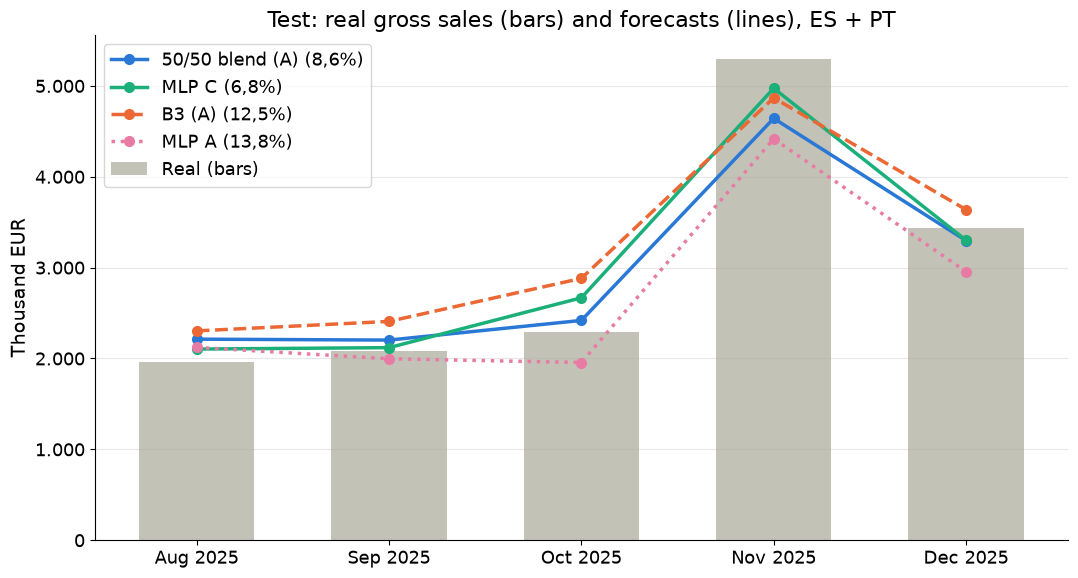

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# Usa GT, real_t, TEST_MONTHS, SEEDS, tot, W (célula 24) e save_fig (célula 1).
# Cada modelo: (nome, cor, traço). O erro (WAPE do Test) vai entre parênteses na legenda.
estilo = {'T2': ('50/50 blend (A)', '#2a78d6', '-'), 'T5': ('MLP C', '#1baf7a', '-'), 'T3': ('B3 (A)', '#eb6834', '--'), 'T1': ('MLP A', '#e87ba4', ':')}
x = np.arange(len(TEST_MONTHS)); rotulos = [m.strftime('%b %Y') for m in TEST_MONTHS]
fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x, [real_t[m] / 1000 for m in TEST_MONTHS], width=0.6, color='#c3c2b7', label='Real (bars)', zorder=1)      # barras = vendas reais
for t, (nome, cor, tracejado) in estilo.items():
    media = [np.mean([tot(GT[t][s], m) for s in SEEDS]) / 1000 for m in TEST_MONTHS]                              # média das sementes (a B3 é igual em todas)
    legenda = f'{nome} ({W[t].mean() * 100:.1f}%)'.replace('.', ',')                                              # erro entre parênteses
    ax.plot(x, media, color=cor, linestyle=tracejado, linewidth=2.5, marker='o', markersize=7, label=legenda, zorder=2)
ax.set_xticks(x); ax.set_xticklabels(rotulos)
ax.set_title('Test: real gross sales (bars) and forecasts (lines), ES + PT', fontsize=16)
ax.set_ylabel('Thousand EUR', fontsize=14); ax.tick_params(labelsize=13)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:,.0f}'.replace(',', '.'))                                            # "." nos milhares
ax.set_ylim(bottom=0); ax.grid(axis='y', alpha=0.3); ax.legend(fontsize=13, loc='upper left')
fig.tight_layout()
save_fig(fig, 'DLV66', 'Test: real gross sales (bars) against forecasts of the main models (lines, mean of seeds; error WAPE in brackets)', 'Test')
plt.show()
# Eficiência: desenha 5 barras e 4 linhas de 5 pontos. Tempo O(S·M·K) para as médias e espaço O(M).

## 25. Top 3 of scenario C

**What for.** The DAG (the automated pipeline) will call the 3 best scenario C models to forecast the requested month. Until now the models only existed inside the backtest: the `forecast_step` function trains the network, forecasts and throws it away. This section separates training from forecasting, so the models can be saved and called by people who do not run the notebook.

**Decisions, fixed before running anything**
- **Top 3** = the 3 configurations with the lowest average WAPE in the scenario C grid (7 Training steps, 5 seeds), the same ordering as table DLV43.
- **Nothing from Training or the Test changes.** The Test is not opened again: only no. 1 (T5) went to the Test. No. 2 and no. 3 have evidence from Training only and are identified as such (Evidence column of DLV69 and a tag in MLflow).
- **Code in a separate module** (`dl_vendas_top3.py`), with the same logic as `forecast_step`. The DAG imports the module; it does not run the notebook.
- **Acceptance check:** the module has to give the same daily forecast as the notebook (difference 0) and the same monthly total as the grid saved in `GR`.

**What is still assumed** (the scenario C premises do not change): the spend of month M is known at the time of the forecast, which is still to be confirmed with Parfois. If not, these models cannot be used in production.

In [36]:
%%writefile dl_vendas_top3.py
"""
dl_vendas_top3.py
Deep Learning · vendas mensais · cenário C: treino, empacotamento e previsão dos 3 melhores modelos.

O que faz
- treinar(): treina, para um corte, uma rede por mercado e semente (o mesmo procedimento do notebook) e devolve um "bundle"
  (pesos + normalização + limites de corte + metadados).
- guardar_bundle() / carregar_bundle(): gravam e lêem o bundle (só tensores e tipos simples; sem pickle de classes).
- prever_dias(): previsão diária de um conjunto de dias (média das sementes e uma coluna por semente).
- agregar_mensal(): soma as previsões diárias a mensais (ES, PT e Total), com mínimo e máximo entre sementes.
- ModeloVendasC: o mesmo modelo como pyfunc do MLflow (entrada: linhas por mercado e dia com as variáveis; saída: previsão diária).

Regras que vêm do notebook (não mudar aqui sem mudar lá):
- previsões negativas passam a 0, semente a semente;
- o investimento (spend_day, spend_month) de um dia a prever é cortado ao mínimo e ao máximo vistos no treino;
- normalização só com as linhas de treino; sd = 0 passa a 1.
"""
import numpy as np
import pandas as pd
import torch
from torch import nn
import mlflow.pyfunc

MODULE_VERSION = '1.0'
CLIP_COLS = ('spend_day', 'spend_month')
_LOSSES = {'l1': lambda fixed: nn.L1Loss(), 'mse': lambda fixed: nn.MSELoss(), 'huber': lambda fixed: nn.HuberLoss(delta=fixed['huber_delta'])}


def _make_net(d, layers):
    # MLP: d variáveis -> camadas escondidas com ReLU -> 1 número (gross sales do dia, normalizado)
    mods, prev = [], d
    for h in layers:
        mods += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    return nn.Sequential(*mods, nn.Linear(prev, 1))


def _fit_mlp(X, y, cfg, seed, fixed):
    # Igual à fit_mlp do notebook: a semente fixa os pesos iniciais e a ordem das linhas em cada época.
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    net = _make_net(X.shape[1], cfg['layers'])
    opt = torch.optim.Adam(net.parameters(), lr=fixed['lr'], weight_decay=fixed['weight_decay'])
    lossf = _LOSSES[cfg['loss']](fixed)
    Xt = torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))
    yt = torch.from_numpy(np.ascontiguousarray(y, dtype=np.float32)).reshape(-1, 1)
    n, bs = len(Xt), fixed['batch']
    for _ in range(cfg['epochs']):
        perm = torch.randperm(n, generator=gen)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            lossf(net(Xt[idx]), yt[idx]).backward()
            opt.step()
    return net


def _predict_net(net, X):
    net.eval()
    with torch.no_grad():
        return net(torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))).numpy().ravel()


def _matriz(df, features):
    # matriz das variáveis; falha com mensagem clara se faltar alguma coluna ou houver valores vazios
    faltam = [c for c in features if c not in df.columns]
    if faltam:
        raise KeyError(f'Faltam colunas de entrada: {faltam}')
    X = df[features].to_numpy(float)
    if np.isnan(X).any():
        vazias = [c for c in features if df[c].isna().any()]
        raise ValueError(f'Há valores vazios nas variáveis: {vazias}')
    return X


def treinar(feat, cfg, features, markets, seeds, cutoff, fixed):
    """Treina uma rede por mercado e semente com as linhas até ao corte (inclusive).
    feat: tabela com mark, day (datetime), y (gross sales do dia) e as colunas de 'features'.
    cfg: {'loss', 'layers', 'epochs'}; fixed: {'lr', 'weight_decay', 'batch', 'huber_delta'}; cutoff: último dia de treino."""
    torch.set_num_threads(1)                      # redes minúsculas: uma só linha de processamento é mais rápida e dá sempre o mesmo resultado
    cutoff = pd.Timestamp(cutoff)
    tr_all = feat[feat['day'] <= cutoff]
    if tr_all.empty:
        raise ValueError('Sem linhas de treino até ao corte.')
    assert tr_all['day'].max() <= cutoff, 'fuga de informação: linhas de treino depois do corte'
    cfg = {'loss': cfg['loss'], 'layers': list(cfg['layers']), 'epochs': int(cfg['epochs'])}
    nets, scaler, rows = {}, {}, {}
    for mk in markets:
        tr = tr_all[tr_all['mark'] == mk]
        if tr.empty:
            raise ValueError(f'Sem linhas de treino para o mercado {mk}.')
        X = _matriz(tr, features)
        mu, sd = X.mean(0), X.std(0)
        sd[sd == 0] = 1.0                         # coluna constante no treino
        y = tr['y'].to_numpy(float)
        ymu, ysd = float(y.mean()), float(y.std())
        scaler[mk] = {'mu': mu.tolist(), 'sd': sd.tolist(), 'ymu': ymu, 'ysd': ysd,
                      'clip': {c: [float(tr[c].min()), float(tr[c].max())] for c in features if c in CLIP_COLS}}
        rows[mk] = int(len(tr))
        for s in seeds:
            net = _fit_mlp((X - mu) / sd, (y - ymu) / ysd, cfg, s, fixed)
            nets[f'{mk}|{s}'] = {k: v.detach().clone() for k, v in net.state_dict().items()}
    meta = {'module_version': MODULE_VERSION, 'scenario': 'C', 'config': cfg, 'fixed': {k: float(v) for k, v in fixed.items()},
            'features': list(features), 'markets': list(markets), 'seeds': [int(s) for s in seeds], 'cutoff': str(cutoff.date()),
            'train_rows': rows, 'first_day': str(tr_all['day'].min().date()), 'torch': str(torch.__version__)}
    return {'meta': meta, 'scaler': scaler, 'nets': nets}


def guardar_bundle(bundle, caminho):
    torch.save(bundle, caminho)


def carregar_bundle(caminho):
    return torch.load(caminho, weights_only=True)   # só tensores e tipos simples


def prever_dias(bundle, df):
    """Previsão diária. df: linhas por mercado e dia (mark, day e as variáveis do modelo).
    Devolve mark, day, forecast (média das sementes) e seed_<s> (uma coluna por semente)."""
    meta = bundle['meta']
    feats = meta['features']
    d = df.copy()
    for c in ('mark', 'day'):
        if c not in d.columns:
            raise KeyError(f'Falta a coluna de entrada: {c}')
    d['day'] = pd.to_datetime(d['day'])
    extra = sorted(set(d['mark']) - set(meta['markets']))
    if extra:
        raise ValueError(f'Mercados sem modelo: {extra}')
    out = []
    for mk in meta['markets']:
        tg = d[d['mark'] == mk].copy()
        if tg.empty:
            continue
        sc = bundle['scaler'][mk]
        ymu, ysd = np.float64(sc['ymu']), np.float64(sc['ysd'])   # float64 como no notebook (um float simples do Python deixaria o produto em float32)
        for c, (lo, hi) in sc['clip'].items():      # valores fora do intervalo do treino passam para o mínimo ou o máximo visto
            tg[c] = tg[c].clip(lo, hi)
        X = (_matriz(tg, feats) - np.array(sc['mu'])) / np.array(sc['sd'])
        res = pd.DataFrame({'mark': tg['mark'].to_numpy(), 'day': tg['day'].to_numpy()})
        for s in meta['seeds']:
            net = _make_net(len(feats), meta['config']['layers'])
            net.load_state_dict(bundle['nets'][f'{mk}|{s}'])
            res[f'seed_{s}'] = np.maximum(_predict_net(net, X) * ysd + ymu, 0.0)
        seedcols = [f'seed_{s}' for s in meta['seeds']]
        res.insert(2, 'forecast', res[seedcols].mean(axis=1))
        out.append(res)
    if not out:
        raise ValueError('Nenhuma linha de entrada pertence aos mercados do modelo.')
    return pd.concat(out, ignore_index=True)


def agregar_mensal(daily, incluir_total=True):
    """Soma as previsões diárias a mensais por mercado (e Total). forecast = média das sementes; mín e máx entre sementes."""
    seedcols = [c for c in daily.columns if c.startswith('seed_')]
    g = daily.assign(month=daily['day'].dt.to_period('M')).groupby(['mark', 'month'], as_index=False)[['forecast'] + seedcols].sum()
    if incluir_total:
        t = g.groupby('month', as_index=False)[['forecast'] + seedcols].sum()
        t.insert(0, 'mark', 'Total')
        g = pd.concat([g, t], ignore_index=True)
    g['forecast_min'] = g[seedcols].min(axis=1)
    g['forecast_max'] = g[seedcols].max(axis=1)
    return g[['mark', 'month', 'forecast', 'forecast_min', 'forecast_max'] + seedcols]


class ModeloVendasC(mlflow.pyfunc.PythonModel):
    """Modelo pyfunc: entrada = linhas por mercado e dia com as variáveis; saída = previsão diária (ver prever_dias)."""

    def load_context(self, context):
        self.bundle = carregar_bundle(context.artifacts['bundle'])

    def predict(self, context, model_input, params=None):
        return prever_dias(self.bundle, model_input)

Writing dl_vendas_top3.py


In [37]:
import time
import importlib
import numpy as np
import pandas as pd

# Usa GR, CONFIGS, cfg_name, STEPS, M3, SEEDS, MARKETS, metr, ESCOLHA, BASE_C, FEATURE_GROUPS, FIXED, feat, forecast_step, cutoff_date, pct, fmt, save_table (pontos 10 a 15).
# Precisa também do ficheiro dl_vendas_top3.py na mesma pasta do notebook (célula anterior).
for nome in ['GR', 'CONFIGS', 'cfg_name', 'STEPS', 'M3', 'SEEDS', 'MARKETS', 'metr', 'ESCOLHA', 'BASE_C', 'FEATURE_GROUPS', 'FIXED', 'feat',
             'forecast_step', 'cutoff_date', 'pct', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos 10 a 15 (ou recarrega o estado guardado) e depois esta célula.")
try:
    import dl_vendas_top3 as D
    importlib.reload(D)
except ModuleNotFoundError:
    raise RuntimeError("Falta o ficheiro dl_vendas_top3.py. Corre primeiro a célula que o escreve (%%writefile).")

# ---------- regra fixada antes de ver resultados: os 3 de menor WAPE médio da grelha do cenário C (a mesma ordenação da DLV43) ----------
N_TOP = 3
linhas = []
for cfg in CONFIGS:
    n = cfg_name(cfg); res = GR[('C', n)]
    w = np.array([metr(res[s], STEPS)[0] for s in SEEDS])
    linhas.append({'cfg': cfg, 'Configuration': n, 'wm': w.mean(), 'wmin': w.min(), 'wmax': w.max(),
                   'maj': np.mean([metr(res[s], M3)[0] for s in SEEDS]), 'bias': np.mean([metr(res[s], STEPS)[1] for s in SEEDS])})
TOP3 = sorted(linhas, key=lambda r: r['wm'])[:N_TOP]
esc_c = cfg_name(ESCOLHA['C'])
dlv69 = pd.DataFrame([{'Rank': i + 1, 'Configuration': r['Configuration'], 'Loss': r['cfg']['loss'], 'Layers': '-'.join(map(str, r['cfg']['layers'])),
                       'Epochs': r['cfg']['epochs'], 'WAPE (mean of seeds)': pct(r['wm']), 'WAPE (min to max)': f"{pct(r['wmin'])} to {pct(r['wmax'])}",
                       'WAPE May-Jul': pct(r['maj']), 'Bias': pct(r['bias']),
                       'Evidence': 'Training and Test (T5)' if r['Configuration'] == esc_c else 'Training only'} for i, r in enumerate(TOP3)])
print('--- DLV69: os 3 melhores modelos do cenário C (5 sementes; 7 passos do Training; ES + PT somados por mês) ---')
print(f'Regra fixada antes: os {N_TOP} de menor WAPE médio da grelha. Só o modelo escolhido no ponto 15 foi ao Test (T5); os outros dois têm apenas evidência de Training.')
display(dlv69)
save_table(dlv69, 'DLV69', 'Top 3 models of scenario C for production (Training grid)', 'Training')
print('O nº 1 é o modelo escolhido no ponto 15:', bool(TOP3[0]['Configuration'] == esc_c))

# ---------- controlo: o módulo reproduz o notebook ----------
# Para cada modelo do Top 3 e para dois passos do Training (janeiro e julho de 2025): treina com D.treinar, prevê com D.prever_dias e compara
#  (1) com a previsão diária de forecast_step, semente a semente (esperado: diferença 0);
#  (2) com a previsão mensal guardada na grelha GR (média das sementes, por mercado).
COLS_C = [c for g in BASE_C for c in FEATURE_GROUPS[g]]
PASSOS_CTRL = [pd.Period('2025-01', 'M'), pd.Period('2025-07', 'M')]
linhas_eq, bundles_ctrl = [], {}
t0 = time.time()
for r in TOP3:
    cfg, n = r['cfg'], r['Configuration']
    for m in PASSOS_CTRL:
        b = D.treinar(feat, cfg, COLS_C, MARKETS, SEEDS, cutoff_date(m), FIXED)
        d = D.prever_dias(b, feat[feat['month'] == m])
        dif_dia = 0.0
        for s in SEEDS:
            ref = forecast_step(m, BASE_C, cfg, s)
            j = ref.merge(d[['mark', 'day', f'seed_{s}']], on=['mark', 'day'], how='outer', indicator=True)
            assert (j['_merge'] == 'both').all(), 'dias diferentes entre o notebook e o módulo'
            dif_dia = max(dif_dia, float((j['forecast'] - j[f'seed_{s}']).abs().max()))
        mes = D.agregar_mensal(d, incluir_total=False)
        dif_mes = max(abs(float(mes[mes['mark'] == mk]['forecast'].iloc[0]) - float(np.mean([GR[('C', n)][s][(m, mk)] for s in SEEDS]))) for mk in MARKETS)
        linhas_eq.append({'Configuration': n, 'Month forecast': m.strftime('%b %Y'), 'Cutoff': str(cutoff_date(m).date()),
                          'Training rows (' + ' / '.join(MARKETS) + ')': ' / '.join(str(b['meta']['train_rows'][mk]) for mk in MARKETS),
                          'Networks': len(b['nets']), 'Max daily difference vs notebook (EUR)': f'{dif_dia:.2e}',
                          'Max monthly difference vs grid (EUR)': f'{dif_mes:.2e}', 'Same': bool(dif_dia < 1e-3 and dif_mes < 1e-3)})
        bundles_ctrl[(n, m)] = b
dlv70 = pd.DataFrame(linhas_eq)
print('\n--- DLV70: controlo de equivalência entre o módulo dl_vendas_top3 e o notebook (Top 3, janeiro e julho de 2025) ---')
display(dlv70)
save_table(dlv70, 'DLV70', 'Equivalence check: dl_vendas_top3 module vs notebook (Top 3, Jan and Jul 2025)', 'Training')
print('Todas as comparações batem:', bool(dlv70['Same'].all()), f'| tempo: {(time.time() - t0) / 60:.1f} minutos'.replace('.', ','))

# ---------- controlo: gravar e ler o bundle não muda a previsão ----------
import tempfile, os
b0 = bundles_ctrl[(TOP3[0]['Configuration'], PASSOS_CTRL[1])]
with tempfile.TemporaryDirectory() as tmp:
    p = os.path.join(tmp, 'bundle.pt'); D.guardar_bundle(b0, p); b1 = D.carregar_bundle(p); kb = os.path.getsize(p) / 1024
d0 = D.prever_dias(b0, feat[feat['month'] == PASSOS_CTRL[1]]); d1 = D.prever_dias(b1, feat[feat['month'] == PASSOS_CTRL[1]])
print('Controlo: gravar e ler o bundle dá a mesma previsão:', bool(np.abs(d0['forecast'] - d1['forecast']).max() == 0),
      f'| tamanho de um bundle ({len(b0["nets"])} redes): {kb:.0f} KB')

# Eficiência: treinar um modelo do Top 3 = sementes × mercados redes, cada uma O(E·n·P) tempo (E épocas, n ≤ ~700 linhas, P ≈ 1.000 parâmetros); previsão de um mês O(dias·P) por rede.
# Espaço O(redes·P) para o bundle (10 redes por modelo) e O(n·d) para a matriz de treino.

--- DLV69: os 3 melhores modelos do cenário C (5 sementes; 7 passos do Training; ES + PT somados por mês) ---
Regra fixada antes: os 3 de menor WAPE médio da grelha. Só o modelo escolhido no ponto 15 foi ao Test (T5); os outros dois têm apenas evidência de Training.


/usr/local/lib/python3.12/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
/usr/local/lib/python3.12/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


,Rank,Configuration,Loss,Layers,Epochs,WAPE (mean of seeds),WAPE (min to max),WAPE May-Jul,Bias,Evidence
0,1,huber_32_e100,huber,32,100,"5,0%","4,1% to 5,7%","5,3%","-0,2%",Training and Test (T5)
1,2,l1_32_e300,l1,32,300,"7,4%","6,3% to 8,5%","9,6%","-6,1%",Training only
2,3,l1_32x16_e100,l1,32-16,100,"8,1%","7,0% to 10,2%","10,6%","-7,5%",Training only


Guardado: evidence_dl_vendas/DLV69.csv
O nº 1 é o modelo escolhido no ponto 15: True

--- DLV70: controlo de equivalência entre o módulo dl_vendas_top3 e o notebook (Top 3, janeiro e julho de 2025) ---


,Configuration,Month forecast,Cutoff,Training rows (Online ES / Online PT),Networks,Max daily difference vs notebook (EUR),Max monthly difference vs grid (EUR),Same
0,huber_32_e100,Jan 2025,2024-11-30,335 / 335,10,0.00e+00,1.16e-10,True
1,huber_32_e100,Jul 2025,2025-05-31,517 / 517,10,0.00e+00,0.00e+00,True
2,l1_32_e300,Jan 2025,2024-11-30,335 / 335,10,0.00e+00,1.16e-10,True
3,l1_32_e300,Jul 2025,2025-05-31,517 / 517,10,0.00e+00,4.66e-10,True
4,l1_32x16_e100,Jan 2025,2024-11-30,335 / 335,10,0.00e+00,4.66e-10,True
5,l1_32x16_e100,Jul 2025,2025-05-31,517 / 517,10,0.00e+00,0.00e+00,True


Guardado: evidence_dl_vendas/DLV70.csv
Todas as comparações batem: True | tempo: 1,4 minutos
Controlo: gravar e ler o bundle dá a mesma previsão: True | tamanho de um bundle (10 redes): 29 KB


### 25. Conclusions

**Confirmed**
- The scenario C Top 3, by the rule fixed beforehand (lowest average WAPE in the 7 Training steps), is `huber_32_e100` (5,0%), `l1_32_e300` (7,4%) and `l1_32x16_e100` (8,1%). It matches table DLV43, and no. 1 is the model chosen in Section 16.
- The `dl_vendas_top3` module reproduces the notebook: the maximum difference in the daily forecast is 0 and, in the monthly total, it does not exceed 4,66e-10 € (DLV70, the 3 models in January and July 2025, 10 networks each).
- Saving and reading the bundle does not change the forecast. A bundle of 10 networks takes 29 KB.
- Only no. 1 went to the Test (T5). No. 2 and no. 3 have evidence from Training only.

**Derived**
- The 3 Top 3 models can now be trained and called outside the notebook, with the same logic as the backtest.
- The MLflow `UserWarning` messages come from the `predict` function having no type annotations. They do not affect the result.

**Decision**
- The Test is not opened again to evaluate no. 2 and no. 3. They stay identified as "Training only".
- The Top 3 that goes on to MLflow is this one.

## 26. Registering in MLflow

**What is recorded**, for each of the 3 models:
- A run in the experiment `dl_vendas_parfois_producao`, separate from the backtests experiment (`dl_vendas_parfois`), with the parameters (configuration, variables, seeds, cutoff, fixed hyperparameters), the Training grid metrics, the tags (rank, evidence, cutoff, module version) and the DLV69 table as an artifact.
- The model, in pyfunc format (MLflow's standard format), with signature, input example, library versions and the code of the `dl_vendas_top3.py` module inside the package. It is registered as `dl_vendas_C_<configuration>`, with the alias `producao` on the latest version.

**Decisions, fixed before running**
- **Training with all data up to 31/12/2025.** The protocol says to cut at the last day of M-2, so the first month that can be forecast within the protocol is February 2026. For later months, the DAG trains again (same function) when there is new data.
- **Running again does not duplicate:** if a version with the same cutoff and the same module version already exists, it is not repeated. `FORCAR = True` forces training and registering again.
- **If the server has no model registry**, the code saves the model in the run only and says so in the Status column of DLV71. The backtests are not affected.
- **Acceptance check:** the model that comes back from MLflow has to give the same forecast as the local training (difference 0).

In [39]:
import os
import json
import time
import inspect
import tempfile
import numpy as np
import pandas as pd
import torch

# Usa D, TOP3, COLS_C, N_TOP, dlv69 (ponto 25), FIXED, SEEDS, MARKETS, feat, BASE_C, cutoff_date, save_table.
for nome in ['D', 'TOP3', 'COLS_C', 'dlv69', 'FIXED', 'SEEDS', 'MARKETS', 'feat', 'BASE_C', 'cutoff_date', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro o ponto 25 e depois esta célula.")
import mlflow
from mlflow.tracking import MlflowClient
from mlflow.models import infer_signature

# ---------- o que vai para produção (decisões fixadas antes de correr) ----------
# Treino com TODOS os dados disponíveis. O protocolo manda cortar no último dia de M-2: com dados até 31/12/2025, o primeiro mês que se pode prever
# dentro do protocolo é fevereiro de 2026 (corte 31/12/2025). Para um mês mais à frente, o DAG volta a treinar (mesma função) quando houver dados novos.
M_ALVO = feat['month'].max() + 2
CORTE = cutoff_date(M_ALVO)
assert CORTE == feat['day'].max(), 'o corte do primeiro mês previsível tem de ser o último dia com dados'
EXPERIENCIA = 'dl_vendas_parfois_producao'
ALIAS = 'producao'
FORCAR = False                      # True: volta a treinar e a registar mesmo que já exista uma versão com este corte
NOME_REG = lambda cfg_nome: f'dl_vendas_C_{cfg_nome}'
MODULO_PY = os.path.abspath(D.__file__)
print('Primeiro mês previsível dentro do protocolo:', M_ALVO.strftime('%b %Y'), '| corte:', CORTE.date(), '| servidor MLflow:', mlflow.get_tracking_uri(), '| versão do MLflow:', mlflow.__version__)
client = MlflowClient()
mlflow.set_experiment(EXPERIENCIA)

def log_pyfunc(**kw):
    # compatível com o MLflow 2 e 3: 'name' (3.x) ou 'artifact_path' (2.x); 'code_paths' (novo) ou 'code_path'
    p = inspect.signature(mlflow.pyfunc.log_model).parameters
    kw['name' if 'name' in p else 'artifact_path'] = 'modelo'
    if 'code_paths' not in p:
        kw['code_path'] = kw.pop('code_paths')
    return mlflow.pyfunc.log_model(**kw)

def versao_existente(nome, corte):
    # versão já registada com o mesmo corte e a mesma versão do módulo (para não duplicar ao voltar a correr)
    try:
        for v in client.search_model_versions(f"name='{nome}'"):
            if v.tags.get('cutoff') == str(corte.date()) and v.tags.get('module_version') == D.MODULE_VERSION:
                return v
    except Exception:
        return None
    return None

# ---------- treinar, registar e pôr o alias ----------
linhas, REG, BUNDLES = [], {}, {}
t0 = time.time()
for i, r in enumerate(TOP3):
    cfg, n = r['cfg'], r['Configuration']; nome = NOME_REG(n)
    ve = None if FORCAR else versao_existente(nome, CORTE)
    if ve is not None:
        REG[n] = {'nome': nome, 'versao': ve.version}
        linhas.append({'Rank': i + 1, 'Configuration': n, 'Registered model': nome, 'Version': ve.version, 'Alias': ALIAS, 'Cutoff': str(CORTE.date()),
                       'Status': 'already registered (not repeated)'})
        continue
    b = D.treinar(feat, cfg, COLS_C, MARKETS, SEEDS, CORTE, FIXED); BUNDLES[n] = b
    ex = feat[feat['month'] == feat['month'].max()][['mark', 'day'] + COLS_C].head(4).copy()          # só exemplo de formato (últimos dias com dados)
    ex['day'] = ex['day'].dt.strftime('%Y-%m-%d'); ex[COLS_C] = ex[COLS_C].astype(float)
    assinatura = infer_signature(ex, D.prever_dias(b, ex))
    estado = 'registered'
    with tempfile.TemporaryDirectory() as tmp:
        p = os.path.join(tmp, 'bundle.pt'); D.guardar_bundle(b, p)
        with open(os.path.join(tmp, 'top3_dlv69.csv'), 'w') as fh:
            dlv69.to_csv(fh, index=False)
        kb = os.path.getsize(p) / 1024
        with mlflow.start_run(run_name=f'prod_C_{n}') as run:
            mlflow.log_params({'scenario': 'C', 'target': 'gross_sales', 'loss': cfg['loss'], 'layers': str(tuple(cfg['layers'])), 'epochs': cfg['epochs'],
                               'groups': ', '.join(BASE_C), 'features': ', '.join(COLS_C), 'markets': ', '.join(MARKETS), 'seeds': str(SEEDS),
                               'cutoff': str(CORTE.date()), 'first_day': b['meta']['first_day'], 'train_rows': json.dumps(b['meta']['train_rows']),
                               **{k: v for k, v in FIXED.items()}})
            mlflow.log_metrics({'wape_mean': float(r['wm']), 'wape_min': float(r['wmin']), 'wape_max': float(r['wmax']), 'wape_may_jul': float(r['maj']), 'bias': float(r['bias'])})
            mlflow.set_tags({'scenario': 'C', 'rank_training': str(i + 1), 'module_version': D.MODULE_VERSION, 'cutoff': str(CORTE.date()),
                             'evidence': str(dlv69.loc[i, 'Evidence']), 'protocol_hash': str(globals().get('PROT_HASH', 'n/a')),
                             'first_forecastable_month': str(M_ALVO), 'input_day_format': 'YYYY-MM-DD (text)'})
            mlflow.log_artifact(os.path.join(tmp, 'top3_dlv69.csv'), artifact_path='contexto')
            req = [f'torch=={str(torch.__version__).split("+")[0]}', f'pandas=={pd.__version__}', f'numpy=={np.__version__}', f'mlflow=={mlflow.__version__}']
            args = dict(python_model=D.ModeloVendasC(), artifacts={'bundle': p}, code_paths=[MODULO_PY], signature=assinatura, input_example=ex, pip_requirements=req)
            try:
                log_pyfunc(registered_model_name=nome, **args)
            except Exception as e:                      # o registo de modelos pode não estar disponível no servidor: guarda o modelo só na execução
                estado = f'NOT registered: {type(e).__name__}: {str(e)[:150]}'
                try:
                    log_pyfunc(**args)
                except Exception as e2:
                    estado = f'NOT logged: {type(e2).__name__}: {str(e2)[:150]}'
            run_id = run.info.run_id
    versao = None
    if estado == 'registered':
        versao = max(client.search_model_versions(f"name='{nome}'"), key=lambda v: int(v.version))
        client.set_model_version_tag(nome, versao.version, 'cutoff', str(CORTE.date()))
        client.set_model_version_tag(nome, versao.version, 'module_version', D.MODULE_VERSION)
        client.set_model_version_tag(nome, versao.version, 'config', n)
        client.set_registered_model_alias(nome, ALIAS, versao.version)
        REG[n] = {'nome': nome, 'versao': versao.version, 'run_id': run_id}
    linhas.append({'Rank': i + 1, 'Configuration': n, 'Registered model': nome, 'Version': versao.version if versao else '-', 'Alias': ALIAS if versao else '-',
                   'Cutoff': str(CORTE.date()), 'Bundle (KB)': f'{kb:.0f}', 'Status': estado})
dlv71 = pd.DataFrame(linhas)
print('\n--- DLV71: Top 3 do cenário C registado no MLflow (treino com todos os dados até ao corte) ---')
display(dlv71)
save_table(dlv71, 'DLV71', 'Top 3 of scenario C: models registered in MLflow (production versions)', 'Production')
print(f'Tempo: {(time.time() - t0) / 60:.1f} minutos'.replace('.', ','))

# ---------- controlo: o modelo que volta do MLflow dá a mesma previsão que o bundle em memória ----------
# Usa um mês de histórico só para comparar (o modelo já viu estes dias: NÃO é uma previsão, só prova que o registo não altera nada).
CTRL = feat['month'].max()
x = feat[feat['month'] == CTRL][['mark', 'day'] + COLS_C].copy(); x['day'] = x['day'].dt.strftime('%Y-%m-%d'); x[COLS_C] = x[COLS_C].astype(float)
ctrl = []
for r in TOP3:
    n = r['Configuration']
    if n not in REG:
        ctrl.append({'Configuration': n, 'Loaded from': '-', 'Max difference (EUR)': '-', 'Same': False}); continue
    m_mlf = mlflow.pyfunc.load_model(f"models:/{REG[n]['nome']}@{ALIAS}")
    saida = m_mlf.predict(x)
    ref = D.prever_dias(BUNDLES[n] if n in BUNDLES else D.treinar(feat, r['cfg'], COLS_C, MARKETS, SEEDS, CORTE, FIXED), x)
    dif = float(np.abs(saida['forecast'].to_numpy() - ref['forecast'].to_numpy()).max())
    ctrl.append({'Configuration': n, 'Loaded from': f"models:/{REG[n]['nome']}@{ALIAS} (version {REG[n]['versao']})", 'Max difference (EUR)': f'{dif:.2e}', 'Same': bool(dif < 1e-3)})
dlv72 = pd.DataFrame(ctrl)
print('\n--- DLV72: controlo, o modelo carregado do MLflow dá a mesma previsão que o treino local (mesmo corte, mesmas sementes) ---')
display(dlv72)
save_table(dlv72, 'DLV72', 'Check: model loaded from MLflow vs local training (same cutoff and seeds)', 'Production')
print('Todos iguais:', bool(dlv72['Same'].all()))

# Eficiência: treinar os 3 modelos = 3 × sementes × mercados redes, cada uma O(E·n·P); registar é O(tamanho do bundle) (cerca de 10 redes por modelo, algumas dezenas de KB).
# Carregar do registo é O(tamanho do bundle); prever um mês é O(dias·P·sementes).

2026/11/21 23:28:23 INFO mlflow.tracking.fluent: Experiment with name 'dl_vendas_parfois_producao' does not exist. Creating a new experiment.


Primeiro mês previsível dentro do protocolo: Feb 2026 | corte: 2025-12-31 | servidor MLflow: http://mlflow:5000 | versão do MLflow: 3.17.0


2026/11/21 23:28:30 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.
2026/11/21 23:28:30 INFO mlflow.pyfunc: Validating input example against model signature


Successfully registered model 'dl_vendas_C_huber_32_e100'.
2026/11/21 23:28:32 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: dl_vendas_C_huber_32_e100, version 1
Created version '1' of model 'dl_vendas_C_huber_32_e100'.


🏃 View run prod_C_huber_32_e100 at: http://mlflow:5000/#/experiments/4/runs/37d163081fae4700a9888c294da9a053
🧪 View experiment at: http://mlflow:5000/#/experiments/4


2026/11/21 23:28:52 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.
2026/11/21 23:28:52 INFO mlflow.pyfunc: Validating input example against model signature


... (6 outputs left out)

Guardado: evidence_dl_vendas/DLV71.csv
Tempo: 0,7 minutos



--- DLV72: controlo, o modelo carregado do MLflow dá a mesma previsão que o treino local (mesmo corte, mesmas sementes) ---


,Configuration,Loaded from,Max difference (EUR),Same
0,huber_32_e100,models:/dl_vendas_C_huber_32_e100@producao (ve...,0.00e+00,True
1,l1_32_e300,models:/dl_vendas_C_l1_32_e300@producao (versi...,0.00e+00,True
2,l1_32x16_e100,models:/dl_vendas_C_l1_32x16_e100@producao (ve...,0.00e+00,True


Guardado: evidence_dl_vendas/DLV72.csv
Todos iguais: True


### 26. Conclusions

**Confirmed**
- The 3 Top 3 models of scenario C were registered in MLflow (version 1 of each, alias `producao`, cutoff 31/12/2025): `dl_vendas_C_huber_32_e100`, `dl_vendas_C_l1_32_e300` and `dl_vendas_C_l1_32x16_e100`. Each has its own run in the experiment `dl_vendas_parfois_producao` (id 4 on the server).
- The server accepts model registration and saving of artifacts (DLV71, status "registered" for all 3). The package takes 29 KB for the first two and 53 KB for the third.
- The model loaded from `models:/<name>@producao` gives exactly the same forecast as the local training (difference 0, DLV72).
- The server's MLflow version is 3.17.0.

**Derived**
- Any process with access to the server can call the 3 models by name and alias, without running the notebook. The module code goes inside the registered package.
- The `CloudPickle` warning is an MLflow security note about saving Python objects. Here it only saves a class from our module, so it changes nothing.

**Decision**
- The first month that can be forecast within the protocol is February 2026 (cutoff 31/12/2025). For following months, the DAG trains again with the new data.
- The backtests stay in the experiment `dl_vendas_parfois`, unchanged. Production stays in the experiment `dl_vendas_parfois_producao`.

## 27. Forecasting the requested month from the registry

**What for.** The DAG asks for a month and receives the forecast of the 3 scenario C models. This section builds, from the silver layer, the variables of the month to forecast (calendar, holidays, clearance and spend), loads the models registered in Section 26 and returns the monthly forecast by model and market (ES, PT and Total).

**Decisions, fixed before running**
- **The month's data comes from the silver layer** (events and spend), already loaded with the month to forecast. This is what was assumed; it is not yet confirmed that the silver layer receives the month's spend before the month ends.
- **Nothing is ever filled in or estimated.** If the spend for any day of the month is missing, the function stops with `DadosEmFalta` and says which days are missing. If there appears to be no clearance calendar for the year, it returns a warning.
- **The protocol rules.** Each registered model has its cutoff in the `cutoff` tag. If the cutoff is not the last day of M-2 of the requested month, the function stops with `ForaDoProtocolo`, unless explicitly authorised.
- **Holidays:** the national calendar (ES and PT), which is known for any date. **Clearance:** only the exact `Clearance` event. The variables are the same as in scenario C of the notebook.

**Acceptance checks**
1. The input built from the silver layer is equal to the notebook's variables table (January, July and December 2025).
2. `prever_mes` gives the same as the MLflow model with the notebook's rows (July 2025, only to prove the path; it is not a forecast).
3. A model with the wrong cutoff does not forecast without authorisation.

In [41]:
%%writefile dl_vendas_previsao.py
"""
dl_vendas_previsao.py
Previsão de um mês pedido com os 3 melhores modelos do cenário C, registados no MLflow (ver dl_vendas_top3.py).

O que faz
- entrada_mes(): constrói, a partir das silver, as linhas por mercado e dia do mês a prever (calendário, feriados, saldos, investimento).
  Pára com DadosEmFalta se faltar o investimento (paid media) de algum dia do mês; nunca preenche nem inventa valores.
- prever_mes(): carrega os modelos pelo nome e alias, confere o corte de cada um com o protocolo e devolve a previsão mensal.

As variáveis são as mesmas do notebook (célula do ponto 8, grupos do cenário C):
weekday (dow_0..dow_6), end_of_month (eom: dia 26 em diante), holiday (hol_wd: feriado nacional de segunda a sexta),
saldos (flag_saldos: dias do evento exatamente "Clearance") e paid_C_month_M (spend_day, spend_month).

As ligações às silver (con, silver_ev, silver_pm) são as do notebook: con = lakehouse.connect(); silver_ev e silver_pm são o texto
f"'{lake.uri('silver', 'slv_events')}.parquet'" e f"'{lake.uri('silver', 'slv_paid_media')}.parquet'".
"""
import numpy as np
import pandas as pd
import mlflow
from mlflow.tracking import MlflowClient

import dl_vendas_top3 as D

MARKETS = ('Online ES', 'Online PT')
COUNTRY = {'Online ES': 'ES', 'Online PT': 'PT'}
TOP3_MODELOS = ['dl_vendas_C_huber_32_e100', 'dl_vendas_C_l1_32_e300', 'dl_vendas_C_l1_32x16_e100']
ALIAS = 'producao'
PREVISAO_VERSION = '1.0'


class DadosEmFalta(Exception):
    """Faltam dados do mês a prever (por exemplo, o investimento de alguns dias)."""


class ForaDoProtocolo(Exception):
    """O corte do modelo não é o do protocolo (último dia de M-2) para o mês pedido."""


def _mes(mes):
    return mes if isinstance(mes, pd.Period) else pd.Period(str(mes), 'M')


def dias_do_mes(mes):
    mes = _mes(mes)
    return pd.date_range(mes.start_time.normalize(), mes.end_time.normalize(), freq='D')


def _in(markets):
    return ', '.join(f"'{m}'" for m in markets)


def ler_saldos(con, silver_ev, markets, ini, fim):
    """Dias de saldos (evento exatamente 'Clearance') por mercado entre ini e fim. Eventos com mercado 'All' valem para todos os mercados."""
    mk_values = ', '.join(f"('{m}')" for m in markets)
    d = con.sql(f"""
    WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
    e AS (SELECT mark_cod AS mark, start_date AS start_d, end_date AS end_d FROM read_parquet({silver_ev})
          WHERE event = 'Clearance' AND end_date >= start_date),
    u AS (SELECT mark, start_d, end_d FROM e WHERE mark IN ({_in(markets)})
          UNION ALL
          SELECT mk.mark, e.start_d, e.end_d FROM e CROSS JOIN mk WHERE e.mark = 'All')
    SELECT DISTINCT mark, CAST(day_ts AS DATE) AS day FROM (
      SELECT mark, unnest(generate_series(CAST(greatest(start_d, DATE '{ini}') AS TIMESTAMP),
                                          CAST(least(end_d, DATE '{fim}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts FROM u)
    """).df()
    d['day'] = pd.to_datetime(d['day'])
    return set(zip(d['mark'], d['day']))


def contar_saldos_no_ano(con, silver_ev, markets, ano):
    """Número de eventos 'Clearance' que tocam o ano, por mercado (para avisar se o calendário de saldos parece não estar carregado)."""
    d = con.sql(f"""SELECT mark_cod AS mark, count(*) AS n FROM read_parquet({silver_ev})
                    WHERE event = 'Clearance' AND end_date >= start_date AND start_date <= DATE '{ano}-12-31' AND end_date >= DATE '{ano}-01-01'
                    AND mark_cod IN ({_in(list(markets) + ['All'])}) GROUP BY 1""").df()
    n_all = int(d.loc[d['mark'] == 'All', 'n'].sum())
    return {mk: int(d.loc[d['mark'] == mk, 'n'].sum()) + n_all for mk in markets}


def ler_investimento(con, silver_pm, markets, ini, fim):
    """Investimento (paid media) diário por mercado entre ini e fim: mark, day, spend."""
    pm = con.execute(f"""SELECT marketplace AS mark, paid_media_date AS day, sum(amount_paid_media) AS spend
                         FROM read_parquet({silver_pm}) WHERE marketplace IN ({_in(markets)}) AND paid_media_date IS NOT NULL
                         AND paid_media_date BETWEEN DATE '{ini}' AND DATE '{fim}' GROUP BY 1, 2""").df()
    pm['day'] = pd.to_datetime(pm['day'])
    pm['spend'] = pm['spend'].astype(float)
    return pm


def feriados_nacionais(markets, anos, country=COUNTRY):
    import holidays                                    # calendário de feriados nacionais (conhece qualquer data futura)
    out = {}
    for mk in markets:
        try:
            h = holidays.country_holidays(country[mk], years=list(anos), language='en_US')
        except Exception:
            h = holidays.country_holidays(country[mk], years=list(anos))
        out[mk] = {pd.Timestamp(d) for d in h}
    return out


def entrada_mes(mes, con, silver_ev, silver_pm, markets=MARKETS):
    """Linhas por mercado e dia do mês a prever, com as variáveis do cenário C. Devolve (tabela, avisos).
    Levanta DadosEmFalta se faltar o investimento de algum dia do mês (o cenário C precisa dele)."""
    mes = _mes(mes)
    dias = dias_do_mes(mes)
    ini, fim = dias[0].date(), dias[-1].date()
    avisos = []
    pm = ler_investimento(con, silver_pm, markets, ini, fim)
    faltas = []
    for mk in markets:
        tem = set(pm.loc[pm['mark'] == mk, 'day'])
        falta = [d for d in dias if d not in tem]
        if falta:
            faltas.append(f"{mk}: {len(falta)} de {len(dias)} dias (primeiro em falta: {falta[0].date()})")
    if faltas:
        raise DadosEmFalta(f"Investimento (paid media) em falta em {mes}: " + '; '.join(faltas) +
                           ". O cenário C precisa do investimento do mês completo; não se preenche nem se estima.")
    if (pm['spend'] <= 0).any():
        avisos.append(f"Há {int((pm['spend'] <= 0).sum())} dias com investimento menor ou igual a 0 em {mes}; confirmar que é real.")
    n_clr = contar_saldos_no_ano(con, silver_ev, markets, mes.year)
    for mk, n in n_clr.items():
        if n == 0:
            avisos.append(f"Nenhum evento 'Clearance' em {mes.year} para {mk}: os saldos ficam todos a 0. Confirmar que o calendário de saldos de {mes.year} já está na silver.")
    saldos = ler_saldos(con, silver_ev, markets, ini, fim)
    hol = feriados_nacionais(markets, [mes.year])
    partes = []
    for mk in markets:
        f = pd.DataFrame({'mark': mk, 'day': dias})
        dow = f['day'].dt.dayofweek
        for k in range(7):
            f[f'dow_{k}'] = (dow == k).astype(float)
        f['eom'] = (f['day'].dt.day >= 26).astype(float)
        f['hol_wd'] = [float((d in hol[mk]) and d.dayofweek < 5) for d in f['day']]
        f['flag_saldos'] = [float((mk, d) in saldos) for d in f['day']]
        f = f.merge(pm.loc[pm['mark'] == mk, ['day', 'spend']].rename(columns={'spend': 'spend_day'}), on='day', how='left')
        f['spend_month'] = float(f['spend_day'].sum())
        partes.append(f)
    return pd.concat(partes, ignore_index=True), avisos


def verificar_corte(versao, mes, permitir_fora_do_protocolo=False):
    """O protocolo manda treinar com os dados até ao último dia de M-2. Confere a tag 'cutoff' da versão registada."""
    mes = _mes(mes)
    esperado = str((mes - 2).end_time.normalize().date())
    real = versao.tags.get('cutoff')
    if real != esperado and not permitir_fora_do_protocolo:
        raise ForaDoProtocolo(f"O modelo {versao.name} (versão {versao.version}) foi treinado com dados até {real}, mas o protocolo para {mes} pede {esperado}. "
                              f"Volta a treinar e a registar com o corte certo, ou usa permitir_fora_do_protocolo=True (previsão fora do que foi validado).")
    return real == esperado


def prever_mes(mes, con, silver_ev, silver_pm, modelos=TOP3_MODELOS, alias=ALIAS, markets=MARKETS, permitir_fora_do_protocolo=False):
    """Previsão do mês pedido com cada modelo registado. Devolve (mensal, diario, avisos).
    mensal: model, config, model_version, cutoff, mark (ES, PT e Total), month, forecast (média das sementes), forecast_min, forecast_max."""
    mes = _mes(mes)
    entrada, avisos = entrada_mes(mes, con, silver_ev, silver_pm, markets)
    x = entrada.copy()
    x['day'] = x['day'].dt.strftime('%Y-%m-%d')           # formato de entrada fixado na assinatura do modelo
    client = MlflowClient()
    mensais, diarios = [], []
    for nome in modelos:
        v = client.get_model_version_by_alias(nome, alias)
        dentro = verificar_corte(v, mes, permitir_fora_do_protocolo)
        if not dentro:
            avisos.append(f"{nome}: previsão fora do protocolo (corte {v.tags.get('cutoff')}).")
        m = mlflow.pyfunc.load_model(f'models:/{nome}@{alias}')
        d = m.predict(x)
        meta = {'model': nome, 'config': v.tags.get('config'), 'model_version': v.version, 'cutoff': v.tags.get('cutoff')}
        mm = D.agregar_mensal(d)[['mark', 'month', 'forecast', 'forecast_min', 'forecast_max']].copy()
        mm['month'] = mm['month'].astype(str)
        for i, (k, val) in enumerate(meta.items()):
            mm.insert(i, k, val)
        dd = d[['mark', 'day', 'forecast']].copy()
        for i, (k, val) in enumerate(meta.items()):
            dd.insert(i, k, val)
        mensais.append(mm); diarios.append(dd)
    return pd.concat(mensais, ignore_index=True), pd.concat(diarios, ignore_index=True), avisos

Writing dl_vendas_previsao.py


In [42]:
import importlib
import numpy as np
import pandas as pd

# Usa D, TOP3, COLS_C, NOME_REG, ALIAS (pontos 25 e 26), feat, con, SILVER_EV, SILVER_PM, fmt, save_table (notebook).
# Precisa do ficheiro dl_vendas_previsao.py na mesma pasta do notebook (célula anterior) e dos modelos registados no ponto 26.
for nome in ['D', 'TOP3', 'COLS_C', 'NOME_REG', 'ALIAS', 'feat', 'con', 'SILVER_EV', 'SILVER_PM', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro os pontos 25 e 26 (e a célula 1 e a do ponto 3 e 5) e depois esta célula.")
try:
    import dl_vendas_previsao as P
    importlib.reload(P)
except ModuleNotFoundError:
    raise RuntimeError("Falta o ficheiro dl_vendas_previsao.py. Corre primeiro a célula que o escreve (%%writefile).")
import mlflow

MES_PEDIDO = '2026-02'                       # o mês a prever: o primeiro dentro do protocolo (corte 31/12/2025)
MODELOS = [NOME_REG(r['Configuration']) for r in TOP3]
print('Modelos do Top 3 (do ponto 25):', MODELOS)
print('Iguais à lista por defeito do módulo de previsão:', bool(MODELOS == P.TOP3_MODELOS))

# ---------- controlo 1: a entrada construída a partir das silver é igual à tabela de variáveis do notebook ----------
# Para três meses de histórico (janeiro, julho e dezembro de 2025) compara, coluna a coluna, as linhas de entrada_mes com as de feat.
# Só se comparam variáveis (calendário, feriados, saldos e investimento); não se prevê nada.
linhas = []
for mes in ['2025-01', '2025-07', '2025-12']:
    ent, av = P.entrada_mes(mes, con, SILVER_EV, SILVER_PM)
    ref = feat[feat['month'] == pd.Period(mes, 'M')][['mark', 'day'] + COLS_C]
    j = ref.merge(ent[['mark', 'day'] + COLS_C], on=['mark', 'day'], how='outer', suffixes=('_nb', '_mod'), indicator=True)
    assert (j['_merge'] == 'both').all(), 'dias diferentes entre o notebook e a entrada'
    dif = {c: float((j[c + '_nb'].astype(float) - j[c + '_mod'].astype(float)).abs().max()) for c in COLS_C}
    linhas.append({'Month': mes, 'Rows': len(ent), 'Max difference in any column': f'{max(dif.values()):.2e}',
                   'Worst column': max(dif, key=dif.get), 'Warnings': len(av), 'Same': bool(max(dif.values()) < 1e-9)})
dlv73 = pd.DataFrame(linhas)
print('\n--- DLV73: controlo, a entrada construída a partir das silver é igual à tabela de variáveis do notebook ---')
display(dlv73)
save_table(dlv73, 'DLV73', 'Check: model input built from silver vs notebook feature table (Jan, Jul, Dec 2025)', 'Production')
print('Todas iguais:', bool(dlv73['Same'].all()))

# ---------- controlo 2: prever_mes (silver -> entrada -> modelo do MLflow) dá o mesmo que o modelo carregado com as linhas do notebook ----------
# Julho de 2025 é histórico e o modelo já o viu: NÃO é uma previsão, só prova o caminho. Por isso precisa de permitir_fora_do_protocolo=True.
mensal_h, diario_h, av_h = P.prever_mes('2025-07', con, SILVER_EV, SILVER_PM, modelos=MODELOS, alias=ALIAS, permitir_fora_do_protocolo=True)
x = feat[feat['month'] == pd.Period('2025-07', 'M')][['mark', 'day'] + COLS_C].copy()
x['day'] = x['day'].dt.strftime('%Y-%m-%d'); x[COLS_C] = x[COLS_C].astype(float)
linhas = []
for nome in MODELOS:
    d_ref = D.agregar_mensal(mlflow.pyfunc.load_model(f'models:/{nome}@{ALIAS}').predict(x))
    a = mensal_h[mensal_h['model'] == nome].set_index('mark')['forecast']
    b = d_ref.set_index('mark')['forecast']
    dif = float((a.reindex(b.index) - b).abs().max())
    linhas.append({'Model': nome, 'Max monthly difference (EUR)': f'{dif:.2e}', 'Same': bool(dif < 1e-3)})
dlv74 = pd.DataFrame(linhas)
print('\n--- DLV74: controlo, prever_mes dá o mesmo que o modelo do MLflow com as linhas do notebook (julho de 2025, só para provar o caminho) ---')
display(dlv74)
save_table(dlv74, 'DLV74', 'Check: prever_mes vs registered model on notebook rows (Jul 2025, not a forecast)', 'Production')
print('Todas iguais:', bool(dlv74['Same'].all()))

# ---------- controlo 3: o protocolo é respeitado (um modelo com o corte errado não prevê sem autorização) ----------
try:
    P.prever_mes('2025-07', con, SILVER_EV, SILVER_PM, modelos=MODELOS[:1], alias=ALIAS)
    print('Controlo 3: FALHOU, devia ter parado por o corte não ser o do protocolo.')
except P.ForaDoProtocolo as e:
    print('Controlo 3: parou como esperado ->', e)

# ---------- o mês pedido ----------
print(f'\n--- Previsão de {MES_PEDIDO} com o Top 3 do cenário C (modelos registados, corte 31/12/2025) ---')
try:
    mensal, diario, avisos = P.prever_mes(MES_PEDIDO, con, SILVER_EV, SILVER_PM, modelos=MODELOS, alias=ALIAS)
    for a in avisos:
        print('AVISO:', a)
    vis = mensal.assign(forecast=mensal['forecast'].map(fmt), forecast_min=mensal['forecast_min'].map(fmt), forecast_max=mensal['forecast_max'].map(fmt))
    print('\n--- DLV75: previsão mensal de gross sales (EUR), por modelo e mercado; mínimo e máximo entre as 5 sementes ---')
    display(vis)
    save_table(mensal, 'DLV75', f'Monthly gross sales forecast for {MES_PEDIDO}, Top 3 of scenario C (numeric)', 'Production')
except P.DadosEmFalta as e:
    print('Sem previsão: faltam dados do mês pedido.\n ', e)
    print('Não se estima nem se preenche. Quando as silver tiverem o investimento deste mês, volta a correr esta célula.')

# Eficiência: construir a entrada lê um mês das silver, O(dias·mercados); cada modelo prevê em O(dias·P·sementes·mercados) e carregar do registo custa O(tamanho do bundle).
# Espaço O(dias·variáveis) para a entrada.

Modelos do Top 3 (do ponto 25): ['dl_vendas_C_huber_32_e100', 'dl_vendas_C_l1_32_e300', 'dl_vendas_C_l1_32x16_e100']
Iguais à lista por defeito do módulo de previsão: True

--- DLV73: controlo, a entrada construída a partir das silver é igual à tabela de variáveis do notebook ---


,Month,Rows,Max difference in any column,Worst column,Warnings,Same
0,2025-01,62,5.82e-11,spend_month,0,True
1,2025-07,62,2.91e-11,spend_month,0,True
2,2025-12,62,1.46e-11,spend_month,0,True


Guardado: evidence_dl_vendas/DLV73.csv
Todas iguais: True



--- DLV74: controlo, prever_mes dá o mesmo que o modelo do MLflow com as linhas do notebook (julho de 2025, só para provar o caminho) ---


,Model,Max monthly difference (EUR),Same
0,dl_vendas_C_huber_32_e100,0.00e+00,True
1,dl_vendas_C_l1_32_e300,0.00e+00,True
2,dl_vendas_C_l1_32x16_e100,0.00e+00,True


Guardado: evidence_dl_vendas/DLV74.csv
Todas iguais: True
Controlo 3: parou como esperado -> O modelo dl_vendas_C_huber_32_e100 (versão 1) foi treinado com dados até 2025-12-31, mas o protocolo para 2025-07 pede 2025-05-31. Volta a treinar e a registar com o corte certo, ou usa permitir_fora_do_protocolo=True (previsão fora do que foi validado).

--- Previsão de 2026-02 com o Top 3 do cenário C (modelos registados, corte 31/12/2025) ---
Sem previsão: faltam dados do mês pedido.
  Investimento (paid media) em falta em 2026-02: Online ES: 28 de 28 dias (primeiro em falta: 2026-02-01); Online PT: 28 de 28 dias (primeiro em falta: 2026-02-01). O cenário C precisa do investimento do mês completo; não se preenche nem se estima.
Não se estima nem se preenche. Quando as silver tiverem o investimento deste mês, volta a correr esta célula.


### 27. Conclusions

**Confirmed**
- The input built from the silver layer is equal to the notebook's variables table in January, July and December 2025 (maximum difference 5,82e-11, rounding only, no warnings).
- `prever_mes` gives the same as the MLflow model with the notebook's rows, for all 3 models (difference 0, DLV74).
- The protocol is respected: a model with the wrong cutoff stops with `ForaDoProtocolo` and does not forecast without authorisation.
- **The silver layer does not have the spend for February 2026:** all 28 of 28 days are missing, in ES and in PT. The function stops and does not forecast.

**Derived**
- With the data that exists today, scenario C cannot forecast February 2026. The spend of month M is not loaded before the month starts.
- The premise "the spend of month M is known at the time of the forecast" (scenario C) remains unconfirmed. The silver layer shows that, today, it does not hold there.

**Decision**
- The missing spend is not estimated or filled in. Scenario C only forecasts when the silver layer has the full month's spend.
- What remains to be confirmed with Parfois: whether a planned paid media budget exists by month (or by day) before the month starts and in what format, and whether it will start to reach the silver layer.

## 28. Registered monthly training and entry point for the DAG (scenario C, Top 3)

Until now, the training of the 3 models used the notebook's `feat` table. For the DAG to work without the notebook, this section does three things:

1. It builds the training table directly from the silver layer (`tabela_treino`).
2. It trains and registers the 3 models in MLflow with data up to the last day of M-2 (`treinar_e_registar`). Each version gets the alias `corte_AAAA_MM_DD`, and the `producao` alias only moves forward to the most recent cutoff. If the version for that cutoff already exists, it does not repeat.
3. It provides `executar_mes(mes, ...)`, which is what the DAG calls: it checks the input, trains and registers if needed, and forecasts.

Checks: the module's table has to be equal to the notebook's (DLV76), training with it has to reproduce the grid forecast (DLV77), and the per-cutoff registration behaviour is tested in an isolated trial, deleted at the end (DLV78). If sales or spend are missing, it stops before training. Nothing is filled in or estimated.

In [43]:
%%writefile dl_vendas_pipeline.py
"""
dl_vendas_pipeline.py
Ponto de entrada para o DAG: treino mensal, registo no MLflow e previsão do mês pedido (cenário C, Top 3).
Usa dl_vendas_top3.py (treino e pacote do modelo) e dl_vendas_previsao.py (entrada do mês e previsão).
Nunca se preenche nem se estima o que falta: se faltarem vendas ou investimento, levanta DadosEmFalta.
"""
import numpy as np
import pandas as pd
import torch
import inspect
import json
import os
import tempfile
import mlflow
from mlflow.tracking import MlflowClient
from mlflow.models import infer_signature

import dl_vendas_top3 as D
import dl_vendas_previsao as P
from dl_vendas_previsao import DadosEmFalta, ForaDoProtocolo

PIPELINE_VERSION = '1.0'
MARKETS = P.MARKETS
INICIO_DADOS = '2024-01-01'
EXPERIENCIA = 'dl_vendas_parfois_producao'
PREFIXO = 'dl_vendas_C_'
ALIAS_ULTIMO = 'producao'
# variáveis do cenário C, pela mesma ordem do notebook
FEATURES_C = [f'dow_{k}' for k in range(7)] + ['eom', 'hol_wd', 'flag_saldos', 'spend_day', 'spend_month']
FIXED = {'lr': 1e-3, 'weight_decay': 1e-4, 'batch': 32, 'huber_delta': 1.0}
SEEDS = [0, 1, 2, 3, 4]
TOP3_CFG = {'huber_32_e100': {'loss': 'huber', 'layers': [32], 'epochs': 100},
            'l1_32_e300': {'loss': 'l1', 'layers': [32], 'epochs': 300},
            'l1_32x16_e100': {'loss': 'l1', 'layers': [32, 16], 'epochs': 100}}


def corte_do_mes(mes):
    """Último dia de treino permitido para prever o mês: o último dia de M-2."""
    return (P._mes(mes) - 2).end_time.normalize()


def alias_corte(corte):
    return 'corte_' + str(pd.Timestamp(corte).date()).replace('-', '_')


def tabela_treino(con, silver_cab, silver_det, silver_ev, silver_pm, markets=MARKETS, ini=INICIO_DADOS, fim=None):
    """Uma linha por mercado e dia entre ini e fim: y (gross sales do dia, em euros) e as variáveis do cenário C.
    gross sales = valor com desconto, sem IVA, das linhas SALE e CANCELLED das encomendas com pelo menos uma linha SALE (como no notebook).
    Levanta DadosEmFalta se as vendas não chegarem ao último dia pedido ou se faltar investimento em algum dia."""
    ini, fim = pd.Timestamp(ini), pd.Timestamp(fim)
    mk_in = ', '.join(f"'{m}'" for m in markets)
    mk_values = ', '.join(f"('{m}')" for m in markets)
    ult = con.execute(f"SELECT mark_cod, max(order_date) FROM read_parquet({silver_cab}) WHERE mark_cod IN ({mk_in}) GROUP BY 1").fetchall()
    ult = {r[0]: pd.Timestamp(r[1]) for r in ult}
    curtos = [f"{mk}: vendas só até {ult.get(mk, 'n/d')}" for mk in markets if mk not in ult or ult[mk] < fim]
    if curtos:
        raise DadosEmFalta(f"As vendas nas silver não chegam a {fim.date()} ({'; '.join(curtos)}). Sem isso os dias em falta ficariam com vendas 0 e o treino ficaria errado.")
    y = con.execute(f"""
    WITH days AS (SELECT CAST(t AS DATE) AS day FROM generate_series(TIMESTAMP '{ini.date()}', TIMESTAMP '{fim.date()}', INTERVAL 1 DAY) AS g(t)),
    mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
    so AS (SELECT order_id, mark_cod AS mark, order_date AS order_d FROM read_parquet({silver_cab})
           WHERE mark_cod IN ({mk_in}) AND order_date BETWEEN DATE '{ini.date()}' AND DATE '{fim.date()}'),
    sf AS (SELECT s.order_id, s.mark, s.order_d, count(*) FILTER (WHERE d.type = 'SALE') AS sale_lines,
                  COALESCE(sum(d.amount_fixed_rate_w_disc_wo_vat) FILTER (WHERE d.type IN ('SALE', 'CANCELLED')), 0) AS gross_value
           FROM so s JOIN read_parquet({silver_det}) d ON d.order_id = s.order_id GROUP BY s.order_id, s.mark, s.order_d),
    o AS (SELECT mark, order_d AS day, COALESCE(sum(gross_value) FILTER (WHERE sale_lines > 0), 0) AS gross_sales FROM sf GROUP BY 1, 2)
    SELECT mk.mark, days.day, CAST(COALESCE(o.gross_sales, 0) AS DOUBLE) AS y
    FROM days CROSS JOIN mk LEFT JOIN o ON o.mark = mk.mark AND o.day = days.day ORDER BY mk.mark, days.day""").df()
    y['day'] = pd.to_datetime(y['day'])
    pm = P.ler_investimento(con, silver_pm, markets, ini.date(), fim.date())
    saldos = P.ler_saldos(con, silver_ev, markets, ini.date(), fim.date())
    hol = P.feriados_nacionais(markets, range(ini.year, fim.year + 1))
    partes, faltas = [], []
    for mk in markets:
        f = y[y['mark'] == mk].copy()
        f['month'] = f['day'].dt.to_period('M')
        dow = f['day'].dt.dayofweek
        for k in range(7):
            f[f'dow_{k}'] = (dow == k).astype(int)
        f['eom'] = (f['day'].dt.day >= 26).astype(int)
        f['hol_wd'] = [int((d in hol[mk]) and d.dayofweek < 5) for d in f['day']]
        f['flag_saldos'] = [int((mk, d) in saldos) for d in f['day']]
        f = f.merge(pm.loc[pm['mark'] == mk, ['day', 'spend']].rename(columns={'spend': 'spend_day'}), on='day', how='left')
        grp = f.groupby('month')['spend_day']
        f['spend_month'] = grp.transform('sum').where(grp.transform('count') == grp.transform('size'))   # só se o mês tem todos os dias
        n_falta = int(f['spend_day'].isna().sum())
        if n_falta:
            faltas.append(f"{mk}: {n_falta} dias")
        partes.append(f)
    if faltas:
        raise DadosEmFalta(f"Investimento (paid media) em falta no período de treino {ini.date()} a {fim.date()}: " + '; '.join(faltas) + '. Não se preenche nem se estima.')
    return pd.concat(partes, ignore_index=True)


def _log_pyfunc(**kw):
    # compatível com o MLflow 2 e 3: 'name' (3.x) ou 'artifact_path' (2.x); 'code_paths' (novo) ou 'code_path'
    p = inspect.signature(mlflow.pyfunc.log_model).parameters
    kw['name' if 'name' in p else 'artifact_path'] = 'modelo'
    if 'code_paths' not in p:
        kw['code_path'] = kw.pop('code_paths')
    return mlflow.pyfunc.log_model(**kw)


def versao_do_corte(client, nome, corte):
    """Versão registada com o corte pedido (pelo alias corte_AAAA_MM_DD; se não houver, pelas tags). None se não existir."""
    try:
        return client.get_model_version_by_alias(nome, alias_corte(corte))
    except Exception:
        pass
    try:
        for v in client.search_model_versions(f"name='{nome}'"):
            if v.tags.get('cutoff') == str(pd.Timestamp(corte).date()) and v.tags.get('module_version') == D.MODULE_VERSION:
                return v
    except Exception:
        return None
    return None


def _por_aliases(client, nome, versao, corte):
    # alias do corte nesta versão; o alias producao só avança (nunca recua para um corte mais antigo)
    client.set_registered_model_alias(nome, alias_corte(corte), versao)
    try:
        atual = client.get_model_version_by_alias(nome, ALIAS_ULTIMO)
        corte_atual = atual.tags.get('cutoff') or '0000-00-00'
    except Exception:
        corte_atual = '0000-00-00'
    if str(pd.Timestamp(corte).date()) >= corte_atual:
        client.set_registered_model_alias(nome, ALIAS_ULTIMO, versao)
        return True
    return False


def _registar(client, bundle, nome, cfg_nome, cfg, corte, mes, tab, markets):
    ex = tab[tab['month'] == tab['month'].max()][['mark', 'day'] + FEATURES_C].head(4).copy()      # só exemplo de formato
    ex['day'] = ex['day'].dt.strftime('%Y-%m-%d')
    ex[FEATURES_C] = ex[FEATURES_C].astype(float)
    assinatura = infer_signature(ex, D.prever_dias(bundle, ex))
    with tempfile.TemporaryDirectory() as tmp:
        p = os.path.join(tmp, 'bundle.pt')
        D.guardar_bundle(bundle, p)
        with mlflow.start_run(run_name=f'prod_C_{cfg_nome}_corte_{pd.Timestamp(corte).date()}') as run:
            mlflow.log_params({'scenario': 'C', 'target': 'gross_sales', 'loss': cfg['loss'], 'layers': str(tuple(cfg['layers'])), 'epochs': cfg['epochs'],
                               'features': ', '.join(FEATURES_C), 'markets': ', '.join(markets), 'seeds': str(bundle['meta']['seeds']),
                               'cutoff': str(pd.Timestamp(corte).date()), 'first_day': bundle['meta']['first_day'],
                               'train_rows': json.dumps(bundle['meta']['train_rows']), 'trained_for_month': str(P._mes(mes)),
                               **{k: v for k, v in FIXED.items()}})
            mlflow.set_tags({'scenario': 'C', 'module_version': D.MODULE_VERSION, 'pipeline_version': PIPELINE_VERSION, 'cutoff': str(pd.Timestamp(corte).date()),
                             'input_day_format': 'YYYY-MM-DD (text)'})
            req = [f'torch=={str(torch.__version__).split("+")[0]}', f'pandas=={pd.__version__}', f'numpy=={np.__version__}', f'mlflow=={mlflow.__version__}']
            _log_pyfunc(registered_model_name=nome, python_model=D.ModeloVendasC(), artifacts={'bundle': p}, code_paths=[os.path.abspath(D.__file__)],
                        signature=assinatura, input_example=ex, pip_requirements=req)
    v = max(client.search_model_versions(f"name='{nome}'"), key=lambda x: int(x.version))
    for k, val in {'cutoff': str(pd.Timestamp(corte).date()), 'module_version': D.MODULE_VERSION, 'config': cfg_nome, 'trained_for_month': str(P._mes(mes))}.items():
        client.set_model_version_tag(nome, v.version, k, val)
    avancou = _por_aliases(client, nome, v.version, corte)
    return str(v.version), avancou


def treinar_e_registar(mes, con, silver_cab, silver_det, silver_ev, silver_pm, markets=MARKETS, ini=INICIO_DADOS, modelos=None, sementes=None,
                       forcar=False, registar=True, prefixo=PREFIXO, experiencia=EXPERIENCIA):
    """Treina os modelos com os dados até ao último dia de M-2 e (se registar=True) regista-os no MLflow. Devolve (resumo, bundles).
    Se já existir uma versão com o mesmo corte e a mesma versão do módulo, não repete (forcar=True obriga)."""
    mes = P._mes(mes)
    corte = corte_do_mes(mes)
    cfgs = modelos or TOP3_CFG
    sementes = list(sementes or SEEDS)
    client = None
    if registar:
        client = MlflowClient()
        mlflow.set_experiment(experiencia)
    tab, linhas, bundles = None, [], {}
    for n, cfg in cfgs.items():
        nome = prefixo + n
        if registar and not forcar:
            ve = versao_do_corte(client, nome, corte)
            if ve is not None:
                _por_aliases(client, nome, ve.version, corte)
                linhas.append({'Configuration': n, 'Registered model': nome, 'Cutoff': str(corte.date()), 'Version': str(ve.version), 'Status': 'already registered (not repeated)'})
                continue
        if tab is None:
            tab = tabela_treino(con, silver_cab, silver_det, silver_ev, silver_pm, markets, ini, corte)
        b = D.treinar(tab, cfg, FEATURES_C, markets, sementes, corte, FIXED)
        bundles[n] = b
        if registar:
            versao, avancou = _registar(client, b, nome, n, cfg, corte, mes, tab, markets)
            linhas.append({'Configuration': n, 'Registered model': nome, 'Cutoff': str(corte.date()), 'Version': versao,
                           'Status': 'registered' + ('' if avancou else ' (alias producao not moved: older cutoff)')})
        else:
            linhas.append({'Configuration': n, 'Registered model': nome, 'Cutoff': str(corte.date()), 'Version': '-', 'Status': 'trained (not registered)'})
    return pd.DataFrame(linhas), bundles


def prever(mes, con, silver_ev, silver_pm, modelos=None, markets=MARKETS, prefixo=PREFIXO, entrada=None):
    """Previsão do mês com a versão de cada modelo que tem o corte do protocolo (último dia de M-2).
    Devolve (mensal, diario, avisos). Levanta ForaDoProtocolo se não houver versão com esse corte (corre treinar_e_registar)."""
    mes = P._mes(mes)
    corte = corte_do_mes(mes)
    avisos = []
    if entrada is None:
        entrada, avisos = P.entrada_mes(mes, con, silver_ev, silver_pm, markets)
    x = entrada.copy()
    x['day'] = x['day'].dt.strftime('%Y-%m-%d')
    client = MlflowClient()
    mensais, diarios = [], []
    for n in (modelos or list(TOP3_CFG)):
        nome = prefixo + n
        v = versao_do_corte(client, nome, corte)
        if v is None:
            raise ForaDoProtocolo(f"Não há versão de {nome} treinada com dados até {corte.date()} (o protocolo para {mes}). Corre treinar_e_registar('{mes}', ...) primeiro.")
        d = mlflow.pyfunc.load_model(f'models:/{nome}/{v.version}').predict(x)
        meta = {'model': nome, 'config': v.tags.get('config'), 'model_version': str(v.version), 'cutoff': v.tags.get('cutoff')}
        mm = D.agregar_mensal(d)[['mark', 'month', 'forecast', 'forecast_min', 'forecast_max']].copy()
        mm['month'] = mm['month'].astype(str)
        dd = d[['mark', 'day', 'forecast']].copy()
        for i, (k, val) in enumerate(meta.items()):
            mm.insert(i, k, val)
            dd.insert(i, k, val)
        mensais.append(mm)
        diarios.append(dd)
    return pd.concat(mensais, ignore_index=True), pd.concat(diarios, ignore_index=True), avisos


def executar_mes(mes, con, silver_cab, silver_det, silver_ev, silver_pm, markets=MARKETS, ini=INICIO_DADOS, modelos=None, sementes=None,
                 prefixo=PREFIXO, experiencia=EXPERIENCIA):
    """O que o DAG chama para um mês M: 1) confere a entrada do mês (pára cedo se faltar o investimento), 2) treina e regista os modelos
    com o corte de M-2 se ainda não existirem, 3) prevê. Devolve (mensal, diario, avisos, resumo_do_treino)."""
    mes = P._mes(mes)
    entrada, avisos = P.entrada_mes(mes, con, silver_ev, silver_pm, markets)
    cfgs = {n: TOP3_CFG[n] for n in (modelos or list(TOP3_CFG))}
    resumo, _ = treinar_e_registar(mes, con, silver_cab, silver_det, silver_ev, silver_pm, markets, ini, cfgs, sementes, False, True, prefixo, experiencia)
    mensal, diario, av2 = prever(mes, con, silver_ev, silver_pm, list(cfgs), markets, prefixo, entrada)
    return mensal, diario, avisos + av2, resumo

Writing dl_vendas_pipeline.py


In [44]:
import importlib
import time
import numpy as np
import pandas as pd

# Usa D, TOP3, COLS_C, GR, SEEDS, MARKETS, feat, con, SILVER_EV, SILVER_PM, SILVER_CAB, SILVER_DET, fmt, save_table (notebook e pontos 25 a 27).
# Precisa do ficheiro dl_vendas_pipeline.py na mesma pasta do notebook (célula anterior) e de dl_vendas_previsao.py (ponto 27).
for nome in ['D', 'TOP3', 'COLS_C', 'GR', 'SEEDS', 'MARKETS', 'feat', 'con', 'SILVER_EV', 'SILVER_PM', 'SILVER_CAB', 'SILVER_DET', 'fmt', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Falta '{nome}'. Corre primeiro a célula 1 e os pontos 3, 5, 8, 10 a 15 e 25 a 27 e depois esta célula.")
try:
    import dl_vendas_pipeline as L
    importlib.reload(L)
except ModuleNotFoundError:
    raise RuntimeError("Falta o ficheiro dl_vendas_pipeline.py. Corre primeiro a célula que o escreve (%%writefile).")
import mlflow
from mlflow.tracking import MlflowClient

print('Variáveis iguais às do notebook, pela mesma ordem:', bool(L.FEATURES_C == COLS_C))
print('Configurações do Top 3 iguais às do ponto 25:', bool([r['Configuration'] for r in TOP3] == list(L.TOP3_CFG)
                                                          and all(r['cfg']['loss'] == L.TOP3_CFG[r['Configuration']]['loss'] and list(r['cfg']['layers']) == L.TOP3_CFG[r['Configuration']]['layers']
                                                                  and r['cfg']['epochs'] == L.TOP3_CFG[r['Configuration']]['epochs'] for r in TOP3)))

# ---------- controlo 1: a tabela de treino construída pelo módulo é igual à do notebook (todos os dias, todas as variáveis) ----------
tab = L.tabela_treino(con, SILVER_CAB, SILVER_DET, SILVER_EV, SILVER_PM, MARKETS, '2024-01-01', '2025-12-31')
j = feat[['mark', 'day', 'y'] + COLS_C].merge(tab[['mark', 'day', 'y'] + COLS_C], on=['mark', 'day'], how='outer', suffixes=('_nb', '_mod'), indicator=True)
assert (j['_merge'] == 'both').all(), 'dias diferentes entre o notebook e o módulo'
difs = {c: float((j[c + '_nb'].astype(float) - j[c + '_mod'].astype(float)).abs().max()) for c in ['y'] + COLS_C}
dlv76 = pd.DataFrame([{'Rows': len(tab), 'Markets': ', '.join(sorted(tab['mark'].unique())), 'First day': str(tab['day'].min().date()), 'Last day': str(tab['day'].max().date()),
                       'Max difference, gross sales (EUR)': f"{difs['y']:.2e}", 'Max difference, variables': f"{max(v for k, v in difs.items() if k != 'y'):.2e}",
                       'Same': bool(difs['y'] < 1e-6 and max(v for k, v in difs.items() if k != 'y') < 1e-9)}])
print('\n--- DLV76: controlo, a tabela de treino construída a partir das silver é igual à do notebook ---')
display(dlv76)
save_table(dlv76, 'DLV76', 'Check: training table built from silver by the pipeline module vs notebook table', 'Production')
print('Iguais:', bool(dlv76['Same'].all()))

# ---------- controlo 2: treinar com esta tabela dá a previsão da grelha (julho de 2025, corte 31/05/2025, os 3 modelos) ----------
M_JUL = pd.Period('2025-07', 'M')
resumo_c2, bundles_c2 = L.treinar_e_registar(M_JUL, con, SILVER_CAB, SILVER_DET, SILVER_EV, SILVER_PM, MARKETS, sementes=SEEDS, registar=False)
linhas = []
for n, b in bundles_c2.items():
    d = D.prever_dias(b, tab[tab['month'] == M_JUL])
    mes_f = D.agregar_mensal(d, incluir_total=False).set_index('mark')['forecast']
    dif = max(abs(float(mes_f[mk]) - float(np.mean([GR[('C', n)][s][(M_JUL, mk)] for s in SEEDS]))) for mk in MARKETS)
    linhas.append({'Configuration': n, 'Cutoff': b['meta']['cutoff'], 'Max monthly difference vs grid (EUR)': f'{dif:.2e}', 'Same': bool(dif < 1e-3)})
dlv77 = pd.DataFrame(linhas)
print('\n--- DLV77: controlo, treinar com a tabela do módulo dá a previsão da grelha (julho de 2025, só para provar o caminho) ---')
display(dlv77)
save_table(dlv77, 'DLV77', 'Check: training with the pipeline table reproduces the grid forecast (Jul 2025, not a new result)', 'Production')
print('Todas iguais:', bool(dlv77['Same'].all()))

# ---------- controlo 3: registo por corte, num ensaio isolado (nomes e experiência de ensaio, apagados no fim; os modelos reais não são tocados) ----------
PREF_E, EXP_E = 'ensaio_dl_vendas_C_', f'dl_vendas_parfois_ensaio_{int(time.time())}'     # nome único: uma experiência apagada reserva o nome
um = {'huber_32_e100': L.TOP3_CFG['huber_32_e100']}
nome_e = PREF_E + 'huber_32_e100'
cl = MlflowClient()
verif = []
try:
    r1, _ = L.treinar_e_registar('2025-07', con, SILVER_CAB, SILVER_DET, SILVER_EV, SILVER_PM, MARKETS, modelos=um, sementes=SEEDS, prefixo=PREF_E, experiencia=EXP_E)
    r2, _ = L.treinar_e_registar('2025-07', con, SILVER_CAB, SILVER_DET, SILVER_EV, SILVER_PM, MARKETS, modelos=um, sementes=SEEDS, prefixo=PREF_E, experiencia=EXP_E)
    n_v1 = len(cl.search_model_versions(f"name='{nome_e}'"))
    r3, _ = L.treinar_e_registar('2025-08', con, SILVER_CAB, SILVER_DET, SILVER_EV, SILVER_PM, MARKETS, modelos=um, sementes=SEEDS, prefixo=PREF_E, experiencia=EXP_E)
    r4, _ = L.treinar_e_registar('2025-06', con, SILVER_CAB, SILVER_DET, SILVER_EV, SILVER_PM, MARKETS, modelos=um, sementes=SEEDS, prefixo=PREF_E, experiencia=EXP_E)
    v_jul = str(cl.get_model_version_by_alias(nome_e, 'corte_2025_05_31').version)
    v_ago = str(cl.get_model_version_by_alias(nome_e, 'corte_2025_06_30').version)
    v_mai = str(cl.get_model_version_by_alias(nome_e, 'corte_2025_04_30').version)
    v_prod = str(cl.get_model_version_by_alias(nome_e, 'producao').version)
    mensal_e, _, _ = L.prever('2025-07', con, SILVER_EV, SILVER_PM, modelos=['huber_32_e100'], prefixo=PREF_E)
    verif = [
        ('Primeira execução regista a versão 1', r1.loc[0, 'Status'] == 'registered' and str(r1.loc[0, 'Version']) == '1', f"{r1.loc[0, 'Status']} / versão {r1.loc[0, 'Version']}"),
        ('Repetir o mesmo mês não duplica', 'already' in r2.loc[0, 'Status'] and n_v1 == 1, f"{r2.loc[0, 'Status']} / versões depois: {n_v1}"),
        ('Outro corte cria nova versão', str(r3.loc[0, 'Version']) == '2' and v_ago == '2', f"versão {r3.loc[0, 'Version']}; alias corte_2025_06_30 -> {v_ago}"),
        ('O alias producao avança para o corte mais recente', v_prod == '2', f'producao -> versão {v_prod}'),
        ('Treinar um corte mais antigo não faz recuar o producao', 'not moved' in r4.loc[0, 'Status'] and v_prod == '2' and v_mai == '3', f"{r4.loc[0, 'Status']}; corte_2025_04_30 -> {v_mai}"),
        ('Cada corte guarda o seu alias', v_jul == '1', f'corte_2025_05_31 -> versão {v_jul}'),
        ('prever escolhe a versão do corte certo (julho: versão 1)', bool((mensal_e['model_version'] == '1').all() and (mensal_e['cutoff'] == '2025-05-31').all()),
         f"versão {mensal_e['model_version'].iloc[0]}, corte {mensal_e['cutoff'].iloc[0]}"),
    ]
except Exception as e:
    verif.append(('Ensaio falhou', False, f'{type(e).__name__}: {str(e)[:200]}'))
finally:
    try:
        cl.delete_registered_model(nome_e)
        exp = cl.get_experiment_by_name(EXP_E)
        if exp is not None:
            for r in cl.search_runs([exp.experiment_id]):
                cl.delete_run(r.info.run_id)
            cl.delete_experiment(exp.experiment_id)
        limpo = True
    except Exception as e:
        limpo = False
        print('Aviso: não consegui apagar o ensaio (apaga à mão o modelo', nome_e, 'e a experiência', EXP_E + '):', type(e).__name__, e)
dlv78 = pd.DataFrame([{'Check': k, 'Result': bool(v), 'Detail': d} for k, v, d in verif])
print('\n--- DLV78: controlo, registo por corte e escolha da versão (ensaio isolado, apagado no fim) ---')
display(dlv78)
save_table(dlv78, 'DLV78', 'Check: registry by cutoff, alias behaviour and version choice (isolated trial)', 'Production')
print('Todos certos:', bool(dlv78['Result'].all()), '| ensaio apagado:', limpo)

# ---------- o ponto de entrada do DAG, para o mês pedido ----------
MES_PEDIDO = '2026-02'
print(f'\n--- executar_mes({MES_PEDIDO!r}): confere a entrada, treina e regista se faltar, prevê ---')
try:
    mensal28, diario28, avisos28, resumo28 = L.executar_mes(MES_PEDIDO, con, SILVER_CAB, SILVER_DET, SILVER_EV, SILVER_PM)
    for a in avisos28:
        print('AVISO:', a)
    display(resumo28)
    display(mensal28.assign(forecast=mensal28['forecast'].map(fmt), forecast_min=mensal28['forecast_min'].map(fmt), forecast_max=mensal28['forecast_max'].map(fmt)))
    save_table(mensal28, 'DLV79', f'Monthly gross sales forecast for {MES_PEDIDO} from executar_mes (numeric)', 'Production')
except L.DadosEmFalta as e:
    print('Sem previsão: faltam dados.\n ', e)
    print('Pára antes de treinar. Quando as silver tiverem o investimento deste mês, volta a correr esta célula.')

# Eficiência: a tabela de treino lê as silver uma vez, O(encomendas + linhas de encomenda); treinar 3 modelos custa 3 × sementes × mercados redes, cada uma O(E·n·P).
# O registo é O(tamanho do pacote); prever é O(dias·P·sementes·mercados) por modelo.

Variáveis iguais às do notebook, pela mesma ordem: True
Configurações do Top 3 iguais às do ponto 25: True

--- DLV76: controlo, a tabela de treino construída a partir das silver é igual à do notebook ---


,Rows,Markets,First day,Last day,"Max difference, gross sales (EUR)","Max difference, variables",Same
0,1462,"Online ES, Online PT",2024-01-01,2025-12-31,0.00e+00,0.00e+00,True


Guardado: evidence_dl_vendas/DLV76.csv
Iguais: True

--- DLV77: controlo, treinar com a tabela do módulo dá a previsão da grelha (julho de 2025, só para provar o caminho) ---


,Configuration,Cutoff,Max monthly difference vs grid (EUR),Same
0,huber_32_e100,2025-05-31,0.00e+00,True
1,l1_32_e300,2025-05-31,4.66e-10,True
2,l1_32x16_e100,2025-05-31,0.00e+00,True


Guardado: evidence_dl_vendas/DLV77.csv
Todas iguais: True


2026/11/22 00:28:46 INFO mlflow.tracking.fluent: Experiment with name 'dl_vendas_parfois_ensaio_1795307326' does not exist. Creating a new experiment.
2026/11/22 00:29:00 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.
2026/11/22 00:29:00 INFO mlflow.pyfunc: Validating input example against model signature


... (7 outputs left out)

🏃 View run prod_C_huber_32_e100_corte_2025-04-30 at: http://mlflow:5000/#/experiments/5/runs/72f112e464ab4f02bd2d4561c1261f1b
🧪 View experiment at: http://mlflow:5000/#/experiments/5



--- DLV78: controlo, registo por corte e escolha da versão (ensaio isolado, apagado no fim) ---


,Check,Result,Detail
0,Primeira execução regista a versão 1,True,registered / versão 1
1,Repetir o mesmo mês não duplica,True,already registered (not repeated) / versões de...
2,Outro corte cria nova versão,True,versão 2; alias corte_2025_06_30 -> 2
3,O alias producao avança para o corte mais recente,True,producao -> versão 2
4,Treinar um corte mais antigo não faz recuar o ...,True,registered (alias producao not moved: older cu...
5,Cada corte guarda o seu alias,True,corte_2025_05_31 -> versão 1
6,prever escolhe a versão do corte certo (julho:...,True,"versão 1, corte 2025-05-31"


Guardado: evidence_dl_vendas/DLV78.csv
Todos certos: True | ensaio apagado: True

--- executar_mes('2026-02'): confere a entrada, treina e regista se faltar, prevê ---
Sem previsão: faltam dados.
  Investimento (paid media) em falta em 2026-02: Online ES: 28 de 28 dias (primeiro em falta: 2026-02-01); Online PT: 28 de 28 dias (primeiro em falta: 2026-02-01). O cenário C precisa do investimento do mês completo; não se preenche nem se estima.
Pára antes de treinar. Quando as silver tiverem o investimento deste mês, volta a correr esta célula.


### 28. Conclusions

**What was verified**
- **Training table (DLV76):** the table built by the module from the silver layer has 1.462 rows (2 markets × 731 days, from 01/01/2024 to 31/12/2025) and is exactly equal to the notebook's: maximum difference of 0 € in sales and 0 in the variables.
- **Training (DLV77):** training with the module's table reproduces the July 2025 grid forecast (cutoff 31/05/2025) for all three models. The maximum difference is 0 € for `huber_32_e100` and `l1_32x16_e100` and 4,66e-10 € for `l1_32_e300`, that is, numerical noise. This proves the path and is not a new result.
- **Registration by cutoff (DLV78):** the 7 checks went well, in an isolated trial that was deleted at the end (the real models were not touched).
  - The first run registers version 1.
  - Repeating the same month does not duplicate.
  - A new cutoff creates a new version.
  - The `producao` alias moves forward to the most recent cutoff and does not go back when an older cutoff is trained.
  - Each cutoff keeps its own alias.
  - `prever` chooses the version of the right cutoff.

**What the entry point did today**
- `executar_mes('2026-02')` stopped before training: the paid media spend for February 2026 is missing, 28 of 28 days in Online ES and in Online PT.
- This is the desired behaviour. The spend is not estimated or filled in, and nothing is trained or forecast without the full input.
- The three models with cutoff 31/12/2025 have been registered since Section 26, so nothing is lost.

**What remains open**
- Scenario C only forecasts a month when that month's spend is already in the silver layer. Parfois still has to confirm whether the planned budget for M is available before the month starts and in what format.
- Until that is confirmed, scenario A (the T2 blend, 8,6% WAPE on the Test, no paid media) is the only one that can be used for planning.
- The DAG is written (a single task, `executar_mes`), but the four silver URIs and the destination of the forecast are missing.
- The red MLflow warnings (CloudPickle, type hint) are informational and do not affect the result.